Dataset, intermediate files and all output files

https://drive.google.com/drive/folders/1b5zzcz529Pmc8J2bBJqJUleOulcBbKbM?usp=sharing

In [ ]:
!rm -rf /content/drive
!mkdir -p /content/drive

In [ ]:
# ============================================================
# Google Colab + Google Drive Setup
# ============================================================

from pathlib import Path

from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# ------------------------------------------------------------
# Set this to the folder in Google Drive where this project
# should live.
#
# Example:
# My Drive/
#   Nepali/
#       notebooks/
#       data/
#       requirements.txt
# ------------------------------------------------------------

PROJECT_FOLDER = "LMA_IP/Nepali"

DRIVE_ROOT = Path("/content/drive/MyDrive")
PROJECT_ROOT = DRIVE_ROOT / PROJECT_FOLDER

PROJECT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("Project root:")
print(PROJECT_ROOT)

# ------------------------------------------------------------
# Install project requirements
# ------------------------------------------------------------

REQUIREMENTS_FILE = PROJECT_ROOT / "requirements.txt"

if REQUIREMENTS_FILE.exists():
    print("\nInstalling requirements from:")
    print(REQUIREMENTS_FILE)

    !pip install -q -r "{REQUIREMENTS_FILE}"

else:
    print("\nrequirements.txt was not found.")
    print("Expected location:")
    print(REQUIREMENTS_FILE)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root:
/content/drive/MyDrive/LMA_IP/Nepali

Installing requirements from:
/content/drive/MyDrive/LMA_IP/Nepali/requirements.txt


In [ ]:
# ============================================================
# Imports
# ============================================================

import json
import os
import re
import unicodedata
import hashlib
import random

from collections import Counter

import pandas as pd
from tqdm.auto import tqdm
from datasets import load_dataset

# Optional Hugging Face authentication.
# If you create a Colab Secret named HF_TOKEN, it will be used.
# The notebook still works with public datasets without it.

try:
    from google.colab import userdata

    hf_token = userdata.get("HF_TOKEN")

    if hf_token:
        os.environ["HF_TOKEN"] = hf_token
        print("Hugging Face authentication token loaded from Colab Secrets.")
    else:
        print("No HF_TOKEN found. Using unauthenticated Hugging Face access.")

except Exception:
    print("No HF_TOKEN configured. Using unauthenticated Hugging Face access.")


No HF_TOKEN configured. Using unauthenticated Hugging Face access.


In [ ]:
# ============================================================
# Project Directories on Google Drive
# ============================================================

DATA_DIR = PROJECT_ROOT / "data"

RAW_DIR = DATA_DIR / "raw"
CLEANED_DIR = DATA_DIR / "cleaned"
SPLITS_DIR = DATA_DIR / "splits"

# FineWeb2
FINEWEB_RAW_DIR = RAW_DIR / "fineweb2"
FINEWEB_CLEANED_DIR = CLEANED_DIR / "fineweb2"

# Manual data
MANUAL_RAW_DIR = RAW_DIR / "manual"
MANUAL_CLEANED_DIR = CLEANED_DIR / "manual"

# Combined/final data
FINAL_DIR = CLEANED_DIR / "final"

# Create directories
for directory in [
    FINEWEB_RAW_DIR,
    FINEWEB_CLEANED_DIR,
    MANUAL_RAW_DIR,
    MANUAL_CLEANED_DIR,
    FINAL_DIR,
    SPLITS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Project root:")
print(PROJECT_ROOT)

print("\nData directory:")
print(DATA_DIR)


Project root:
/content/drive/MyDrive/LMA_IP/Nepali

Data directory:
/content/drive/MyDrive/LMA_IP/Nepali/data


# Fineweb2

In [ ]:
# ============================================================
# FINEWEB2 SETUP
# ============================================================

from pathlib import Path
import json
import re
import unicodedata

from datasets import load_dataset


# ------------------------------------------------------------
# FineWeb2
# ------------------------------------------------------------

FINEWEB2_DATASET = "HuggingFaceFW/fineweb-2"
FINEWEB2_CONFIG = "npi_Deva"
FINEWEB2_SPLIT = "train"


# ------------------------------------------------------------
# Number of documents to download
# ------------------------------------------------------------
#
# Start small while testing.
#
# Examples:
#   10_000
#   50_000
#   100_000
#
# Once the pipeline is verified, increase this.
# ------------------------------------------------------------

MAX_FINEWEB_DOCUMENTS = 1_200_000


# ------------------------------------------------------------
# Directories
# ------------------------------------------------------------

FINEWEB2_RAW_DIR = RAW_DIR / "fineweb2"
FINEWEB2_CLEANED_DIR = CLEANED_DIR / "fineweb2"

FINEWEB2_RAW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINEWEB2_CLEANED_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Files
# ------------------------------------------------------------

FINEWEB2_RAW_FILE = (
    FINEWEB2_RAW_DIR
    / f"npi_Deva_{MAX_FINEWEB_DOCUMENTS}.jsonl"
)

FINEWEB2_CLEANED_FILE = (
    FINEWEB2_CLEANED_DIR
    / f"npi_Deva_{MAX_FINEWEB_DOCUMENTS}_cleaned.jsonl"
)


# ------------------------------------------------------------
# Expected metadata
# ------------------------------------------------------------

EXPECTED_LANGUAGE = "npi"
EXPECTED_SCRIPT = "Deva"


print("=" * 70)
print("FINEWEB2 SETUP")
print("=" * 70)

print(f"Dataset       : {FINEWEB2_DATASET}")
print(f"Configuration : {FINEWEB2_CONFIG}")
print(f"Split         : {FINEWEB2_SPLIT}")
print(f"Documents     : {MAX_FINEWEB_DOCUMENTS:,}")
print(f"Raw output    : {FINEWEB2_RAW_FILE}")
print(f"Cleaned output: {FINEWEB2_CLEANED_FILE}")

FINEWEB2 SETUP
Dataset       : HuggingFaceFW/fineweb-2
Configuration : npi_Deva
Split         : train
Documents     : 1,200,000
Raw output    : /content/drive/MyDrive/LMA_IP/Nepali/data/raw/fineweb2/npi_Deva_1200000.jsonl
Cleaned output: /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/fineweb2/npi_Deva_1200000_cleaned.jsonl


In [ ]:
# ============================================================
# STREAM FINEWEB2 AND SAVE RAW DOCUMENTS
# ============================================================

def download_fineweb2_jsonl(
    output_file,
    max_documents
):
    """
    Stream FineWeb2 and save a fixed number of documents
    as JSONL.

    The entire FineWeb2 dataset is NOT downloaded into memory.
    """

    print("=" * 70)
    print("STREAMING FINEWEB2")
    print("=" * 70)

    print(
        f"\nStreaming {max_documents:,} documents..."
    )

    dataset = load_dataset(
        FINEWEB2_DATASET,
        name=FINEWEB2_CONFIG,
        split=FINEWEB2_SPLIT,
        streaming=True,
    )


    count = 0

    with open(
        output_file,
        "w",
        encoding="utf-8"
    ) as f:

        for row in dataset:

            # ------------------------------------------------
            # Keep useful fields
            # ------------------------------------------------

            record = {
                "text": row.get("text", ""),
                "id": row.get("id"),
                "dump": row.get("dump"),
                "url": row.get("url"),
                "date": row.get("date"),

                "language": row.get("language"),
                "language_score": row.get(
                    "language_score"
                ),
                "language_script": row.get(
                    "language_script"
                ),

                "minhash_cluster_size": row.get(
                    "minhash_cluster_size"
                ),

                "top_langs": row.get(
                    "top_langs"
                ),

                "wordlist_ratio": row.get(
                    "wordlist_ratio"
                ),
            }


            # ------------------------------------------------
            # Write one JSON object per line
            # ------------------------------------------------

            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


            count += 1


            # ------------------------------------------------
            # Progress
            # ------------------------------------------------

            if count % 1_000 == 0:

                print(
                    f"Downloaded: "
                    f"{count:,} / "
                    f"{max_documents:,}"
                )


            if count >= max_documents:
                break


    print("\n" + "=" * 70)
    print("DOWNLOAD COMPLETE")
    print("=" * 70)

    print(
        f"Documents saved: {count:,}"
    )

    print(
        f"File: {output_file}"
    )

    return count


downloaded_count = download_fineweb2_jsonl(
    output_file=FINEWEB2_RAW_FILE,
    max_documents=MAX_FINEWEB_DOCUMENTS,
)

STREAMING FINEWEB2

Streaming 1,200,000 documents...


Downloaded: 1,000 / 1,200,000
Downloaded: 2,000 / 1,200,000
Downloaded: 3,000 / 1,200,000
Downloaded: 4,000 / 1,200,000
Downloaded: 5,000 / 1,200,000
Downloaded: 6,000 / 1,200,000
Downloaded: 7,000 / 1,200,000
Downloaded: 8,000 / 1,200,000
Downloaded: 9,000 / 1,200,000
Downloaded: 10,000 / 1,200,000
Downloaded: 11,000 / 1,200,000
Downloaded: 12,000 / 1,200,000
Downloaded: 13,000 / 1,200,000
Downloaded: 14,000 / 1,200,000
Downloaded: 15,000 / 1,200,000
Downloaded: 16,000 / 1,200,000
Downloaded: 17,000 / 1,200,000
Downloaded: 18,000 / 1,200,000
Downloaded: 19,000 / 1,200,000
Downloaded: 20,000 / 1,200,000
Downloaded: 21,000 / 1,200,000
Downloaded: 22,000 / 1,200,000
Downloaded: 23,000 / 1,200,000
Downloaded: 24,000 / 1,200,000
Downloaded: 25,000 / 1,200,000
Downloaded: 26,000 / 1,200,000
Downloaded: 27,000 / 1,200,000
Downloaded: 28,000 / 1,200,000
Downloaded: 29,000 / 1,200,000
Downloaded: 30,000 / 1,200,000
Downloaded: 31,000 / 1,200,000
Downloaded: 32,000 / 1,200,000
Downloaded: 33,00

In [ ]:
# ============================================================
# INSPECT RAW JSONL
# ============================================================

print("=" * 70)
print("RAW FINEWEB2 SAMPLE")
print("=" * 70)


with open(
    FINEWEB2_RAW_FILE,
    "r",
    encoding="utf-8"
) as f:

    for i in range(3):

        line = f.readline()

        if not line:
            break

        record = json.loads(line)

        print("\n" + "-" * 70)
        print(f"DOCUMENT {i + 1}")
        print("-" * 70)

        print(
            "Language:",
            record["language"]
        )

        print(
            "Script:",
            record["language_script"]
        )

        print(
            "Language score:",
            record["language_score"]
        )

        print("\nText:")
        print(
            record["text"][:1500]
        )

RAW FINEWEB2 SAMPLE

----------------------------------------------------------------------
DOCUMENT 1
----------------------------------------------------------------------
Language: npi
Script: Deva
Language score: 0.9997901320457458

Text:
३ पुस, काठमाण्डौं । नेपाली कम्युनिष्ट आन्दोलनमा ‘रायमाझी-पथ’का रुपमा छुट्टै पहिचान बनाएका पूर्वकम्युनिष्ट नेता एवं वीरेन्द्रको वंशनाशपछि ज्ञानेन्द्र शाहलाई गद्दीमा आसीन गराउने विघटित राजपरिषद् स्थायी समितिका सभापति डा. केशरजङ्ग रायमाझीको सोमबार ९३ वर्षको उमेरमा हृदयघातका कारण निधन भएको छ । उहाँको आजै पशुपति आर्यघाटमा दाहसंस्कार गरिँदैछ ।
नेपाली राजनीतिमा लामो समयसम्म चर्चा कमाउन सफल पुरानो पुस्ताका नेता रायमाझी केही दिन पहिले नै हिमालय हस्पिटलमा भर्ना भए पनि स्वास्थ्यमा सुधार आएको भन्दै अस्पतालबाट घर फर्काइएको दुईदिनपछि बित्नुभयो ।
विसं १९८३ असारमा जन्मेका रायमाझी विसं २०१० को प्रथम महाधिवेशनबाट कम्युनिस्ट पार्टीको केन्द्रीय सदस्य हुनुभएको थियो भने ०१२ सालको राष्ट्रिय सम्मेलनबाट पोलिटब्यूरो सदस्य बन्नुभएको थियो । ०१३ सालमा मनमोहन अघिकारी चीनमा लाम

## Cleaning

In [ ]:
# ============================================================
# BASIC CLEANING — SETUP
# ============================================================

UNICODE_FORM = "NFC"

MIN_DOCUMENT_CHARACTERS = 1

EXPECTED_LANGUAGE = "npi"
EXPECTED_SCRIPT = "Deva"


print("=" * 70)
print("BASIC CLEANING SETUP")
print("=" * 70)

print(
    f"Unicode normalization : {UNICODE_FORM}"
)

print(
    f"Expected language     : {EXPECTED_LANGUAGE}"
)

print(
    f"Expected script       : {EXPECTED_SCRIPT}"
)

BASIC CLEANING SETUP
Unicode normalization : NFC
Expected language     : npi
Expected script       : Deva


In [ ]:
# ============================================================
# BASIC CLEANING — FUNCTIONS
# ============================================================

# Unicode ranges
DEVANAGARI_START = "\u0900"
DEVANAGARI_END = "\u097F"

# Latin alphabet ranges
LATIN_RANGES = [
    ("\u0041", "\u005A"),   # A-Z
    ("\u0061", "\u007A"),   # a-z
    ("\u00C0", "\u024F"),   # Latin extended
    ("\u1E00", "\u1EFF"),   # Latin extended additional
]


def is_devanagari(char):
    """
    Check whether a character belongs to the Devanagari block.
    """

    return (
        DEVANAGARI_START
        <= char
        <= DEVANAGARI_END
    )


def is_latin(char):
    """
    Check whether a character belongs to the Latin alphabet.
    """

    for start, end in LATIN_RANGES:

        if start <= char <= end:
            return True

    return False


def contains_devanagari(text):
    """
    Check whether a token contains at least one
    Devanagari character.
    """

    return any(
        is_devanagari(char)
        for char in text
    )


def contains_latin(text):
    """
    Check whether a token contains Latin characters.
    """

    return any(
        is_latin(char)
        for char in text
    )


def contains_other_alphabetic_script(text):
    """
    Check whether a token contains alphabetic characters
    from a script other than Devanagari.

    Digits are NOT considered other-language characters.
    """

    for char in text:

        if not char.isalpha():
            continue

        # Devanagari is allowed
        if is_devanagari(char):
            continue

        # Latin is handled separately
        if is_latin(char):
            return True

        # Any other alphabetic script is rejected
        return True

    return False


def is_number_or_punctuation_only(text):
    """
    Return True if the token contains no alphabetic characters.

    This allows:
        123
        २०८१
        12.5
        %
        ।
        ,
        etc.

    Digits are therefore retained.
    """

    return not any(
        char.isalpha()
        for char in text
    )


def filter_non_nepali_words(text):
    """
    Remove English and other-language words while retaining
    Nepali Devanagari words and digit/punctuation-only tokens.

    Examples:

        "नेपाल राम्रो छ"          -> kept
        "नेपाल is राम्रो"         -> "नेपाल राम्रो"
        "नेपाल 2024 मा"           -> kept
        "नेपाल २०८१ मा"           -> kept
        "नेपाल Delhi मा"          -> "नेपाल मा"
        "hello नेपाल world"       -> "नेपाल"
    """

    tokens = text.split()

    kept_tokens = []

    for token in tokens:

        # ----------------------------------------------------
        # Keep numbers / punctuation-only tokens
        # ----------------------------------------------------

        if is_number_or_punctuation_only(token):

            kept_tokens.append(token)
            continue


        # ----------------------------------------------------
        # Remove tokens containing Latin characters
        # ----------------------------------------------------

        if contains_latin(token):
            continue


        # ----------------------------------------------------
        # Remove tokens containing other scripts
        # ----------------------------------------------------

        if contains_other_alphabetic_script(token):
            continue


        # ----------------------------------------------------
        # Keep Devanagari tokens
        # ----------------------------------------------------

        if contains_devanagari(token):
            kept_tokens.append(token)


    return " ".join(
        kept_tokens
    )


def normalize_unicode(text):
    """
    Apply NFC Unicode normalization.
    """

    return unicodedata.normalize(
        UNICODE_FORM,
        text
    )


def remove_control_characters(text):
    """
    Remove problematic Unicode control characters.

    Preserve newline and tab.
    """

    cleaned = []

    for char in text:

        category = unicodedata.category(char)

        if category.startswith("C"):

            if char in "\n\t":
                cleaned.append(char)

            continue

        cleaned.append(char)

    return "".join(cleaned)


def normalize_whitespace(text):
    """
    Normalize whitespace while preserving paragraphs.
    """

    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )

    text = text.replace(
        "\t",
        " "
    )

    text = re.sub(
        r" {2,}",
        " ",
        text
    )

    text = re.sub(
        r" *\n *",
        "\n",
        text
    )

    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )

    return text.strip()


def clean_text(text):
    """
    Apply project-level basic cleaning.

    Order:
        1. Unicode normalization
        2. Remove control characters
        3. Normalize whitespace
        4. Remove English/other-language words
        5. Normalize whitespace again
        6. Final Unicode normalization
    """

    if not isinstance(text, str):
        return ""

    # 1. Unicode normalization
    text = normalize_unicode(text)

    # 2. Control characters
    text = remove_control_characters(
        text
    )

    # 3. Whitespace
    text = normalize_whitespace(
        text
    )

    # 4. Remove non-Nepali words
    text = filter_non_nepali_words(
        text
    )

    # 5. Clean whitespace created by word removal
    text = normalize_whitespace(
        text
    )

    # 6. Final Unicode normalization
    text = normalize_unicode(
        text
    )

    return text


def valid_language_metadata(record):
    """
    Verify FineWeb2's language/script metadata.
    """

    return (
        record.get("language")
        == EXPECTED_LANGUAGE
        and
        record.get("language_script")
        == EXPECTED_SCRIPT
    )


def valid_document(text):
    """
    Check whether a document contains usable text
    after cleaning.
    """

    if not isinstance(text, str):
        return False

    return len(
        text.strip()
    ) >= MIN_DOCUMENT_CHARACTERS

In [ ]:
# ============================================================
# FINEWEB2 — BASIC CLEANING PIPELINE
# ============================================================

def clean_fineweb2_jsonl(
    input_file,
    output_file
):
    """
    Clean FineWeb2 JSONL document-by-document.

    Operations:

        1. Read one document
        2. Validate language/script
        3. Unicode NFC normalization
        4. Remove control characters
        5. Normalize whitespace
        6. Remove invalid/empty documents
        7. Write cleaned document

    FineWeb2's original global deduplication and
    language filtering are not reproduced.
    """

    before_documents = 0
    after_documents = 0

    before_characters = 0
    after_characters = 0

    before_words = 0
    after_words = 0

    invalid_language = 0
    invalid_documents = 0


    print("=" * 70)
    print("CLEANING FINEWEB2")
    print("=" * 70)


    with open(
        input_file,
        "r",
        encoding="utf-8"
    ) as source, open(
        output_file,
        "w",
        encoding="utf-8"
    ) as destination:

        for line_number, line in enumerate(
            source,
            start=1
        ):

            if not line.strip():
                continue


            record = json.loads(
                line
            )


            # ------------------------------------------------
            # BEFORE statistics
            # ------------------------------------------------

            before_documents += 1

            raw_text = record.get(
                "text",
                ""
            )

            if isinstance(raw_text, str):

                before_characters += len(
                    raw_text
                )

                before_words += len(
                    raw_text.split()
                )


            # ------------------------------------------------
            # Validate language/script
            # ------------------------------------------------

            if not valid_language_metadata(
                record
            ):

                invalid_language += 1

                continue


            # ------------------------------------------------
            # Clean text
            # ------------------------------------------------

            cleaned_text = clean_text(
                raw_text
            )


            # ------------------------------------------------
            # Validate document
            # ------------------------------------------------

            if not valid_document(
                cleaned_text
            ):

                invalid_documents += 1

                continue


            # ------------------------------------------------
            # Replace text with cleaned text
            # ------------------------------------------------

            record["text"] = cleaned_text


            # ------------------------------------------------
            # AFTER statistics
            # ------------------------------------------------

            after_documents += 1

            after_characters += len(
                cleaned_text
            )

            after_words += len(
                cleaned_text.split()
            )


            # ------------------------------------------------
            # Write cleaned JSONL
            # ------------------------------------------------

            destination.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


            # ------------------------------------------------
            # Progress
            # ------------------------------------------------

            if after_documents % 1_000 == 0:

                print(
                    f"Cleaned: "
                    f"{after_documents:,}"
                )


    stats = {
        "documents_before": before_documents,
        "documents_after": after_documents,

        "characters_before": before_characters,
        "characters_after": after_characters,

        "words_before": before_words,
        "words_after": after_words,

        "invalid_language": invalid_language,
        "invalid_documents": invalid_documents,
    }


    return stats

In [ ]:
# ============================================================
# RUN FINEWEB2 CLEANING
# ============================================================

fineweb2_stats = clean_fineweb2_jsonl(
    input_file=FINEWEB2_RAW_FILE,
    output_file=FINEWEB2_CLEANED_FILE,
)


print("\n" + "=" * 70)
print("FINEWEB2 CLEANING COMPLETE")
print("=" * 70)

print(
    f"Before : "
    f"{fineweb2_stats['documents_before']:,} documents"
)

print(
    f"After  : "
    f"{fineweb2_stats['documents_after']:,} documents"
)

print(
    f"Saved to:\n"
    f"{FINEWEB2_CLEANED_FILE}"
)

CLEANING FINEWEB2
Cleaned: 1,000
Cleaned: 2,000
Cleaned: 3,000
Cleaned: 4,000
Cleaned: 5,000
Cleaned: 6,000
Cleaned: 7,000
Cleaned: 8,000
Cleaned: 9,000
Cleaned: 10,000
Cleaned: 11,000
Cleaned: 12,000
Cleaned: 13,000
Cleaned: 14,000
Cleaned: 15,000
Cleaned: 16,000
Cleaned: 17,000
Cleaned: 18,000
Cleaned: 19,000
Cleaned: 20,000
Cleaned: 21,000
Cleaned: 22,000
Cleaned: 23,000
Cleaned: 24,000
Cleaned: 25,000
Cleaned: 26,000
Cleaned: 27,000
Cleaned: 28,000
Cleaned: 29,000
Cleaned: 30,000
Cleaned: 31,000
Cleaned: 32,000
Cleaned: 33,000
Cleaned: 34,000
Cleaned: 35,000
Cleaned: 36,000
Cleaned: 37,000
Cleaned: 38,000
Cleaned: 39,000
Cleaned: 40,000
Cleaned: 41,000
Cleaned: 42,000
Cleaned: 43,000
Cleaned: 44,000
Cleaned: 45,000
Cleaned: 46,000
Cleaned: 47,000
Cleaned: 48,000
Cleaned: 49,000
Cleaned: 50,000
Cleaned: 51,000
Cleaned: 52,000
Cleaned: 53,000
Cleaned: 54,000
Cleaned: 55,000
Cleaned: 56,000
Cleaned: 57,000
Cleaned: 58,000
Cleaned: 59,000
Cleaned: 60,000
Cleaned: 61,000
Cleaned: 62,000

## Statistics

In [ ]:
# ============================================================
# FINEWEB2 — BEFORE / AFTER STATISTICS
# ============================================================

def print_fineweb2_statistics(
    stats
):

    documents_before = (
        stats["documents_before"]
    )

    documents_after = (
        stats["documents_after"]
    )

    characters_before = (
        stats["characters_before"]
    )

    characters_after = (
        stats["characters_after"]
    )

    words_before = (
        stats["words_before"]
    )

    words_after = (
        stats["words_after"]
    )


    print("=" * 70)
    print("FINEWEB2 CLEANING STATISTICS")
    print("=" * 70)


    print("\nDOCUMENTS")

    print(
        f"Before cleaning : "
        f"{documents_before:,}"
    )

    print(
        f"After cleaning  : "
        f"{documents_after:,}"
    )

    print(
        f"Removed         : "
        f"{documents_before - documents_after:,}"
    )

    print(
        f"Retention       : "
        f"{documents_after / documents_before:.2%}"
    )


    print("\nCHARACTERS")

    print(
        f"Before cleaning : "
        f"{characters_before:,}"
    )

    print(
        f"After cleaning  : "
        f"{characters_after:,}"
    )

    print(
        f"Removed         : "
        f"{characters_before - characters_after:,}"
    )

    print(
        f"Retention       : "
        f"{characters_after / characters_before:.2%}"
    )


    print("\nAPPROXIMATE WORDS")

    print(
        f"Before cleaning : "
        f"{words_before:,}"
    )

    print(
        f"After cleaning  : "
        f"{words_after:,}"
    )

    print(
        f"Removed         : "
        f"{words_before - words_after:,}"
    )

    print(
        f"Retention       : "
        f"{words_after / words_before:.2%}"
    )


print_fineweb2_statistics(
    fineweb2_stats
)

FINEWEB2 CLEANING STATISTICS

DOCUMENTS
Before cleaning : 1,200,000
After cleaning  : 1,200,000
Removed         : 0
Retention       : 100.00%

CHARACTERS
Before cleaning : 2,617,856,677
After cleaning  : 2,604,030,992
Removed         : 13,825,685
Retention       : 99.47%

APPROXIMATE WORDS
Before cleaning : 404,668,261
After cleaning  : 402,701,151
Removed         : 1,967,110
Retention       : 99.51%


In [ ]:
# ============================================================
# INSPECT CLEANED FINEWEB2
# ============================================================

print("=" * 70)
print("CLEANED FINEWEB2 SAMPLE")
print("=" * 70)


with open(
    FINEWEB2_CLEANED_FILE,
    "r",
    encoding="utf-8"
) as f:

    for i in range(3):

        line = f.readline()

        if not line:
            break

        record = json.loads(
            line
        )

        print("\n" + "-" * 70)
        print(f"DOCUMENT {i + 1}")
        print("-" * 70)

        print(
            record["text"][:1500]
        )

CLEANED FINEWEB2 SAMPLE

----------------------------------------------------------------------
DOCUMENT 1
----------------------------------------------------------------------
३ पुस, काठमाण्डौं । नेपाली कम्युनिष्ट आन्दोलनमा ‘रायमाझी-पथ’का रुपमा छुट्टै पहिचान बनाएका पूर्वकम्युनिष्ट नेता एवं वीरेन्द्रको वंशनाशपछि ज्ञानेन्द्र शाहलाई गद्दीमा आसीन गराउने विघटित राजपरिषद् स्थायी समितिका सभापति डा. केशरजङ्ग रायमाझीको सोमबार ९३ वर्षको उमेरमा हृदयघातका कारण निधन भएको छ । उहाँको आजै पशुपति आर्यघाटमा दाहसंस्कार गरिँदैछ । नेपाली राजनीतिमा लामो समयसम्म चर्चा कमाउन सफल पुरानो पुस्ताका नेता रायमाझी केही दिन पहिले नै हिमालय हस्पिटलमा भर्ना भए पनि स्वास्थ्यमा सुधार आएको भन्दै अस्पतालबाट घर फर्काइएको दुईदिनपछि बित्नुभयो । विसं १९८३ असारमा जन्मेका रायमाझी विसं २०१० को प्रथम महाधिवेशनबाट कम्युनिस्ट पार्टीको केन्द्रीय सदस्य हुनुभएको थियो भने ०१२ सालको राष्ट्रिय सम्मेलनबाट पोलिटब्यूरो सदस्य बन्नुभएको थियो । ०१३ सालमा मनमोहन अघिकारी चीनमा लामो समयसम्म बसेका बेला रायमाझी कार्यबाहक महासचिव बन्नुभएको थियो । २

# Manual Data


## Wikipedia

In [ ]:
# ============================================================
# NEPALI WIKIPEDIA SETUP
# ============================================================

import bz2
import json
import re
import time
import urllib.request
import xml.etree.ElementTree as ET
from pathlib import Path

import requests


# ------------------------------------------------------------
# Wikipedia dump
# ------------------------------------------------------------

WIKIPEDIA_DUMP_BASE = (
    "https://dumps.wikimedia.org/newiki/latest/"
)

WIKIPEDIA_DUMP_NAME = (
    "newiki-latest-pages-articles.xml.bz2"
)

WIKIPEDIA_DUMP_URL = (
    WIKIPEDIA_DUMP_BASE
    + WIKIPEDIA_DUMP_NAME
)


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

WIKIPEDIA_RAW_DIR = RAW_DIR / "manual"

WIKIPEDIA_RAW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

WIKIPEDIA_DUMP_FILE = (
    WIKIPEDIA_RAW_DIR
    / WIKIPEDIA_DUMP_NAME
)

WIKIPEDIA_JSONL_FILE = (
    WIKIPEDIA_RAW_DIR
    / "wikipedia.jsonl"
)


# ------------------------------------------------------------
# Development limit
# ------------------------------------------------------------

# Start with 100.
# Set to None after testing.

MAX_ARTICLES = 100


# ------------------------------------------------------------
# Content Translation API
# ------------------------------------------------------------

WIKIPEDIA_API = (
    "https://en.wikipedia.org/w/api.php"
)

TARGET_LANGUAGE = "ne"


# ------------------------------------------------------------
# Likely source languages
#
# We can expand this later. The Content Translation API
# requires an explicit source language.
# ------------------------------------------------------------

SOURCE_LANGUAGES = [
    "en",
    "hi",
    "bn",
    "mr",
    "gu",
    "pa",
    "ta",
    "te",
    "kn",
    "ml",
    "ur",
    "zh",
    "ja",
]


# ------------------------------------------------------------
# API settings
# ------------------------------------------------------------

REQUEST_DELAY = 1.5
MAX_RETRIES = 6

HEADERS = {
    "User-Agent": (
        "NepaliLMProject/1.0 "
        "(korlapati.keerthana@students.iiit.ac.in) "
        "python-requests"
    ),
    "Accept-Encoding": "gzip",
}


wiki_session = requests.Session()

wiki_session.headers.update(
    HEADERS
)


print("=" * 70)
print("NEPALI WIKIPEDIA — CONTENT TRANSLATION FILTER")
print("=" * 70)

print(
    f"Target language: {TARGET_LANGUAGE}"
)

print(
    f"Source languages: "
    f"{SOURCE_LANGUAGES}"
)

print(
    f"Max articles: {MAX_ARTICLES}"
)

print(
    f"Output: {WIKIPEDIA_JSONL_FILE}"
)

NEPALI WIKIPEDIA — CONTENT TRANSLATION FILTER
Target language: ne
Source languages: ['en', 'hi', 'bn', 'mr', 'gu', 'pa', 'ta', 'te', 'kn', 'ml', 'ur', 'zh', 'ja']
Max articles: 100
Output: /content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/wikipedia.jsonl


### Collection

In [ ]:
# ============================================================
# ALL FUNCTIONS
# ============================================================


def api_request(params):
    """
    Rate-limit-aware Wikimedia API request.
    """

    for attempt in range(MAX_RETRIES):

        try:

            response = wiki_session.get(
                WIKIPEDIA_API,
                params=params,
                timeout=60
            )


            # ------------------------------------------------
            # Rate limit
            # ------------------------------------------------

            if response.status_code == 429:

                retry_after = response.headers.get(
                    "Retry-After"
                )

                if retry_after:

                    try:
                        wait_seconds = float(
                            retry_after
                        )
                    except ValueError:
                        wait_seconds = 10

                else:

                    wait_seconds = min(
                        10 * (2 ** attempt),
                        300
                    )

                print(
                    f"Rate limited. "
                    f"Waiting {wait_seconds:.0f}s..."
                )

                time.sleep(
                    wait_seconds
                )

                continue


            # ------------------------------------------------
            # Temporary errors
            # ------------------------------------------------

            if response.status_code in (
                500,
                502,
                503,
                504
            ):

                wait_seconds = min(
                    10 * (2 ** attempt),
                    300
                )

                print(
                    f"HTTP {response.status_code}. "
                    f"Waiting {wait_seconds}s..."
                )

                time.sleep(
                    wait_seconds
                )

                continue


            response.raise_for_status()

            data = response.json()


            if "error" in data:

                raise RuntimeError(
                    json.dumps(
                        data["error"],
                        ensure_ascii=False,
                        indent=2
                    )
                )


            return data


        except (
            requests.exceptions.Timeout,
            requests.exceptions.ConnectionError
        ):

            wait_seconds = min(
                10 * (2 ** attempt),
                300
            )

            print(
                f"Connection problem. "
                f"Waiting {wait_seconds}s..."
            )

            time.sleep(
                wait_seconds
            )


    raise RuntimeError(
        "Wikipedia API request failed."
    )


# ------------------------------------------------------------
# Download dump
# ------------------------------------------------------------

def download_wikipedia_dump():

    if WIKIPEDIA_DUMP_FILE.exists():

        print(
            "Wikipedia dump already exists."
        )

        return


    print(
        "Downloading Nepali Wikipedia dump..."
    )


    headers = HEADERS


    with requests.get(
        WIKIPEDIA_DUMP_URL,
        headers=headers,
        stream=True,
        timeout=120
    ) as response:

        response.raise_for_status()

        total_size = int(
            response.headers.get(
                "content-length",
                0
            )
        )

        downloaded = 0


        with open(
            WIKIPEDIA_DUMP_FILE,
            "wb"
        ) as f:

            for chunk in response.iter_content(
                chunk_size=1024 * 1024
            ):

                if not chunk:
                    continue

                f.write(chunk)

                downloaded += len(chunk)

                if total_size:

                    percent = (
                        downloaded
                        / total_size
                        * 100
                    )

                    print(
                        f"\rDownloaded: "
                        f"{percent:6.2f}%",
                        end=""
                    )


    print(
        "\n\nDownload complete."
    )


# ------------------------------------------------------------
# Get all published Content Translation records
# for one source → Nepali pair.
# ------------------------------------------------------------

def get_published_translations(
    source_language
):
    """
    Return all published Content Translation records
    from source_language -> Nepali.

    The API's stats.mt field is the machine-translation
    proportion reported by Wikimedia.
    """

    translations = []

    offset = 0

    limit = 100


    while True:

        params = {
            "action": "query",
            "format": "json",

            "list": "cxpublishedtranslations",

            "from": source_language,

            "to": TARGET_LANGUAGE,

            "limit": limit,

            "offset": offset,
        }


        data = api_request(
            params
        )


        batch = (
            data
            .get("result", {})
            .get("translations", [])
        )


        if not batch:
            break


        translations.extend(
            batch
        )


        if len(batch) < limit:
            break


        offset += limit


        time.sleep(
            REQUEST_DELAY
        )


    return translations


# ============================================================
# BUILD CONTENT TRANSLATION MAP — FIXED
# ============================================================

def build_translation_map():
    """
    Build:

        Nepali target title
              ↓
        Content Translation metadata

    Missing MT values are kept as None in the metadata,
    but treated as 0 only when comparing duplicate records.
    """

    translation_map = {}

    print("=" * 70)
    print("BUILDING CONTENT TRANSLATION MAP")
    print("=" * 70)

    for source_language in SOURCE_LANGUAGES:

        print(
            f"\nChecking "
            f"{source_language} -> "
            f"{TARGET_LANGUAGE}"
        )

        translations = get_published_translations(
            source_language
        )

        print(
            f"Found "
            f"{len(translations):,} "
            f"published translations."
        )

        for item in translations:

            target_title = item.get(
                "targetTitle"
            )

            if not target_title:
                continue

            stats = item.get(
                "stats",
                {}
            )

            # Keep the original value.
            # It may legitimately be None.
            raw_mt = stats.get("mt")

            raw_human = stats.get("human")

            # Values used only for comparison.
            comparison_mt = (
                float(raw_mt)
                if raw_mt is not None
                else 0.0
            )

            comparison_human = (
                float(raw_human)
                if raw_human is not None
                else 0.0
            )

            normalized_title = (
                target_title
                .replace("_", " ")
                .strip()
            )

            record = {
                "translation_id":
                    item.get(
                        "translationId"
                    ),

                "source_title":
                    item.get(
                        "sourceTitle"
                    ),

                "source_language":
                    item.get(
                        "sourceLanguage"
                    ),

                "target_title":
                    target_title,

                "target_language":
                    item.get(
                        "targetLanguage"
                    ),

                "published_date":
                    item.get(
                        "publishedDate"
                    ),

                # Preserve raw API values
                "mt":
                    raw_mt,

                "human":
                    raw_human,

                "any":
                    stats.get(
                        "any"
                    ),

                "mt_sections_count":
                    stats.get(
                        "mtSectionsCount"
                    ),

                "source_url":
                    item.get(
                        "sourceURL"
                    ),

                "target_url":
                    item.get(
                        "targetURL"
                    ),

                # Internal comparison values
                "_comparison_mt":
                    comparison_mt,

                "_comparison_human":
                    comparison_human,
            }

            existing = translation_map.get(
                normalized_title
            )

            if existing is None:

                translation_map[
                    normalized_title
                ] = record

            else:

                # Prefer the record with the larger
                # known MT proportion.

                if (
                    record["_comparison_mt"]
                    >
                    existing["_comparison_mt"]
                ):

                    translation_map[
                        normalized_title
                    ] = record

                elif (
                    record["_comparison_mt"]
                    ==
                    existing["_comparison_mt"]
                    and
                    record["_comparison_human"]
                    >
                    existing["_comparison_human"]
                ):

                    translation_map[
                        normalized_title
                    ] = record

    # --------------------------------------------------------
    # Remove internal comparison fields
    # --------------------------------------------------------

    for record in translation_map.values():

        record.pop(
            "_comparison_mt",
            None
        )

        record.pop(
            "_comparison_human",
            None
        )

    print(
        "\n"
        + "=" * 70
    )

    print(
        "TRANSLATION MAP COMPLETE"
    )

    print(
        f"Unique Nepali target titles: "
        f"{len(translation_map):,}"
    )

    return translation_map

# ============================================================
# MT DECISION — FINAL FIX
# ============================================================

def should_drop_translation(
    translation_record,
    mt_threshold=0.0
):
    """
    Drop an article only when Wikimedia explicitly provides
    a numeric MT proportion above the threshold.

    None means the MT proportion is unavailable.
    In that case, keep the article.
    """

    if translation_record is None:
        return False

    mt = translation_record.get(
        "mt"
    )

    # --------------------------------------------------------
    # Missing MT information
    # --------------------------------------------------------

    if mt is None:
        return False

    # --------------------------------------------------------
    # Safely convert to float
    # --------------------------------------------------------

    try:
        mt = float(mt)

    except (TypeError, ValueError):
        return False

    # --------------------------------------------------------
    # Drop only when explicitly > threshold
    # --------------------------------------------------------

    return mt > mt_threshold

# ------------------------------------------------------------
# Basic dump cleanup
# ------------------------------------------------------------

def clean_dump_text(
    text
):

    if not isinstance(
        text,
        str
    ):
        return ""


    text = re.sub(
        r"<!--.*?-->",
        "",
        text,
        flags=re.DOTALL
    )


    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )


    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ------------------------------------------------------------
# Extract and filter dump
# ------------------------------------------------------------

def extract_and_filter_wikipedia(
    translation_map,
    max_articles=None
):
    """
    Stream the dump.

    Before saving an article:
        1. Check main namespace.
        2. Match against Content Translation map.
        3. If mt > threshold -> drop.
        4. Otherwise save.
    """

    checked = 0
    saved = 0
    mt_removed = 0
    translation_candidates = 0
    skipped = 0


    with (
        bz2.open(
            WIKIPEDIA_DUMP_FILE,
            "rb"
        ) as compressed,

        open(
            WIKIPEDIA_JSONL_FILE,
            "w",
            encoding="utf-8"
        ) as output
    ):


        context = ET.iterparse(
            compressed,
            events=("end",)
        )


        for _, elem in context:

            if not elem.tag.endswith(
                "page"
            ):

                continue


            # ------------------------------------------------
            # Extract page fields
            # ------------------------------------------------

            title_elem = elem.find(
                "./{*}title"
            )

            page_id_elem = elem.find(
                "./{*}id"
            )

            text_elem = elem.find(
                ".//{*}revision/{*}text"
            )

            timestamp_elem = elem.find(
                ".//{*}revision/{*}timestamp"
            )


            title = (
                title_elem.text
                if title_elem is not None
                else ""
            )


            page_id = (
                page_id_elem.text
                if page_id_elem is not None
                else None
            )


            text = (
                text_elem.text
                if text_elem is not None
                else ""
            )


            timestamp = (
                timestamp_elem.text
                if timestamp_elem is not None
                else ""
            )


            # ------------------------------------------------
            # Main namespace only
            # ------------------------------------------------

            if (
                not title
                or ":" in title
                or not text
            ):

                skipped += 1

                elem.clear()

                continue


            checked += 1


            # ------------------------------------------------
            # Translation lookup
            # ------------------------------------------------

            translation = (
                translation_map.get(
                    title.strip()
                )
            )


            if translation is not None:

                translation_candidates += 1


                if should_drop_translation(
                    translation
                ):

                    mt_removed += 1

                    elem.clear()

                    if (
                        max_articles is not None
                        and
                        checked >= max_articles
                    ):
                        break

                    continue


            # ------------------------------------------------
            # Basic text cleanup
            # ------------------------------------------------

            text = clean_dump_text(
                text
            )


            if not text:

                skipped += 1

                elem.clear()

                continue


            # ------------------------------------------------
            # Save
            # ------------------------------------------------

            record = {
                "text": text,

                "source":
                    "nepali_wikipedia",

                "title":
                    title,

                "page_id":
                    page_id,

                "revision_timestamp":
                    timestamp,

                "language":
                    "npi",

                "script":
                    "Deva",

                "dump":
                    WIKIPEDIA_DUMP_NAME,

                "content_translation":
                    translation,
            }


            output.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


            saved += 1


            # ------------------------------------------------
            # Progress
            # ------------------------------------------------

            if checked % 100 == 0:

                print(
                    f"Checked: {checked:,} | "
                    f"Saved: {saved:,} | "
                    f"CT matches: "
                    f"{translation_candidates:,} | "
                    f"MT removed: "
                    f"{mt_removed:,}"
                )


            # ------------------------------------------------
            # Development limit
            # ------------------------------------------------

            if (
                max_articles is not None
                and
                checked >= max_articles
            ):

                elem.clear()

                break


            elem.clear()


    return {
        "articles_checked":
            checked,

        "articles_saved":
            saved,

        "content_translation_matches":
            translation_candidates,

        "mt_removed":
            mt_removed,

        "skipped":
            skipped,
    }

In [ ]:
# ============================================================
# NEPALI WIKIPEDIA — CONTENT TRANSLATION FILTER PIPELINE
# ============================================================

def run_wikipedia_pipeline():

    # --------------------------------------------------------
    # 1. Download dump
    # --------------------------------------------------------

    download_wikipedia_dump()


    # --------------------------------------------------------
    # 2. Build Content Translation map
    # --------------------------------------------------------

    translation_map = (
        build_translation_map()
    )


    # --------------------------------------------------------
    # 3. Stream dump and filter BEFORE saving
    # --------------------------------------------------------

    stats = extract_and_filter_wikipedia(
        translation_map=translation_map,
        max_articles=MAX_ARTICLES
    )


    return stats

In [ ]:
# ============================================================
# RUN
# ============================================================

MAX_ARTICLES = None


wikipedia_stats = (
    run_wikipedia_pipeline()
)


print("\n" + "=" * 70)
print("WIKIPEDIA PIPELINE COMPLETE")
print("=" * 70)

print(
    f"Articles checked          : "
    f"{wikipedia_stats['articles_checked']:,}"
)

print(
    f"Articles saved            : "
    f"{wikipedia_stats['articles_saved']:,}"
)

print(
    f"Content Translation match : "
    f"{wikipedia_stats['content_translation_matches']:,}"
)

print(
    f"MT-derived articles removed: "
    f"{wikipedia_stats['mt_removed']:,}"
)

print(
    f"Skipped                   : "
    f"{wikipedia_stats['skipped']:,}"
)

print(
    f"\nOutput:\n"
    f"{WIKIPEDIA_JSONL_FILE}"
)

Wikipedia dump already exists.
BUILDING CONTENT TRANSLATION MAP

Checking en -> ne
Found 2,208 published translations.

Checking hi -> ne
Found 370 published translations.

Checking bn -> ne
Found 7 published translations.

Checking mr -> ne
Found 1 published translations.

Checking gu -> ne
Found 0 published translations.

Checking pa -> ne
Found 0 published translations.

Checking ta -> ne
Found 2 published translations.

Checking te -> ne
Found 1 published translations.

Checking kn -> ne
Found 0 published translations.

Checking ml -> ne
Found 0 published translations.

Checking ur -> ne
Found 1 published translations.

Checking zh -> ne
Found 1 published translations.

Checking ja -> ne
Found 0 published translations.

TRANSLATION MAP COMPLETE
Unique Nepali target titles: 2,586
Checked: 100 | Saved: 100 | CT matches: 0 | MT removed: 0
Checked: 200 | Saved: 200 | CT matches: 0 | MT removed: 0
Checked: 300 | Saved: 300 | CT matches: 0 | MT removed: 0
Checked: 400 | Saved: 400 | CT m

### Cleaning

In [ ]:
# ============================================================
# NEPALI WIKIPEDIA — CLEANING SETUP
# ============================================================

import json
import re
import unicodedata
from pathlib import Path


# ------------------------------------------------------------
# Input / output
# ------------------------------------------------------------

WIKIPEDIA_RAW_FILE = (
    RAW_DIR
    / "manual"
    / "wikipedia.jsonl"
)

WIKIPEDIA_CLEANED_DIR = (
    CLEANED_DIR
    / "manual"
)

WIKIPEDIA_CLEANED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

WIKIPEDIA_CLEANED_FILE = (
    WIKIPEDIA_CLEANED_DIR
    / "wikipedia.jsonl"
)


# ------------------------------------------------------------
# Cleaning settings
# ------------------------------------------------------------

UNICODE_FORM = "NFC"

# Documents shorter than this after cleaning are discarded.
MIN_DOCUMENT_CHARACTERS = 100


# ------------------------------------------------------------
# Expected language / script
# ------------------------------------------------------------

EXPECTED_LANGUAGE = "npi"
EXPECTED_SCRIPT = "Deva"


print("=" * 70)
print("NEPALI WIKIPEDIA — CLEANING SETUP")
print("=" * 70)

print(
    f"Input : {WIKIPEDIA_RAW_FILE}"
)

print(
    f"Output: {WIKIPEDIA_CLEANED_FILE}"
)

print(
    f"Minimum document characters: "
    f"{MIN_DOCUMENT_CHARACTERS}"
)

NEPALI WIKIPEDIA — CLEANING SETUP
Input : /content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/wikipedia.jsonl
Output: /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/wikipedia.jsonl
Minimum document characters: 100


In [ ]:
# ============================================================
# NEPALI WIKIPEDIA — ALL CLEANING FUNCTIONS
# ============================================================


# ============================================================
# SCRIPT DETECTION
# ============================================================

DEVANAGARI_START = "\u0900"
DEVANAGARI_END = "\u097F"


LATIN_RANGES = [
    ("\u0041", "\u005A"),   # A-Z
    ("\u0061", "\u007A"),   # a-z
    ("\u00C0", "\u024F"),   # Latin extended
    ("\u1E00", "\u1EFF"),   # Latin extended additional
]


def is_devanagari(char):
    """
    Return True if the character belongs to the
    Devanagari Unicode block.
    """

    return (
        DEVANAGARI_START
        <= char
        <= DEVANAGARI_END
    )


def is_latin(char):
    """
    Return True if the character belongs to a Latin
    Unicode range.
    """

    for start, end in LATIN_RANGES:

        if start <= char <= end:
            return True

    return False


def contains_devanagari(text):
    """
    Return True if text contains at least one
    Devanagari character.
    """

    return any(
        is_devanagari(char)
        for char in text
    )


def contains_latin(text):
    """
    Return True if text contains Latin characters.
    """

    return any(
        is_latin(char)
        for char in text
    )


def contains_other_alphabetic_script(text):
    """
    Return True if alphabetic characters from any
    non-Devanagari/non-Latin script are present.
    """

    for char in text:

        if not char.isalpha():
            continue

        if is_devanagari(char):
            continue

        if is_latin(char):
            return True

        return True

    return False


def is_number_or_punctuation_only(text):
    """
    Return True when the token has no alphabetic characters.

    This deliberately preserves:
        २०२४
        123
        १२३.४५
        (२०२४)
        ३
        %
        etc.
    """

    return not any(
        char.isalpha()
        for char in text
    )


def keep_nepali_token(token):
    """
    Keep a token if it consists of:

        - Nepali/Devanagari text
        - digits
        - punctuation
        - symbols

    Remove a token if it contains:

        - English / Latin alphabetic characters
        - another alphabetic script

    Important:
    Digits are always allowed, including digits embedded
    within an otherwise valid Nepali token.

    Examples:

        नेपाल             -> KEEP
        २०२४              -> KEEP
        नेपाल२०२४         -> KEEP
        अनुच्छेद-३        -> KEEP
        भारत (२०२४)       -> KEEP
        Nepal             -> REMOVE
        Nepal२०२४         -> REMOVE
        Москва            -> REMOVE
    """

    if not token:
        return False


    # --------------------------------------------------------
    # No alphabetic characters:
    # digits / punctuation / symbols are retained.
    # --------------------------------------------------------

    if is_number_or_punctuation_only(token):
        return True


    # --------------------------------------------------------
    # Latin alphabet present -> remove.
    # --------------------------------------------------------

    if contains_latin(token):
        return False


    # --------------------------------------------------------
    # Other alphabetic script -> remove.
    # --------------------------------------------------------

    if contains_other_alphabetic_script(token):
        return False


    # --------------------------------------------------------
    # At this point the token must contain Devanagari.
    # --------------------------------------------------------

    return contains_devanagari(token)


# ============================================================
# WIKIPEDIA MARKUP CLEANING
# ============================================================

def remove_comments(text):
    """
    Remove HTML comments.
    """

    return re.sub(
        r"<!--.*?-->",
        "",
        text,
        flags=re.DOTALL
    )


def remove_references(text):
    """
    Remove <ref>...</ref> and self-closing <ref /> tags.
    """

    text = re.sub(
        r"<ref\b[^>]*>.*?</ref\s*>",
        "",
        text,
        flags=re.DOTALL | re.IGNORECASE
    )

    text = re.sub(
        r"<ref\b[^>]*/\s*>",
        "",
        text,
        flags=re.IGNORECASE
    )

    return text


def remove_html_tags(text):
    """
    Remove remaining HTML tags.
    """

    return re.sub(
        r"<[^>]+>",
        "",
        text
    )


def remove_templates(text):
    """
    Remove simple Wikipedia template blocks.

    Repeatedly removes innermost {{...}} blocks.
    """

    previous = None

    while previous != text:

        previous = text

        text = re.sub(
            r"\{\{[^{}]*\}\}",
            "",
            text
        )

    return text


def remove_category_and_file_links(text):
    """
    Remove Wikipedia category declarations and file/image
    links that should not become training text.
    """

    # English/standard form
    text = re.sub(
        r"\[\[(?:Category|File|Image):[^\]]+\]\]",
        "",
        text,
        flags=re.IGNORECASE
    )

    # Nepali category form
    text = re.sub(
        r"\[\[श्रेणी:[^\]]+\]\]",
        "",
        text
    )

    # Nepali/localized file/image forms
    text = re.sub(
        r"\[\[चित्र:[^\]]+\]\]",
        "",
        text
    )

    return text


def clean_wikilinks(text):
    """
    Convert:

        [[नेपाल]]
            -> नेपाल

        [[नेपाल|देश]]
            -> देश

    Any remaining ordinary wikilinks are flattened to
    the displayed text.
    """

    def replace_link(match):

        content = match.group(1)

        if "|" in content:

            return content.split("|")[-1]

        return content

    return re.sub(
        r"\[\[([^\]]+)\]\]",
        replace_link,
        text
    )


def clean_external_links(text):
    """
    Convert:

        [https://example.com Example]
            -> Example

    and remove remaining bare URLs.
    """

    text = re.sub(
        r"\[https?://[^\s\]]+\s+([^\]]+)\]",
        r"\1",
        text
    )

    text = re.sub(
        r"https?://\S+",
        "",
        text
    )

    return text


def remove_wiki_formatting(text):
    """
    Remove common bold/italic markup.
    """

    text = text.replace(
        "'''",
        ""
    )

    text = text.replace(
        "''",
        ""
    )

    return text


def remove_heading_markup(text):
    """
    Convert:

        == Heading ==

    to:

        Heading
    """

    return re.sub(
        r"^\s*=+\s*(.*?)\s*=+\s*$",
        r"\1",
        text,
        flags=re.MULTILINE
    )


def remove_list_markup(text):
    """
    Remove common Wikipedia list prefixes.
    """

    return re.sub(
        r"^\s*[*#;:]+\s*",
        "",
        text,
        flags=re.MULTILINE
    )


# ============================================================
# UNICODE / CONTROL CHARACTERS / WHITESPACE
# ============================================================

def normalize_unicode(text):
    """
    Apply NFC normalization.
    """

    return unicodedata.normalize(
        UNICODE_FORM,
        text
    )


def remove_control_characters(text):
    """
    Remove Unicode control characters while retaining
    normal newline and tab structure.
    """

    cleaned = []

    for char in text:

        category = unicodedata.category(
            char
        )

        if category.startswith("C"):

            if char in "\n\t":
                cleaned.append(char)

            continue

        cleaned.append(char)

    return "".join(cleaned)


def normalize_whitespace(text):
    """
    Normalize whitespace while preserving paragraphs.
    """

    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )

    text = text.replace(
        "\t",
        " "
    )

    # Repeated spaces
    text = re.sub(
        r"[ ]{2,}",
        " ",
        text
    )

    # Spaces around line breaks
    text = re.sub(
        r" *\n *",
        "\n",
        text
    )

    # Excessive blank lines
    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )

    return text.strip()


# ============================================================
# ENGLISH / OTHER-SCRIPT REMOVAL
# ============================================================

def filter_non_nepali_tokens(text):
    """
    Remove English and other-language words.

    Digits are ALWAYS retained.

    Example:

        सन् २०२४ मा Nepal को जनसंख्या ३०,००० छ।

    becomes approximately:

        सन् २०२४ मा को जनसंख्या ३०,००० छ।
    """

    lines = text.split(
        "\n"
    )

    cleaned_lines = []


    for line in lines:

        tokens = line.split()

        kept_tokens = []


        for token in tokens:

            if keep_nepali_token(
                token
            ):

                kept_tokens.append(
                    token
                )


        if kept_tokens:

            cleaned_lines.append(
                " ".join(
                    kept_tokens
                )
            )


    return "\n".join(
        cleaned_lines
    )


# ============================================================
# COMPLETE WIKIPEDIA TEXT CLEANING
# ============================================================

def clean_wikipedia_text(text):
    """
    Complete source-specific Wikipedia cleaning.

    Order:

        1. Unicode normalization
        2. Remove comments/references/templates
        3. Remove Wikimedia markup
        4. Remove HTML
        5. Normalize whitespace
        6. Remove English/other alphabetic scripts
        7. Final normalization
    """

    if not isinstance(
        text,
        str
    ):
        return ""


    # --------------------------------------------------------
    # Unicode
    # --------------------------------------------------------

    text = normalize_unicode(
        text
    )


    # --------------------------------------------------------
    # Wikipedia-specific artifacts
    # --------------------------------------------------------

    text = remove_comments(
        text
    )

    text = remove_references(
        text
    )

    text = remove_templates(
        text
    )

    text = remove_category_and_file_links(
        text
    )

    text = clean_external_links(
        text
    )

    text = clean_wikilinks(
        text
    )

    text = remove_html_tags(
        text
    )

    text = remove_wiki_formatting(
        text
    )

    text = remove_heading_markup(
        text
    )

    text = remove_list_markup(
        text
    )


    # --------------------------------------------------------
    # Character-level cleanup
    # --------------------------------------------------------

    text = remove_control_characters(
        text
    )

    text = normalize_whitespace(
        text
    )


    # --------------------------------------------------------
    # Nepali-only word filtering
    #
    # Digits remain.
    # --------------------------------------------------------

    text = filter_non_nepali_tokens(
        text
    )


    # --------------------------------------------------------
    # Final normalization
    # --------------------------------------------------------

    text = normalize_whitespace(
        text
    )

    text = normalize_unicode(
        text
    )


    return text


# ============================================================
# DOCUMENT VALIDATION
# ============================================================

def valid_document(text):
    """
    Keep documents that:

        - contain usable text
        - have at least MIN_DOCUMENT_CHARACTERS
        - contain Devanagari
    """

    if not isinstance(
        text,
        str
    ):
        return False


    text = text.strip()


    if len(text) < MIN_DOCUMENT_CHARACTERS:
        return False


    if not contains_devanagari(
        text
    ):
        return False


    return True


# ============================================================
# CLEANING PIPELINE
# ============================================================

def run_wikipedia_cleaning():

    if not WIKIPEDIA_RAW_FILE.exists():

        raise FileNotFoundError(
            f"Input file not found:\n"
            f"{WIKIPEDIA_RAW_FILE}"
        )


    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    documents_before = 0
    documents_after = 0

    characters_before = 0
    characters_after = 0

    words_before = 0
    words_after = 0

    invalid_documents = 0

    duplicate_page_ids = 0
    duplicate_texts = 0


    # --------------------------------------------------------
    # Duplicate tracking
    # --------------------------------------------------------

    seen_page_ids = set()
    seen_texts = set()


    # --------------------------------------------------------
    # Process JSONL
    # --------------------------------------------------------

    with open(
        WIKIPEDIA_RAW_FILE,
        "r",
        encoding="utf-8"
    ) as source, open(
        WIKIPEDIA_CLEANED_FILE,
        "w",
        encoding="utf-8"
    ) as destination:


        for line in source:

            if not line.strip():
                continue


            record = json.loads(
                line
            )


            documents_before += 1


            raw_text = record.get(
                "text",
                ""
            )


            characters_before += len(
                raw_text
            )

            words_before += len(
                raw_text.split()
            )


            # ------------------------------------------------
            # Duplicate page ID
            # ------------------------------------------------

            page_id = record.get(
                "page_id"
            )


            if (
                page_id is not None
                and
                page_id in seen_page_ids
            ):

                duplicate_page_ids += 1

                continue


            if page_id is not None:

                seen_page_ids.add(
                    page_id
                )


            # ------------------------------------------------
            # Clean
            # ------------------------------------------------

            cleaned_text = clean_wikipedia_text(
                raw_text
            )


            # ------------------------------------------------
            # Validate
            # ------------------------------------------------

            if not valid_document(
                cleaned_text
            ):

                invalid_documents += 1

                continue


            # ------------------------------------------------
            # Exact duplicate text
            # ------------------------------------------------

            normalized_text = (
                cleaned_text.strip()
            )


            if normalized_text in seen_texts:

                duplicate_texts += 1

                continue


            seen_texts.add(
                normalized_text
            )


            # ------------------------------------------------
            # Save
            # ------------------------------------------------

            cleaned_record = {
                "text":
                    cleaned_text,

                "source":
                    "nepali_wikipedia",

                "title":
                    record.get(
                        "title"
                    ),

                "page_id":
                    page_id,

                "language":
                    EXPECTED_LANGUAGE,

                "script":
                    EXPECTED_SCRIPT,

                "dump":
                    record.get(
                        "dump"
                    ),
            }


            destination.write(
                json.dumps(
                    cleaned_record,
                    ensure_ascii=False
                )
                + "\n"
            )


            # ------------------------------------------------
            # After statistics
            # ------------------------------------------------

            documents_after += 1

            characters_after += len(
                cleaned_text
            )

            words_after += len(
                cleaned_text.split()
            )


    return {
        "documents_before":
            documents_before,

        "documents_after":
            documents_after,

        "characters_before":
            characters_before,

        "characters_after":
            characters_after,

        "words_before":
            words_before,

        "words_after":
            words_after,

        "invalid_documents":
            invalid_documents,

        "duplicate_page_ids":
            duplicate_page_ids,

        "duplicate_texts":
            duplicate_texts,
    }

In [ ]:
# ============================================================
# RUN WIKIPEDIA CLEANING + STATS
# ============================================================

wikipedia_cleaning_stats = (
    run_wikipedia_cleaning()
)


# ------------------------------------------------------------
# Extract statistics into simple variables
# ------------------------------------------------------------

documents_before = (
    wikipedia_cleaning_stats[
        "documents_before"
    ]
)

documents_after = (
    wikipedia_cleaning_stats[
        "documents_after"
    ]
)

characters_before = (
    wikipedia_cleaning_stats[
        "characters_before"
    ]
)

characters_after = (
    wikipedia_cleaning_stats[
        "characters_after"
    ]
)

words_before = (
    wikipedia_cleaning_stats[
        "words_before"
    ]
)

words_after = (
    wikipedia_cleaning_stats[
        "words_after"
    ]
)

invalid_documents = (
    wikipedia_cleaning_stats[
        "invalid_documents"
    ]
)

duplicate_page_ids = (
    wikipedia_cleaning_stats[
        "duplicate_page_ids"
    ]
)

duplicate_texts = (
    wikipedia_cleaning_stats[
        "duplicate_texts"
    ]
)


# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NEPALI WIKIPEDIA — CLEANING COMPLETE")
print("=" * 70)


print("\nDOCUMENTS")

print(
    f"Before cleaning : "
    f"{documents_before:,}"
)

print(
    f"After cleaning  : "
    f"{documents_after:,}"
)

print(
    f"Removed         : "
    f"{documents_before - documents_after:,}"
)

if documents_before > 0:

    print(
        f"Retention       : "
        f"{documents_after / documents_before:.2%}"
    )


print("\nCHARACTERS")

print(
    f"Before cleaning : "
    f"{characters_before:,}"
)

print(
    f"After cleaning  : "
    f"{characters_after:,}"
)

print(
    f"Removed         : "
    f"{characters_before - characters_after:,}"
)


print("\nAPPROXIMATE WORDS")

print(
    f"Before cleaning : "
    f"{words_before:,}"
)

print(
    f"After cleaning  : "
    f"{words_after:,}"
)

print(
    f"Removed         : "
    f"{words_before - words_after:,}"
)


print("\nREMOVAL REASONS")

print(
    f"Invalid documents : "
    f"{invalid_documents:,}"
)

print(
    f"Duplicate page IDs: "
    f"{duplicate_page_ids:,}"
)

print(
    f"Duplicate texts   : "
    f"{duplicate_texts:,}"
)


print(
    "\nCleaned file:"
)

print(
    WIKIPEDIA_CLEANED_FILE
)


NEPALI WIKIPEDIA — CLEANING COMPLETE

DOCUMENTS
Before cleaning : 40,371
After cleaning  : 27,199
Removed         : 13,172
Retention       : 67.37%

CHARACTERS
Before cleaning : 121,865,755
After cleaning  : 42,417,100
Removed         : 79,448,655

APPROXIMATE WORDS
Before cleaning : 13,130,828
After cleaning  : 6,622,609
Removed         : 6,508,219

REMOVAL REASONS
Invalid documents : 13,147
Duplicate page IDs: 0
Duplicate texts   : 25

Cleaned file:
/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/wikipedia.jsonl


## Nepali Archives

### Collection

In [ ]:
# ============================================================
# NEPALI ARCHIVES — SETUP
# ============================================================

import json
import re
import time
from pathlib import Path
from urllib.parse import urljoin, urlparse

import requests
from bs4 import BeautifulSoup


# ------------------------------------------------------------
# Source
# ------------------------------------------------------------

NEPALI_ARCHIVES_BASE_URL = (
    "https://www.nepaliarchives.org"
)

NEPALI_ARCHORS_PAGE = (
    NEPALI_ARCHIVES_BASE_URL
    + "/authors/"
)


# ------------------------------------------------------------
# Directories
# ------------------------------------------------------------

NEPALI_ARCHIVES_RAW_DIR = (
    RAW_DIR / "manual"
)

NEPALI_ARCHIVES_RAW_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

NEPALI_ARCHIVES_OUTPUT = (
    NEPALI_ARCHIVES_RAW_DIR
    / "nepali_archives.jsonl"
)


# ------------------------------------------------------------
# Collection settings
# ------------------------------------------------------------

NEPALI_ARCHIVES_MAX_DOCUMENTS = None

REQUEST_DELAY = 1.0
MAX_RETRIES = 5


# ------------------------------------------------------------
# Language / script
# ------------------------------------------------------------

EXPECTED_LANGUAGE = "npi"
EXPECTED_SCRIPT = "Deva"


# ------------------------------------------------------------
# HTTP
# ------------------------------------------------------------

HEADERS = {
    "User-Agent": (
        "NepaliLMProject/1.0 "
        "(your-email@example.com) "
        "python-requests"
    )
}

archives_session = requests.Session()

archives_session.headers.update(
    HEADERS
)


print("=" * 70)
print("NEPALI ARCHIVES — SETUP")
print("=" * 70)

print(
    f"Authors page : {NEPALI_ARCHORS_PAGE}"
)

print(
    f"Output       : {NEPALI_ARCHIVES_OUTPUT}"
)

print(
    f"Target       : {NEPALI_ARCHIVES_MAX_DOCUMENTS}"
)

NEPALI ARCHIVES — SETUP
Authors page : https://www.nepaliarchives.org/authors/
Output       : /content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/nepali_archives.jsonl
Target       : None


In [ ]:
# ============================================================
# NEPALI ARCHIVES — ALL FUNCTIONS
# ============================================================


def fetch_url(
    url
):
    """
    Fetch a page with retry handling.
    """

    for attempt in range(
        MAX_RETRIES
    ):

        try:

            response = archives_session.get(
                url,
                timeout=60
            )

            response.raise_for_status()

            return response.text


        except (
            requests.exceptions.Timeout,
            requests.exceptions.ConnectionError
        ):

            wait = min(
                2 ** attempt,
                30
            )

            print(
                f"Request failed. "
                f"Waiting {wait}s..."
            )

            time.sleep(
                wait
            )


        except requests.exceptions.HTTPError:

            status = response.status_code

            if status in (
                429,
                500,
                502,
                503,
                504
            ):

                wait = min(
                    2 ** attempt,
                    30
                )

                print(
                    f"HTTP {status}. "
                    f"Waiting {wait}s..."
                )

                time.sleep(
                    wait
                )

                continue

            raise


    raise RuntimeError(
        f"Failed to fetch: {url}"
    )


# ============================================================
# URL HELPERS
# ============================================================

def normalize_url(
    href,
    base_url
):
    """
    Convert relative URLs to normalized absolute URLs.
    """

    if not href:
        return None


    url = urljoin(
        base_url,
        href
    )


    parsed = urlparse(
        url
    )


    allowed_hosts = {
        "www.nepaliarchives.org",
        "nepaliarchives.org",
    }


    if parsed.netloc not in allowed_hosts:
        return None


    return (
        "https://www.nepaliarchives.org"
        + parsed.path.rstrip("/")
        + "/"
    )


# ============================================================
# DISCOVER REAL AUTHOR PAGES
# ============================================================

def discover_author_pages():
    """
    Discover author pages from the site's actual authors
    listing instead of hardcoding author slugs.
    """

    html = fetch_url(
        NEPALI_ARCHORS_PAGE
    )

    soup = BeautifulSoup(
        html,
        "html.parser"
    )


    author_links = set()


    for anchor in soup.find_all(
        "a",
        href=True
    ):

        url = normalize_url(
            anchor["href"],
            NEPALI_ARCHORS_PAGE
        )


        if not url:
            continue


        path = urlparse(
            url
        ).path.rstrip("/")


        # /authors/<author>
        parts = [
            part
            for part in path.split("/")
            if part
        ]


        if (
            len(parts) == 2
            and parts[0] == "authors"
        ):

            author_links.add(
                url
            )


    return sorted(
        author_links
    )


# ============================================================
# DISCOVER WORKS FROM AUTHOR PAGE
# ============================================================

def discover_work_links(
    author_url
):
    """
    Find individual work pages under one author page.
    """

    html = fetch_url(
        author_url
    )

    soup = BeautifulSoup(
        html,
        "html.parser"
    )


    work_links = set()


    for anchor in soup.find_all(
        "a",
        href=True
    ):

        url = normalize_url(
            anchor["href"],
            author_url
        )


        if not url:
            continue


        path = urlparse(
            url
        ).path.rstrip("/")


        parts = [
            part
            for part in path.split("/")
            if part
        ]


        # /authors/<author>/<work>
        if (
            len(parts) == 3
            and parts[0] == "authors"
        ):

            work_links.add(
                url
            )


    return sorted(
        work_links
    )


# ============================================================
# EXTRACT ONE WORK
# ============================================================

def extract_work(
    url
):
    """
    Extract one Nepali Archives work page.
    """

    html = fetch_url(
        url
    )

    soup = BeautifulSoup(
        html,
        "html.parser"
    )


    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    title_element = soup.find(
        "h1"
    )


    title = (
        title_element.get_text(
            " ",
            strip=True
        )
        if title_element
        else ""
    )


    # --------------------------------------------------------
    # Author
    # --------------------------------------------------------

    author = ""


    author_link = soup.find(
        "a",
        href=re.compile(
            r"/authors/[^/]+/?$"
        )
    )


    if author_link:

        author = author_link.get_text(
            " ",
            strip=True
        )


    # --------------------------------------------------------
    # Find main content
    # --------------------------------------------------------

    content = None


    for selector in [
        "article",
        "main",
        ".entry-content",
        ".post-content",
        ".content",
    ]:

        candidate = soup.select_one(
            selector
        )


        if candidate:

            candidate_text = candidate.get_text(
                "\n",
                strip=True
            )


            if len(candidate_text) > 200:

                content = candidate

                break


    # --------------------------------------------------------
    # Fallback: largest text container
    # --------------------------------------------------------

    if content is None:

        candidates = soup.find_all(
            [
                "article",
                "main",
                "section",
                "div",
            ]
        )


        if candidates:

            content = max(
                candidates,
                key=lambda element:
                    len(
                        element.get_text(
                            " ",
                            strip=True
                        )
                    )
            )


    if content is None:
        return None


    # --------------------------------------------------------
    # Remove UI elements
    # --------------------------------------------------------

    for element in content.find_all(
        [
            "script",
            "style",
            "nav",
            "footer",
            "form",
            "button",
        ]
    ):

        element.decompose()


    # --------------------------------------------------------
    # Extract text
    # --------------------------------------------------------

    text = content.get_text(
        "\n",
        strip=True
    )


    # --------------------------------------------------------
    # Remove archive-specific UI
    # --------------------------------------------------------

    cleaned_lines = []


    for line in text.split(
        "\n"
    ):

        line = line.strip()


        if not line:
            continue


        if line.startswith(
            "डाउनलोड:"
        ):
            continue


        if line.startswith(
            "स्रोत:"
        ):
            continue


        if line == "मूल पृष्ठ हेर्नुहोस्":

            continue


        cleaned_lines.append(
            line
        )


    text = "\n".join(
        cleaned_lines
    )


    # --------------------------------------------------------
    # Basic normalization only
    # --------------------------------------------------------

    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )

    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )

    text = text.strip()


    if not text:
        return None


    # --------------------------------------------------------
    # Record
    # --------------------------------------------------------

    return {
        "text":
            text,

        "source":
            "nepali_archives",

        "title":
            title,

        "author":
            author,

        "url":
            url,

        "language":
            EXPECTED_LANGUAGE,

        "script":
            EXPECTED_SCRIPT,

        "collection":
            "Nepali Archives",

        "rights_note":
            "Public-domain archive; "
            "source states that works are public domain, "
            "but proofreading and rights verification "
            "are not yet complete.",
    }


# ============================================================
# MAIN COLLECTION
# ============================================================

def collect_nepali_archives(
    output_file,
    max_documents=None
):

    print("=" * 70)
    print("COLLECTING NEPALI ARCHIVES")
    print("=" * 70)


    # --------------------------------------------------------
    # Discover real author pages
    # --------------------------------------------------------

    author_pages = (
        discover_author_pages()
    )


    print(
        f"Author pages found: "
        f"{len(author_pages):,}"
    )


    for author_url in author_pages:

        print(
            f"  {author_url}"
        )


    # --------------------------------------------------------
    # Discover works
    # --------------------------------------------------------

    work_links = set()


    for index, author_url in enumerate(
        author_pages,
        start=1
    ):

        print(
            f"\nDiscovering works "
            f"({index}/{len(author_pages)})..."
        )


        works = discover_work_links(
            author_url
        )


        print(
            f"  Works found: "
            f"{len(works):,}"
        )


        work_links.update(
            works
        )


        time.sleep(
            REQUEST_DELAY
        )


    work_links = sorted(
        work_links
    )


    print(
        "\n"
        + "=" * 70
    )

    print(
        "TOTAL UNIQUE WORKS DISCOVERED"
    )

    print(
        f"{len(work_links):,}"
    )


    # --------------------------------------------------------
    # Limit
    # --------------------------------------------------------

    if max_documents is not None:

        work_links = work_links[
            :max_documents
        ]


    print(
        f"\nWorks selected: "
        f"{len(work_links):,}"
    )


    # --------------------------------------------------------
    # Collect
    # --------------------------------------------------------

    collected = 0


    with open(
        output_file,
        "w",
        encoding="utf-8"
    ) as output:


        for index, url in enumerate(
            work_links,
            start=1
        ):

            print(
                f"\n[{index}/"
                f"{len(work_links)}]"
            )

            print(
                url
            )


            try:

                record = extract_work(
                    url
                )


            except Exception as error:

                print(
                    f"  -> ERROR: {error}"
                )

                continue


            if record is None:

                print(
                    "  -> No usable text; skipped."
                )

                continue


            output.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


            collected += 1


            print(
                f"  -> Saved "
                f"{len(record['text']):,} "
                f"characters"
            )


            time.sleep(
                REQUEST_DELAY
            )


    return collected


# ============================================================
# INSPECT OUTPUT
# ============================================================

def inspect_nepali_archives(
    input_file,
    number_of_documents=3
):

    print("=" * 70)
    print("NEPALI ARCHIVES — SAMPLE")
    print("=" * 70)


    with open(
        input_file,
        "r",
        encoding="utf-8"
    ) as f:


        for i in range(
            number_of_documents
        ):

            line = f.readline()


            if not line:
                break


            record = json.loads(
                line
            )


            print(
                "\n"
                + "-" * 70
            )

            print(
                f"DOCUMENT {i + 1}"
            )

            print(
                "-" * 70
            )

            print(
                "Title:",
                record["title"]
            )

            print(
                "Author:",
                record["author"]
            )

            print(
                "URL:",
                record["url"]
            )

            print(
                "\nText:"
            )

            print(
                record["text"][:2000]
            )

In [ ]:
# ============================================================
# NEPALI ARCHIVES — PIPELINE
# ============================================================

def run_nepali_archives_pipeline():

    collected = collect_nepali_archives(
        output_file=NEPALI_ARCHIVES_OUTPUT,
        max_documents=NEPALI_ARCHIVES_MAX_DOCUMENTS
    )

    return collected

In [ ]:
# ============================================================
# RUN NEPALI ARCHIVES PIPELINE
# ============================================================

NEPALI_ARCHIVES_MAX_DOCUMENTS = None


nepali_archives_count = (
    run_nepali_archives_pipeline()
)


print(
    "\n"
    + "=" * 70
)

print(
    "NEPALI ARCHIVES — COLLECTION COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Documents collected : "
    f"{nepali_archives_count:,}"
)

print(
    f"Output file         : "
    f"{NEPALI_ARCHIVES_OUTPUT}"
)


inspect_nepali_archives(
    NEPALI_ARCHIVES_OUTPUT,
    number_of_documents=3
)

COLLECTING NEPALI ARCHIVES
Author pages found: 5
  https://www.nepaliarchives.org/authors/bhanubhakta_acharya/
  https://www.nepaliarchives.org/authors/bhimnidhi_tiwari/
  https://www.nepaliarchives.org/authors/devkota/
  https://www.nepaliarchives.org/authors/lekhnath_paudyal/
  https://www.nepaliarchives.org/authors/motiram_bhatta/

Discovering works (1/5)...
  Works found: 11

Discovering works (2/5)...
  Works found: 16

Discovering works (3/5)...
  Works found: 175

Discovering works (4/5)...
  Works found: 25

Discovering works (5/5)...
  Works found: 1

TOTAL UNIQUE WORKS DISCOVERED
228

Works selected: 228

[1/228]
https://www.nepaliarchives.org/authors/bhanubhakta_acharya/badhushiksha/
  -> Saved 7,189 characters

[2/228]
https://www.nepaliarchives.org/authors/bhanubhakta_acharya/balaji/
  -> Saved 391 characters

[3/228]
https://www.nepaliarchives.org/authors/bhanubhakta_acharya/bhaktamala/
  -> Saved 3,871 characters

[4/228]
https://www.nepaliarchives.org/authors/bhanubhakt

### Cleaning

In [ ]:
# ============================================================
# NEPALI ARCHIVES — CLEANING SETUP
# ============================================================

import json
import re
import unicodedata
from pathlib import Path


# ------------------------------------------------------------
# Input / output
# ------------------------------------------------------------

NEPALI_ARCHIVES_RAW_FILE = (
    RAW_DIR
    / "manual"
    / "nepali_archives.jsonl"
)

NEPALI_ARCHIVES_CLEANED_DIR = (
    CLEANED_DIR
    / "manual"
)

NEPALI_ARCHIVES_CLEANED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

NEPALI_ARCHIVES_CLEANED_FILE = (
    NEPALI_ARCHIVES_CLEANED_DIR
    / "nepali_archives.jsonl"
)


# ------------------------------------------------------------
# Cleaning settings
# ------------------------------------------------------------

UNICODE_FORM = "NFC"

MIN_DOCUMENT_CHARACTERS = 100


# ------------------------------------------------------------
# Expected language / script
# ------------------------------------------------------------

EXPECTED_LANGUAGE = "npi"
EXPECTED_SCRIPT = "Deva"


print("=" * 70)
print("NEPALI ARCHIVES — CLEANING SETUP")
print("=" * 70)

print(
    f"Input : {NEPALI_ARCHIVES_RAW_FILE}"
)

print(
    f"Output: {NEPALI_ARCHIVES_CLEANED_FILE}"
)

print(
    f"Minimum document characters: "
    f"{MIN_DOCUMENT_CHARACTERS}"
)

NEPALI ARCHIVES — CLEANING SETUP
Input : /content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/nepali_archives.jsonl
Output: /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/nepali_archives.jsonl
Minimum document characters: 100


In [ ]:
# ============================================================
# NEPALI ARCHIVES — ALL CLEANING FUNCTIONS
# ============================================================


# ============================================================
# SCRIPT DETECTION
# ============================================================

DEVANAGARI_START = "\u0900"
DEVANAGARI_END = "\u097F"

LATIN_RANGES = [
    ("\u0041", "\u005A"),   # A-Z
    ("\u0061", "\u007A"),   # a-z
    ("\u00C0", "\u024F"),
    ("\u1E00", "\u1EFF"),
]


def is_devanagari(char):
    return (
        DEVANAGARI_START
        <= char
        <= DEVANAGARI_END
    )


def is_latin(char):
    for start, end in LATIN_RANGES:
        if start <= char <= end:
            return True

    return False


def contains_devanagari(text):
    return any(
        is_devanagari(char)
        for char in text
    )


def contains_latin(text):
    return any(
        is_latin(char)
        for char in text
    )


def contains_other_alphabetic_script(text):
    """
    Return True if the token contains alphabetic characters
    from a script other than Devanagari.
    """

    for char in text:

        if not char.isalpha():
            continue

        if is_devanagari(char):
            continue

        if is_latin(char):
            return True

        return True

    return False


def is_number_or_punctuation_only(text):
    """
    Digits and punctuation are retained.
    """

    return not any(
        char.isalpha()
        for char in text
    )


def keep_nepali_token(token):
    """
    Keep:
        - Devanagari words
        - digits
        - punctuation
        - symbols

    Remove:
        - English / Latin words
        - other alphabetic scripts

    Examples:

        नेपाल          -> KEEP
        २०२४           -> KEEP
        नेपाल२०२४      -> KEEP
        अनुच्छेद-३     -> KEEP
        Nepal          -> REMOVE
        Nepal२०२४      -> REMOVE
    """

    if not token:
        return False


    # No alphabetic characters:
    # digits / punctuation / symbols are retained.
    if is_number_or_punctuation_only(token):
        return True


    # Latin alphabet present
    if contains_latin(token):
        return False


    # Other alphabetic script present
    if contains_other_alphabetic_script(token):
        return False


    # Valid Nepali token
    return contains_devanagari(token)


def filter_non_nepali_tokens(text):
    """
    Remove English and other-language words while
    retaining all digit-containing tokens that do not
    contain non-Devanagari alphabetic characters.
    """

    lines = text.split("\n")

    cleaned_lines = []


    for line in lines:

        tokens = line.split()

        kept_tokens = [
            token
            for token in tokens
            if keep_nepali_token(token)
        ]


        if kept_tokens:

            cleaned_lines.append(
                " ".join(
                    kept_tokens
                )
            )


    return "\n".join(
        cleaned_lines
    )


# ============================================================
# UNICODE / CONTROL CHARACTERS / WHITESPACE
# ============================================================

def normalize_unicode(text):

    return unicodedata.normalize(
        UNICODE_FORM,
        text
    )


def remove_control_characters(text):
    """
    Remove problematic control characters while preserving
    normal newline/tab structure.
    """

    cleaned = []


    for char in text:

        category = unicodedata.category(
            char
        )


        if category.startswith("C"):

            if char in "\n\t":
                cleaned.append(char)

            continue


        cleaned.append(char)


    return "".join(
        cleaned
    )


def normalize_whitespace(text):

    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )

    text = text.replace(
        "\t",
        " "
    )


    # Repeated spaces
    text = re.sub(
        r"[ ]{2,}",
        " ",
        text
    )


    # Spaces around line breaks
    text = re.sub(
        r" *\n *",
        "\n",
        text
    )


    # Excessive blank lines
    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# COMPLETE TEXT CLEANING
# ============================================================

def clean_nepali_archives_text(text):
    """
    Source-specific cleaning for Nepali Archives.

    No Wikipedia markup processing is needed because this
    source is already HTML/text rather than Wikimedia
    wikitext.
    """

    if not isinstance(
        text,
        str
    ):
        return ""


    # --------------------------------------------------------
    # Unicode
    # --------------------------------------------------------

    text = normalize_unicode(
        text
    )


    # --------------------------------------------------------
    # Control characters
    # --------------------------------------------------------

    text = remove_control_characters(
        text
    )


    # --------------------------------------------------------
    # Whitespace
    # --------------------------------------------------------

    text = normalize_whitespace(
        text
    )


    # --------------------------------------------------------
    # Remove English / other alphabetic scripts
    # --------------------------------------------------------

    text = filter_non_nepali_tokens(
        text
    )


    # --------------------------------------------------------
    # Final normalization
    # --------------------------------------------------------

    text = normalize_whitespace(
        text
    )

    text = normalize_unicode(
        text
    )


    return text


# ============================================================
# DOCUMENT VALIDATION
# ============================================================

def valid_document(text):

    if not isinstance(
        text,
        str
    ):
        return False


    text = text.strip()


    if len(text) < MIN_DOCUMENT_CHARACTERS:
        return False


    if not contains_devanagari(
        text
    ):
        return False


    return True


# ============================================================
# CLEANING PIPELINE
# ============================================================

def run_nepali_archives_cleaning():

    if not NEPALI_ARCHIVES_RAW_FILE.exists():

        raise FileNotFoundError(
            f"Input file not found:\n"
            f"{NEPALI_ARCHIVES_RAW_FILE}"
        )


    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    documents_before = 0
    documents_after = 0

    characters_before = 0
    characters_after = 0

    words_before = 0
    words_after = 0

    invalid_documents = 0

    duplicate_texts = 0


    # --------------------------------------------------------
    # Exact duplicate tracking
    # --------------------------------------------------------

    seen_texts = set()


    # --------------------------------------------------------
    # Process JSONL
    # --------------------------------------------------------

    with open(
        NEPALI_ARCHIVES_RAW_FILE,
        "r",
        encoding="utf-8"
    ) as source, open(
        NEPALI_ARCHIVES_CLEANED_FILE,
        "w",
        encoding="utf-8"
    ) as destination:


        for line in source:

            if not line.strip():
                continue


            record = json.loads(
                line
            )


            documents_before += 1


            raw_text = record.get(
                "text",
                ""
            )


            characters_before += len(
                raw_text
            )

            words_before += len(
                raw_text.split()
            )


            # ------------------------------------------------
            # Clean
            # ------------------------------------------------

            cleaned_text = (
                clean_nepali_archives_text(
                    raw_text
                )
            )


            # ------------------------------------------------
            # Validate
            # ------------------------------------------------

            if not valid_document(
                cleaned_text
            ):

                invalid_documents += 1

                continue


            # ------------------------------------------------
            # Exact duplicate text
            # ------------------------------------------------

            normalized_text = (
                cleaned_text.strip()
            )


            if normalized_text in seen_texts:

                duplicate_texts += 1

                continue


            seen_texts.add(
                normalized_text
            )


            # ------------------------------------------------
            # Save
            # ------------------------------------------------

            cleaned_record = {
                "text":
                    cleaned_text,

                "source":
                    "nepali_archives",

                "title":
                    record.get(
                        "title"
                    ),

                "author":
                    record.get(
                        "author"
                    ),

                "url":
                    record.get(
                        "url"
                    ),

                "language":
                    EXPECTED_LANGUAGE,

                "script":
                    EXPECTED_SCRIPT,

                "collection":
                    record.get(
                        "collection"
                    ),

                "rights_note":
                    record.get(
                        "rights_note"
                    ),
            }


            destination.write(
                json.dumps(
                    cleaned_record,
                    ensure_ascii=False
                )
                + "\n"
            )


            # ------------------------------------------------
            # After statistics
            # ------------------------------------------------

            documents_after += 1

            characters_after += len(
                cleaned_text
            )

            words_after += len(
                cleaned_text.split()
            )


    return {
        "documents_before":
            documents_before,

        "documents_after":
            documents_after,

        "characters_before":
            characters_before,

        "characters_after":
            characters_after,

        "words_before":
            words_before,

        "words_after":
            words_after,

        "invalid_documents":
            invalid_documents,

        "duplicate_texts":
            duplicate_texts,
    }

In [ ]:
# ============================================================
# RUN NEPALI ARCHIVES CLEANING + STATS
# ============================================================

nepali_archives_cleaning_stats = (
    run_nepali_archives_cleaning()
)


# ------------------------------------------------------------
# Extract statistics
# ------------------------------------------------------------

documents_before = (
    nepali_archives_cleaning_stats[
        "documents_before"
    ]
)

documents_after = (
    nepali_archives_cleaning_stats[
        "documents_after"
    ]
)

characters_before = (
    nepali_archives_cleaning_stats[
        "characters_before"
    ]
)

characters_after = (
    nepali_archives_cleaning_stats[
        "characters_after"
    ]
)

words_before = (
    nepali_archives_cleaning_stats[
        "words_before"
    ]
)

words_after = (
    nepali_archives_cleaning_stats[
        "words_after"
    ]
)

invalid_documents = (
    nepali_archives_cleaning_stats[
        "invalid_documents"
    ]
)

duplicate_texts = (
    nepali_archives_cleaning_stats[
        "duplicate_texts"
    ]
)


# ------------------------------------------------------------
# Print statistics
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 70
)

print(
    "NEPALI ARCHIVES — CLEANING COMPLETE"
)

print(
    "=" * 70
)


print("\nDOCUMENTS")

print(
    f"Before cleaning : "
    f"{documents_before:,}"
)

print(
    f"After cleaning  : "
    f"{documents_after:,}"
)

print(
    f"Removed         : "
    f"{documents_before - documents_after:,}"
)

if documents_before > 0:

    print(
        f"Retention       : "
        f"{documents_after / documents_before:.2%}"
    )


print("\nCHARACTERS")

print(
    f"Before cleaning : "
    f"{characters_before:,}"
)

print(
    f"After cleaning  : "
    f"{characters_after:,}"
)

print(
    f"Removed         : "
    f"{characters_before - characters_after:,}"
)


print("\nAPPROXIMATE WORDS")

print(
    f"Before cleaning : "
    f"{words_before:,}"
)

print(
    f"After cleaning  : "
    f"{words_after:,}"
)

print(
    f"Removed         : "
    f"{words_before - words_after:,}"
)


print("\nREMOVAL REASONS")

print(
    f"Invalid documents : "
    f"{invalid_documents:,}"
)

print(
    f"Duplicate texts   : "
    f"{duplicate_texts:,}"
)


print(
    "\nCleaned file:"
)

print(
    NEPALI_ARCHIVES_CLEANED_FILE
)


NEPALI ARCHIVES — CLEANING COMPLETE

DOCUMENTS
Before cleaning : 228
After cleaning  : 228
Removed         : 0
Retention       : 100.00%

CHARACTERS
Before cleaning : 757,809
After cleaning  : 749,236
Removed         : 8,573

APPROXIMATE WORDS
Before cleaning : 127,749
After cleaning  : 126,737
Removed         : 1,012

REMOVAL REASONS
Invalid documents : 0
Duplicate texts   : 0

Cleaned file:
/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/nepali_archives.jsonl


## PDFs

### Collection

In [ ]:
# ============================================================
# NEPALI PDF COLLECTION — SETUP
# ============================================================

import json
import re
import time
import hashlib

from pathlib import Path
from urllib.parse import urlparse, urlunparse

import requests
from bs4 import BeautifulSoup


# ============================================================
# OUTPUT
# ============================================================

PDF_RAW_DIR = (
    RAW_DIR
    / "manual"
    / "pdfs"
)

PDF_RAW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PDF_MANIFEST = (
    PDF_RAW_DIR
    / "pdf_manifest.jsonl"
)


# ============================================================
# COLLECTION SETTINGS
# ============================================================

# Start small.
# Set to None after the test works.

MAX_PDFS_PER_SOURCE = None

REQUEST_DELAY = 1.5
MAX_RETRIES = 5


# ============================================================
# SEARCH TERMS
# ============================================================

NEPALI_SEARCH_TERMS = [
    "नेपाली",
    "नेपाल",
    "नेपाली भाषा",
    "Nepali language",
]


# ============================================================
# WIKIMEDIA COMMONS
# ============================================================

COMMONS_API = (
    "https://commons.wikimedia.org/w/api.php"
)

COMMONS_HEADERS = {
    "User-Agent": (
        "NepaliLMProject/1.0 "
        "(your-email@example.com) "
        "python-requests"
    ),
    "Referer": (
        "https://commons.wikimedia.org/"
    ),
}


commons_session = requests.Session()

commons_session.headers.update(
    COMMONS_HEADERS
)


# ============================================================
# INTERNET ARCHIVE
# ============================================================

IA_SEARCH_URL = (
    "https://archive.org/advancedsearch.php"
)

IA_METADATA_URL = (
    "https://archive.org/metadata/"
)


# ============================================================
# NEPAL NATIONAL LIBRARY
# ============================================================

NNL_BASE = (
    "https://archive.nnl.gov.np"
)

NNL_API = (
    NNL_BASE
    + "/server/api"
)


# ============================================================
# NATIONAL DIGITAL REPOSITORY
# ============================================================

NDR_BASE = (
    "https://ndr.ndl.gov.np"
)

NDR_API = (
    NDR_BASE
    + "/server/api"
)


# ============================================================
# GENERAL SESSION
# ============================================================

session = requests.Session()

session.headers.update(
    COMMONS_HEADERS
)


print("=" * 70)
print("NEPALI PDF COLLECTION SETUP")
print("=" * 70)

print(
    f"PDF directory:\n{PDF_RAW_DIR}"
)

print(
    f"Max PDFs/source: "
    f"{MAX_PDFS_PER_SOURCE}"
)

print("\nSources:")
print("  1. Wikimedia Commons")
print("  2. Internet Archive")
print("  3. Nepal National Library")
print("  4. National Digital Repository")

NEPALI PDF COLLECTION SETUP
PDF directory:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs
Max PDFs/source: None

Sources:
  1. Wikimedia Commons
  2. Internet Archive
  3. Nepal National Library
  4. National Digital Repository


In [ ]:
# ============================================================
# NEPALI PDF COLLECTION — ALL FUNCTIONS
# ============================================================


# ============================================================
# GENERAL JSON REQUEST
# ============================================================

def get_json(
    session_obj,
    url,
    params=None
):
    """
    GET JSON with retry/backoff handling.
    """

    for attempt in range(
        MAX_RETRIES
    ):

        try:

            response = session_obj.get(
                url,
                params=params,
                timeout=60
            )


            if response.status_code == 429:

                retry_after = (
                    response.headers.get(
                        "Retry-After"
                    )
                )

                if retry_after:

                    try:
                        wait = float(
                            retry_after
                        )
                    except ValueError:
                        wait = 10

                else:

                    wait = min(
                        10 * (2 ** attempt),
                        300
                    )

                print(
                    f"Rate limited. "
                    f"Waiting {wait:.0f}s..."
                )

                time.sleep(
                    wait
                )

                continue


            if response.status_code in (
                500,
                502,
                503,
                504
            ):

                wait = min(
                    2 ** attempt,
                    30
                )

                time.sleep(
                    wait
                )

                continue


            response.raise_for_status()

            return response.json()


        except (
            requests.exceptions.Timeout,
            requests.exceptions.ConnectionError
        ):

            wait = min(
                2 ** attempt,
                30
            )

            time.sleep(
                wait
            )


    raise RuntimeError(
        f"Could not fetch JSON:\n{url}"
    )


# ============================================================
# DOWNLOAD FILE — ROBUST VERSION
# ============================================================

def download_file(
    url,
    output_path,
    session_obj=session
):
    """
    Download a file without stopping the entire collection
    when an individual file is inaccessible.
    """

    # Remove query/tracking parameters
    parsed = urlparse(url)

    clean_url = urlunparse(
        (
            parsed.scheme,
            parsed.netloc,
            parsed.path,
            "",
            "",
            ""
        )
    )


    for attempt in range(
        MAX_RETRIES
    ):

        try:

            response = session_obj.get(
                clean_url,
                stream=True,
                timeout=120
            )


            # ------------------------------------------------
            # Rate limit
            # ------------------------------------------------

            if response.status_code == 429:

                wait = min(
                    10 * (2 ** attempt),
                    300
                )

                print(
                    f"    Rate limited. "
                    f"Waiting {wait}s..."
                )

                time.sleep(
                    wait
                )

                continue


            # ------------------------------------------------
            # Inaccessible / unavailable files
            # ------------------------------------------------

            if response.status_code in (
                401,
                403,
                404
            ):

                print(
                    f"    HTTP "
                    f"{response.status_code}: "
                    f"file inaccessible. Skipping."
                )

                return False


            # ------------------------------------------------
            # Temporary server errors
            # ------------------------------------------------

            if response.status_code in (
                500,
                502,
                503,
                504
            ):

                wait = min(
                    2 ** attempt,
                    30
                )

                print(
                    f"    HTTP "
                    f"{response.status_code}. "
                    f"Retrying in {wait}s..."
                )

                time.sleep(
                    wait
                )

                continue


            # ------------------------------------------------
            # Other errors
            # ------------------------------------------------

            response.raise_for_status()


            # ------------------------------------------------
            # Save file
            # ------------------------------------------------

            with open(
                output_path,
                "wb"
            ) as f:

                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):

                    if chunk:
                        f.write(chunk)


            return True


        except (
            requests.exceptions.Timeout,
            requests.exceptions.ConnectionError
        ):

            wait = min(
                2 ** attempt,
                30
            )

            print(
                f"    Connection problem. "
                f"Retrying in {wait}s..."
            )

            time.sleep(
                wait
            )


        except requests.exceptions.HTTPError as error:

            print(
                f"    HTTP error: "
                f"{error}. Skipping."
            )

            return False


    return False


# ============================================================
# PDF VALIDATION
# ============================================================

def is_pdf_file(
    path
):

    try:

        with open(
            path,
            "rb"
        ) as f:

            return (
                f.read(5)
                == b"%PDF-"
            )

    except Exception:

        return False


# ============================================================
# SAFE PDF FILENAME
# ============================================================

def safe_filename(
    title,
    source,
    url
):
    """
    Create a short filesystem-safe filename.

    The complete title is preserved in the manifest;
    the filename only needs to be unique and readable.
    """

    # --------------------------------------------------------
    # Remove extension from title
    # --------------------------------------------------------

    title = (
        title
        or "document"
    )

    title = re.sub(
        r"\.pdf$",
        "",
        title,
        flags=re.IGNORECASE
    )


    # --------------------------------------------------------
    # Keep only a short portion of the title
    # --------------------------------------------------------

    title = re.sub(
        r"[^\w\u0900-\u097F.-]+",
        "_",
        title,
        flags=re.UNICODE
    )

    title = title.strip(
        "._"
    )


    # Keep it deliberately short because Unicode characters
    # can occupy multiple bytes on Google Drive.
    title = title[:50]


    if not title:
        title = "document"


    # --------------------------------------------------------
    # Unique hash from source URL
    # --------------------------------------------------------

    digest = hashlib.sha1(
        url.encode(
            "utf-8"
        )
    ).hexdigest()[:12]


    return (
        f"{source}_{title}_{digest}.pdf"
    )

# ============================================================
# SAVE PDF — ROBUST VERSION
# ============================================================

def save_pdf(
    source,
    title,
    url,
    metadata=None,
    session_obj=session
):

    filename = safe_filename(
        title,
        source,
        url
    )

    output_path = (
        PDF_RAW_DIR
        / filename
    )


    # --------------------------------------------------------
    # Already downloaded
    # --------------------------------------------------------

    if output_path.exists():

        if is_pdf_file(
            output_path
        ):

            return {
                "status": "exists",

                "record": {
                    "source": source,
                    "title": title,
                    "url": url,
                    "path": str(
                        output_path
                    ),
                    "metadata":
                        metadata or {},
                },
            }

        output_path.unlink(
            missing_ok=True
        )


    print(
        f"  Downloading: {title}"
    )


    # --------------------------------------------------------
    # Download
    # --------------------------------------------------------

    try:

        success = download_file(
            url,
            output_path,
            session_obj=session_obj
        )

    except OSError as error:

        print(
            f"    Could not create file: "
            f"{error}"
        )

        output_path.unlink(
            missing_ok=True
        )

        return {
            "status": "failed"
        }


    if not success:

        output_path.unlink(
            missing_ok=True
        )

        return {
            "status": "failed"
        }


    # --------------------------------------------------------
    # Validate
    # --------------------------------------------------------

    if not is_pdf_file(
        output_path
    ):

        print(
            "    Invalid PDF. Skipping."
        )

        output_path.unlink(
            missing_ok=True
        )

        return {
            "status": "invalid"
        }


    return {
        "status": "downloaded",

        "record": {
            "source": source,
            "title": title,
            "url": url,
            "path": str(
                output_path
            ),
            "metadata":
                metadata or {},
        },
    }

# ============================================================
# COMMONS — NEPALI FILTER
# ============================================================

def is_likely_nepali_commons_result(
    page
):
    """
    Conservative metadata filter.

    We do NOT accept a result merely because it contains
    the word 'Nepal'.
    """

    title = (
        page.get(
            "title",
            ""
        )
    )


    imageinfo = (
        page.get(
            "imageinfo",
            []
        )
    )


    if not imageinfo:
        return False


    info = imageinfo[0]


    metadata = (
        info.get(
            "extmetadata",
            {}
        )
    )


    searchable = [
        title
    ]


    for key in [
        "ImageDescription",
        "ObjectName",
        "Categories",
        "Caption",
    ]:

        value = (
            metadata
            .get(key, {})
            .get("value", "")
        )


        if value:

            searchable.append(
                BeautifulSoup(
                    value,
                    "html.parser"
                ).get_text(
                    " "
                )
            )


    text = " ".join(
        searchable
    )


    # Strong signal: Devanagari in metadata
    if re.search(
        r"[\u0900-\u097F]",
        text
    ):

        return True


    if "Nepali language" in text:
        return True


    if "नेपाली" in text:
        return True


    return False


# ============================================================
# COMMONS — SEARCH
# ============================================================

def search_commons_pdfs(
    term,
    limit=500
):

    results = []

    continuation = None


    while len(results) < limit:

        params = {
            "action": "query",
            "format": "json",

            "generator": "search",

            "gsrsearch":
                f'"{term}" filetype:pdf',

            "gsrnamespace": 6,

            "gsrlimit":
                min(
                    50,
                    limit - len(results)
                ),

            "prop":
                "imageinfo",

            "iiprop":
                "url|size|mime|extmetadata",
        }


        if continuation:

            params.update(
                continuation
            )


        data = get_json(
            commons_session,
            COMMONS_API,
            params
        )


        pages = (
            data
            .get("query", {})
            .get("pages", {})
        )


        for page in pages.values():

            info = (
                page
                .get(
                    "imageinfo",
                    []
                )
            )


            if not info:
                continue


            info = info[0]


            if info.get(
                "mime"
            ) != "application/pdf":

                continue


            if not is_likely_nepali_commons_result(
                page
            ):

                continue


            results.append({
                "title":
                    page.get("title"),

                "url":
                    info.get("url"),

                "metadata":
                    info.get(
                        "extmetadata",
                        {}
                    ),
            })


        if "continue" not in data:
            break


        continuation = data[
            "continue"
        ]


        time.sleep(
            REQUEST_DELAY
        )


    return results


# ============================================================
# COMMONS — COLLECT
# ============================================================

def collect_commons():

    discovered = {}


    for term in NEPALI_SEARCH_TERMS:

        print(
            f"\nCommons search: "
            f"{term}"
        )


        for result in search_commons_pdfs(
            term
        ):

            discovered[
                result["url"]
            ] = result


    print(
        f"\nCommons candidate PDFs: "
        f"{len(discovered):,}"
    )


    selected = list(
        discovered.values()
    )


    if MAX_PDFS_PER_SOURCE is not None:

        selected = selected[
            :MAX_PDFS_PER_SOURCE
        ]


    downloaded = []


    for result in selected:

        saved = save_pdf(
            source="wikimedia_commons",
            title=result["title"],
            url=result["url"],
            metadata=result["metadata"],
            session_obj=commons_session
        )


        if saved["status"] in (
            "downloaded",
            "exists"
        ):

            downloaded.append(
                saved["record"]
            )


        time.sleep(
            REQUEST_DELAY
        )


    return downloaded


# ============================================================
# INTERNET ARCHIVE — SEARCH
# ============================================================

def search_internet_archive(
    term,
    rows=100
):

    # Search text collections where the language or
    # descriptive metadata mentions Nepali / Devanagari.

    query = (
        '(mediatype:texts) AND '
        f'("{term}" OR language:"Nepali" '
        f'OR language:"nep")'
    )


    params = {
        "q": query,

        "fl[]": [
            "identifier",
            "title",
            "description",
            "language",
            "year",
            "format",
        ],

        "rows": rows,

        "page": 1,

        "output": "json",
    }


    data = get_json(
        session,
        IA_SEARCH_URL,
        params
    )


    return (
        data
        .get("response", {})
        .get("docs", [])
    )


# ============================================================
# INTERNET ARCHIVE — GET PDF
# ============================================================

def get_ia_pdf(
    identifier
):

    data = get_json(
        session,
        IA_METADATA_URL
        + identifier
    )


    for file_info in data.get(
        "files",
        []
    ):

        name = (
            file_info
            .get("name", "")
        )


        if name.lower().endswith(
            ".pdf"
        ):

            return (
                f"https://archive.org/download/"
                f"{identifier}/"
                f"{name}"
            )


    return None


# ============================================================
# INTERNET ARCHIVE — LANGUAGE FILTER
# ============================================================

def is_likely_nepali_ia_item(
    doc
):

    language = str(
        doc.get(
            "language",
            ""
        )
    ).lower()


    title = str(
        doc.get(
            "title",
            ""
        )
    )


    description = str(
        doc.get(
            "description",
            ""
        )
    )


    combined = (
        title
        + " "
        + description
    )


    # Explicit Nepali
    if (
        "nepali" in language
        or
        "nep" == language
        or
        "nepali" in combined.lower()
        or
        re.search(
            r"[\u0900-\u097F]",
            combined
        )
    ):

        return True


    return False


# ============================================================
# INTERNET ARCHIVE — COLLECT
# ============================================================

def collect_internet_archive():

    discovered = {}


    for term in NEPALI_SEARCH_TERMS:

        print(
            f"\nInternet Archive search: "
            f"{term}"
        )


        docs = search_internet_archive(
            term,
            rows=100
        )


        for doc in docs:

            identifier = doc.get(
                "identifier"
            )


            if not identifier:
                continue


            if not is_likely_nepali_ia_item(
                doc
            ):

                continue


            discovered[
                identifier
            ] = doc


    print(
        f"\nInternet Archive candidates: "
        f"{len(discovered):,}"
    )


    selected = list(
        discovered.values()
    )


    if MAX_PDFS_PER_SOURCE is not None:

        selected = selected[
            :MAX_PDFS_PER_SOURCE
        ]


    downloaded = []


    for doc in selected:

        identifier = doc[
            "identifier"
        ]


        pdf_url = get_ia_pdf(
            identifier
        )


        if not pdf_url:
            continue


        saved = save_pdf(
            source="internet_archive",
            title=doc.get(
                "title",
                identifier
            ),
            url=pdf_url,
            metadata={
                "identifier":
                    identifier,

                "language":
                    doc.get(
                        "language"
                    ),

                "year":
                    doc.get(
                        "year"
                    ),
            }
        )


        if saved["status"] in (
            "downloaded",
            "exists"
        ):

            downloaded.append(
                saved["record"]
            )


        time.sleep(
            REQUEST_DELAY
        )


    return downloaded


# ============================================================
# DSPACE — SEARCH
# ============================================================

def dspace_search(
    api_base,
    query,
    size=100
):

    url = (
        api_base
        + "/discover/search/objects"
    )


    params = {
        "query": query,
        "size": size,
    }


    try:

        data = get_json(
            session,
            url,
            params
        )

    except Exception as error:

        print(
            f"DSpace search failed: "
            f"{error}"
        )

        return []


    objects = (
        data
        .get("_embedded", {})
        .get("searchResult", {})
        .get("_embedded", {})
        .get("objects", [])
    )


    return objects


# ============================================================
# DSPACE — EXTRACT ITEM
# ============================================================

def get_dspace_item(
    obj
):

    item = (
        obj
        .get("_embedded", {})
        .get("indexableObject")
    )


    if not item:
        return None


    return item


# ============================================================
# DSPACE — GET PDF BITSTREAMS
# ============================================================

def get_dspace_pdfs(
    api_base,
    item
):

    uuid = item.get(
        "uuid"
    )


    if not uuid:
        return []


    item_url = (
        api_base
        + "/core/items/"
        + uuid
    )


    try:

        item_data = get_json(
            session,
            item_url
        )

    except Exception:

        return []


    bundles_url = (
        item_data
        .get("_links", {})
        .get("bundles", {})
        .get("href")
    )


    if not bundles_url:
        return []


    try:

        bundles_data = get_json(
            session,
            bundles_url
        )

    except Exception:

        return []


    bundles = (
        bundles_data
        .get("_embedded", {})
        .get("bundles", [])
    )


    pdfs = []


    for bundle in bundles:

        bitstreams_url = (
            bundle
            .get("_links", {})
            .get("bitstreams", {})
            .get("href")
        )


        if not bitstreams_url:
            continue


        try:

            bitstreams_data = get_json(
                session,
                bitstreams_url
            )

        except Exception:

            continue


        bitstreams = (
            bitstreams_data
            .get("_embedded", {})
            .get("bitstreams", [])
        )


        for bitstream in bitstreams:

            name = str(
                bitstream.get(
                    "name",
                    ""
                )
            )


            if not name.lower().endswith(
                ".pdf"
            ):

                continue


            content_url = (
                bitstream
                .get("_links", {})
                .get("content", {})
                .get("href")
            )


            if content_url:

                pdfs.append({
                    "name": name,
                    "url": content_url,
                })


    return pdfs


# ============================================================
# DSPACE — NEPALI METADATA FILTER
# ============================================================

def is_likely_nepali_dspace_item(
    item
):

    metadata = item.get(
        "metadata",
        {}
    )


    searchable = []


    for key, values in metadata.items():

        if not isinstance(
            values,
            list
        ):
            continue


        for value in values:

            if isinstance(
                value,
                dict
            ):

                text = value.get(
                    "value",
                    ""
                )

                searchable.append(
                    str(text)
                )


    combined = " ".join(
        searchable
    )


    if re.search(
        r"[\u0900-\u097F]",
        combined
    ):

        return True


    if "nepali" in combined.lower():

        return True


    return False


# ============================================================
# DSPACE — COLLECT
# ============================================================

def collect_dspace_source(
    api_base,
    source_name
):

    discovered = {}


    for term in NEPALI_SEARCH_TERMS:

        print(
            f"\n{source_name} search: "
            f"{term}"
        )


        objects = dspace_search(
            api_base,
            term,
            size=100
        )


        for obj in objects:

            item = get_dspace_item(
                obj
            )


            if not item:
                continue


            if not is_likely_nepali_dspace_item(
                item
            ):

                continue


            uuid = item.get(
                "uuid"
            )


            if uuid:

                discovered[
                    uuid
                ] = item


    print(
        f"\n{source_name} candidate items: "
        f"{len(discovered):,}"
    )


    selected = list(
        discovered.values()
    )


    if MAX_PDFS_PER_SOURCE is not None:

        selected = selected[
            :MAX_PDFS_PER_SOURCE
        ]


    downloaded = []


    for item in selected:

        metadata = item.get(
            "metadata",
            {}
        )


        title = "untitled"


        if metadata.get(
            "dc.title"
        ):

            title = (
                metadata["dc.title"][0]
                .get(
                    "value",
                    "untitled"
                )
            )


        pdfs = get_dspace_pdfs(
            api_base,
            item
        )


        for pdf in pdfs:

            saved = save_pdf(
                source=source_name,
                title=(
                    str(title)
                    + "_"
                    + pdf["name"]
                ),
                url=pdf["url"],
                metadata={
                    "item_uuid":
                        item.get("uuid"),

                    "filename":
                        pdf["name"],
                }
            )


            if saved["status"] in (
                "downloaded",
                "exists"
            ):

                downloaded.append(
                    saved["record"]
                )


            time.sleep(
                REQUEST_DELAY
            )


    return downloaded

In [ ]:
# ============================================================
# NEPALI PDF COLLECTION — COMPLETE PIPELINE
# ============================================================

def run_pdf_collection_pipeline():

    all_records = []


    # ========================================================
    # SOURCE 1 — WIKIMEDIA COMMONS
    # ========================================================

    print(
        "\n"
        + "=" * 70
    )

    print(
        "SOURCE 1 — WIKIMEDIA COMMONS"
    )

    print(
        "=" * 70
    )


    commons_records = (
        collect_commons()
    )

    all_records.extend(
        commons_records
    )


    # ========================================================
    # SOURCE 2 — INTERNET ARCHIVE
    # ========================================================

    print(
        "\n"
        + "=" * 70
    )

    print(
        "SOURCE 2 — INTERNET ARCHIVE"
    )

    print(
        "=" * 70
    )


    ia_records = (
        collect_internet_archive()
    )

    all_records.extend(
        ia_records
    )


    # ========================================================
    # SOURCE 3 — NEPAL NATIONAL LIBRARY
    # ========================================================

    print(
        "\n"
        + "=" * 70
    )

    print(
        "SOURCE 3 — NEPAL NATIONAL LIBRARY"
    )

    print(
        "=" * 70
    )


    nnl_records = (
        collect_dspace_source(
            api_base=NNL_API,
            source_name=(
                "nepal_national_library"
            )
        )
    )

    all_records.extend(
        nnl_records
    )


    # ========================================================
    # SOURCE 4 — NATIONAL DIGITAL REPOSITORY
    # ========================================================

    print(
        "\n"
        + "=" * 70
    )

    print(
        "SOURCE 4 — NATIONAL DIGITAL REPOSITORY"
    )

    print(
        "=" * 70
    )


    ndr_records = (
        collect_dspace_source(
            api_base=NDR_API,
            source_name=(
                "national_digital_repository"
            )
        )
    )

    all_records.extend(
        ndr_records
    )


    # ========================================================
    # MANIFEST
    # ========================================================

    with open(
        PDF_MANIFEST,
        "w",
        encoding="utf-8"
    ) as f:

        for record in all_records:

            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


    return {
        "commons":
            len(commons_records),

        "internet_archive":
            len(ia_records),

        "nnl":
            len(nnl_records),

        "ndr":
            len(ndr_records),

        "total":
            len(all_records),

        "manifest":
            str(PDF_MANIFEST),
    }

In [ ]:
# ============================================================
# RUN COMPLETE PDF COLLECTION
# ============================================================

MAX_PDFS_PER_SOURCE = None


pdf_collection_stats = (
    run_pdf_collection_pipeline()
)


print(
    "\n"
    + "=" * 70
)

print(
    "PDF COLLECTION COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Wikimedia Commons       : "
    f"{pdf_collection_stats['commons']:,}"
)

print(
    f"Internet Archive        : "
    f"{pdf_collection_stats['internet_archive']:,}"
)

print(
    f"National Library        : "
    f"{pdf_collection_stats['nnl']:,}"
)

print(
    f"National Digital Repo. : "
    f"{pdf_collection_stats['ndr']:,}"
)

print(
    f"TOTAL                   : "
    f"{pdf_collection_stats['total']:,}"
)

print(
    f"\nPDF directory:\n"
    f"{PDF_RAW_DIR}"
)

print(
    f"\nManifest:\n"
    f"{pdf_collection_stats['manifest']}"
)


SOURCE 1 — WIKIMEDIA COMMONS

Commons search: नेपाली

Commons search: नेपाल

Commons search: नेपाली भाषा

Commons search: Nepali language

Commons candidate PDFs: 23
  Downloading: File:AN-PM-19.pdf
    HTTP 403: file inaccessible. Skipping.
  Downloading: File:नेपाली भाषा القرآن الكريم وترجمة معانيه إلى اللغة النيبالية Nepali (IA Quran Nep).pdf
    HTTP 403: file inaccessible. Skipping.
  Downloading: File:महाराष्ट्रीय ज्ञानकोश शरीखंड विभाग सतरावा नेपाळ-बडोदें.pdf
    HTTP 403: file inaccessible. Skipping.
  Downloading: File:वंगीय सत्पुरुष श्रीनागमहाशय यांचे चरित्र.pdf
    HTTP 403: file inaccessible. Skipping.
  Downloading: File:AN-PM-27.pdf
    HTTP 403: file inaccessible. Skipping.
  Downloading: File:AN-PM-31.pdf
    HTTP 403: file inaccessible. Skipping.
  Downloading: File:AN-PM-26.pdf
    HTTP 403: file inaccessible. Skipping.
  Downloading: File:Nepal बजेट वक्तव्य २०८१-८२.pdf
    HTTP 403: file inaccessible. Skipping.
  Downloading: File:AN-PM-29.pdf
    HTTP 403: file inac

### Inventory

In [ ]:
# ============================================================
# PDF INVENTORY — SETUP
# ============================================================

import csv
import hashlib
import json
from pathlib import Path


# ------------------------------------------------------------
# PDF directory
# ------------------------------------------------------------

PDF_RAW_DIR = (
    RAW_DIR
    / "manual"
    / "pdfs"
)


# ------------------------------------------------------------
# Output files
# ------------------------------------------------------------

PDF_INVENTORY_FILE = (
    PDF_RAW_DIR
    / "pdf_inventory.jsonl"
)

PDF_DUPLICATES_FILE = (
    PDF_RAW_DIR
    / "pdf_duplicate_groups.json"
)

PDF_UNIQUE_MANIFEST_FILE = (
    PDF_RAW_DIR
    / "pdf_unique_manifest.jsonl"
)


print("=" * 70)
print("PDF INVENTORY SETUP")
print("=" * 70)

print(
    f"PDF directory:\n{PDF_RAW_DIR}"
)

print(
    f"\nInventory:\n{PDF_INVENTORY_FILE}"
)

print(
    f"\nDuplicate groups:\n{PDF_DUPLICATES_FILE}"
)

print(
    f"\nUnique manifest:\n"
    f"{PDF_UNIQUE_MANIFEST_FILE}"
)

PDF INVENTORY SETUP
PDF directory:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs

Inventory:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/pdf_inventory.jsonl

Duplicate groups:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/pdf_duplicate_groups.json

Unique manifest:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/pdf_unique_manifest.jsonl


In [ ]:
# ============================================================
# PDF INVENTORY — ALL FUNCTIONS
# ============================================================


def is_valid_pdf(
    path
):
    """
    Basic PDF validation using the PDF magic header.
    """

    try:

        with open(
            path,
            "rb"
        ) as f:

            header = f.read(5)


        return (
            header == b"%PDF-"
        )

    except Exception:

        return False


def sha256_file(
    path,
    chunk_size=1024 * 1024
):
    """
    Calculate SHA-256 hash without loading the entire PDF
    into memory.
    """

    digest = hashlib.sha256()


    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(
                chunk
            )


    return digest.hexdigest()


def get_pdf_inventory():

    pdf_files = sorted(
        PDF_RAW_DIR.glob(
            "*.pdf"
        )
    )


    inventory = []

    for index, path in enumerate(
        pdf_files,
        start=1
    ):

        print(
            f"\rInspecting "
            f"{index:,}/{len(pdf_files):,}: "
            f"{path.name[:80]}",
            end=""
        )


        valid = is_valid_pdf(
            path
        )


        size_bytes = (
            path.stat().st_size
        )


        file_hash = (
            sha256_file(path)
            if valid
            else None
        )


        inventory.append(
            {
                "filename":
                    path.name,

                "path":
                    str(path),

                "size_bytes":
                    size_bytes,

                "valid_pdf":
                    valid,

                "sha256":
                    file_hash,
            }
        )


    print()


    return inventory


def group_exact_duplicates(
    inventory
):

    groups = {}


    for record in inventory:

        file_hash = record.get(
            "sha256"
        )


        if not file_hash:
            continue


        groups.setdefault(
            file_hash,
            []
        ).append(
            record
        )


    duplicate_groups = {
        file_hash: records
        for file_hash, records in groups.items()
        if len(records) > 1
    }


    return duplicate_groups


def choose_unique_files(
    inventory
):
    """
    Keep the first file for each exact SHA-256 hash.

    Files with invalid PDFs are excluded from the unique
    manifest.
    """

    seen_hashes = set()

    unique_records = []


    for record in inventory:

        if not record["valid_pdf"]:
            continue


        file_hash = record[
            "sha256"
        ]


        if file_hash in seen_hashes:
            continue


        seen_hashes.add(
            file_hash
        )

        unique_records.append(
            record
        )


    return unique_records


def save_inventory(
    inventory
):

    with open(
        PDF_INVENTORY_FILE,
        "w",
        encoding="utf-8"
    ) as f:

        for record in inventory:

            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


def save_duplicate_groups(
    duplicate_groups
):

    output = {}


    for file_hash, records in (
        duplicate_groups.items()
    ):

        output[file_hash] = [
            {
                "filename":
                    record["filename"],

                "path":
                    record["path"],

                "size_bytes":
                    record["size_bytes"],
            }
            for record in records
        ]


    with open(
        PDF_DUPLICATES_FILE,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            output,
            f,
            ensure_ascii=False,
            indent=2
        )


def save_unique_manifest(
    unique_records
):

    with open(
        PDF_UNIQUE_MANIFEST_FILE,
        "w",
        encoding="utf-8"
    ) as f:

        for record in unique_records:

            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


def run_pdf_inventory():

    inventory = get_pdf_inventory()


    duplicate_groups = (
        group_exact_duplicates(
            inventory
        )
    )


    unique_records = (
        choose_unique_files(
            inventory
        )
    )


    save_inventory(
        inventory
    )


    save_duplicate_groups(
        duplicate_groups
    )


    save_unique_manifest(
        unique_records
    )


    return {
        "total_files":
            len(inventory),

        "valid_files":
            sum(
                record["valid_pdf"]
                for record in inventory
            ),

        "invalid_files":
            sum(
                not record["valid_pdf"]
                for record in inventory
            ),

        "duplicate_groups":
            len(
                duplicate_groups
            ),

        "duplicate_files":
            sum(
                len(records)
                for records
                in duplicate_groups.values()
            ),

        "unique_files":
            len(unique_records),
    }

In [ ]:
# ============================================================
# PDF INVENTORY — PIPELINE
# ============================================================

def run_pdf_inventory_pipeline():

    stats = run_pdf_inventory()

    return stats

In [ ]:
# ============================================================
# RUN PDF INVENTORY
# ============================================================

pdf_inventory_stats = (
    run_pdf_inventory_pipeline()
)


print(
    "\n"
    + "=" * 70
)

print(
    "PDF INVENTORY COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Total PDF files found : "
    f"{pdf_inventory_stats['total_files']:,}"
)

print(
    f"Valid PDFs            : "
    f"{pdf_inventory_stats['valid_files']:,}"
)

print(
    f"Invalid PDFs          : "
    f"{pdf_inventory_stats['invalid_files']:,}"
)

print(
    f"Exact duplicate groups: "
    f"{pdf_inventory_stats['duplicate_groups']:,}"
)

print(
    f"Files in duplicate groups: "
    f"{pdf_inventory_stats['duplicate_files']:,}"
)

print(
    f"Unique PDFs            : "
    f"{pdf_inventory_stats['unique_files']:,}"
)


print(
    f"\nInventory:\n"
    f"{PDF_INVENTORY_FILE}"
)

print(
    f"\nDuplicate groups:\n"
    f"{PDF_DUPLICATES_FILE}"
)

print(
    f"\nUnique manifest:\n"
    f"{PDF_UNIQUE_MANIFEST_FILE}"
)

Inspecting 464/464: national_digital_repository_हाम्रो_नेपाल_२०२-हाम्रो-नेपाल_5f2cb60392d6.pdf

PDF INVENTORY COMPLETE
Total PDF files found : 464
Valid PDFs            : 464
Invalid PDFs          : 0
Exact duplicate groups: 57
Files in duplicate groups: 119
Unique PDFs            : 402

Inventory:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/pdf_inventory.jsonl

Duplicate groups:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/pdf_duplicate_groups.json

Unique manifest:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/pdf_unique_manifest.jsonl


### OCR

In [ ]:
!pip install -q paddlepaddle
!pip install -q paddleocr
!pip install -q pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.8/146.8 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 767.5/767.5 kB 34.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.2/67.2 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.0/6.0 MB 97.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 80.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.

In [ ]:
# ============================================================
# NEPALI PDF OCR — CPU SETUP
# ============================================================

import json
import re
import gc
from pathlib import Path

import numpy as np
import paddle
import pymupdf

from paddleocr import PaddleOCR


# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali"
)

DATA_DIR = (
    PROJECT_ROOT
    / "data"
)

RAW_DIR = (
    DATA_DIR
    / "raw"
)

CLEANED_DIR = (
    DATA_DIR
    / "cleaned"
)


# ============================================================
# PDF INPUT
# ============================================================

PDF_RAW_DIR = (
    RAW_DIR
    / "manual"
    / "pdfs"
)

PDF_UNIQUE_MANIFEST_FILE = (
    PDF_RAW_DIR
    / "pdf_unique_manifest.jsonl"
)


# ============================================================
# OCR OUTPUT
# ============================================================

OCR_RAW_DIR = (
    RAW_DIR
    / "manual"
    / "ocr"
)

OCR_RAW_DIR.mkdir(
    parents=True,
    exist_ok=True
)


OCR_JSONL_FILE = (
    OCR_RAW_DIR
    / "ocr.jsonl"
)

OCR_RECLASSIFIED_FILE = (
    OCR_RAW_DIR
    / "ocr_reclassified.jsonl"
)

OCR_PROGRESS_FILE = (
    OCR_RAW_DIR
    / "ocr_progress.json"
)

OCR_ERRORS_FILE = (
    OCR_RAW_DIR
    / "ocr_errors.jsonl"
)


# ============================================================
# OCR SETTINGS
# ============================================================

OCR_LANGUAGE = "ne"

OCR_DEVICE = "cpu"


# Memory-safe PDF rendering
BASE_DPI = 180

MAX_IMAGE_SIDE = 3200


# ============================================================
# NEW STRICT LANGUAGE THRESHOLD
# ============================================================

KEEP_DEVANAGARI_RATIO = 0.90

REVIEW_DEVANAGARI_RATIO = 0.70


# ============================================================
# TEXT LAYER
# ============================================================

MIN_EXISTING_TEXT_CHARACTERS = 500


# ============================================================
# CHECKPOINTING
# ============================================================

SAVE_PROGRESS_EVERY = 2


# ============================================================
# PERIODIC ENGINE RESTART
# ============================================================

OCR_RESTART_EVERY = 25


# ============================================================
# VERIFY INPUT
# ============================================================

if not PDF_UNIQUE_MANIFEST_FILE.exists():

    raise FileNotFoundError(
        "Unique PDF manifest not found:\n"
        f"{PDF_UNIQUE_MANIFEST_FILE}"
    )


# ============================================================
# PADDLE CHECK
# ============================================================

print("=" * 70)
print("PADDLE CPU CHECK")
print("=" * 70)

print(
    "Paddle version:",
    paddle.__version__
)

print(
    "CUDA compiled:",
    paddle.is_compiled_with_cuda()
)

print(
    "Paddle device:",
    paddle.device.get_device()
)


# ============================================================
# INITIALIZE CPU OCR
#
# MKL-DNN is disabled because the previous CPU run hit:
#
# ConvertPirAttribute2RuntimeAttribute
# ... onednn_instruction.cc
# ============================================================

print(
    "\n"
    + "=" * 70
)

print(
    "INITIALIZING NEPALI PADDLEOCR — CPU"
)

print(
    "=" * 70
)


ocr_engine = PaddleOCR(
    lang=OCR_LANGUAGE,
    device=OCR_DEVICE,

    enable_mkldnn=False,

    use_doc_orientation_classify=False,

    use_doc_unwarping=False,

    use_textline_orientation=False,
)


# ============================================================
# SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 70
)

print(
    "CPU OCR SETUP COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Language       : {OCR_LANGUAGE}"
)

print(
    f"Device         : {OCR_DEVICE}"
)

print(
    f"MKL-DNN        : disabled"
)

print(
    f"Base DPI       : {BASE_DPI}"
)

print(
    f"Max image side : {MAX_IMAGE_SIDE}"
)

print(
    f"Keep           : >= {KEEP_DEVANAGARI_RATIO:.0%}"
)

print(
    f"Review         : {REVIEW_DEVANAGARI_RATIO:.0%}–"
    f"{KEEP_DEVANAGARI_RATIO:.0%}"
)

print(
    f"Reject         : < {REVIEW_DEVANAGARI_RATIO:.0%}"
)

print(
    f"\nOCR output:\n"
    f"{OCR_JSONL_FILE}"
)

print(
    f"\nReclassified output:\n"
    f"{OCR_RECLASSIFIED_FILE}"
)

print(
    f"\nProgress:\n"
    f"{OCR_PROGRESS_FILE}"
)

/usr/local/lib/python3.12/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-OCRv5_server_det', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.


PADDLE CPU CHECK
Paddle version: 3.3.1
CUDA compiled: False
Paddle device: cpu

INITIALIZING NEPALI PADDLEOCR — CPU


Using official model (PP-OCRv5_server_det), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv5_server_det`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Creating model: ('devanagari_PP-OCRv5_mobile_rec', None, None)
Using official model (devanagari_PP-OCRv5_mobile_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/devanagari_PP-OCRv5_mobile_rec`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]


CPU OCR SETUP COMPLETE
Language       : ne
Device         : cpu
MKL-DNN        : disabled
Base DPI       : 180
Max image side : 3200
Keep           : >= 90%
Review         : 70%–90%
Reject         : < 70%

OCR output:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/ocr/ocr.jsonl

Reclassified output:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/ocr/ocr_reclassified.jsonl

Progress:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/ocr/ocr_progress.json


In [ ]:
# ============================================================
# NEPALI PDF OCR — ALL FUNCTIONS
# ============================================================


# ============================================================
# DEVANAGARI
# ============================================================

DEVANAGARI_START = "\u0900"

DEVANAGARI_END = "\u097F"


def is_devanagari(
    char
):

    return (
        DEVANAGARI_START
        <= char
        <= DEVANAGARI_END
    )


def devanagari_ratio(
    text
):

    alphabetic = [
        char
        for char in text
        if char.isalpha()
    ]


    if not alphabetic:

        return 0.0


    devanagari_count = sum(
        is_devanagari(
            char
        )
        for char in alphabetic
    )


    return (
        devanagari_count
        / len(alphabetic)
    )


# ============================================================
# NEW QUALITY CLASSIFICATION
# ============================================================

def classify_language_quality(
    text
):

    ratio = (
        devanagari_ratio(
            text
        )
    )


    if ratio >= KEEP_DEVANAGARI_RATIO:

        return "keep"


    if ratio >= REVIEW_DEVANAGARI_RATIO:

        return "review"


    return "reject"


# ============================================================
# EXISTING TEXT LAYER
# ============================================================

def extract_existing_text(
    pdf_path
):

    document = None

    page_texts = []


    try:

        document = pymupdf.open(
            pdf_path
        )


        for page in document:

            text = page.get_text(
                "text"
            )


            if text:

                page_texts.append(
                    text
                )


    except Exception:

        return ""


    finally:

        if document is not None:

            document.close()


        del document

        gc.collect()


    return "\n\n".join(
        page_texts
    ).strip()


# ============================================================
# MEMORY-SAFE PAGE RENDERING
# ============================================================

def render_pdf_page(
    page
):

    rect = page.rect


    page_width = float(
        rect.width
    )

    page_height = float(
        rect.height
    )


    zoom = (
        BASE_DPI
        / 72.0
    )


    expected_width = (
        page_width
        * zoom
    )

    expected_height = (
        page_height
        * zoom
    )


    largest_dimension = max(
        expected_width,
        expected_height
    )


    if (
        largest_dimension
        > MAX_IMAGE_SIDE
    ):

        zoom *= (
            MAX_IMAGE_SIDE
            / largest_dimension
        )


    matrix = pymupdf.Matrix(
        zoom,
        zoom
    )


    pixmap = None


    try:

        pixmap = page.get_pixmap(
            matrix=matrix,
            alpha=False
        )


        image = np.frombuffer(
            pixmap.samples,
            dtype=np.uint8
        ).reshape(
            pixmap.height,
            pixmap.width,
            pixmap.n
        )


        if image.shape[2] == 4:

            image = image[
                :, :, :3
            ]


        image = np.ascontiguousarray(
            image
        ).copy()


    finally:

        if pixmap is not None:

            del pixmap


        gc.collect()


    return image


# ============================================================
# PADDLEOCR RESULT -> TEXT
# ============================================================

def extract_paddle_text(
    result
):

    try:

        data = result.json

    except Exception:

        data = None


    if callable(data):

        try:

            data = result.json()

        except Exception:

            data = None


    if data is None:

        try:

            data = result["res"]

        except Exception:

            try:

                data = dict(
                    result
                )

            except Exception:

                return ""


    if (
        isinstance(data, dict)
        and
        "res" in data
    ):

        data = data[
            "res"
        ]


    if not isinstance(
        data,
        dict
    ):

        return ""


    texts = data.get(
        "rec_texts",
        []
    )


    if not texts:

        return ""


    output = []


    for text in texts:

        if text is None:

            continue


        text = str(
            text
        ).strip()


        if text:

            output.append(
                text
            )


    return "\n".join(
        output
    )


# ============================================================
# OCR ONE PAGE
# ============================================================

def paddle_ocr_image(
    image
):

    results = ocr_engine.predict(
        image
    )


    page_text = []


    for result in results:

        text = (
            extract_paddle_text(
                result
            )
        )


        if text:

            page_text.append(
                text
            )


    del results

    gc.collect()


    return "\n".join(
        page_text
    ).strip()


# ============================================================
# OCR ONE PDF
# ============================================================

def ocr_pdf(
    pdf_path
):

    document = pymupdf.open(
        pdf_path
    )


    total_pages = len(
        document
    )


    page_texts = []

    page_errors = 0


    try:

        for page_number, page in enumerate(
            document,
            start=1
        ):


            print(
                f"\r      Page "
                f"{page_number}/"
                f"{total_pages}",
                end=""
            )


            image = None


            try:

                image = (
                    render_pdf_page(
                        page
                    )
                )


                text = (
                    paddle_ocr_image(
                        image
                    )
                )


                if text:

                    page_texts.append(
                        text
                    )


            except Exception as error:

                page_errors += 1


                print(
                    f"\n      Page "
                    f"{page_number} "
                    f"OCR error: "
                    f"{error}"
                )


            finally:

                if image is not None:

                    del image


                gc.collect()


    finally:

        document.close()

        del document

        gc.collect()


    print()


    full_text = (
        "\n\n".join(
            page_texts
        )
        .strip()
    )


    del page_texts

    gc.collect()


    return (
        full_text,
        total_pages,
        page_errors
    )


# ============================================================
# BASIC TEXT CLEANUP
# ============================================================

def basic_text_cleanup(
    text
):

    if not isinstance(
        text,
        str
    ):

        return ""


    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )


    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )


    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# LOAD MANIFEST
# ============================================================

def load_pdf_manifest():

    records = []


    with open(
        PDF_UNIQUE_MANIFEST_FILE,
        "r",
        encoding="utf-8"
    ) as f:


        for line in f:

            if not line.strip():

                continue


            records.append(
                json.loads(
                    line
                )
            )


    return records


# ============================================================
# LOAD PROGRESS
# ============================================================

def load_progress():

    if not OCR_PROGRESS_FILE.exists():

        return {

            "completed":
                set(),

            "failed":
                set(),
        }


    with open(
        OCR_PROGRESS_FILE,
        "r",
        encoding="utf-8"
    ) as f:

        data = json.load(
            f
        )


    return {

        "completed":
            set(
                data.get(
                    "completed",
                    []
                )
            ),

        "failed":
            set(
                data.get(
                    "failed",
                    []
                )
            ),
    }


# ============================================================
# SAVE PROGRESS
# ============================================================

def save_progress(
    completed,
    failed
):

    data = {

        "completed":
            sorted(
                completed
            ),

        "failed":
            sorted(
                failed
            ),
    }


    with open(
        OCR_PROGRESS_FILE,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            data,
            f,
            ensure_ascii=False,
            indent=2
        )


# ============================================================
# ERROR LOG
# ============================================================

def save_ocr_error(
    pdf_record,
    error
):

    record = {

        "path":
            pdf_record.get(
                "path"
            ),

        "title":
            pdf_record.get(
                "title"
            ),

        "source":
            pdf_record.get(
                "source"
            ),

        "url":
            pdf_record.get(
                "url"
            ),

        "error":
            str(error),
    }


    with open(
        OCR_ERRORS_FILE,
        "a",
        encoding="utf-8"
    ) as f:

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# RECLASSIFY EXISTING OCR
# ROBUST TO NON-UTF8 BYTES
# ============================================================

def reclassify_existing_ocr():

    print(
        "\n"
        + "=" * 70
    )

    print(
        "RECLASSIFYING EXISTING OCR RECORDS"
    )

    print(
        "=" * 70
    )


    if not OCR_JSONL_FILE.exists():

        print(
            "No existing OCR file found."
        )

        print(
            "Nothing to reclassify."
        )

        return {
            "total": 0,
            "keep": 0,
            "review": 0,
            "reject": 0,
            "malformed": 0,
        }


    total = 0
    keep_count = 0
    review_count = 0
    reject_count = 0
    malformed_count = 0


    with open(
        OCR_JSONL_FILE,
        "rb"
    ) as input_file, \
    open(
        OCR_RECLASSIFIED_FILE,
        "w",
        encoding="utf-8"
    ) as output_file:


        for raw_line in input_file:

            # ------------------------------------------------
            # Decode robustly.
            #
            # Invalid bytes are replaced instead of crashing
            # the entire pipeline.
            # ------------------------------------------------

            try:

                line = raw_line.decode(
                    "utf-8"
                )

            except UnicodeDecodeError:

                line = raw_line.decode(
                    "utf-8",
                    errors="replace"
                )


            if not line.strip():

                continue


            # ------------------------------------------------
            # Parse JSON
            # ------------------------------------------------

            try:

                record = json.loads(
                    line
                )

            except json.JSONDecodeError:

                malformed_count += 1

                print(
                    "\nWARNING: "
                    "Skipping malformed JSONL record."
                )

                continue


            # ------------------------------------------------
            # Extract existing OCR text
            # ------------------------------------------------

            text = record.get(
                "text",
                ""
            )


            if not isinstance(
                text,
                str
            ):

                text = str(
                    text
                )


            text = basic_text_cleanup(
                text
            )


            # ------------------------------------------------
            # Calculate NEW ratio
            # ------------------------------------------------

            ratio = (
                devanagari_ratio(
                    text
                )
            )


            # ------------------------------------------------
            # NEW classification
            #
            # >= 90%  -> keep
            # 70-90%  -> review
            # < 70%   -> reject
            # ------------------------------------------------

            status = (
                classify_language_quality(
                    text
                )
            )


            # ------------------------------------------------
            # Update classification fields
            # ------------------------------------------------

            record[
                "ocr_quality"
            ] = status


            record[
                "language_quality"
            ] = status


            record[
                "devanagari_ratio"
            ] = round(
                ratio,
                4
            )


            record[
                "quality_threshold"
            ] = (
                ">=90% keep; "
                "70-<90% review; "
                "<70% reject"
            )


            # ------------------------------------------------
            # Write reclassified record
            # ------------------------------------------------

            output_file.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


            total += 1


            if status == "keep":

                keep_count += 1

            elif status == "review":

                review_count += 1

            else:

                reject_count += 1


    print(
        f"Existing records : "
        f"{total:,}"
    )

    print(
        f"Keep              : "
        f"{keep_count:,}"
    )

    print(
        f"Review            : "
        f"{review_count:,}"
    )

    print(
        f"Reject            : "
        f"{reject_count:,}"
    )

    print(
        f"Malformed records : "
        f"{malformed_count:,}"
    )


    return {
        "total":
            total,

        "keep":
            keep_count,

        "review":
            review_count,

        "reject":
            reject_count,

        "malformed":
            malformed_count,
    }

# ============================================================
# RESTART OCR ENGINE
# ============================================================

def restart_ocr_engine():

    global ocr_engine


    print(
        "\n"
        + "=" * 70
    )

    print(
        "RESTARTING CPU OCR ENGINE"
    )

    print(
        "=" * 70
    )


    try:

        del ocr_engine

    except NameError:

        pass


    gc.collect()


    ocr_engine = PaddleOCR(
        lang=OCR_LANGUAGE,
        device=OCR_DEVICE,

        enable_mkldnn=False,

        use_doc_orientation_classify=False,

        use_doc_unwarping=False,

        use_textline_orientation=False,
    )


    gc.collect()


# ============================================================
# PROCESS ONE PDF
# ============================================================

def process_pdf(
    pdf_record
):

    pdf_path = Path(
        pdf_record[
            "path"
        ]
    )


    if not pdf_path.exists():

        raise FileNotFoundError(
            f"PDF not found:\n"
            f"{pdf_path}"
        )


    title = (
        pdf_record.get(
            "title"
        )
        or pdf_path.name
    )


    print(
        f"\n    Title: {title}"
    )


    # ========================================================
    # 1. TRY EXISTING TEXT LAYER
    # ========================================================

    existing_text = (
        extract_existing_text(
            pdf_path
        )
    )


    existing_text = (
        basic_text_cleanup(
            existing_text
        )
    )


    if (
        len(existing_text)
        >= MIN_EXISTING_TEXT_CHARACTERS
    ):

        ratio = (
            devanagari_ratio(
                existing_text
            )
        )


        status = (
            classify_language_quality(
                existing_text
            )
        )


        # ----------------------------------------------------
        # Use text layer when it has enough Nepali content.
        # ----------------------------------------------------

        if (
            ratio
            >= REVIEW_DEVANAGARI_RATIO
        ):

            print(
                "    -> Existing Nepali "
                "text layer used."
            )


            print(
                "    -> Quality: "
                f"{status} | "
                f"Devanagari: "
                f"{ratio:.2%}"
            )


            return {

                "text":
                    existing_text,

                "ocr_method":
                    "existing_text_layer",

                "pages":
                    None,

                "page_errors":
                    0,

                "quality":
                    {

                        "status":
                            status,

                        "character_count":
                            len(
                                existing_text
                            ),

                        "devanagari_ratio":
                            round(
                                ratio,
                                4
                            ),
                    },
            }


    # ========================================================
    # 2. PADDLEOCR CPU
    # ========================================================

    print(
        "    -> PaddleOCR CPU required."
    )


    text, page_count, page_errors = (
        ocr_pdf(
            pdf_path
        )
    )


    text = (
        basic_text_cleanup(
            text
        )
    )


    # --------------------------------------------------------
    # IMPORTANT:
    # If every page failed, this is an OCR exception.
    # Do not mark it completed.
    # --------------------------------------------------------

    if (
        page_count > 0
        and
        page_errors >= page_count
    ):

        raise RuntimeError(
            "OCR failed on every page. "
            f"Pages: {page_count}"
        )


    ratio = (
        devanagari_ratio(
            text
        )
    )


    status = (
        classify_language_quality(
            text
        )
    )


    print(
        "    -> Quality: "
        f"{status} | "
        f"Devanagari: "
        f"{ratio:.2%} | "
        f"Chars: "
        f"{len(text):,}"
    )


    if page_errors > 0:

        print(
            "    -> Page errors: "
            f"{page_errors}/"
            f"{page_count}"
        )


    return {

        "text":
            text,

        "ocr_method":
            "paddleocr_nep_cpu",

        "pages":
            page_count,

        "page_errors":
            page_errors,

        "quality":
            {

                "status":
                    status,

                "character_count":
                    len(text),

                "devanagari_ratio":
                    round(
                        ratio,
                        4
                    ),
            },
    }


# ============================================================
# MAIN OCR PIPELINE
# ============================================================

def run_ocr_pipeline():

    # ========================================================
    # STEP 1
    #
    # Reclassify EVERYTHING already OCR'd.
    #
    # This happens BEFORE touching any new PDF.
    # No OCR is performed here.
    # ========================================================

    reclassification_stats = (
        reclassify_existing_ocr()
    )


    # ========================================================
    # STEP 2
    #
    # Load PDF manifest and existing progress.
    # ========================================================

    pdf_records = (
        load_pdf_manifest()
    )


    progress = (
        load_progress()
    )


    completed = (
        progress[
            "completed"
        ]
    )

    failed = (
        progress[
            "failed"
        ]
    )


    print(
        "\n"
        + "=" * 70
    )

    print(
        "RESUMING NEPALI OCR — CPU"
    )

    print(
        "=" * 70
    )

    print(
        f"PDFs in manifest : "
        f"{len(pdf_records):,}"
    )

    print(
        f"Already complete : "
        f"{len(completed):,}"
    )

    print(
        f"Previous errors  : "
        f"{len(failed):,}"
    )


    # ========================================================
    # STEP 3
    # OCR ONLY UNFINISHED PDFs
    # ========================================================

    processed = 0

    skipped = 0

    keep_count = 0

    review_count = 0

    reject_count = 0

    error_count = 0


    with open(
        OCR_JSONL_FILE,
        "a",
        encoding="utf-8"
    ) as output:


        for index, pdf_record in enumerate(
            pdf_records,
            start=1
        ):


            pdf_path = (
                pdf_record[
                    "path"
                ]
            )


            print(
                "\n"
                + "=" * 70
            )


            print(
                f"PDF "
                f"{index}/"
                f"{len(pdf_records)}"
            )


            print(
                pdf_path
            )


            # ------------------------------------------------
            # NEVER OCR COMPLETED PDFs
            # ------------------------------------------------

            if pdf_path in completed:

                print(
                    "Already processed. "
                    "Skipping."
                )


                skipped += 1

                continue


            # ------------------------------------------------
            # OCR NEW PDF
            # ------------------------------------------------

            try:

                result = (
                    process_pdf(
                        pdf_record
                    )
                )


                quality = (
                    result[
                        "quality"
                    ]
                )


                status = (
                    quality[
                        "status"
                    ]
                )


                # ------------------------------------------------
                # Counters
                # ------------------------------------------------

                if status == "keep":

                    keep_count += 1


                elif status == "review":

                    review_count += 1


                else:

                    reject_count += 1


                # ------------------------------------------------
                # Save record
                # ------------------------------------------------

                output_record = {

                    "text":
                        result[
                            "text"
                        ],

                    "source":
                        "ocr",

                    "original_source":
                        pdf_record.get(
                            "source"
                        ),

                    "title":
                        pdf_record.get(
                            "title"
                        ),

                    "url":
                        pdf_record.get(
                            "url"
                        ),

                    "pdf_path":
                        pdf_path,

                    "language":
                        "npi",

                    "script":
                        "Deva",

                    "ocr_method":
                        result[
                            "ocr_method"
                        ],

                    "pages":
                        result[
                            "pages"
                        ],

                    "page_errors":
                        result[
                            "page_errors"
                        ],

                    "ocr_quality":
                        status,

                    "language_quality":
                        status,

                    "character_count":
                        quality[
                            "character_count"
                        ],

                    "devanagari_ratio":
                        quality[
                            "devanagari_ratio"
                        ],

                    "quality_threshold":
                        (
                            ">=90% keep; "
                            "70-<90% review; "
                            "<70% reject"
                        ),
                }


                output.write(
                    json.dumps(
                        output_record,
                        ensure_ascii=False
                    )
                    + "\n"
                )


                output.flush()


                # ------------------------------------------------
                # OCR completed successfully.
                #
                # Even "reject" is completed OCR.
                # It must NOT be OCR'd again.
                # ------------------------------------------------

                completed.add(
                    pdf_path
                )


                failed.discard(
                    pdf_path
                )


                processed += 1


            except Exception as error:

                print(
                    f"\n"
                    f"    OCR ERROR: "
                    f"{error}"
                )


                # ------------------------------------------------
                # DO NOT add to completed.
                #
                # This PDF will be retried on the next run.
                # ------------------------------------------------

                failed.add(
                    pdf_path
                )


                error_count += 1


                save_ocr_error(
                    pdf_record,
                    error
                )


            finally:

                gc.collect()


            # ------------------------------------------------
            # Save progress frequently
            # ------------------------------------------------

            if (
                processed
                % SAVE_PROGRESS_EVERY
                == 0
            ):

                save_progress(
                    completed,
                    failed
                )


            # ------------------------------------------------
            # Restart CPU engine periodically
            # ------------------------------------------------

            if (
                processed > 0
                and
                processed
                % OCR_RESTART_EVERY
                == 0
            ):

                save_progress(
                    completed,
                    failed
                )


                restart_ocr_engine()


    # ========================================================
    # FINAL SAVE
    # ========================================================

    save_progress(
        completed,
        failed
    )


    return {

        "manifest_pdfs":
            len(pdf_records),

        "reclassified_total":
            reclassification_stats[
                "total"
            ],

        "reclassified_keep":
            reclassification_stats[
                "keep"
            ],

        "reclassified_review":
            reclassification_stats[
                "review"
            ],

        "reclassified_reject":
            reclassification_stats[
                "reject"
            ],

        "processed_this_run":
            processed,

        "skipped_completed":
            skipped,

        "new_keep":
            keep_count,

        "new_review":
            review_count,

        "new_reject":
            reject_count,

        "ocr_errors":
            error_count,

        "completed_total":
            len(completed),

        "error_total":
            len(failed),
    }

In [ ]:
# ============================================================
# NEPALI OCR — PIPELINE
# ============================================================

def run_nepali_ocr_pipeline():

    return run_ocr_pipeline()

In [ ]:
# ============================================================
# RUN / RESUME CPU OCR
# ============================================================

print("=" * 70)
print("STARTING NEPALI OCR PIPELINE")
print("=" * 70)

print(
    "\nThe pipeline will first reclassify ALL existing OCR "
    "records using:"
)

print(
    "  >=90%  -> keep"
)

print(
    "  70-<90% -> review"
)

print(
    "  <70%   -> reject"
)

print(
    "\nAlready completed PDFs will then be skipped."
)

print(
    "Only unfinished PDFs will be OCR'd."
)


# ============================================================
# RUN
# ============================================================

ocr_stats = (
    run_nepali_ocr_pipeline()
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 70
)

print(
    "NEPALI OCR PIPELINE COMPLETE"
)

print(
    "=" * 70
)


print(
    "\nRECLASSIFICATION OF EXISTING OCR"
)

print(
    f"Existing records : "
    f"{ocr_stats['reclassified_total']:,}"
)

print(
    f"Keep             : "
    f"{ocr_stats['reclassified_keep']:,}"
)

print(
    f"Review           : "
    f"{ocr_stats['reclassified_review']:,}"
)

print(
    f"Reject           : "
    f"{ocr_stats['reclassified_reject']:,}"
)


print(
    "\nNEW OCR THIS RUN"
)

print(
    f"Processed        : "
    f"{ocr_stats['processed_this_run']:,}"
)

print(
    f"Keep             : "
    f"{ocr_stats['new_keep']:,}"
)

print(
    f"Review           : "
    f"{ocr_stats['new_review']:,}"
)

print(
    f"Reject           : "
    f"{ocr_stats['new_reject']:,}"
)

print(
    f"OCR errors       : "
    f"{ocr_stats['ocr_errors']:,}"
)


print(
    "\nOVERALL"
)

print(
    f"Manifest PDFs    : "
    f"{ocr_stats['manifest_pdfs']:,}"
)

print(
    f"Skipped complete : "
    f"{ocr_stats['skipped_completed']:,}"
)

print(
    f"Completed total  : "
    f"{ocr_stats['completed_total']:,}"
)

print(
    f"Errors total     : "
    f"{ocr_stats['error_total']:,}"
)


print(
    "\nFiles:"
)

print(
    f"OCR JSONL:\n"
    f"{OCR_JSONL_FILE}"
)

print(
    f"\nReclassified JSONL:\n"
    f"{OCR_RECLASSIFIED_FILE}"
)

print(
    f"\nProgress:\n"
    f"{OCR_PROGRESS_FILE}"
)

print(
    f"\nErrors:\n"
    f"{OCR_ERRORS_FILE}"
)

STARTING NEPALI OCR PIPELINE

The pipeline will first reclassify ALL existing OCR records using:
  >=90%  -> keep
  70-<90% -> review
  <70%   -> reject

Already completed PDFs will then be skipped.
Only unfinished PDFs will be OCR'd.

RECLASSIFYING EXISTING OCR RECORDS

Existing records : 225
Keep              : 173
Review            : 28
Reject            : 24
Malformed records : 1

RESUMING NEPALI OCR — CPU
PDFs in manifest : 402
Already complete : 217
Previous errors  : 0

PDF 1/402
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/internet_archive_001_Komal_Geeta_Nepali_76dca150f42c.pdf
Already processed. Skipping.

PDF 2/402
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/internet_archive_008_Ganesh_Puranam_Nepali_14754afb6a01.pdf
Already processed. Skipping.

PDF 3/402
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/internet_archive_032_77_78_4f95dcb2f1e1.pdf
Already processed. Skipping.

PDF 4/402
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/

KeyboardInterrupt: 

### OCR-GPU

In [ ]:
# ============================================================
# NEPALI PDF OCR — EASYocr GPU SETUP
# ============================================================

!pip install -q easyocr
!pip install -q pymupdf


# ============================================================
# IMPORTS
# ============================================================

import json
import re
import gc
from pathlib import Path

import numpy as np
import torch
import pymupdf

import easyocr


# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali"
)

DATA_DIR = (
    PROJECT_ROOT
    / "data"
)

RAW_DIR = (
    DATA_DIR
    / "raw"
)

CLEANED_DIR = (
    DATA_DIR
    / "cleaned"
)


# ============================================================
# PDF INPUT
# ============================================================

PDF_RAW_DIR = (
    RAW_DIR
    / "manual"
    / "pdfs"
)

PDF_UNIQUE_MANIFEST_FILE = (
    PDF_RAW_DIR
    / "pdf_unique_manifest.jsonl"
)


# ============================================================
# OCR OUTPUT
# ============================================================

OCR_RAW_DIR = (
    RAW_DIR
    / "manual"
    / "ocr"
)

OCR_RAW_DIR.mkdir(
    parents=True,
    exist_ok=True
)


OCR_JSONL_FILE = (
    OCR_RAW_DIR
    / "ocr.jsonl"
)

OCR_RECLASSIFIED_FILE = (
    OCR_RAW_DIR
    / "ocr_reclassified.jsonl"
)

OCR_PROGRESS_FILE = (
    OCR_RAW_DIR
    / "ocr_progress.json"
)

OCR_ERRORS_FILE = (
    OCR_RAW_DIR
    / "ocr_errors.jsonl"
)


# ============================================================
# OCR SETTINGS
# ============================================================

OCR_LANGUAGE = "ne"

OCR_GPU = True


# Memory-safe PDF rendering
BASE_DPI = 180

MAX_IMAGE_SIDE = 3200


# ============================================================
# LANGUAGE QUALITY THRESHOLDS
# ============================================================

KEEP_DEVANAGARI_RATIO = 0.90

REVIEW_DEVANAGARI_RATIO = 0.70


# ============================================================
# TEXT LAYER
# ============================================================

MIN_EXISTING_TEXT_CHARACTERS = 500


# ============================================================
# CHECKPOINTING
# ============================================================

SAVE_PROGRESS_EVERY = 2


# ============================================================
# PERIODIC ENGINE RESTART
# ============================================================

OCR_RESTART_EVERY = 25


# ============================================================
# VERIFY INPUT
# ============================================================

if not PDF_UNIQUE_MANIFEST_FILE.exists():

    raise FileNotFoundError(
        "Unique PDF manifest not found:\n"
        f"{PDF_UNIQUE_MANIFEST_FILE}"
    )


# ============================================================
# GPU CHECK
# ============================================================

print("=" * 70)
print("GPU CHECK")
print("=" * 70)

print(
    "PyTorch version:",
    torch.__version__
)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA version:",
        torch.version.cuda
    )

else:

    raise RuntimeError(
        "CUDA GPU is not available."
    )


# ============================================================
# INITIALIZE EASYocr
# ============================================================

print(
    "\n"
    + "=" * 70
)

print(
    "INITIALIZING NEPALI EasyOCR — GPU"
)

print(
    "=" * 70
)

ocr_engine = easyocr.Reader(
    [OCR_LANGUAGE],
    gpu=OCR_GPU,
    verbose=True
)


print(
    "\n"
    + "=" * 70
)

print(
    "EasyOCR GPU SETUP COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Language       : {OCR_LANGUAGE}"
)

print(
    f"GPU            : {OCR_GPU}"
)

print(
    f"Base DPI       : {BASE_DPI}"
)

print(
    f"Max image side : {MAX_IMAGE_SIDE}"
)

print(
    f"Keep           : >= {KEEP_DEVANAGARI_RATIO:.0%}"
)

print(
    f"Review         : {REVIEW_DEVANAGARI_RATIO:.0%}–"
    f"{KEEP_DEVANAGARI_RATIO:.0%}"
)

print(
    f"Reject         : < {REVIEW_DEVANAGARI_RATIO:.0%}"
)

print(
    f"\nOCR output:\n"
    f"{OCR_JSONL_FILE}"
)

print(
    f"\nReclassified output:\n"
    f"{OCR_RECLASSIFIED_FILE}"
)

print(
    f"\nProgress:\n"
    f"{OCR_PROGRESS_FILE}"
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.2/296.2 kB 3.3 MB/s eta 0:00:00


KeyboardInterrupt: 

In [ ]:
# ============================================================
# NEPALI OCR — ALL FUNCTIONS
# ============================================================


# ============================================================
# DEVANAGARI
# ============================================================

DEVANAGARI_START = "\u0900"

DEVANAGARI_END = "\u097F"


def is_devanagari(char):

    return (
        DEVANAGARI_START
        <= char
        <= DEVANAGARI_END
    )


def devanagari_ratio(text):

    alphabetic = [
        char
        for char in text
        if char.isalpha()
    ]

    if not alphabetic:

        return 0.0

    devanagari_count = sum(
        is_devanagari(char)
        for char in alphabetic
    )

    return (
        devanagari_count
        / len(alphabetic)
    )


# ============================================================
# QUALITY CLASSIFICATION
# ============================================================

def classify_language_quality(text):

    ratio = devanagari_ratio(text)

    if ratio >= KEEP_DEVANAGARI_RATIO:

        return "keep"

    if ratio >= REVIEW_DEVANAGARI_RATIO:

        return "review"

    return "reject"


# ============================================================
# EXISTING TEXT LAYER
# ============================================================

def extract_existing_text(pdf_path):

    document = None

    page_texts = []

    try:

        document = pymupdf.open(
            pdf_path
        )

        for page in document:

            text = page.get_text(
                "text"
            )

            if text:

                page_texts.append(
                    text
                )

    except Exception:

        return ""

    finally:

        if document is not None:

            document.close()

        del document

        gc.collect()

    return "\n\n".join(
        page_texts
    ).strip()


# ============================================================
# MEMORY-SAFE PAGE RENDERING
# ============================================================

def render_pdf_page(page):

    rect = page.rect

    page_width = float(
        rect.width
    )

    page_height = float(
        rect.height
    )

    zoom = (
        BASE_DPI
        / 72.0
    )

    expected_width = (
        page_width
        * zoom
    )

    expected_height = (
        page_height
        * zoom
    )

    largest_dimension = max(
        expected_width,
        expected_height
    )

    if (
        largest_dimension
        > MAX_IMAGE_SIDE
    ):

        zoom *= (
            MAX_IMAGE_SIDE
            / largest_dimension
        )

    matrix = pymupdf.Matrix(
        zoom,
        zoom
    )

    pixmap = None

    try:

        pixmap = page.get_pixmap(
            matrix=matrix,
            alpha=False
        )

        image = np.frombuffer(
            pixmap.samples,
            dtype=np.uint8
        ).reshape(
            pixmap.height,
            pixmap.width,
            pixmap.n
        )

        if image.shape[2] == 4:

            image = image[:, :, :3]

        image = np.ascontiguousarray(
            image
        ).copy()

    finally:

        if pixmap is not None:

            del pixmap

        gc.collect()

    return image


# ============================================================
# EASYocr RESULT -> TEXT
# ============================================================

def extract_easyocr_text(
    results
):

    if not results:

        return ""

    # --------------------------------------------------------
    # EasyOCR returns:
    #
    # [
    #   (bounding_box, text, confidence),
    #   ...
    # ]
    #
    # Sort by vertical position and then horizontal position
    # so the resulting text follows normal reading order.
    # --------------------------------------------------------

    lines = []

    for item in results:

        if not item:
            continue

        if len(item) < 2:
            continue

        bbox = item[0]

        text = item[1]

        if text is None:
            continue

        text = str(
            text
        ).strip()

        if not text:
            continue

        try:

            top_y = min(
                point[1]
                for point in bbox
            )

            left_x = min(
                point[0]
                for point in bbox
            )

        except Exception:

            top_y = 0
            left_x = 0

        lines.append(
            (
                top_y,
                left_x,
                text
            )
        )

    # --------------------------------------------------------
    # Sort approximately top-to-bottom, left-to-right
    # --------------------------------------------------------

    lines.sort(
        key=lambda item: (
            item[0],
            item[1]
        )
    )

    return "\n".join(
        item[2]
        for item in lines
    ).strip()


# ============================================================
# OCR ONE PAGE
# ============================================================

def easyocr_image(
    image
):

    results = ocr_engine.readtext(
        image,
        detail=1,
        paragraph=False,
        decoder="greedy",
        batch_size=1,
        workers=0
    )

    text = extract_easyocr_text(
        results
    )

    del results

    gc.collect()

    return text


# ============================================================
# OCR ONE PDF
# ============================================================

def ocr_pdf(
    pdf_path
):

    document = pymupdf.open(
        pdf_path
    )

    total_pages = len(
        document
    )

    page_texts = []

    page_errors = 0

    try:

        for page_number, page in enumerate(
            document,
            start=1
        ):

            print(
                f"\r      Page "
                f"{page_number}/"
                f"{total_pages}",
                end=""
            )

            image = None

            try:

                image = render_pdf_page(
                    page
                )

                text = easyocr_image(
                    image
                )

                if text:

                    page_texts.append(
                        text
                    )

            except Exception as error:

                page_errors += 1

                print(
                    f"\n      Page "
                    f"{page_number} "
                    f"OCR error: "
                    f"{error}"
                )

            finally:

                if image is not None:

                    del image

                gc.collect()

                if torch.cuda.is_available():

                    torch.cuda.empty_cache()

    finally:

        document.close()

        del document

        gc.collect()

    print()

    full_text = (
        "\n\n".join(
            page_texts
        )
        .strip()
    )

    del page_texts

    gc.collect()

    return (
        full_text,
        total_pages,
        page_errors
    )


# ============================================================
# BASIC TEXT CLEANUP
# ============================================================

def basic_text_cleanup(
    text
):

    if not isinstance(
        text,
        str
    ):

        return ""

    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )

    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )

    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )

    return text.strip()


# ============================================================
# LOAD MANIFEST
# ============================================================

def load_pdf_manifest():

    records = []

    with open(
        PDF_UNIQUE_MANIFEST_FILE,
        "r",
        encoding="utf-8"
    ) as f:

        for line in f:

            if not line.strip():

                continue

            records.append(
                json.loads(
                    line
                )
            )

    return records


# ============================================================
# LOAD PROGRESS
# ============================================================

def load_progress():

    if not OCR_PROGRESS_FILE.exists():

        return {
            "completed": set(),
            "failed": set(),
        }

    with open(
        OCR_PROGRESS_FILE,
        "r",
        encoding="utf-8"
    ) as f:

        data = json.load(
            f
        )

    return {
        "completed": set(
            data.get(
                "completed",
                []
            )
        ),
        "failed": set(
            data.get(
                "failed",
                []
            )
        ),
    }


# ============================================================
# SAVE PROGRESS
# ============================================================

def save_progress(
    completed,
    failed
):

    data = {
        "completed": sorted(
            completed
        ),
        "failed": sorted(
            failed
        ),
    }

    with open(
        OCR_PROGRESS_FILE,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            data,
            f,
            ensure_ascii=False,
            indent=2
        )


# ============================================================
# ERROR LOG
# ============================================================

def save_ocr_error(
    pdf_record,
    error
):

    record = {

        "path":
            pdf_record.get(
                "path"
            ),

        "title":
            pdf_record.get(
                "title"
            ),

        "source":
            pdf_record.get(
                "source"
            ),

        "url":
            pdf_record.get(
                "url"
            ),

        "error":
            str(error),
    }

    with open(
        OCR_ERRORS_FILE,
        "a",
        encoding="utf-8"
    ) as f:

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# RECLASSIFY EXISTING OCR
# ============================================================

def reclassify_existing_ocr():

    print(
        "\n"
        + "=" * 70
    )

    print(
        "RECLASSIFYING EXISTING OCR RECORDS"
    )

    print(
        "=" * 70
    )

    if not OCR_JSONL_FILE.exists():

        print(
            "No existing OCR file found."
        )

        print(
            "Nothing to reclassify."
        )

        return {
            "total": 0,
            "keep": 0,
            "review": 0,
            "reject": 0,
            "malformed": 0,
        }

    total = 0
    keep_count = 0
    review_count = 0
    reject_count = 0
    malformed_count = 0

    with open(
        OCR_JSONL_FILE,
        "rb"
    ) as input_file, \
    open(
        OCR_RECLASSIFIED_FILE,
        "w",
        encoding="utf-8"
    ) as output_file:

        for raw_line in input_file:

            try:

                line = raw_line.decode(
                    "utf-8"
                )

            except UnicodeDecodeError:

                line = raw_line.decode(
                    "utf-8",
                    errors="replace"
                )

            if not line.strip():

                continue

            try:

                record = json.loads(
                    line
                )

            except json.JSONDecodeError:

                malformed_count += 1

                print(
                    "\nWARNING: "
                    "Skipping malformed JSONL record."
                )

                continue

            text = record.get(
                "text",
                ""
            )

            if not isinstance(
                text,
                str
            ):

                text = str(
                    text
                )

            text = basic_text_cleanup(
                text
            )

            ratio = devanagari_ratio(
                text
            )

            status = classify_language_quality(
                text
            )

            record[
                "ocr_quality"
            ] = status

            record[
                "language_quality"
            ] = status

            record[
                "devanagari_ratio"
            ] = round(
                ratio,
                4
            )

            record[
                "quality_threshold"
            ] = (
                ">=90% keep; "
                "70-<90% review; "
                "<70% reject"
            )

            output_file.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )

            total += 1

            if status == "keep":

                keep_count += 1

            elif status == "review":

                review_count += 1

            else:

                reject_count += 1

    print(
        f"Existing records : "
        f"{total:,}"
    )

    print(
        f"Keep              : "
        f"{keep_count:,}"
    )

    print(
        f"Review            : "
        f"{review_count:,}"
    )

    print(
        f"Reject            : "
        f"{reject_count:,}"
    )

    print(
        f"Malformed records : "
        f"{malformed_count:,}"
    )

    return {
        "total": total,
        "keep": keep_count,
        "review": review_count,
        "reject": reject_count,
        "malformed": malformed_count,
    }


# ============================================================
# RESTART EASYocr GPU ENGINE
# ============================================================

def restart_ocr_engine():

    global ocr_engine

    print(
        "\n"
        + "=" * 70
    )

    print(
        "RESTARTING EasyOCR GPU ENGINE"
    )

    print(
        "=" * 70
    )

    try:

        del ocr_engine

    except NameError:

        pass

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

    ocr_engine = easyocr.Reader(
        [OCR_LANGUAGE],
        gpu=OCR_GPU,
        verbose=False
    )

    gc.collect()


# ============================================================
# PROCESS ONE PDF
# ============================================================

def process_pdf(
    pdf_record
):

    pdf_path = Path(
        pdf_record[
            "path"
        ]
    )

    if not pdf_path.exists():

        raise FileNotFoundError(
            f"PDF not found:\n"
            f"{pdf_path}"
        )

    title = (
        pdf_record.get(
            "title"
        )
        or pdf_path.name
    )

    print(
        f"\n    Title: {title}"
    )


    # ========================================================
    # 1. TRY EXISTING TEXT LAYER
    # ========================================================

    existing_text = (
        extract_existing_text(
            pdf_path
        )
    )

    existing_text = (
        basic_text_cleanup(
            existing_text
        )
    )

    if (
        len(existing_text)
        >= MIN_EXISTING_TEXT_CHARACTERS
    ):

        ratio = (
            devanagari_ratio(
                existing_text
            )
        )

        status = (
            classify_language_quality(
                existing_text
            )
        )

        if (
            ratio
            >= REVIEW_DEVANAGARI_RATIO
        ):

            print(
                "    -> Existing Nepali "
                "text layer used."
            )

            print(
                "    -> Quality: "
                f"{status} | "
                f"Devanagari: "
                f"{ratio:.2%}"
            )

            return {

                "text":
                    existing_text,

                "ocr_method":
                    "existing_text_layer",

                "pages":
                    None,

                "page_errors":
                    0,

                "quality":
                    {

                        "status":
                            status,

                        "character_count":
                            len(
                                existing_text
                            ),

                        "devanagari_ratio":
                            round(
                                ratio,
                                4
                            ),
                    },
            }


    # ========================================================
    # 2. EasyOCR GPU
    # ========================================================

    print(
        "    -> EasyOCR GPU required."
    )

    text, page_count, page_errors = (
        ocr_pdf(
            pdf_path
        )
    )

    text = (
        basic_text_cleanup(
            text
        )
    )

    if (
        page_count > 0
        and
        page_errors >= page_count
    ):

        raise RuntimeError(
            "OCR failed on every page. "
            f"Pages: {page_count}"
        )

    ratio = (
        devanagari_ratio(
            text
        )
    )

    status = (
        classify_language_quality(
            text
        )
    )

    print(
        "    -> Quality: "
        f"{status} | "
        f"Devanagari: "
        f"{ratio:.2%} | "
        f"Chars: "
        f"{len(text):,}"
    )

    if page_errors > 0:

        print(
            "    -> Page errors: "
            f"{page_errors}/"
            f"{page_count}"
        )

    return {

        "text":
            text,

        "ocr_method":
            "easyocr_nep_gpu",

        "pages":
            page_count,

        "page_errors":
            page_errors,

        "quality":
            {

                "status":
                    status,

                "character_count":
                    len(text),

                "devanagari_ratio":
                    round(
                        ratio,
                        4
                    ),
            },
    }

In [ ]:
# ============================================================
# MAIN OCR PIPELINE
# ============================================================

def run_ocr_pipeline():

    # ========================================================
    # STEP 1
    # Reclassify EVERYTHING already OCR'd
    # ========================================================

    reclassification_stats = (
        reclassify_existing_ocr()
    )


    # ========================================================
    # STEP 2
    # Load manifest and progress
    # ========================================================

    pdf_records = (
        load_pdf_manifest()
    )

    progress = (
        load_progress()
    )

    completed = (
        progress[
            "completed"
        ]
    )

    failed = (
        progress[
            "failed"
        ]
    )


    print(
        "\n"
        + "=" * 70
    )

    print(
        "RESUMING NEPALI OCR — EasyOCR GPU"
    )

    print(
        "=" * 70
    )

    print(
        f"PDFs in manifest : "
        f"{len(pdf_records):,}"
    )

    print(
        f"Already complete : "
        f"{len(completed):,}"
    )

    print(
        f"Previous errors  : "
        f"{len(failed):,}"
    )


    # ========================================================
    # STEP 3
    # OCR ONLY UNFINISHED PDFs
    # ========================================================

    processed = 0

    skipped = 0

    keep_count = 0

    review_count = 0

    reject_count = 0

    error_count = 0


    with open(
        OCR_JSONL_FILE,
        "a",
        encoding="utf-8"
    ) as output:

        for index, pdf_record in enumerate(
            pdf_records,
            start=1
        ):

            pdf_path = (
                pdf_record[
                    "path"
                ]
            )

            print(
                "\n"
                + "=" * 70
            )

            print(
                f"PDF "
                f"{index}/"
                f"{len(pdf_records)}"
            )

            print(
                pdf_path
            )


            # ------------------------------------------------
            # NEVER OCR COMPLETED PDFs
            # ------------------------------------------------

            if pdf_path in completed:

                print(
                    "Already processed. "
                    "Skipping."
                )

                skipped += 1

                continue


            # ------------------------------------------------
            # OCR NEW PDF
            # ------------------------------------------------

            try:

                result = (
                    process_pdf(
                        pdf_record
                    )
                )

                quality = (
                    result[
                        "quality"
                    ]
                )

                status = (
                    quality[
                        "status"
                    ]
                )


                # ------------------------------------------------
                # Counters
                # ------------------------------------------------

                if status == "keep":

                    keep_count += 1

                elif status == "review":

                    review_count += 1

                else:

                    reject_count += 1


                # ------------------------------------------------
                # Save record
                # ------------------------------------------------

                output_record = {

                    "text":
                        result[
                            "text"
                        ],

                    "source":
                        "ocr",

                    "original_source":
                        pdf_record.get(
                            "source"
                        ),

                    "title":
                        pdf_record.get(
                            "title"
                        ),

                    "url":
                        pdf_record.get(
                            "url"
                        ),

                    "pdf_path":
                        pdf_path,

                    "language":
                        "npi",

                    "script":
                        "Deva",

                    "ocr_method":
                        result[
                            "ocr_method"
                        ],

                    "pages":
                        result[
                            "pages"
                        ],

                    "page_errors":
                        result[
                            "page_errors"
                        ],

                    "ocr_quality":
                        status,

                    "language_quality":
                        status,

                    "character_count":
                        quality[
                            "character_count"
                        ],

                    "devanagari_ratio":
                        quality[
                            "devanagari_ratio"
                        ],

                    "quality_threshold":
                        (
                            ">=90% keep; "
                            "70-<90% review; "
                            "<70% reject"
                        ),
                }


                output.write(
                    json.dumps(
                        output_record,
                        ensure_ascii=False
                    )
                    + "\n"
                )

                output.flush()


                # ------------------------------------------------
                # Mark complete
                # ------------------------------------------------

                completed.add(
                    pdf_path
                )

                failed.discard(
                    pdf_path
                )

                processed += 1


            except Exception as error:

                print(
                    f"\n"
                    f"    OCR ERROR: "
                    f"{error}"
                )

                failed.add(
                    pdf_path
                )

                error_count += 1

                save_ocr_error(
                    pdf_record,
                    error
                )


            finally:

                gc.collect()

                if torch.cuda.is_available():

                    torch.cuda.empty_cache()


            # ------------------------------------------------
            # Save progress
            # ------------------------------------------------

            if (
                processed
                % SAVE_PROGRESS_EVERY
                == 0
            ):

                save_progress(
                    completed,
                    failed
                )


            # ------------------------------------------------
            # Restart OCR engine periodically
            # ------------------------------------------------

            if (
                processed > 0
                and
                processed
                % OCR_RESTART_EVERY
                == 0
            ):

                save_progress(
                    completed,
                    failed
                )

                restart_ocr_engine()


    # ========================================================
    # FINAL SAVE
    # ========================================================

    save_progress(
        completed,
        failed
    )


    return {

        "manifest_pdfs":
            len(pdf_records),

        "reclassified_total":
            reclassification_stats[
                "total"
            ],

        "reclassified_keep":
            reclassification_stats[
                "keep"
            ],

        "reclassified_review":
            reclassification_stats[
                "review"
            ],

        "reclassified_reject":
            reclassification_stats[
                "reject"
            ],

        "processed_this_run":
            processed,

        "skipped_completed":
            skipped,

        "new_keep":
            keep_count,

        "new_review":
            review_count,

        "new_reject":
            reject_count,

        "ocr_errors":
            error_count,

        "completed_total":
            len(completed),

        "error_total":
            len(failed),
    }


# ============================================================
# PIPELINE WRAPPER
# ============================================================

def run_nepali_ocr_pipeline():

    return run_ocr_pipeline()

In [ ]:
# ============================================================
# RUN / RESUME GPU OCR
# ============================================================

print("=" * 70)
print("STARTING NEPALI OCR PIPELINE — EasyOCR GPU")
print("=" * 70)

print(
    "\nThe pipeline will first reclassify ALL existing OCR "
    "records using:"
)

print(
    "  >=90%  -> keep"
)

print(
    "  70-<90% -> review"
)

print(
    "  <70%   -> reject"
)

print(
    "\nAlready completed PDFs will then be skipped."
)

print(
    "Only unfinished PDFs will be OCR'd."
)


# ============================================================
# RUN
# ============================================================

ocr_stats = (
    run_nepali_ocr_pipeline()
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 70
)

print(
    "NEPALI OCR PIPELINE COMPLETE"
)

print(
    "=" * 70
)


print(
    "\nRECLASSIFICATION OF EXISTING OCR"
)

print(
    f"Existing records : "
    f"{ocr_stats['reclassified_total']:,}"
)

print(
    f"Keep             : "
    f"{ocr_stats['reclassified_keep']:,}"
)

print(
    f"Review           : "
    f"{ocr_stats['reclassified_review']:,}"
)

print(
    f"Reject           : "
    f"{ocr_stats['reclassified_reject']:,}"
)


print(
    "\nNEW OCR THIS RUN"
)

print(
    f"Processed        : "
    f"{ocr_stats['processed_this_run']:,}"
)

print(
    f"Keep             : "
    f"{ocr_stats['new_keep']:,}"
)

print(
    f"Review           : "
    f"{ocr_stats['new_review']:,}"
)

print(
    f"Reject           : "
    f"{ocr_stats['new_reject']:,}"
)

print(
    f"OCR errors       : "
    f"{ocr_stats['ocr_errors']:,}"
)


print(
    "\nOVERALL"
)

print(
    f"Manifest PDFs    : "
    f"{ocr_stats['manifest_pdfs']:,}"
)

print(
    f"Skipped complete : "
    f"{ocr_stats['skipped_completed']:,}"
)

print(
    f"Completed total  : "
    f"{ocr_stats['completed_total']:,}"
)

print(
    f"Errors total     : "
    f"{ocr_stats['error_total']:,}"
)


print(
    "\nFiles:"
)

print(
    f"OCR JSONL:\n"
    f"{OCR_JSONL_FILE}"
)

print(
    f"\nReclassified JSONL:\n"
    f"{OCR_RECLASSIFIED_FILE}"
)

print(
    f"\nProgress:\n"
    f"{OCR_PROGRESS_FILE}"
)

print(
    f"\nErrors:\n"
    f"{OCR_ERRORS_FILE}"
)

STARTING NEPALI OCR PIPELINE — EasyOCR GPU

The pipeline will first reclassify ALL existing OCR records using:
  >=90%  -> keep
  70-<90% -> review
  <70%   -> reject

Already completed PDFs will then be skipped.
Only unfinished PDFs will be OCR'd.

RECLASSIFYING EXISTING OCR RECORDS

Existing records : 225
Keep              : 173
Review            : 28
Reject            : 24
Malformed records : 1

RESUMING NEPALI OCR — EasyOCR GPU
PDFs in manifest : 402
Already complete : 217
Previous errors  : 0

PDF 1/402
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/internet_archive_001_Komal_Geeta_Nepali_76dca150f42c.pdf
Already processed. Skipping.

PDF 2/402
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/internet_archive_008_Ganesh_Puranam_Nepali_14754afb6a01.pdf
Already processed. Skipping.

PDF 3/402
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/pdfs/internet_archive_032_77_78_4f95dcb2f1e1.pdf
Already processed. Skipping.

PDF 4/402
/content/drive/MyDrive/LMA_IP/N

In [ ]:
# ============================================================
# OCR RECLASSIFICATION — COUNTS
# ============================================================

import json
from pathlib import Path


OCR_RECLASSIFIED_FILE = (
    Path(
        "/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/ocr"
    )
    / "ocr_reclassified.jsonl"
)


# ============================================================
# COUNT CLASSIFICATIONS
# ============================================================

counts = {
    "keep": 0,
    "review": 0,
    "reject": 0,
}

total = 0

malformed = 0


with open(
    OCR_RECLASSIFIED_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        if not line.strip():
            continue

        try:
            record = json.loads(line)
        except json.JSONDecodeError:
            malformed += 1
            continue

        status = (
            record.get(
                "language_quality"
            )
            or record.get(
                "ocr_quality"
            )
        )

        total += 1

        if status in counts:
            counts[status] += 1


# ============================================================
# PRINT RESULTS
# ============================================================

print(
    "\n"
    + "=" * 70
)

print(
    "OCR CLASSIFICATION COUNTS"
)

print(
    "=" * 70
)

print(
    f"Total records : {total:,}"
)

print(
    f"\nKEEP    (>=90%)    : "
    f"{counts['keep']:,} "
    f"({100 * counts['keep'] / total:.2f}%)"
    if total
    else "\nKEEP    (>=90%)    : 0"
)

print(
    f"REVIEW  (70-<90%)  : "
    f"{counts['review']:,} "
    f"({100 * counts['review'] / total:.2f}%)"
    if total
    else "REVIEW  (70-<90%)  : 0"
)

print(
    f"REJECT  (<70%)     : "
    f"{counts['reject']:,} "
    f"({100 * counts['reject'] / total:.2f}%)"
    if total
    else "REJECT  (<70%)     : 0"
)

print(
    f"\nMalformed records : "
    f"{malformed:,}"
)

print(
    "\nCheck:"
)

print(
    f"Keep + Review + Reject = "
    f"{sum(counts.values()):,}"
)

print(
    "=" * 70
)


OCR CLASSIFICATION COUNTS
Total records : 225

KEEP    (>=90%)    : 173 (76.89%)
REVIEW  (70-<90%)  : 28 (12.44%)
REJECT  (<70%)     : 24 (10.67%)

Malformed records : 0

Check:
Keep + Review + Reject = 225


### Cleaning

In [ ]:
# ============================================================
# NEPALI OCR CLEANING — SETUP
# ============================================================

import json
import re
import hashlib
from pathlib import Path


# ============================================================
# INPUT
# ============================================================

OCR_RECLASSIFIED_FILE = (
    Path(
        "/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/ocr"
    )
    / "ocr_reclassified.jsonl"
)


# ============================================================
# OUTPUT
# ============================================================

OCR_CLEANED_DIR = (
    Path(
        "/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/ocr"
    )
)

OCR_CLEANED_DIR.mkdir(
    parents=True,
    exist_ok=True
)


OCR_KEEP_OUTPUT = (
    OCR_CLEANED_DIR
    / "ocr_keep.jsonl"
)

OCR_REVIEW_OUTPUT = (
    OCR_CLEANED_DIR
    / "ocr_review.jsonl"
)


# ============================================================
# THRESHOLDS
# ============================================================

# Main corpus threshold already established during
# reclassification.

KEEP_DEVANAGARI_RATIO = 0.90


# ------------------------------------------------------------
# Digit threshold
#
# digit_ratio =
#     digit characters /
#     all non-whitespace characters
#
# <= 10%  -> retain digits
# >  10%  -> remove digits
# ------------------------------------------------------------

DIGIT_RATIO_THRESHOLD = 0.10


# ------------------------------------------------------------
# Minimum cleaned document size
# ------------------------------------------------------------

MIN_CLEANED_CHARACTERS = 100


# ============================================================
# DEVANAGARI RANGE
# ============================================================

DEVANAGARI_START = "\u0900"

DEVANAGARI_END = "\u097F"


def is_devanagari(char):

    return (
        DEVANAGARI_START
        <= char
        <= DEVANAGARI_END
    )

In [ ]:
# ============================================================
# NEPALI OCR CLEANING — FUNCTIONS
# ============================================================


# ============================================================
# CHARACTER STATISTICS
# ============================================================

def devanagari_ratio(text):

    alphabetic = [
        char
        for char in text
        if char.isalpha()
    ]

    if not alphabetic:

        return 0.0


    devanagari_count = sum(
        is_devanagari(char)
        for char in alphabetic
    )


    return (
        devanagari_count
        / len(alphabetic)
    )


def digit_ratio(text):

    non_whitespace = [
        char
        for char in text
        if not char.isspace()
    ]


    if not non_whitespace:

        return 0.0


    digit_count = sum(
        char.isdigit()
        for char in non_whitespace
    )


    return (
        digit_count
        / len(non_whitespace)
    )


# ============================================================
# REMOVE NON-NEPALI ALPHABETIC TEXT
# ============================================================

def remove_non_nepali_words(text):

    output = []


    for char in text:

        # ---------------------------------------------
        # Keep Devanagari
        # ---------------------------------------------

        if is_devanagari(char):

            output.append(
                char
            )

            continue


        # ---------------------------------------------
        # Keep digits for now.
        # They will be handled separately according
        # to digit ratio.
        # ---------------------------------------------

        if char.isdigit():

            output.append(
                char
            )

            continue


        # ---------------------------------------------
        # Keep whitespace
        # ---------------------------------------------

        if char.isspace():

            output.append(
                char
            )

            continue


        # ---------------------------------------------
        # Keep punctuation / symbols that are useful
        # for Nepali text.
        #
        # Non-Devanagari alphabetic characters are
        # removed.
        # ---------------------------------------------

        if char.isalpha():

            output.append(
                " "
            )

        else:

            output.append(
                char
            )


    return "".join(
        output
    )


# ============================================================
# REMOVE LATIN / FOREIGN WORDS MORE AGGRESSIVELY
# ============================================================

def remove_latin_words(text):

    # Latin sequences, including simple OCR variants
    text = re.sub(
        r"[A-Za-z]+(?:[-'][A-Za-z]+)*",
        " ",
        text
    )

    return text


# ============================================================
# REMOVE OBVIOUS OCR GARBAGE
# ============================================================

def remove_ocr_garbage(text):

    # --------------------------------------------------------
    # Repeated garbage symbols
    # --------------------------------------------------------

    text = re.sub(
        r"[~`^*_+=<>|{}$@#%&]+",
        " ",
        text
    )


    # --------------------------------------------------------
    # Very long runs of identical characters
    # --------------------------------------------------------

    text = re.sub(
        r"(.)\1{4,}",
        r"\1",
        text
    )


    # --------------------------------------------------------
    # Isolated strange ASCII fragments
    # --------------------------------------------------------

    text = re.sub(
        r"\b[xXkKqQvVzZ]{2,5}\b",
        " ",
        text
    )


    return text


# ============================================================
# DIGIT HANDLING
# ============================================================

def remove_digits(text):

    return "".join(
        " "
        if char.isdigit()
        else char
        for char in text
    )


def apply_digit_policy(text):

    ratio = digit_ratio(
        text
    )


    if ratio > DIGIT_RATIO_THRESHOLD:

        text = remove_digits(
            text
        )

        removed = True

    else:

        removed = False


    return (
        text,
        ratio,
        removed
    )


# ============================================================
# WHITESPACE NORMALIZATION
# ============================================================

def normalize_whitespace(text):

    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )


    # Spaces / tabs
    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )


    # Remove spaces around line breaks
    text = re.sub(
        r" *\n *",
        "\n",
        text
    )


    # Collapse excessive blank lines
    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# REMOVE EMPTY / USELESS LINES
# ============================================================

def clean_lines(text):

    lines = text.split(
        "\n"
    )


    cleaned = []


    for line in lines:

        line = line.strip()


        if not line:

            continue


        # Keep if it has Devanagari
        if any(
            is_devanagari(char)
            for char in line
        ):

            cleaned.append(
                line
            )

            continue


        # Keep punctuation/number lines only when they
        # still contain some meaningful content.
        if any(
            char.isdigit()
            for char in line
        ):

            cleaned.append(
                line
            )


    return "\n".join(
        cleaned
    )


# ============================================================
# FULL DOCUMENT CLEANING
# ============================================================

def clean_ocr_document(text):

    if not isinstance(
        text,
        str
    ):

        return {
            "text": "",
            "digit_ratio": 0.0,
            "digits_removed": False,
        }


    # --------------------------------------------------------
    # 1. Normalize
    # --------------------------------------------------------

    text = normalize_whitespace(
        text
    )


    # --------------------------------------------------------
    # 2. Remove Latin words
    # --------------------------------------------------------

    text = remove_latin_words(
        text
    )


    # --------------------------------------------------------
    # 3. Remove other non-Devanagari alphabetic text
    # --------------------------------------------------------

    text = remove_non_nepali_words(
        text
    )


    # --------------------------------------------------------
    # 4. Calculate digit ratio BEFORE removing digits
    # --------------------------------------------------------

    text, original_digit_ratio, digits_removed = (
        apply_digit_policy(
            text
        )
    )


    # --------------------------------------------------------
    # 5. Remove OCR garbage
    # --------------------------------------------------------

    text = remove_ocr_garbage(
        text
    )


    # --------------------------------------------------------
    # 6. Clean lines
    # --------------------------------------------------------

    text = clean_lines(
        text
    )


    # --------------------------------------------------------
    # 7. Final whitespace normalization
    # --------------------------------------------------------

    text = normalize_whitespace(
        text
    )


    return {

        "text":
            text,

        "digit_ratio":
            original_digit_ratio,

        "digits_removed":
            digits_removed,
    }


# ============================================================
# TEXT HASH
# ============================================================

def text_hash(text):

    normalized = re.sub(
        r"\s+",
        " ",
        text
    ).strip()


    return hashlib.sha256(
        normalized.encode(
            "utf-8"
        )
    ).hexdigest()


# ============================================================
# DOCUMENT VALIDITY
# ============================================================

def valid_cleaned_document(text):

    if not text:

        return False


    if len(text) < MIN_CLEANED_CHARACTERS:

        return False


    # After cleaning, the document should still contain
    # substantial Devanagari content.

    if (
        devanagari_ratio(text)
        < KEEP_DEVANAGARI_RATIO
    ):

        return False


    return True

In [ ]:
# ============================================================
# NEPALI OCR — CLEANING PIPELINE
# ============================================================

def run_ocr_cleaning_pipeline():

    if not OCR_RECLASSIFIED_FILE.exists():

        raise FileNotFoundError(
            f"Input file not found:\n"
            f"{OCR_RECLASSIFIED_FILE}"
        )


    # ========================================================
    # COUNTERS
    # ========================================================

    total_before = 0

    keep_before = 0

    review_before = 0

    reject_before = 0

    keep_after = 0

    review_after = 0

    invalid_after_cleaning = 0

    duplicate_texts = 0

    digits_removed_documents = 0


    characters_before = 0

    characters_after = 0


    words_before = 0

    words_after = 0


    seen_text_hashes = set()


    # ========================================================
    # OPEN OUTPUTS
    # ========================================================

    with open(
        OCR_RECLASSIFIED_FILE,
        "r",
        encoding="utf-8"
    ) as input_file, \
    open(
        OCR_KEEP_OUTPUT,
        "w",
        encoding="utf-8"
    ) as keep_file, \
    open(
        OCR_REVIEW_OUTPUT,
        "w",
        encoding="utf-8"
    ) as review_file:


        for line in input_file:

            if not line.strip():

                continue


            try:

                record = json.loads(
                    line
                )

            except json.JSONDecodeError:

                continue


            total_before += 1


            raw_text = (
                record.get(
                    "text",
                    ""
                )
            )


            characters_before += (
                len(
                    raw_text
                )
            )


            words_before += (
                len(
                    raw_text.split()
                )
            )


            # =================================================
            # CLASSIFICATION FROM RECLASSIFICATION
            # =================================================

            status = (
                record.get(
                    "language_quality"
                )
                or record.get(
                    "ocr_quality"
                )
            )


            if status == "keep":

                keep_before += 1


            elif status == "review":

                review_before += 1


            elif status == "reject":

                reject_before += 1


            # -------------------------------------------------
            # Reject is not sent to cleaning.
            # -------------------------------------------------

            if status == "reject":

                continue


            # =================================================
            # CLEAN
            # =================================================

            cleaned = (
                clean_ocr_document(
                    raw_text
                )
            )


            cleaned_text = (
                cleaned[
                    "text"
                ]
            )


            if cleaned[
                "digits_removed"
            ]:

                digits_removed_documents += 1


            # =================================================
            # VALIDATE AFTER CLEANING
            # =================================================

            if not valid_cleaned_document(
                cleaned_text
            ):

                invalid_after_cleaning += 1

                continue


            # =================================================
            # DUPLICATES
            # =================================================

            current_hash = (
                text_hash(
                    cleaned_text
                )
            )


            if current_hash in seen_text_hashes:

                duplicate_texts += 1

                continue


            seen_text_hashes.add(
                current_hash
            )


            # =================================================
            # BUILD CLEAN RECORD
            # =================================================

            cleaned_record = dict(
                record
            )


            cleaned_record[
                "text"
            ] = (
                cleaned_text
            )


            cleaned_record[
                "cleaning_stage"
            ] = (
                "ocr_source_cleaned"
            )


            cleaned_record[
                "original_character_count"
            ] = (
                len(
                    raw_text
                )
            )


            cleaned_record[
                "cleaned_character_count"
            ] = (
                len(
                    cleaned_text
                )
            )


            cleaned_record[
                "cleaned_devanagari_ratio"
            ] = round(
                devanagari_ratio(
                    cleaned_text
                ),
                4
            )


            cleaned_record[
                "digit_ratio_before_cleaning"
            ] = round(
                cleaned[
                    "digit_ratio"
                ],
                4
            )


            cleaned_record[
                "digits_removed"
            ] = (
                cleaned[
                    "digits_removed"
                ]
            )


            # =================================================
            # SAVE KEEP / REVIEW SEPARATELY
            # =================================================

            if status == "keep":

                keep_file.write(
                    json.dumps(
                        cleaned_record,
                        ensure_ascii=False
                    )
                    + "\n"
                )


                keep_after += 1


            elif status == "review":

                review_file.write(
                    json.dumps(
                        cleaned_record,
                        ensure_ascii=False
                    )
                    + "\n"
                )


                review_after += 1


            # =================================================
            # STATS
            # =================================================

            characters_after += (
                len(
                    cleaned_text
                )
            )


            words_after += (
                len(
                    cleaned_text.split()
                )
            )


    # ========================================================
    # RETURN STATS
    # ========================================================

    return {

        "total_before":
            total_before,

        "keep_before":
            keep_before,

        "review_before":
            review_before,

        "reject_before":
            reject_before,

        "keep_after":
            keep_after,

        "review_after":
            review_after,

        "invalid_after_cleaning":
            invalid_after_cleaning,

        "duplicate_texts":
            duplicate_texts,

        "digits_removed_documents":
            digits_removed_documents,

        "characters_before":
            characters_before,

        "characters_after":
            characters_after,

        "words_before":
            words_before,

        "words_after":
            words_after,

        "keep_output":
            str(
                OCR_KEEP_OUTPUT
            ),

        "review_output":
            str(
                OCR_REVIEW_OUTPUT
            ),
    }

In [ ]:
# ============================================================
# RUN OCR CLEANING
# ============================================================

ocr_cleaning_stats = (
    run_ocr_cleaning_pipeline()
)


print(
    "\n"
    + "=" * 70
)

print(
    "NEPALI OCR CLEANING COMPLETE"
)

print(
    "=" * 70
)


# ============================================================
# CLASSIFICATION BEFORE CLEANING
# ============================================================

print(
    "\nCLASSIFICATION BEFORE CLEANING"
)

print(
    f"Total      : "
    f"{ocr_cleaning_stats['total_before']:,}"
)

print(
    f"Keep       : "
    f"{ocr_cleaning_stats['keep_before']:,}"
)

print(
    f"Review     : "
    f"{ocr_cleaning_stats['review_before']:,}"
)

print(
    f"Reject     : "
    f"{ocr_cleaning_stats['reject_before']:,}"
)


# ============================================================
# AFTER CLEANING
# ============================================================

print(
    "\nCLEANED DOCUMENTS"
)

print(
    f"Keep saved      : "
    f"{ocr_cleaning_stats['keep_after']:,}"
)

print(
    f"Review saved    : "
    f"{ocr_cleaning_stats['review_after']:,}"
)

print(
    f"Invalid after cleaning : "
    f"{ocr_cleaning_stats['invalid_after_cleaning']:,}"
)

print(
    f"Duplicate texts removed : "
    f"{ocr_cleaning_stats['duplicate_texts']:,}"
)


# ============================================================
# CHARACTERS
# ============================================================

print(
    "\nCHARACTERS"
)

print(
    f"Before : "
    f"{ocr_cleaning_stats['characters_before']:,}"
)

print(
    f"After  : "
    f"{ocr_cleaning_stats['characters_after']:,}"
)

print(
    f"Removed : "
    f"{ocr_cleaning_stats['characters_before'] - ocr_cleaning_stats['characters_after']:,}"
)


# ============================================================
# WORDS
# ============================================================

print(
    "\nAPPROXIMATE WORDS"
)

print(
    f"Before : "
    f"{ocr_cleaning_stats['words_before']:,}"
)

print(
    f"After  : "
    f"{ocr_cleaning_stats['words_after']:,}"
)

print(
    f"Removed : "
    f"{ocr_cleaning_stats['words_before'] - ocr_cleaning_stats['words_after']:,}"
)


# ============================================================
# DIGITS
# ============================================================

print(
    "\nDIGIT POLICY"
)

print(
    f"Digit ratio threshold : "
    f"{DIGIT_RATIO_THRESHOLD:.0%}"
)

print(
    f"Documents where digits were removed : "
    f"{ocr_cleaning_stats['digits_removed_documents']:,}"
)


# ============================================================
# OUTPUT FILES
# ============================================================

print(
    "\nOUTPUT FILES"
)

print(
    "Main OCR corpus:"
)

print(
    ocr_cleaning_stats[
        "keep_output"
    ]
)

print(
    "\nReview OCR corpus:"
)

print(
    ocr_cleaning_stats[
        "review_output"
    ]
)


NEPALI OCR CLEANING COMPLETE

CLASSIFICATION BEFORE CLEANING
Total      : 225
Keep       : 173
Review     : 28
Reject     : 24

CLEANED DOCUMENTS
Keep saved      : 159
Review saved    : 28
Invalid after cleaning : 0
Duplicate texts removed : 14

CHARACTERS
Before : 30,838,986
After  : 26,237,704
Removed : 4,601,282

APPROXIMATE WORDS
Before : 2,466,997
After  : 1,980,249
Removed : 486,748

DIGIT POLICY
Digit ratio threshold : 10%
Documents where digits were removed : 3

OUTPUT FILES
Main OCR corpus:
/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/ocr/ocr_keep.jsonl

Review OCR corpus:
/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/ocr/ocr_review.jsonl


## Nepal Parliament proceedings

### Collection

In [ ]:
# ============================================================
# NEPAL PARLIAMENT — VERBATIM PROCEEDINGS
# SETUP
# ============================================================

import json
import re
import time
import hashlib
from pathlib import Path
from urllib.parse import urljoin, urlparse

import requests
from bs4 import BeautifulSoup


# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "manual"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PARLIAMENT_OUTPUT = (
    OUTPUT_DIR
    / "parliament_verbatim.jsonl"
)


# ============================================================
# SOURCE
# ============================================================

BASE_URL = (
    "https://na.parliament.gov.np"
)

VERBATIM_URL = (
    f"{BASE_URL}/np/verbatims"
)


# ============================================================
# COLLECTION SETTINGS
# ============================================================

MAX_DOCUMENTS = None

REQUEST_DELAY = 1.0

REQUEST_TIMEOUT = 30

MAX_RETRIES = 4


# ============================================================
# HTTP SESSION
# ============================================================

session = requests.Session()

session.headers.update({

    "User-Agent":
        (
            "Mozilla/5.0 "
            "(X11; Linux x86_64) "
            "AppleWebKit/537.36 "
            "Chrome/130 Safari/537.36"
        ),

    "Accept-Language":
        "ne,en;q=0.8",
})


print("=" * 70)
print("NEPAL PARLIAMENT VERBATIM SETUP")
print("=" * 70)

print(
    f"Source : {VERBATIM_URL}"
)

print(
    f"Output : {PARLIAMENT_OUTPUT}"
)

print(
    f"Max documents : {MAX_DOCUMENTS}"
)

NEPAL PARLIAMENT VERBATIM SETUP
Source : https://na.parliament.gov.np/np/verbatims
Output : /content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/parliament_verbatim.jsonl
Max documents : None


In [ ]:
# ============================================================
# NEPAL PARLIAMENT — ALL FUNCTIONS
# PDF-BASED COLLECTION + TEXT EXTRACTION
# ============================================================

import urllib3

urllib3.disable_warnings(
    urllib3.exceptions.InsecureRequestWarning
)


# ============================================================
# FETCH URL — SILENT SSL FALLBACK
# ============================================================

def fetch_url(
    url,
    binary=False
):
    """
    Try normal SSL verification first.
    If SSL verification fails, silently retry with
    certificate verification disabled.
    """

    for attempt in range(
        1,
        MAX_RETRIES + 1
    ):

        # ----------------------------------------------------
        # Normal SSL
        # ----------------------------------------------------

        try:

            response = session.get(
                url,
                timeout=REQUEST_TIMEOUT,
                verify=True
            )

            if response.status_code == 429:

                time.sleep(
                    5 * attempt
                )

                continue


            response.raise_for_status()

            time.sleep(
                REQUEST_DELAY
            )


            if binary:

                return response.content

            return response.text


        except requests.exceptions.SSLError:

            # ------------------------------------------------
            # Silent fallback for Colab certificate issue
            # ------------------------------------------------

            try:

                response = session.get(
                    url,
                    timeout=REQUEST_TIMEOUT,
                    verify=False
                )


                if response.status_code == 429:

                    time.sleep(
                        5 * attempt
                    )

                    continue


                response.raise_for_status()

                time.sleep(
                    REQUEST_DELAY
                )


                if binary:

                    return response.content

                return response.text


            except requests.RequestException:

                if attempt == MAX_RETRIES:

                    raise

                time.sleep(
                    2 * attempt
                )


        except requests.RequestException:

            if attempt == MAX_RETRIES:

                raise

            time.sleep(
                2 * attempt
            )


    return None

# ============================================================
# NORMALIZE URL
# ============================================================

def normalize_url(
    url
):

    return urljoin(
        BASE_URL,
        url
    )


# ============================================================
# CLEAN TEXT
# ============================================================

def clean_text(
    text
):

    if not text:

        return ""


    text = text.replace(
        "\xa0",
        " "
    )


    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )


    text = re.sub(
        r"\n\s*\n\s*\n+",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# DEVANAGARI
# ============================================================

DEVANAGARI_START = "\u0900"

DEVANAGARI_END = "\u097F"


def is_devanagari(
    char
):

    return (
        DEVANAGARI_START
        <= char
        <= DEVANAGARI_END
    )


def devanagari_ratio(
    text
):

    chars = [
        char
        for char in text
        if char.isalpha()
    ]


    if not chars:

        return 0.0


    devanagari_count = sum(
        is_devanagari(
            char
        )
        for char in chars
    )


    return (
        devanagari_count
        / len(chars)
    )


# ============================================================
# TEXT HASH
# ============================================================

def text_hash(
    text
):

    normalized = re.sub(
        r"\s+",
        " ",
        text
    ).strip()


    return hashlib.sha256(
        normalized.encode(
            "utf-8"
        )
    ).hexdigest()


# ============================================================
# DISCOVER PDF LINKS
# ============================================================

def discover_proceeding_links():

    discovered = {}

    page = 1

    previous_next_url = None


    while True:

        if page == 1:

            url = VERBATIM_URL

        else:

            url = (
                f"{VERBATIM_URL}"
                f"?page={page}"
            )


        print(
            f"\nDiscovering page {page}..."
        )


        html = fetch_url(
            url
        )


        if not html:

            print(
                "    -> Empty response. "
                "Stopping discovery."
            )

            break


        soup = BeautifulSoup(
            html,
            "html.parser"
        )


        found_on_page = 0


        for link in soup.find_all(
            "a",
            href=True
        ):


            href = link.get(
                "href"
            )


            title = clean_text(
                link.get_text(
                    " ",
                    strip=True
                )
            )


            if not title:

                continue


            combined = (
                f"{title} {href}"
            ).lower()


            # ------------------------------------------------
            # Parliament listing links for complete proceedings
            # ------------------------------------------------

            is_candidate = (

                "सम्पूर्ण विवरण"
                in combined

                or

                "verbatim"
                in combined

                or

                "proceed"
                in combined

                or

                href.lower().endswith(
                    ".pdf"
                )
            )


            if not is_candidate:

                continue


            detail_url = normalize_url(
                href
            )


            # ------------------------------------------------
            # Only retain actual PDF links
            # ------------------------------------------------

            if not detail_url.lower().endswith(
                ".pdf"
            ):

                continue


            if (
                detail_url
                not in discovered
            ):

                discovered[
                    detail_url
                ] = {

                    "title":
                        title,

                    "url":
                        detail_url,
                }


                found_on_page += 1


        print(
            f"    Found: "
            f"{found_on_page}"
        )


        # ----------------------------------------------------
        # Pagination
        # ----------------------------------------------------

        next_url = None


        for link in soup.find_all(
            "a",
            href=True
        ):


            link_text = clean_text(
                link.get_text(
                    " ",
                    strip=True
                )
            ).lower()


            href = link.get(
                "href"
            )


            if not href:

                continue


            if (
                link_text == "next"
                or
                link_text == ">"
                or
                link_text == "»"
                or
                "next" in link_text
                or
                "अर्को" in link_text
            ):

                next_url = normalize_url(
                    href
                )

                break


        if not next_url:

            break


        if (
            next_url
            == previous_next_url
        ):

            break


        if (
            next_url
            == url
        ):

            break


        previous_next_url = next_url

        page += 1


        if page > 1000:

            print(
                "    Pagination safety limit reached."
            )

            break


    return list(
        discovered.values()
    )


# ============================================================
# EXTRACT TEXT FROM PDF BYTES
# ============================================================

def extract_pdf_text(
    pdf_bytes
):

    document = None

    page_texts = []


    try:

        document = pymupdf.open(
            stream=pdf_bytes,
            filetype="pdf"
        )


        total_pages = len(
            document
        )


        for page in document:

            text = page.get_text(
                "text"
            )


            if text:

                page_texts.append(
                    text
                )


    except Exception as error:

        return {
            "text":
                "",

            "pages":
                0,

            "error":
                str(error),
        }


    finally:

        if document is not None:

            document.close()


        del document

        gc.collect()


    text = clean_text(
        "\n\n".join(
            page_texts
        )
    )


    return {

        "text":
            text,

        "pages":
            total_pages,

        "error":
            None,
    }


# ============================================================
# PROCESS ONE PARLIAMENT PDF
# ============================================================

def process_parliament_pdf(
    listing_record
):

    title = (
        listing_record.get(
            "title"
        )
        or "Untitled"
    )


    url = (
        listing_record[
            "url"
        ]
    )


    print(
        f"\n    Title: {title}"
    )

    print(
        f"    URL: {url}"
    )


    # --------------------------------------------------------
    # Download PDF
    # --------------------------------------------------------

    pdf_bytes = fetch_url(
        url,
        binary=True
    )


    if not pdf_bytes:

        return None


    # --------------------------------------------------------
    # Check PDF signature
    # --------------------------------------------------------

    if not pdf_bytes.startswith(
        b"%PDF"
    ):

        print(
            "    -> Response is not a valid PDF."
        )

        return None


    # --------------------------------------------------------
    # Extract embedded text
    # --------------------------------------------------------

    extraction = (
        extract_pdf_text(
            pdf_bytes
        )
    )


    text = extraction[
        "text"
    ]


    pages = extraction[
        "pages"
    ]


    if extraction[
        "error"
    ]:

        print(
            "    -> PDF extraction error: "
            f"{extraction['error']}"
        )

        return None


    if not text:

        print(
            "    -> No embedded text."
        )

        return {

            "text":
                "",

            "title":
                title,

            "url":
                url,

            "source":
                "nepal_parliament_verbatim",

            "language":
                "npi",

            "script":
                "Deva",

            "pages":
                pages,

            "character_count":
                0,

            "devanagari_ratio":
                0.0,

            "text_hash":
                None,

            "needs_ocr":
                True,
        }


    ratio = (
        devanagari_ratio(
            text
        )
    )


    return {

        "text":
            text,

        "title":
            title,

        "url":
            url,

        "source":
            "nepal_parliament_verbatim",

        "language":
            "npi",

        "script":
            "Deva",

        "pages":
            pages,

        "character_count":
            len(text),

        "devanagari_ratio":
            round(
                ratio,
                4
            ),

        "text_hash":
            text_hash(
                text
            ),

        "needs_ocr":
            False,
    }


# ============================================================
# COLLECTION
# ============================================================

def collect_parliament_verbatims(
    output_file,
    max_documents=None
):

    print(
        "=" * 70
    )

    print(
        "COLLECTING NEPAL PARLIAMENT VERBATIM"
    )

    print(
        "=" * 70
    )


    listings = (
        discover_proceeding_links()
    )


    print(
        "\n"
        + "=" * 70
    )

    print(
        "DISCOVERY COMPLETE"
    )

    print(
        "=" * 70
    )

    print(
        f"Unique proceeding PDFs: "
        f"{len(listings):,}"
    )


    if max_documents is not None:

        listings = listings[
            :max_documents
        ]


    seen_urls = set()

    seen_hashes = set()


    collected = 0

    no_text = 0

    skipped = 0


    with open(
        output_file,
        "w",
        encoding="utf-8"
    ) as output:


        for index, listing in enumerate(
            listings,
            start=1
        ):


            print(
                f"\n[{index}/"
                f"{len(listings)}] "
                f"{listing['title'][:120]}"
            )


            # ------------------------------------------------
            # URL duplicate
            # ------------------------------------------------

            if (
                listing["url"]
                in seen_urls
            ):

                skipped += 1

                continue


            seen_urls.add(
                listing["url"]
            )


            try:

                record = (
                    process_parliament_pdf(
                        listing
                    )
                )


                if record is None:

                    skipped += 1

                    continue


                # ------------------------------------------------
                # Image-only PDF
                # ------------------------------------------------

                if record[
                    "needs_ocr"
                ]:

                    no_text += 1

                    print(
                        "    -> No embedded text; "
                        "saved to OCR-needed set."
                    )


                else:

                    # --------------------------------------------
                    # Exact text duplicate
                    # --------------------------------------------

                    if (
                        record[
                            "text_hash"
                        ]
                        in seen_hashes
                    ):

                        print(
                            "    -> Duplicate text; "
                            "skipped."
                        )

                        skipped += 1

                        continue


                    seen_hashes.add(
                        record[
                            "text_hash"
                        ]
                    )


                    collected += 1


                    print(
                        f"    -> Saved | "
                        f"pages: "
                        f"{record['pages']} | "
                        f"chars: "
                        f"{record['character_count']:,} | "
                        f"Devanagari: "
                        f"{record['devanagari_ratio']:.2%}"
                    )


                # ------------------------------------------------
                # Save record
                # ------------------------------------------------

                output.write(
                    json.dumps(
                        record,
                        ensure_ascii=False
                    )
                    + "\n"
                )


                output.flush()


            except Exception as error:

                print(
                    f"    -> ERROR: "
                    f"{error}"
                )

                skipped += 1


    return {

        "discovered":
            len(listings),

        "collected_with_text":
            collected,

        "needs_ocr":
            no_text,

        "skipped":
            skipped,

        "output":
            str(
                output_file
            ),
    }


# ============================================================
# SAMPLE OUTPUT
# ============================================================

def sample_parliament_output(
    number_of_documents=3
):

    if not PARLIAMENT_OUTPUT.exists():

        print(
            "No Parliament output found."
        )

        return


    print(
        "\n"
        + "=" * 70
    )

    print(
        "NEPAL PARLIAMENT — SAMPLE"
    )

    print(
        "=" * 70
    )


    shown = 0


    with open(
        PARLIAMENT_OUTPUT,
        "r",
        encoding="utf-8"
    ) as f:


        for line in f:

            if shown >= number_of_documents:

                break


            if not line.strip():

                continue


            record = json.loads(
                line
            )


            print(
                "\n"
                + "-" * 70
            )


            print(
                f"DOCUMENT {shown + 1}"
            )


            print(
                "-" * 70
            )


            print(
                "Title:",
                record.get(
                    "title"
                )
            )


            print(
                "Source:",
                record.get(
                    "source"
                )
            )


            print(
                "Pages:",
                record.get(
                    "pages"
                )
            )


            print(
                "Characters:",
                record.get(
                    "character_count"
                )
            )


            print(
                "Devanagari ratio:",
                record.get(
                    "devanagari_ratio"
                )
            )


            print(
                "Needs OCR:",
                record.get(
                    "needs_ocr"
                )
            )


            print(
                "\nTEXT:"
            )


            text = record.get(
                "text",
                ""
            )


            print(
                text[:3000]
            )


            shown += 1

In [ ]:
# ============================================================
# NEPAL PARLIAMENT — PIPELINE
# ============================================================

def run_parliament_pipeline():

    stats = (
        collect_parliament_verbatims(
            output_file=PARLIAMENT_OUTPUT,
            max_documents=MAX_DOCUMENTS
        )
    )

    return stats

In [ ]:
# ============================================================
# BLOCK 4 — RUN NEPAL PARLIAMENT COLLECTION
# ============================================================


MAX_DOCUMENTS = None


print(
    "=" * 70
)

print(
    "STARTING NEPAL PARLIAMENT COLLECTION"
)

print(
    "=" * 70
)

print(
    f"Maximum documents: "
    f"{MAX_DOCUMENTS}"
)


# ============================================================
# RUN PIPELINE
# ============================================================

parliament_stats = (
    collect_parliament_verbatims(
        output_file=PARLIAMENT_OUTPUT,
        max_documents=MAX_DOCUMENTS
    )
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 70
)

print(
    "NEPAL PARLIAMENT — COLLECTION COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Proceeding PDFs discovered : "
    f"{parliament_stats['discovered']:,}"
)

print(
    f"Documents with text        : "
    f"{parliament_stats['collected_with_text']:,}"
)

print(
    f"PDFs needing OCR           : "
    f"{parliament_stats['needs_ocr']:,}"
)

print(
    f"Skipped / errors            : "
    f"{parliament_stats['skipped']:,}"
)

print(
    "\nOutput:"
)

print(
    parliament_stats[
        "output"
    ]
)


# ============================================================
# SAMPLE
# ============================================================

sample_parliament_output(
    number_of_documents=3
)

STARTING NEPAL PARLIAMENT COLLECTION
Maximum documents: None
COLLECTING NEPAL PARLIAMENT VERBATIM

Discovering page 1...
    Found: 22

Discovering page 2...
    Found: 20

Discovering page 3...
    Found: 18

Discovering page 4...
    Found: 20

Discovering page 5...
    Found: 20

Discovering page 6...
    Found: 20

Discovering page 7...
    Found: 20

Discovering page 8...
    Found: 20

Discovering page 9...
    Found: 20

Discovering page 10...
    Found: 20

Discovering page 11...
    Found: 20

Discovering page 12...
    Found: 20

Discovering page 13...
    Found: 20

Discovering page 14...
    Found: 19

Discovering page 15...
    Found: 20

Discovering page 16...
    Found: 20

Discovering page 17...
    Found: 20

Discovering page 18...
    Found: 20

Discovering page 19...
    Found: 20

Discovering page 20...
    Found: 20

Discovering page 21...
    Found: 20

Discovering page 22...
    Found: 13

DISCOVERY COMPLETE
Unique proceeding PDFs: 432

[1/432] एक्काइसौँ अधिवेशन 

### Cleaning

In [ ]:
# ============================================================
# NEPAL PARLIAMENT — CLEANING SETUP
# ============================================================

import json
import re
import hashlib
from pathlib import Path


# ============================================================
# INPUT
# ============================================================

PARLIAMENT_INPUT = (
    Path(
        "/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual"
    )
    / "parliament_verbatim.jsonl"
)


# ============================================================
# OUTPUT
# ============================================================

PARLIAMENT_CLEAN_DIR = (
    Path(
        "/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual"
    )
    / "parliament"
)

PARLIAMENT_CLEAN_DIR.mkdir(
    parents=True,
    exist_ok=True
)


PARLIAMENT_CLEAN_OUTPUT = (
    PARLIAMENT_CLEAN_DIR
    / "parliament_verbatim.jsonl"
)


# ============================================================
# DIGIT POLICY
# ============================================================

# digit_ratio =
# digit characters / all non-whitespace characters
#
# <= 10%  -> keep digits
# >  10%  -> remove digits from that document

DIGIT_RATIO_THRESHOLD = 0.25


# ============================================================
# MINIMUM DOCUMENT SIZE
# ============================================================

MIN_DOCUMENT_CHARACTERS = 500


# ============================================================
# DEVANAGARI
# ============================================================

DEVANAGARI_START = "\u0900"
DEVANAGARI_END = "\u097F"


def is_devanagari(char):

    return (
        DEVANAGARI_START
        <= char
        <= DEVANAGARI_END
    )

In [ ]:
# ============================================================
# NEPAL PARLIAMENT — CLEANING FUNCTIONS
# ============================================================


# ============================================================
# DEVANAGARI RATIO
# ============================================================

def devanagari_ratio(text):

    alphabetic = [
        char
        for char in text
        if char.isalpha()
    ]

    if not alphabetic:
        return 0.0

    devanagari_count = sum(
        is_devanagari(char)
        for char in alphabetic
    )

    return (
        devanagari_count
        / len(alphabetic)
    )


# ============================================================
# DIGIT RATIO
# ============================================================

def digit_ratio(text):

    non_whitespace = [
        char
        for char in text
        if not char.isspace()
    ]

    if not non_whitespace:
        return 0.0

    digit_count = sum(
        char.isdigit()
        for char in non_whitespace
    )

    return (
        digit_count
        / len(non_whitespace)
    )


# ============================================================
# REMOVE NON-DEVANAGARI ALPHABETIC TEXT
# ============================================================

def remove_non_nepali_words(text):

    output = []

    for char in text:

        # Keep Devanagari
        if is_devanagari(char):

            output.append(
                char
            )

            continue


        # Keep digits for now.
        # Digit policy is applied separately.
        if char.isdigit():

            output.append(
                char
            )

            continue


        # Keep whitespace
        if char.isspace():

            output.append(
                char
            )

            continue


        # Remove alphabetic characters from
        # Latin or other scripts.
        if char.isalpha():

            output.append(
                " "
            )

        else:

            # Keep punctuation/symbols
            output.append(
                char
            )


    return "".join(
        output
    )


# ============================================================
# REMOVE LATIN WORDS / EMAILS / URL-LIKE TEXT
# ============================================================

def remove_latin_artifacts(text):

    # URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )


    # Email addresses
    text = re.sub(
        r"\S+@\S+",
        " ",
        text
    )


    # Latin words
    text = re.sub(
        r"[A-Za-z]+(?:[-'][A-Za-z]+)*",
        " ",
        text
    )


    return text


# ============================================================
# OCR / PDF EXTRACTION GARBAGE
# ============================================================

def remove_extraction_garbage(text):

    # Repeated garbage symbols
    text = re.sub(
        r"[~`^*_+=<>|{}$@#%&]+",
        " ",
        text
    )


    # Long repeated characters
    text = re.sub(
        r"(.)\1{4,}",
        r"\1",
        text
    )


    # Isolated ASCII fragments frequently produced by
    # PDF text extraction.
    text = re.sub(
        r"\b[xXkKqQvVzZ]{2,5}\b",
        " ",
        text
    )


    return text


# ============================================================
# DIGIT POLICY
# ============================================================

def apply_digit_policy(text):

    ratio = (
        digit_ratio(
            text
        )
    )


    if (
        ratio
        > DIGIT_RATIO_THRESHOLD
    ):

        text = "".join(
            " "
            if char.isdigit()
            else char
            for char in text
        )

        digits_removed = True

    else:

        digits_removed = False


    return (
        text,
        ratio,
        digits_removed
    )


# ============================================================
# WHITESPACE
# ============================================================

def normalize_whitespace(text):

    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )


    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )


    text = re.sub(
        r" *\n *",
        "\n",
        text
    )


    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# REMOVE USELESS LINES
# ============================================================

def clean_lines(text):

    lines = text.split(
        "\n"
    )

    cleaned = []


    for line in lines:

        line = line.strip()

        if not line:
            continue


        # Keep lines containing Devanagari
        if any(
            is_devanagari(char)
            for char in line
        ):

            cleaned.append(
                line
            )

            continue


        # Keep number-containing lines only if they have
        # enough non-numeric content.
        non_digit_chars = [
            char
            for char in line
            if not char.isdigit()
            and not char.isspace()
        ]


        if len(non_digit_chars) >= 2:

            cleaned.append(
                line
            )


    return "\n".join(
        cleaned
    )


# ============================================================
# FULL DOCUMENT CLEANING
# ============================================================

def clean_parliament_text(text):

    if not isinstance(
        text,
        str
    ):

        return {
            "text": "",
            "digit_ratio": 0.0,
            "digits_removed": False,
        }


    # 1. Normalize
    text = normalize_whitespace(
        text
    )


    # 2. Remove URLs/emails/Latin words
    text = remove_latin_artifacts(
        text
    )


    # 3. Remove non-Devanagari alphabetic words
    text = remove_non_nepali_words(
        text
    )


    # 4. Apply digit policy
    text, original_digit_ratio, digits_removed = (
        apply_digit_policy(
            text
        )
    )


    # 5. Remove extraction garbage
    text = remove_extraction_garbage(
        text
    )


    # 6. Clean lines
    text = clean_lines(
        text
    )


    # 7. Final normalization
    text = normalize_whitespace(
        text
    )


    return {

        "text":
            text,

        "digit_ratio":
            original_digit_ratio,

        "digits_removed":
            digits_removed,
    }


# ============================================================
# TEXT HASH
# ============================================================

def text_hash(text):

    normalized = re.sub(
        r"\s+",
        " ",
        text
    ).strip()


    return hashlib.sha256(
        normalized.encode(
            "utf-8"
        )
    ).hexdigest()


# ============================================================
# VALIDITY
# ============================================================

def valid_document(text):

    if not text:
        return False


    if len(text) < MIN_DOCUMENT_CHARACTERS:
        return False


    # Parliament documents are allowed to have lower raw
    # Devanagari ratios because the source PDF extraction
    # itself introduces non-Devanagari artifacts.
    #
    # We therefore do NOT reject using a strict 90% threshold
    # here.

    return True

In [ ]:
# ============================================================
# NEPAL PARLIAMENT — CLEANING PIPELINE
# ============================================================

def run_parliament_cleaning_pipeline():

    if not PARLIAMENT_INPUT.exists():

        raise FileNotFoundError(
            f"Input not found:\n"
            f"{PARLIAMENT_INPUT}"
        )


    # ========================================================
    # STATS
    # ========================================================

    documents_before = 0

    documents_after = 0

    invalid_documents = 0

    duplicate_texts = 0

    characters_before = 0

    characters_after = 0

    words_before = 0

    words_after = 0

    digits_removed_documents = 0


    seen_hashes = set()


    # ========================================================
    # PROCESS
    # ========================================================

    with open(
        PARLIAMENT_INPUT,
        "r",
        encoding="utf-8"
    ) as input_file, \
    open(
        PARLIAMENT_CLEAN_OUTPUT,
        "w",
        encoding="utf-8"
    ) as output_file:


        for line in input_file:

            if not line.strip():
                continue


            try:

                record = json.loads(
                    line
                )

            except json.JSONDecodeError:

                continue


            documents_before += 1


            raw_text = (
                record.get(
                    "text",
                    ""
                )
            )


            characters_before += (
                len(raw_text)
            )


            words_before += (
                len(
                    raw_text.split()
                )
            )


            # =================================================
            # CLEAN
            # =================================================

            cleaned = (
                clean_parliament_text(
                    raw_text
                )
            )


            cleaned_text = (
                cleaned["text"]
            )


            # =================================================
            # VALIDITY
            # =================================================

            if not valid_document(
                cleaned_text
            ):

                invalid_documents += 1

                continue


            # =================================================
            # EXACT DUPLICATE
            # =================================================

            current_hash = (
                text_hash(
                    cleaned_text
                )
            )


            if current_hash in seen_hashes:

                duplicate_texts += 1

                continue


            seen_hashes.add(
                current_hash
            )


            # =================================================
            # BUILD CLEAN RECORD
            # =================================================

            cleaned_record = dict(
                record
            )


            cleaned_record[
                "text"
            ] = cleaned_text


            cleaned_record[
                "cleaning_stage"
            ] = (
                "parliament_source_cleaned"
            )


            cleaned_record[
                "original_character_count"
            ] = len(
                raw_text
            )


            cleaned_record[
                "cleaned_character_count"
            ] = len(
                cleaned_text
            )


            cleaned_record[
                "cleaned_devanagari_ratio"
            ] = round(
                devanagari_ratio(
                    cleaned_text
                ),
                4
            )


            cleaned_record[
                "digit_ratio_before_cleaning"
            ] = round(
                cleaned[
                    "digit_ratio"
                ],
                4
            )


            cleaned_record[
                "digits_removed"
            ] = (
                cleaned[
                    "digits_removed"
                ]
            )


            # =================================================
            # SAVE
            # =================================================

            output_file.write(
                json.dumps(
                    cleaned_record,
                    ensure_ascii=False
                )
                + "\n"
            )


            # =================================================
            # STATS
            # =================================================

            documents_after += 1


            characters_after += (
                len(
                    cleaned_text
                )
            )


            words_after += (
                len(
                    cleaned_text.split()
                )
            )


            if cleaned[
                "digits_removed"
            ]:

                digits_removed_documents += 1


    return {

        "documents_before":
            documents_before,

        "documents_after":
            documents_after,

        "documents_removed":
            (
                documents_before
                - documents_after
            ),

        "invalid_documents":
            invalid_documents,

        "duplicate_texts":
            duplicate_texts,

        "characters_before":
            characters_before,

        "characters_after":
            characters_after,

        "characters_removed":
            (
                characters_before
                - characters_after
            ),

        "words_before":
            words_before,

        "words_after":
            words_after,

        "words_removed":
            (
                words_before
                - words_after
            ),

        "digits_removed_documents":
            digits_removed_documents,

        "output":
            str(
                PARLIAMENT_CLEAN_OUTPUT
            ),
    }

In [ ]:
# ============================================================
# RUN PARLIAMENT CLEANING
# ============================================================

parliament_cleaning_stats = (
    run_parliament_cleaning_pipeline()
)


print(
    "\n"
    + "=" * 70
)

print(
    "NEPAL PARLIAMENT — CLEANING COMPLETE"
)

print(
    "=" * 70
)


# ============================================================
# DOCUMENTS
# ============================================================

print(
    "\nDOCUMENTS"
)

print(
    f"Before cleaning : "
    f"{parliament_cleaning_stats['documents_before']:,}"
)

print(
    f"After cleaning  : "
    f"{parliament_cleaning_stats['documents_after']:,}"
)

print(
    f"Removed         : "
    f"{parliament_cleaning_stats['documents_removed']:,}"
)


# ============================================================
# CHARACTERS
# ============================================================

print(
    "\nCHARACTERS"
)

print(
    f"Before cleaning : "
    f"{parliament_cleaning_stats['characters_before']:,}"
)

print(
    f"After cleaning  : "
    f"{parliament_cleaning_stats['characters_after']:,}"
)

print(
    f"Removed         : "
    f"{parliament_cleaning_stats['characters_removed']:,}"
)


# ============================================================
# WORDS
# ============================================================

print(
    "\nAPPROXIMATE WORDS"
)

print(
    f"Before cleaning : "
    f"{parliament_cleaning_stats['words_before']:,}"
)

print(
    f"After cleaning  : "
    f"{parliament_cleaning_stats['words_after']:,}"
)

print(
    f"Removed         : "
    f"{parliament_cleaning_stats['words_removed']:,}"
)


# ============================================================
# REMOVAL REASONS
# ============================================================

print(
    "\nREMOVAL REASONS"
)

print(
    f"Invalid documents : "
    f"{parliament_cleaning_stats['invalid_documents']:,}"
)

print(
    f"Duplicate texts   : "
    f"{parliament_cleaning_stats['duplicate_texts']:,}"
)


# ============================================================
# DIGITS
# ============================================================

print(
    "\nDIGIT POLICY"
)

print(
    f"Threshold : "
    f"{DIGIT_RATIO_THRESHOLD:.0%}"
)

print(
    f"Documents with digits removed : "
    f"{parliament_cleaning_stats['digits_removed_documents']:,}"
)


# ============================================================
# OUTPUT
# ============================================================

print(
    "\nCleaned file:"
)

print(
    parliament_cleaning_stats[
        "output"
    ]
)


NEPAL PARLIAMENT — CLEANING COMPLETE

DOCUMENTS
Before cleaning : 431
After cleaning  : 429
Removed         : 2

CHARACTERS
Before cleaning : 53,658,604
After cleaning  : 47,917,924
Removed         : 5,740,680

APPROXIMATE WORDS
Before cleaning : 8,191,529
After cleaning  : 8,615,638
Removed         : -424,109

REMOVAL REASONS
Invalid documents : 2
Duplicate texts   : 0

DIGIT POLICY
Threshold : 25%
Documents with digits removed : 0

Cleaned file:
/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/parliament/parliament_verbatim.jsonl


## OnlineKhabar- News

### Collection

In [ ]:
# ============================================================
# ONLINEKHABAR — PARALLEL + RESUMABLE COLLECTION
# ============================================================

import json
import re
import time
import hashlib
import threading
from datetime import date
from pathlib import Path
from urllib.parse import urljoin, urlparse

from concurrent.futures import (
    ThreadPoolExecutor,
    as_completed,
)

import requests
from bs4 import BeautifulSoup


# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "manual"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Final article output
ONLINEKHABAR_OUTPUT = (
    OUTPUT_DIR
    / "onlinekhabar.jsonl"
)


# Candidate URL manifest.
#
# Once discovery finishes, this is saved so future runs
# don't have to rediscover 100k+ URLs.
ONLINEKHABAR_CANDIDATES_OUTPUT = (
    OUTPUT_DIR
    / "onlinekhabar_candidates.jsonl"
)


# Temporary manifest while discovery is running
ONLINEKHABAR_CANDIDATES_TEMP = (
    OUTPUT_DIR
    / "onlinekhabar_candidates.tmp.jsonl"
)


# ============================================================
# SOURCE
# ============================================================

BASE_URL = (
    "https://www.onlinekhabar.com"
)


# ============================================================
# DATE RANGE
# ============================================================

CUTOFF_DATE = date(
    2022,
    5,
    1
)

START_YEAR = 2022

END_YEAR = 2026


# ============================================================
# COLLECTION SETTINGS
# ============================================================

MAX_DOCUMENTS = None


# ============================================================
# PARALLELISM
# ============================================================

# Archive page fetching
DISCOVERY_WORKERS = 64

# Article page fetching
ARTICLE_WORKERS = 32

# Number of archive pages fetched concurrently
# per batch.
DISCOVERY_BATCH_SIZE = 12

# Number of article pages submitted at once.
# Keeps RAM usage reasonable for ~100k articles.
ARTICLE_BATCH_SIZE = 2000


# ============================================================
# RATE / REQUEST SETTINGS
# ============================================================

REQUEST_DELAY = 0.0

REQUEST_TIMEOUT = 12

MAX_RETRIES = 2


# Stop a year after this many consecutive pages have
# zero NEW article URLs.
NO_NEW_PAGE_LIMIT = 3


# Safety limit only.
MAX_YEAR_PAGES = 100000


# Print progress every N successfully completed articles.
PROGRESS_EVERY = 50


# ============================================================
# THREAD LOCAL HTTP SESSION
# ============================================================

_thread_local = threading.local()


def get_thread_session():

    if not hasattr(
        _thread_local,
        "session"
    ):

        thread_session = requests.Session()

        thread_session.headers.update({

            "User-Agent":
                (
                    "Mozilla/5.0 "
                    "(X11; Linux x86_64) "
                    "AppleWebKit/537.36 "
                    "Chrome/130 Safari/537.36"
                ),

            "Accept-Language":
                "ne,en;q=0.8",

            "Accept":
                (
                    "text/html,"
                    "application/xhtml+xml,"
                    "application/xml;q=0.9,"
                    "*/*;q=0.8"
                ),
        })


        _thread_local.session = (
            thread_session
        )


    return _thread_local.session


print(
    "=" * 70
)

print(
    "ONLINEKHABAR — PARALLEL SETUP"
)

print(
    "=" * 70
)

print(
    f"Cutoff             : {CUTOFF_DATE}"
)

print(
    f"Year range         : "
    f"{START_YEAR}-{END_YEAR}"
)

print(
    f"Discovery workers  : {DISCOVERY_WORKERS}"
)

print(
    f"Article workers    : {ARTICLE_WORKERS}"
)

print(
    f"Article batch size : {ARTICLE_BATCH_SIZE}"
)

print(
    f"Output             : "
    f"{ONLINEKHABAR_OUTPUT}"
)

print(
    f"Candidate manifest : "
    f"{ONLINEKHABAR_CANDIDATES_OUTPUT}"
)

ONLINEKHABAR — PARALLEL SETUP
Cutoff             : 2022-05-01
Year range         : 2022-2026
Discovery workers  : 64
Article workers    : 32
Article batch size : 2000
Output             : /content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar.jsonl
Candidate manifest : /content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar_candidates.jsonl


In [ ]:
# ============================================================
# ONLINEKHABAR — FAST COLLECTION SETTINGS
# ============================================================

ARTICLE_WORKERS = 128

# Keep enough futures in flight continuously.
IN_FLIGHT_LIMIT = ARTICLE_WORKERS * 4

# No artificial delay between successful requests.
REQUEST_DELAY = 0.0

# Separate connection and read timeout.
CONNECT_TIMEOUT = 5
READ_TIMEOUT = 15

# Only one retry.
MAX_RETRIES = 2


# ============================================================
# THREAD-LOCAL HTTP SESSION WITH CONNECTION POOLING
# ============================================================

_thread_local = threading.local()


def get_thread_session():

    if not hasattr(
        _thread_local,
        "session"
    ):

        session = requests.Session()

        adapter = requests.adapters.HTTPAdapter(
            pool_connections=8,
            pool_maxsize=8,
            max_retries=0,
        )

        session.mount(
            "http://",
            adapter
        )

        session.mount(
            "https://",
            adapter
        )

        session.headers.update({

            "User-Agent":
                (
                    "Mozilla/5.0 "
                    "(X11; Linux x86_64) "
                    "AppleWebKit/537.36 "
                    "(KHTML, like Gecko) "
                    "Chrome/130.0.0.0 "
                    "Safari/537.36"
                ),

            "Accept-Language":
                "ne,en;q=0.8",

            "Accept":
                (
                    "text/html,"
                    "application/xhtml+xml,"
                    "application/xml;q=0.9,"
                    "*/*;q=0.8"
                ),

            "Accept-Encoding":
                "gzip, deflate",
        })

        _thread_local.session = session


    return _thread_local.session


print("=" * 70)
print("FAST ONLINEKHABAR COLLECTION SETTINGS")
print("=" * 70)

print(
    f"Workers       : {ARTICLE_WORKERS}"
)

print(
    f"In-flight      : {IN_FLIGHT_LIMIT:,}"
)

print(
    f"Connect timeout: {CONNECT_TIMEOUT}s"
)

print(
    f"Read timeout   : {READ_TIMEOUT}s"
)

print(
    f"Retries        : {MAX_RETRIES}"
)

print(
    f"Request delay  : {REQUEST_DELAY}s"
)

FAST ONLINEKHABAR COLLECTION SETTINGS
Workers       : 128
In-flight      : 512
Connect timeout: 5s
Read timeout   : 15s
Retries        : 2
Request delay  : 0.0s


In [ ]:
# ============================================================
# ONLINEKHABAR — ALL FUNCTIONS
# ============================================================


# ============================================================
# FAST ONLINEKHABAR FETCH
# ============================================================

def fetch_url(url):

    if not url:
        return None

    if url.lower().startswith("javascript:"):
        return None

    session = get_thread_session()

    timeout = (
        CONNECT_TIMEOUT,
        READ_TIMEOUT
    )

    for attempt in range(
        1,
        MAX_RETRIES + 1
    ):

        try:

            response = session.get(
                url,
                timeout=timeout,
                allow_redirects=True,
            )


            # ------------------------------------------------
            # Rate limited
            # ------------------------------------------------

            if response.status_code == 429:

                if attempt >= MAX_RETRIES:
                    return None

                time.sleep(
                    min(
                        3,
                        attempt
                    )
                )

                continue


            # ------------------------------------------------
            # Temporary server errors
            # ------------------------------------------------

            if response.status_code in {
                500,
                502,
                503,
                504,
            }:

                if attempt >= MAX_RETRIES:
                    return None

                time.sleep(
                    0.5 * attempt
                )

                continue


            response.raise_for_status()


            # ------------------------------------------------
            # Decode Nepali HTML
            # ------------------------------------------------

            return response.content.decode(
                "utf-8",
                errors="replace"
            )


        except (
            requests.Timeout,
            requests.ConnectionError,
        ):

            if attempt >= MAX_RETRIES:
                return None

            time.sleep(
                0.5 * attempt
            )


        except requests.RequestException:

            return None


    return None

# ============================================================
# NORMALIZE URL
# ============================================================

def normalize_url(
    url
):

    if not url:

        return None


    url = url.strip()


    if url.lower().startswith(
        "javascript:"
    ):

        return None


    if url.startswith(
        "#"
    ):

        return None


    if url.startswith(
        "//"
    ):

        url = "https:" + url


    url = urljoin(
        BASE_URL,
        url
    )


    # Remove query string / fragment.
    # We want canonical article URLs.
    parsed = urlparse(
        url
    )


    return (
        parsed.scheme
        + "://"
        + parsed.netloc
        + parsed.path.rstrip("/")
    )


# ============================================================
# ARTICLE DATE FROM URL
# ============================================================

def article_date_from_url(
    url
):

    if not url:

        return None


    path = urlparse(
        url
    ).path


    match = re.search(
        r"/(20\d{2})/(\d{1,2})/(\d+)/",
        path
    )


    if not match:

        return None


    year = int(
        match.group(1)
    )

    month = int(
        match.group(2)
    )


    try:

        return date(
            year,
            month,
            1
        )

    except ValueError:

        return None


# ============================================================
# ARTICLE URL CHECK
# ============================================================

def is_article_url(
    url
):

    if not url:

        return False


    parsed = urlparse(
        url
    )


    if parsed.netloc not in {
        "",
        "www.onlinekhabar.com",
        "onlinekhabar.com",
    }:

        return False


    path = parsed.path


    return bool(
        re.search(
            r"/20\d{2}/\d{1,2}/\d+/",
            path
        )
    )


# ============================================================
# CUTOFF CHECK
# ============================================================

def is_after_cutoff(
    url
):

    article_date = (
        article_date_from_url(
            url
        )
    )


    if article_date is None:

        return False


    return (
        article_date
        >= CUTOFF_DATE
    )


# ============================================================
# CLEAN TEXT
# ============================================================

def clean_text(
    text
):

    if not text:

        return ""


    text = text.replace(
        "\xa0",
        " "
    )


    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )


    text = re.sub(
        r"\n\s*\n\s*\n+",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# DEVANAGARI
# ============================================================

DEVANAGARI_START = "\u0900"

DEVANAGARI_END = "\u097F"


def is_devanagari(
    char
):

    return (
        DEVANAGARI_START
        <= char
        <= DEVANAGARI_END
    )


def devanagari_ratio(
    text
):

    chars = [
        char
        for char in text
        if char.isalpha()
    ]


    if not chars:

        return 0.0


    devanagari_count = sum(
        is_devanagari(
            char
        )
        for char in chars
    )


    return (
        devanagari_count
        / len(chars)
    )


# ============================================================
# TEXT HASH
# ============================================================

def text_hash(
    text
):

    normalized = re.sub(
        r"\s+",
        " ",
        text
    ).strip()


    return hashlib.sha256(
        normalized.encode(
            "utf-8"
        )
    ).hexdigest()


# ============================================================
# DISCOVER ARTICLE LINKS ON ONE ARCHIVE PAGE
# ============================================================

def discover_article_links(
    html
):

    if not html:

        return []


    soup = BeautifulSoup(
        html,
        "html.parser"
    )


    results = {}


    for link in soup.find_all(
        "a",
        href=True
    ):

        url = normalize_url(
            link.get(
                "href"
            )
        )


        if not url:

            continue


        if not is_article_url(
            url
        ):

            continue


        if not is_after_cutoff(
            url
        ):

            continue


        title = clean_text(
            link.get_text(
                " ",
                strip=True
            )
        )


        results[
            url
        ] = {

            "url":
                url,

            "listing_title":
                title,
        }


    return list(
        results.values()
    )


# ============================================================
# DISCOVER A SINGLE ARCHIVE PAGE
# ============================================================

def fetch_archive_page(
    year,
    page_number
):

    if page_number == 1:

        url = (
            f"{BASE_URL}/{year}"
        )

    else:

        url = (
            f"{BASE_URL}/{year}"
            f"/page/{page_number}"
        )


    html = fetch_url(
        url
    )


    if not html:

        return {
            "page":
                page_number,

            "url":
                url,

            "links":
                [],

            "failed":
                True,
        }


    links = (
        discover_article_links(
            html
        )
    )


    return {

        "page":
            page_number,

        "url":
            url,

        "links":
            links,

        "failed":
            False,
    }


# ============================================================
# DISCOVER ONE YEAR — PARALLEL
# ============================================================

def discover_year_archive(
    year
):

    discovered = {}

    consecutive_no_new = 0

    page_number = 1


    print(
        "\n"
        + "=" * 70
    )

    print(
        f"YEAR ARCHIVE: {year}"
    )

    print(
        "=" * 70
    )


    with ThreadPoolExecutor(
        max_workers=DISCOVERY_WORKERS
    ) as executor:


        while (
            page_number
            <= MAX_YEAR_PAGES
        ):


            # ------------------------------------------------
            # Fetch a batch of archive pages concurrently.
            # ------------------------------------------------

            batch_pages = list(
                range(
                    page_number,
                    min(
                        page_number
                        + DISCOVERY_BATCH_SIZE,
                        MAX_YEAR_PAGES
                        + 1
                    )
                )
            )


            futures = {

                executor.submit(
                    fetch_archive_page,
                    year,
                    page
                ):
                    page

                for page in batch_pages
            }


            results = {}


            for future in as_completed(
                futures
            ):

                page = futures[
                    future
                ]


                try:

                    results[
                        page
                    ] = future.result()


                except Exception:

                    results[
                        page
                    ] = {

                        "page":
                            page,

                        "url":
                            "",

                        "links":
                            [],

                        "failed":
                            True,
                    }


            stop_year = False


            # ------------------------------------------------
            # Process results IN PAGE ORDER.
            # This preserves the consecutive-no-new logic.
            # ------------------------------------------------

            for page in batch_pages:

                result = results[
                    page
                ]


                if result[
                    "failed"
                ]:

                    print(
                        f"\nArchive page {page}: "
                        f"request failed."
                    )

                    stop_year = True

                    break


                links = result[
                    "links"
                ]


                new_count = 0


                for item in links:

                    url = item[
                        "url"
                    ]


                    if url in discovered:

                        continue


                    discovered[
                        url
                    ] = item


                    new_count += 1


                print(
                    f"\nArchive page {page}:"
                )

                print(
                    f"    Articles found : "
                    f"{len(links):,}"
                )

                print(
                    f"    New articles   : "
                    f"{new_count:,}"
                )


                # ------------------------------------------------
                # No-new streak
                # ------------------------------------------------

                if new_count == 0:

                    consecutive_no_new += 1

                    print(
                        f"    No-new streak  : "
                        f"{consecutive_no_new}/"
                        f"{NO_NEW_PAGE_LIMIT}"
                    )

                else:

                    consecutive_no_new = 0


                if (
                    consecutive_no_new
                    >= NO_NEW_PAGE_LIMIT
                ):

                    print(
                        "\n"
                        f"    No new articles "
                        f"for "
                        f"{NO_NEW_PAGE_LIMIT} "
                        f"consecutive pages."
                    )

                    stop_year = True

                    break


                # ------------------------------------------------
                # Cutoff year
                # ------------------------------------------------

                if year == START_YEAR:

                    dates = [

                        article_date_from_url(
                            item["url"]
                        )

                        for item in links

                    ]


                    dates = [
                        d
                        for d in dates
                        if d is not None
                    ]


                    if dates:

                        latest_page_date = max(
                            dates
                        )


                        if (
                            latest_page_date
                            < CUTOFF_DATE
                        ):

                            print(
                                "\n"
                                "    Reached pages "
                                "older than cutoff."
                            )

                            stop_year = True

                            break


                # ------------------------------------------------
                # 404 / empty page
                # ------------------------------------------------

                if not links:

                    print(
                        "    Empty archive page."
                    )

                    stop_year = True

                    break


            page_number += (
                DISCOVERY_BATCH_SIZE
            )


            if stop_year:

                break


    print(
        "\n"
        + "-" * 70
    )

    print(
        f"Year {year} complete."
    )

    print(
        f"Unique articles: "
        f"{len(discovered):,}"
    )

    print(
        "-" * 70
    )


    return list(
        discovered.values()
    )


# ============================================================
# DISCOVER ALL YEARS
# ============================================================

def discover_all_post_cutoff_articles():

    all_candidates = {}


    for year in range(
        START_YEAR,
        END_YEAR + 1
    ):

        year_records = (
            discover_year_archive(
                year
            )
        )


        for record in year_records:

            url = record[
                "url"
            ]


            if url not in all_candidates:

                all_candidates[
                    url
                ] = record


    candidates = list(
        all_candidates.values()
    )


    candidates.sort(
        key=lambda record:
            article_date_from_url(
                record["url"]
            )
            or date.min,
        reverse=True
    )


    return candidates


# ============================================================
# SAVE CANDIDATE MANIFEST
# ============================================================

def save_candidate_manifest(
    candidates
):

    temp_file = (
        ONLINEKHABAR_CANDIDATES_TEMP
    )


    with open(
        temp_file,
        "w",
        encoding="utf-8"
    ) as f:

        for record in candidates:

            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


    # Atomic-ish replacement
    temp_file.replace(
        ONLINEKHABAR_CANDIDATES_OUTPUT
    )


# ============================================================
# LOAD CANDIDATE MANIFEST
# ============================================================

def load_candidate_manifest():

    if not (
        ONLINEKHABAR_CANDIDATES_OUTPUT.exists()
    ):

        return None


    candidates = []


    with open(
        ONLINEKHABAR_CANDIDATES_OUTPUT,
        "r",
        encoding="utf-8"
    ) as f:


        for line in f:

            if not line.strip():

                continue


            try:

                record = json.loads(
                    line
                )

            except json.JSONDecodeError:

                continue


            url = record.get(
                "url"
            )


            if not url:

                continue


            candidates.append(
                record
            )


    if not candidates:

        return None


    return candidates


# ============================================================
# EXTRACT ARTICLE FROM HTML
# ============================================================

def extract_article_from_html(
    listing_record,
    html
):

    if not html:

        return None


    url = (
        listing_record[
            "url"
        ]
    )


    soup = BeautifulSoup(
        html,
        "html.parser"
    )


    # --------------------------------------------------------
    # Remove global noise
    # --------------------------------------------------------

    for element in soup.find_all(
        [
            "script",
            "style",
            "noscript",
            "nav",
            "footer",
            "form",
            "iframe",
            "svg",
        ]
    ):

        element.decompose()


    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    title = ""


    h1 = soup.find(
        "h1"
    )


    if h1:

        title = clean_text(
            h1.get_text(
                " ",
                strip=True
            )
        )


    if not title:

        meta = soup.find(
            "meta",
            attrs={
                "property":
                    "og:title"
            }
        )


        if meta:

            title = clean_text(
                meta.get(
                    "content",
                    ""
                )
            )


    if not title:

        title_element = soup.find(
            "title"
        )


        if title_element:

            title = clean_text(
                title_element.get_text(
                    " ",
                    strip=True
                )
            )


    # --------------------------------------------------------
    # DATE
    # --------------------------------------------------------

    publication_date = (
        article_date_from_url(
            url
        )
    )


    published_at = ""


    published_meta = soup.find(
        "meta",
        attrs={
            "property":
                "article:published_time"
        }
    )


    if published_meta:

        published_at = clean_text(
            published_meta.get(
                "content",
                ""
            )
        )


    # --------------------------------------------------------
    # AUTHOR
    # --------------------------------------------------------

    author = ""


    author_meta = soup.find(
        "meta",
        attrs={
            "name":
                "author"
        }
    )


    if author_meta:

        author = clean_text(
            author_meta.get(
                "content",
                ""
            )
        )


    if not author:

        author_element = soup.select_one(
            ".author"
        )


        if author_element:

            author = clean_text(
                author_element.get_text(
                    " ",
                    strip=True
                )
            )


    # --------------------------------------------------------
    # ARTICLE BODY
    # --------------------------------------------------------

    body_candidates = []


    selectors = [

        "article",

        ".ok18-single-post-content",

        ".ok-post-content",

        ".single-post-content",

        ".post-content",

        ".entry-content",

        "[class*='post-content']",

        "[class*='article-content']",

        "[class*='single-content']",

    ]


    for selector in selectors:

        body_candidates.extend(
            soup.select(
                selector
            )
        )


    if body_candidates:

        body = max(
            body_candidates,
            key=lambda element:
                len(
                    element.get_text(
                        " ",
                        strip=True
                    )
                )
        )

    else:

        body = soup.body


    if body is None:

        return None


    # --------------------------------------------------------
    # REMOVE BODY NOISE
    # --------------------------------------------------------

    noise_selectors = [

        ".related",

        ".related-post",

        ".related-news",

        ".advertisement",

        ".ad",

        ".ads",

        ".social-share",

        ".share",

        ".comments",

        ".comment",

        ".tags",

        ".author",

        ".breadcrumbs",

        ".newsletter",

        ".recommended",

        "[class*='related']",

        "[class*='advert']",

    ]


    for selector in noise_selectors:

        for element in body.select(
            selector
        ):

            element.decompose()


    # --------------------------------------------------------
    # EXTRACT PARAGRAPHS
    # --------------------------------------------------------

    paragraphs = []


    for element in body.find_all(
        [
            "p",
            "h2",
            "h3",
            "blockquote",
        ]
    ):

        text = clean_text(
            element.get_text(
                " ",
                strip=True
            )
        )


        if len(text) < 3:

            continue


        paragraphs.append(
            text
        )


    # --------------------------------------------------------
    # FALLBACK
    # --------------------------------------------------------

    if not paragraphs:

        fallback = clean_text(
            body.get_text(
                "\n",
                strip=True
            )
        )


        if fallback:

            paragraphs = [
                fallback
            ]


    text = clean_text(
        "\n\n".join(
            paragraphs
        )
    )


    if len(text) < 200:

        return None


    return {

        "text":
            text,

        "title":
            title,

        "author":
            author,

        "published_at":
            published_at,

        "publication_date":
            (
                publication_date.isoformat()
                if publication_date
                else None
            ),

        "url":
            url,

        "source":
            "onlinekhabar",

        "language":
            "npi",

        "script":
            "Deva",

        "character_count":
            len(text),

        "devanagari_ratio":
            round(
                devanagari_ratio(
                    text
                ),
                4
            ),

        "text_hash":
            text_hash(
                text
            ),
    }


# ============================================================
# FETCH + EXTRACT ONE ARTICLE
# ============================================================

def fetch_and_extract_article(
    listing_record
):

    url = listing_record[
        "url"
    ]

    try:

        html = fetch_url(
            url
        )

        if not html:

            return (
                url,
                None,
                "fetch_failed"
            )


        record = (
            extract_article_from_html(
                listing_record,
                html
            )
        )


        if record is None:

            return (
                url,
                None,
                "no_usable_text"
            )


        return (
            url,
            record,
            None
        )


    except Exception as error:

        return (
            url,
            None,
            str(error)
        )


# ============================================================
# LOAD EXISTING OUTPUT
# ============================================================

def load_existing_onlinekhabar():

    existing_urls = set()

    existing_hashes = set()


    if not ONLINEKHABAR_OUTPUT.exists():

        return (
            existing_urls,
            existing_hashes
        )


    print(
        "\nLoading existing output..."
    )


    with open(
        ONLINEKHABAR_OUTPUT,
        "r",
        encoding="utf-8"
    ) as f:


        for line in f:

            if not line.strip():

                continue


            try:

                record = json.loads(
                    line
                )

            except json.JSONDecodeError:

                continue


            url = record.get(
                "url"
            )


            if url:

                existing_urls.add(
                    normalize_url(
                        url
                    )
                )


            h = record.get(
                "text_hash"
            )


            if h:

                existing_hashes.add(
                    h
                )


    print(
        f"Existing URLs   : "
        f"{len(existing_urls):,}"
    )

    print(
        f"Existing hashes : "
        f"{len(existing_hashes):,}"
    )


    return (
        existing_urls,
        existing_hashes
    )


# ============================================================
# ONLINEKHABAR — PARALLEL COLLECTION WITH FAILURE MANIFEST
# ============================================================

FAILED_URLS_FILE = (
    OUTPUT_DIR
    / "onlinekhabar_failed_urls.jsonl"
)


# ============================================================
# LOAD FAILED/SKIPPED URLS
# ============================================================

def load_failed_onlinekhabar_urls():

    failed_urls = set()


    if not FAILED_URLS_FILE.exists():

        return failed_urls


    with open(
        FAILED_URLS_FILE,
        "r",
        encoding="utf-8"
    ) as f:

        for line in f:

            if not line.strip():

                continue


            try:

                record = json.loads(
                    line
                )

            except json.JSONDecodeError:

                continue


            url = record.get(
                "url"
            )


            if url:

                failed_urls.add(
                    normalize_url(
                        url
                    )
                )


    return failed_urls


# ============================================================
# APPEND FAILED URL
# ============================================================

def save_failed_url(
    output_handle,
    url,
    reason
):

    output_handle.write(
        json.dumps(
            {
                "url":
                    url,

                "reason":
                    reason,

                "source":
                    "onlinekhabar",

            },
            ensure_ascii=False
        )
        + "\n"
    )


# ============================================================
# ONLINEKHABAR — BATCHED DISK-WRITE COLLECTION
# ============================================================

WRITE_BATCH_SIZE = 500


def collect_articles_parallel(
    candidates
):

    existing_urls, existing_hashes = (
        load_existing_onlinekhabar()
    )

    failed_urls = (
        load_failed_onlinekhabar_urls()
    )

    handled_urls = (
        existing_urls
        | failed_urls
    )

    pending = [

        record

        for record in candidates

        if normalize_url(
            record["url"]
        ) not in handled_urls
    ]


    print(
        "\n"
        + "=" * 70
    )

    print(
        "BATCHED ARTICLE COLLECTION"
    )

    print(
        "=" * 70
    )

    print(
        f"Candidates          : "
        f"{len(candidates):,}"
    )

    print(
        f"Successful URLs     : "
        f"{len(existing_urls):,}"
    )

    print(
        f"Permanent failures  : "
        f"{len(failed_urls):,}"
    )

    print(
        f"Pending             : "
        f"{len(pending):,}"
    )

    print(
        f"Workers             : "
        f"{ARTICLE_WORKERS}"
    )

    print(
        f"In-flight limit     : "
        f"{IN_FLIGHT_LIMIT:,}"
    )

    print(
        f"Write batch size    : "
        f"{WRITE_BATCH_SIZE:,}"
    )


    if not pending:

        print(
            "\nNothing left to download."
        )

        return {

            "candidates":
                len(candidates),

            "already_successful":
                len(existing_urls),

            "already_failed":
                len(failed_urls),

            "processed_now":
                0,

            "skipped_now":
                0,

            "failed_now":
                0,

            "successful_total":
                len(existing_urls),

            "handled_total":
                len(
                    existing_urls
                    | failed_urls
                ),

            "remaining":
                0,
        }


    processed_now = 0
    skipped_now = 0
    failed_now = 0

    completed_now = 0

    write_batch = []
    failed_batch = []


    # ========================================================
    # BATCH WRITERS
    # ========================================================

    def flush_write_batch(
        output_file,
        failed_file
    ):

        nonlocal write_batch
        nonlocal failed_batch


        # ----------------------------------------------------
        # Write successful articles
        # ----------------------------------------------------

        if write_batch:

            output_file.write(
                "".join(
                    json.dumps(
                        record,
                        ensure_ascii=False
                    )
                    + "\n"

                    for record
                    in write_batch
                )
            )


        # ----------------------------------------------------
        # Write failed URLs
        # ----------------------------------------------------

        if failed_batch:

            failed_file.write(
                "".join(
                    json.dumps(
                        item,
                        ensure_ascii=False
                    )
                    + "\n"

                    for item
                    in failed_batch
                )
            )


        # ----------------------------------------------------
        # ONE Drive flush per batch
        # ----------------------------------------------------

        output_file.flush()
        failed_file.flush()


        write_batch.clear()
        failed_batch.clear()


    # ========================================================
    # OPEN OUTPUTS
    # ========================================================

    with open(
        ONLINEKHABAR_OUTPUT,
        "a",
        encoding="utf-8"
    ) as output_file, \
    open(
        FAILED_URLS_FILE,
        "a",
        encoding="utf-8"
    ) as failed_file:


        with ThreadPoolExecutor(
            max_workers=ARTICLE_WORKERS
        ) as executor:


            futures = {}


            # =================================================
            # INITIAL SUBMISSION
            # =================================================

            next_index = 0

            initial_count = min(
                IN_FLIGHT_LIMIT,
                len(pending)
            )


            for _ in range(
                initial_count
            ):

                record = pending[
                    next_index
                ]

                next_index += 1


                future = executor.submit(
                    fetch_and_extract_article,
                    record
                )

                futures[
                    future
                ] = record


            # =================================================
            # ROLLING COLLECTION
            # =================================================

            while futures:


                for future in as_completed(
                    list(futures)
                ):

                    listing_record = futures.pop(
                        future
                    )


                    url = normalize_url(
                        listing_record["url"]
                    )


                    try:

                        returned_url, record, error = (
                            future.result()
                        )


                    except Exception as exception:

                        record = None

                        error = str(
                            exception
                        )

                        returned_url = url


                    completed_now += 1


                    # =================================================
                    # SUCCESS
                    # =================================================

                    if (
                        record is not None
                        and error is None
                    ):

                        h = record[
                            "text_hash"
                        ]


                        # ---------------------------------------------
                        # Duplicate text
                        # ---------------------------------------------

                        if h in existing_hashes:

                            skipped_now += 1


                            failed_batch.append({

                                "url": url,

                                "reason":
                                    "duplicate_text"
                            })


                            failed_urls.add(
                                url
                            )

                            handled_urls.add(
                                url
                            )


                        # ---------------------------------------------
                        # New article
                        # ---------------------------------------------

                        else:

                            # IMPORTANT:
                            # Do NOT write immediately.
                            #
                            # Add it to the in-memory batch.

                            write_batch.append(
                                record
                            )


                            processed_now += 1


                            existing_urls.add(
                                url
                            )

                            existing_hashes.add(
                                h
                            )

                            handled_urls.add(
                                url
                            )


                    # =================================================
                    # NO USABLE TEXT
                    # =================================================

                    elif error == "no_usable_text":

                        skipped_now += 1


                        failed_batch.append({

                            "url": url,

                            "reason":
                                "no_usable_text"
                        })


                        failed_urls.add(
                            url
                        )

                        handled_urls.add(
                            url
                        )


                    # =================================================
                    # FAILURE
                    # =================================================

                    else:

                        failed_now += 1


                        failed_batch.append({

                            "url": url,

                            "reason":
                                error
                                or "unknown_failure"
                        })


                        failed_urls.add(
                            url
                        )

                        handled_urls.add(
                            url
                        )


                    # =================================================
                    # BATCH WRITE
                    # =================================================

                    if (
                        len(write_batch)
                        + len(failed_batch)
                        >= WRITE_BATCH_SIZE
                    ):

                        flush_write_batch(
                            output_file,
                            failed_file
                        )


                    # =================================================
                    # PROGRESS
                    # =================================================

                    if (
                        completed_now % 100
                        == 0
                    ):

                        handled_count = len(
                            existing_urls
                            | failed_urls
                        )


                        remaining = max(
                            0,
                            len(candidates)
                            - handled_count
                        )


                        print(
                            f"Completed : "
                            f"{completed_now:,} | "
                            f"Saved : "
                            f"{processed_now:,} | "
                            f"Total output : "
                            f"{len(existing_urls):,} | "
                            f"Remaining : "
                            f"{remaining:,}"
                        )


                    # =================================================
                    # REFILL QUEUE
                    # =================================================

                    if (
                        next_index
                        < len(pending)
                    ):

                        new_record = pending[
                            next_index
                        ]

                        next_index += 1


                        new_future = executor.submit(
                            fetch_and_extract_article,
                            new_record
                        )


                        futures[
                            new_future
                        ] = new_record


                    # -------------------------------------------------
                    # Process one completion at a time.
                    # -------------------------------------------------

                    break


        # ====================================================
        # CRITICAL:
        # WRITE REMAINING PARTIAL BATCH
        # ====================================================

        flush_write_batch(
            output_file,
            failed_file
        )


    # ========================================================
    # FINAL SUMMARY
    # ========================================================

    final_handled = (
        existing_urls
        | failed_urls
    )


    return {

        "candidates":
            len(candidates),

        "already_successful":
            len(existing_urls)
            - processed_now,

        "already_failed":
            len(failed_urls)
            - skipped_now
            - failed_now,

        "processed_now":
            processed_now,

        "skipped_now":
            skipped_now,

        "failed_now":
            failed_now,

        "successful_total":
            len(existing_urls),

        "handled_total":
            len(final_handled),

        "remaining":
            max(
                0,
                len(candidates)
                - len(final_handled)
            ),
    }

# ============================================================
# MASTER PIPELINE
# ============================================================

def run_onlinekhabar_pipeline():

    # --------------------------------------------------------
    # First preference:
    # use an already-created candidate manifest.
    #
    # This means restarting the notebook later does NOT redo
    # 100k+ archive page discovery.
    # --------------------------------------------------------

    candidates = (
        load_candidate_manifest()
    )


    if candidates is not None:

        print(
            "\n"
            + "=" * 70
        )

        print(
            "LOADED EXISTING CANDIDATE MANIFEST"
        )

        print(
            "=" * 70
        )

        print(
            f"Candidates: "
            f"{len(candidates):,}"
        )


    else:

        print(
            "\n"
            + "=" * 70
        )

        print(
            "DISCOVERING ONLINEKHABAR ARTICLES"
        )

        print(
            "=" * 70
        )


        candidates = (
            discover_all_post_cutoff_articles()
        )


        print(
            "\n"
            + "=" * 70
        )

        print(
            "DISCOVERY COMPLETE"
        )

        print(
            "=" * 70
        )

        print(
            f"Candidates: "
            f"{len(candidates):,}"
        )


        print(
            "\nSaving candidate manifest..."
        )


        save_candidate_manifest(
            candidates
        )


        print(
            "Candidate manifest saved:"
        )

        print(
            ONLINEKHABAR_CANDIDATES_OUTPUT
        )


    # --------------------------------------------------------
    # Respect MAX_DOCUMENTS if requested.
    # --------------------------------------------------------

    if MAX_DOCUMENTS is not None:

        candidates = candidates[
            :MAX_DOCUMENTS
        ]


    stats = (
        collect_articles_parallel(
            candidates
        )
    )


    return stats

In [ ]:
# ============================================================
# RUN ONLINEKHABAR RESUMABLE COLLECTION
# ============================================================

MAX_DOCUMENTS = None

ARTICLE_WORKERS = 32
IN_FLIGHT_LIMIT = 64

print(
    "=" * 70
)

print(
    "STARTING PARALLEL ONLINEKHABAR COLLECTION"
)

print(
    "=" * 70
)

print(
    f"Cutoff              : "
    f"{CUTOFF_DATE}"
)

print(
    f"Article workers     : "
    f"{ARTICLE_WORKERS}"
)

print(
    f"Discovery workers   : "
    f"{DISCOVERY_WORKERS}"
)

print(
    f"Existing output     : "
    f"{ONLINEKHABAR_OUTPUT}"
)

print(
    "=" * 70
)


onlinekhabar_stats = (
    run_onlinekhabar_pipeline()
)


print(
    "\n"
    + "=" * 70
)

print(
    "ONLINEKHABAR COLLECTION COMPLETE"
)

print(
    "=" * 70
)


print(
    f"Candidates discovered : "
    f"{onlinekhabar_stats['candidates']:,}"
)

print(
    f"Successful total      : "
    f"{onlinekhabar_stats['successful_total']:,}"
)

print(
    f"Already successful    : "
    f"{onlinekhabar_stats['already_successful']:,}"
)

print(
    f"Already failed        : "
    f"{onlinekhabar_stats['already_failed']:,}"
)

print(
    f"Processed this run    : "
    f"{onlinekhabar_stats['processed_now']:,}"
)

print(
    f"Skipped this run      : "
    f"{onlinekhabar_stats['skipped_now']:,}"
)

print(
    f"Failed this run       : "
    f"{onlinekhabar_stats['failed_now']:,}"
)

print(
    f"Handled total         : "
    f"{onlinekhabar_stats['handled_total']:,}"
)

print(
    f"Remaining              : "
    f"{onlinekhabar_stats['remaining']:,}"
)


print(
    "\nArticle output:"
)

print(
    ONLINEKHABAR_OUTPUT
)


print(
    "\nFailed URL manifest:"
)

print(
    FAILED_URLS_FILE
)

STARTING PARALLEL ONLINEKHABAR COLLECTION
Cutoff              : 2022-05-01
Article workers     : 32
Discovery workers   : 64
Existing output     : /content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar.jsonl

LOADED EXISTING CANDIDATE MANIFEST
Candidates: 128,807

Loading existing output...
Existing URLs   : 58,279
Existing hashes : 58,279

BATCHED ARTICLE COLLECTION
Candidates          : 128,807
Successful URLs     : 58,279
Permanent failures  : 70,528
Pending             : 0
Workers             : 32
In-flight limit     : 64
Write batch size    : 500

Nothing left to download.

ONLINEKHABAR COLLECTION COMPLETE
Candidates discovered : 128,807
Successful total      : 58,279
Already successful    : 58,279
Already failed        : 70,528
Processed this run    : 0
Skipped this run      : 0
Failed this run       : 0
Handled total         : 128,807
Remaining              : 0

Article output:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar.jsonl

Failed URL manifes

In [ ]:
# ============================================================
# INSPECT ONLINEKHABAR FAILED URL MANIFEST
# ============================================================

import json
from collections import Counter, defaultdict
from pathlib import Path

FAILED_URLS_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar_failed_urls.jsonl"
)

print("=" * 70)
print("ONLINEKHABAR FAILURE INSPECTION")
print("=" * 70)

if not FAILED_URLS_FILE.exists():
    print("ERROR: Failed URL file does not exist:")
    print(FAILED_URLS_FILE)
else:

    total = 0
    malformed = 0
    reasons = Counter()
    examples = defaultdict(list)

    with open(
        FAILED_URLS_FILE,
        "r",
        encoding="utf-8"
    ) as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            total += 1

            try:
                item = json.loads(line)
            except Exception:
                malformed += 1
                continue

            # Your save_failed_url() appears to store
            # URL + reason. Handle a few possible field names
            # robustly.

            reason = (
                item.get("reason")
                or item.get("error")
                or item.get("failure")
                or "UNKNOWN_REASON"
            )

            url = (
                item.get("url")
                or item.get("URL")
                or ""
            )

            reasons[reason] += 1

            if len(examples[reason]) < 5:
                examples[reason].append(url)


    # ========================================================
    # SUMMARY
    # ========================================================

    print(f"\nTotal failure records : {total:,}")
    print(f"Malformed records     : {malformed:,}")

    print("\n" + "=" * 70)
    print("FAILURE REASONS")
    print("=" * 70)

    for reason, count in reasons.most_common():

        percentage = (
            count / total * 100
            if total
            else 0
        )

        print(
            f"{count:>8,}  "
            f"{percentage:>6.2f}%  "
            f"{reason}"
        )


    # ========================================================
    # EXAMPLES
    # ========================================================

    print("\n" + "=" * 70)
    print("EXAMPLE URLS BY FAILURE REASON")
    print("=" * 70)

    for reason, count in reasons.most_common():

        print(
            f"\n[{reason}] "
            f"({count:,} failures)"
        )

        for url in examples[reason]:
            print(
                f"  {url}"
            )


    # ========================================================
    # RAW FIRST 20 RECORDS
    # ========================================================

    print("\n" + "=" * 70)
    print("FIRST 20 RAW FAILURE RECORDS")
    print("=" * 70)

    with open(
        FAILED_URLS_FILE,
        "r",
        encoding="utf-8"
    ) as f:

        shown = 0

        for line in f:

            line = line.strip()

            if not line:
                continue

            print(line)

            shown += 1

            if shown >= 20:
                break

ONLINEKHABAR FAILURE INSPECTION

Total failure records : 70,528
Malformed records     : 0

FAILURE REASONS
  62,843   89.10%  no_usable_text
   7,647   10.84%  fetch_failed
      38    0.05%  duplicate_text

EXAMPLE URLS BY FAILURE REASON

[no_usable_text] (62,843 failures)
  https://www.onlinekhabar.com/2026/06/1944722/the-king-of-three-days-a-king-without-a-crown-a-history-without-answers
  https://www.onlinekhabar.com/2025/06/1694266/butterfly-bhutan-wins-best-mountain-film-at-kiff
  https://www.onlinekhabar.com/2025/06/1693914/the-mystery-of-the-palace-murder-case-has-not-yet-been-revealed
  https://www.onlinekhabar.com/2025/06/1693886/the-price-of-akbar-chillies-in-diktel-is-one-thousand-per-kilogram
  https://www.onlinekhabar.com/2025/06/1693875/blacktop-completed-before-contract-deadline

[fetch_failed] (7,647 failures)
  https://www.onlinekhabar.com/2026/01/1857370/nepali-congress-president-thapa-reaches-constituency-6-days-after-filing-candidacy
  https://www.onlinekhabar.com/

In [ ]:
# ============================================================
# ONLINEKHABAR — RETRY ALL FAILED URLS
# Batch writing to Google Drive
# ============================================================

import json
import time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed


# ============================================================
# SETTINGS
# ============================================================

ARTICLE_WORKERS = 64

# Keep this reasonably larger than worker count so workers
# always have work available.
IN_FLIGHT_LIMIT = 128

# Write successful articles to Drive every N articles.
WRITE_BATCH_SIZE = 500

# Progress display.
PROGRESS_EVERY = 500


# ============================================================
# PATHS
# ============================================================

ONLINEKHABAR_OUTPUT = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar.jsonl"
)

FAILED_URLS_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar_failed_urls.jsonl"
)

# Temporary file used while rebuilding failures.
FAILED_URLS_TEMP = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar_failed_urls.retry.tmp.jsonl"
)


# ============================================================
# LOAD EXISTING SUCCESSFUL ARTICLES
# ============================================================

print("=" * 70)
print("LOADING EXISTING ONLINEKHABAR OUTPUT")
print("=" * 70)

existing_urls, existing_hashes = (
    load_existing_onlinekhabar()
)

print(
    f"Existing URLs   : {len(existing_urls):,}"
)

print(
    f"Existing hashes : {len(existing_hashes):,}"
)


# ============================================================
# LOAD FAILED URL RECORDS
# ============================================================

failed_records = []

with open(
    FAILED_URLS_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        line = line.strip()

        if not line:
            continue

        try:
            item = json.loads(line)
        except Exception:
            continue

        url = item.get("url")
        reason = item.get("reason", "unknown_failure")

        if url:
            failed_records.append({
                "url": url,
                "reason": reason
            })


# Deduplicate failed URLs while preserving order.

seen_failed = set()

retry_records = []

for item in failed_records:

    url = normalize_url(
        item["url"]
    )

    if url in seen_failed:
        continue

    seen_failed.add(url)

    # If the URL somehow became successful already,
    # don't download it again.
    if url in existing_urls:
        continue

    retry_records.append({
        "url": url,
        "old_reason": item["reason"]
    })


print("\n" + "=" * 70)
print("RETRY SETUP")
print("=" * 70)

print(
    f"Failure records      : {len(failed_records):,}"
)

print(
    f"Unique retry URLs    : {len(retry_records):,}"
)

print(
    f"Workers              : {ARTICLE_WORKERS}"
)

print(
    f"In-flight limit      : {IN_FLIGHT_LIMIT}"
)

print(
    f"Write batch size     : {WRITE_BATCH_SIZE}"
)

print("=" * 70)


if not retry_records:

    print("\nNothing to retry.")

else:

    # ========================================================
    # RETRY STATISTICS
    # ========================================================

    completed = 0
    successful = 0
    duplicate = 0
    no_text = 0
    failed = 0

    # URLs that remain failed after retry.
    remaining_failures = []

    # Successful records waiting to be written.
    output_buffer = []


    # ========================================================
    # OPEN OUTPUT
    #
    # IMPORTANT:
    # Existing article JSONL is opened in APPEND mode.
    # We never overwrite the existing collection.
    # ========================================================

    with open(
        ONLINEKHABAR_OUTPUT,
        "a",
        encoding="utf-8"
    ) as output_file:

        with ThreadPoolExecutor(
            max_workers=ARTICLE_WORKERS
        ) as executor:

            futures = {}

            next_index = 0

            # ------------------------------------------------
            # Initial submission
            # ------------------------------------------------

            initial_count = min(
                IN_FLIGHT_LIMIT,
                len(retry_records)
            )

            for _ in range(initial_count):

                item = retry_records[
                    next_index
                ]

                next_index += 1

                future = executor.submit(
                    fetch_and_extract_article,
                    {
                        "url": item["url"]
                    }
                )

                futures[future] = item


            # =================================================
            # ROLLING RETRY
            # =================================================

            while futures:

                for future in as_completed(
                    list(futures)
                ):

                    item = futures.pop(
                        future
                    )

                    url = normalize_url(
                        item["url"]
                    )

                    old_reason = item[
                        "old_reason"
                    ]


                    # -----------------------------------------
                    # Get result
                    # -----------------------------------------

                    try:

                        returned_url, record, error = (
                            future.result()
                        )

                    except Exception as exc:

                        returned_url = url
                        record = None
                        error = str(exc)


                    completed += 1


                    # =================================================
                    # SUCCESSFUL FETCH + EXTRACTION
                    # =================================================

                    if (
                        record is not None
                        and error is None
                    ):

                        text_hash = record.get(
                            "text_hash"
                        )


                        # ---------------------------------------------
                        # Exact duplicate text
                        # ---------------------------------------------

                        if (
                            text_hash
                            and text_hash in existing_hashes
                        ):

                            duplicate += 1

                            # Don't add another copy to output.
                            # The URL has effectively been handled.
                            existing_urls.add(url)

                        else:

                            # -----------------------------------------
                            # Add to in-memory batch
                            # -----------------------------------------

                            output_buffer.append(
                                record
                            )

                            successful += 1

                            existing_urls.add(
                                url
                            )

                            if text_hash:
                                existing_hashes.add(
                                    text_hash
                                )


                    # =================================================
                    # NO USABLE TEXT
                    # =================================================

                    elif error == "no_usable_text":

                        no_text += 1

                        remaining_failures.append({
                            "url": url,
                            "reason": "no_usable_text"
                        })


                    # =================================================
                    # OTHER FAILURE
                    # =================================================

                    else:

                        failed += 1

                        remaining_failures.append({
                            "url": url,
                            "reason": (
                                error
                                or "fetch_failed"
                            )
                        })


                    # =================================================
                    # BATCH WRITE
                    # =================================================

                    if len(output_buffer) >= WRITE_BATCH_SIZE:

                        for record_to_write in output_buffer:

                            output_file.write(
                                json.dumps(
                                    record_to_write,
                                    ensure_ascii=False
                                )
                                + "\n"
                            )

                        output_file.flush()

                        output_buffer.clear()


                    # =================================================
                    # PROGRESS
                    # =================================================

                    if (
                        completed % PROGRESS_EVERY == 0
                    ):

                        print(
                            f"Completed : {completed:,} | "
                            f"Saved : {successful:,} | "
                            f"Duplicate : {duplicate:,} | "
                            f"No text : {no_text:,} | "
                            f"Failed : {failed:,} | "
                            f"Remaining retry : "
                            f"{len(retry_records) - completed:,}"
                        )


                    # =================================================
                    # REFILL QUEUE
                    # =================================================

                    if (
                        next_index
                        < len(retry_records)
                    ):

                        new_item = retry_records[
                            next_index
                        ]

                        next_index += 1

                        new_future = executor.submit(
                            fetch_and_extract_article,
                            {
                                "url": new_item["url"]
                            }
                        )

                        futures[
                            new_future
                        ] = new_item


                    # Process one completed future
                    # before checking the next one.
                    break


        # ========================================================
        # WRITE FINAL PARTIAL BATCH
        # ========================================================

        if output_buffer:

            for record_to_write in output_buffer:

                output_file.write(
                    json.dumps(
                        record_to_write,
                        ensure_ascii=False
                    )
                    + "\n"
                )

            output_file.flush()

            output_buffer.clear()


    # ========================================================
    # REBUILD FAILURE MANIFEST
    #
    # Only URLs that STILL failed remain here.
    # ========================================================

    # Deduplicate remaining failures.
    unique_remaining = {}

    for item in remaining_failures:

        url = normalize_url(
            item["url"]
        )

        unique_remaining[url] = item[
            "reason"
        ]


    with open(
        FAILED_URLS_TEMP,
        "w",
        encoding="utf-8"
    ) as f:

        for url, reason in unique_remaining.items():

            f.write(
                json.dumps(
                    {
                        "url": url,
                        "reason": reason
                    },
                    ensure_ascii=False
                )
                + "\n"
            )


    # Replace old failure manifest.
    FAILED_URLS_TEMP.replace(
        FAILED_URLS_FILE
    )


    # ========================================================
    # FINAL SUMMARY
    # ========================================================

    print("\n" + "=" * 70)
    print("ONLINEKHABAR RETRY COMPLETE")
    print("=" * 70)

    print(
        f"Retry URLs              : "
        f"{len(retry_records):,}"
    )

    print(
        f"New articles saved      : "
        f"{successful:,}"
    )

    print(
        f"Duplicate text          : "
        f"{duplicate:,}"
    )

    print(
        f"Still no usable text    : "
        f"{no_text:,}"
    )

    print(
        f"Still failed            : "
        f"{failed:,}"
    )

    print(
        f"Remaining failures      : "
        f"{len(unique_remaining):,}"
    )

    print(
        f"Total known URLs        : "
        f"{len(existing_urls):,}"
    )

    print("\nArticle output:")
    print(
        ONLINEKHABAR_OUTPUT
    )

    print("\nUpdated failure manifest:")
    print(
        FAILED_URLS_FILE
    )

    print("=" * 70)

LOADING EXISTING ONLINEKHABAR OUTPUT

Loading existing output...
Existing URLs   : 109,966
Existing hashes : 109,966
Existing URLs   : 109,966
Existing hashes : 109,966

RETRY SETUP
Failure records      : 70,528
Unique retry URLs    : 23,565
Workers              : 64
In-flight limit      : 128
Write batch size     : 500
Completed : 500 | Saved : 0 | Duplicate : 0 | No text : 18 | Failed : 482 | Remaining retry : 23,065
Completed : 1,000 | Saved : 0 | Duplicate : 0 | No text : 18 | Failed : 982 | Remaining retry : 22,565
Completed : 1,500 | Saved : 0 | Duplicate : 0 | No text : 19 | Failed : 1,481 | Remaining retry : 22,065
Completed : 2,000 | Saved : 0 | Duplicate : 0 | No text : 19 | Failed : 1,981 | Remaining retry : 21,565
Completed : 2,500 | Saved : 0 | Duplicate : 0 | No text : 19 | Failed : 2,481 | Remaining retry : 21,065
Completed : 3,000 | Saved : 0 | Duplicate : 0 | No text : 19 | Failed : 2,981 | Remaining retry : 20,565
Completed : 3,500 | Saved : 0 | Duplicate : 0 | No tex

KeyboardInterrupt: 

In [ ]:
# ============================================================
# MERGE MISSING ARTICLES FROM OLD -> CURRENT
#
# OLD FILE IS NEVER MODIFIED.
# Only onlinekhabar.jsonl is appended to.
# ============================================================

import json
from pathlib import Path


CURRENT_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar.jsonl"
)

OLD_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar_old.jsonl"
)


# ============================================================
# NORMALIZE URL
# ============================================================

def normalize_url(url):

    if not url:
        return ""

    return (
        url
        .strip()
        .rstrip("/")
    )


# ============================================================
# LOAD CURRENT URLS
# ============================================================

print("=" * 70)
print("LOADING CURRENT FILE")
print("=" * 70)

current_urls = set()
current_hashes = set()

current_count = 0
current_malformed = 0


with open(
    CURRENT_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        line = line.strip()

        if not line:
            continue

        try:
            record = json.loads(line)

        except json.JSONDecodeError:
            current_malformed += 1
            continue

        current_count += 1

        url = normalize_url(
            record.get("url")
        )

        if url:
            current_urls.add(url)

        text_hash = record.get(
            "text_hash"
        )

        if text_hash:
            current_hashes.add(
                text_hash
            )


print(
    f"Current articles : {current_count:,}"
)

print(
    f"Current URLs     : {len(current_urls):,}"
)

print(
    f"Current hashes   : {len(current_hashes):,}"
)


# ============================================================
# SCAN OLD FILE
# ============================================================

print("\n" + "=" * 70)
print("SCANNING OLD FILE")
print("=" * 70)

old_count = 0
old_malformed = 0

missing_records = []

old_urls_seen = set()


with open(
    OLD_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        line = line.strip()

        if not line:
            continue

        try:
            record = json.loads(line)

        except json.JSONDecodeError:
            old_malformed += 1
            continue

        old_count += 1

        url = normalize_url(
            record.get("url")
        )

        # ----------------------------------------------------
        # If URL is already in current, don't copy it.
        # ----------------------------------------------------

        if url and url in current_urls:
            continue


        # ----------------------------------------------------
        # Also prevent duplicate records inside the OLD file
        # from being appended multiple times.
        # ----------------------------------------------------

        if url:

            if url in old_urls_seen:
                continue

            old_urls_seen.add(url)


        # ----------------------------------------------------
        # If there is no URL, use text_hash as a fallback.
        # ----------------------------------------------------

        text_hash = record.get(
            "text_hash"
        )

        if (
            not url
            and text_hash
            and text_hash in current_hashes
        ):
            continue


        # ----------------------------------------------------
        # If URL is missing but hash is already present,
        # don't create a duplicate.
        # ----------------------------------------------------

        if (
            text_hash
            and text_hash in current_hashes
        ):
            continue


        missing_records.append(
            record
        )


print(
    f"Old articles     : {old_count:,}"
)

print(
    f"Missing articles  : "
    f"{len(missing_records):,}"
)

print(
    f"Malformed records : "
    f"{old_malformed:,}"
)


# ============================================================
# APPEND MISSING RECORDS TO CURRENT FILE
# ============================================================

if not missing_records:

    print("\nNothing to append.")
    print("Current file is already up to date.")


else:

    print("\n" + "=" * 70)
    print("APPENDING MISSING ARTICLES")
    print("=" * 70)

    appended = 0
    skipped_duplicate = 0

    # --------------------------------------------------------
    # IMPORTANT:
    # "a" means APPEND.
    # OLD FILE IS NEVER TOUCHED.
    # --------------------------------------------------------

    with open(
        CURRENT_FILE,
        "a",
        encoding="utf-8"
    ) as f:

        for record in missing_records:

            url = normalize_url(
                record.get("url")
            )

            text_hash = record.get(
                "text_hash"
            )

            # ------------------------------------------------
            # Final safety check immediately before writing.
            # ------------------------------------------------

            if url and url in current_urls:

                skipped_duplicate += 1
                continue

            if (
                text_hash
                and text_hash in current_hashes
            ):

                skipped_duplicate += 1
                continue


            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )

            appended += 1


            # Update sets immediately so that even if the
            # old file contains duplicates, we don't append
            # the same record twice.

            if url:
                current_urls.add(url)

            if text_hash:
                current_hashes.add(
                    text_hash
                )


        f.flush()


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("MERGE COMPLETE")
print("=" * 70)

print(
    f"Original current : "
    f"{current_count:,}"
)

print(
    f"Old file records  : "
    f"{old_count:,}"
)

print(
    f"Appended          : "
    f"{appended:,}"
)

print(
    f"Duplicates skipped: "
    f"{skipped_duplicate:,}"
)

print(
    f"Final current     : "
    f"{current_count + appended:,}"
)

print("\nOLD FILE:")
print(OLD_FILE)

print("\nMODIFIED FILE:")
print(CURRENT_FILE)

print("\nOld file was NOT modified.")

LOADING CURRENT FILE
Current articles : 58,279
Current URLs     : 58,279
Current hashes   : 58,279

SCANNING OLD FILE
Old articles     : 107,562
Missing articles  : 51,687
Malformed records : 0

APPENDING MISSING ARTICLES

MERGE COMPLETE
Original current : 58,279
Old file records  : 107,562
Appended          : 51,687
Duplicates skipped: 0
Final current     : 109,966

OLD FILE:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar_old.jsonl

MODIFIED FILE:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar.jsonl

Old file was NOT modified.


In [ ]:
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar.jsonl"
)

with open(path, "r", encoding="utf-8") as f:
    count = sum(1 for _ in f)

print("=" * 70)
print("ONLINEKHABAR FINAL ARTICLE COUNT")
print("=" * 70)
print(f"Articles in output : {count:,}")
print(f"Expected successful: 128,687")
print(f"Match              : {count == 128687}")
print(f"File size          : {path.stat().st_size / (1024**3):.3f} GB")
print(f"Path               : {path}")

ONLINEKHABAR FINAL ARTICLE COUNT
Articles in output : 109,966
Expected successful: 128,687
Match              : False
File size          : 0.819 GB
Path               : /content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar.jsonl


### Cleaning

In [ ]:
# ============================================================
# ONLINEKHABAR NEPALI — CLEANING FUNCTIONS
# ============================================================

import re
import json
import hashlib
import time


# ============================================================
# INPUT / OUTPUT
# ============================================================

ONLINEKHABAR_RAW = (
    MANUAL_RAW_DIR
    / "onlinekhabar.jsonl"
)

# IMPORTANT:
# No onlinekhabar subdirectory.
ONLINEKHABAR_CLEANED = (
    MANUAL_CLEANED_DIR
    / "onlinekhabar_cleaned.jsonl"
)


# ============================================================
# THRESHOLDS
# ============================================================

MIN_ARTICLE_CHARACTERS = 200

MIN_NEPALI_CHARACTERS = 50

DIGIT_RATIO_THRESHOLD = 0.25


# ============================================================
# DEVANAGARI / NEPALI
# ============================================================

DEVANAGARI_START = "\u0900"

DEVANAGARI_END = "\u097F"


def is_nepali_char(
    char
):

    return (
        DEVANAGARI_START
        <= char
        <= DEVANAGARI_END
    )


# ============================================================
# NEPALI RATIO
# ============================================================

def nepali_ratio(
    text
):

    non_whitespace = [
        char
        for char in text
        if not char.isspace()
    ]


    if not non_whitespace:

        return 0.0


    nepali_count = sum(
        is_nepali_char(
            char
        )
        for char in non_whitespace
    )


    return (
        nepali_count
        / len(non_whitespace)
    )


# ============================================================
# DIGIT RATIO
#
# Ratio is calculated BEFORE removing anything.
# Digits are retained when <= 25%.
# ============================================================

def digit_ratio(
    text
):

    non_whitespace = [
        char
        for char in text
        if not char.isspace()
    ]


    if not non_whitespace:

        return 0.0


    digit_count = sum(
        char.isdigit()
        for char in non_whitespace
    )


    return (
        digit_count
        / len(non_whitespace)
    )


# ============================================================
# TEXT HASH
# ============================================================

def text_hash(
    text
):

    normalized = re.sub(
        r"\s+",
        " ",
        text
    ).strip()


    return hashlib.sha256(
        normalized.encode(
            "utf-8"
        )
    ).hexdigest()


# ============================================================
# NORMALIZE WHITESPACE
# ============================================================

def normalize_whitespace(
    text
):

    if not isinstance(
        text,
        str
    ):

        return ""


    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )

    text = text.replace(
        "\xa0",
        " "
    )


    # Normalize spaces/tabs
    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )


    # Remove spaces around line breaks
    text = re.sub(
        r"[ \t]*\n[ \t]*",
        "\n",
        text
    )


    # At most one blank line between paragraphs
    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()


# ============================================================
# REMOVE ONLINEKHABAR PAGE NOISE
# ============================================================

def remove_onlinekhabar_noise(
    text
):

    lines = text.splitlines()

    cleaned_lines = []


    # --------------------------------------------------------
    # Labels that are definitely page UI, not article text
    # --------------------------------------------------------

    exact_noise = {

        "News Summary",

        "खुसी",

        "दुःखी",

        "अचम्मित",

        "उत्साहित",

        "आक्रोशित",

        "यो पनि",

        "ट्रेन्डिङ",

        "सिफारिस",

        "धेरै कमेन्ट गरिएका",

        "तस्वीरहरू :",

        "सिफारिस",

    }


    # --------------------------------------------------------
    # Once the recommendation section begins, stop keeping
    # subsequent lines.
    # --------------------------------------------------------

    recommendation_started = False


    for line in lines:

        stripped = line.strip()


        if not stripped:

            continue


        # ----------------------------------------------------
        # Recommendation/navigation section
        # ----------------------------------------------------

        if stripped in {
            "यो पनि",
            "ट्रेन्डिङ",
            "सिफारिस",
        }:

            recommendation_started = True

            continue


        if recommendation_started:

            continue


        # ----------------------------------------------------
        # Other known UI labels
        # ----------------------------------------------------

        if stripped in exact_noise:

            continue


        cleaned_lines.append(
            stripped
        )


    return "\n\n".join(
        cleaned_lines
    )


# ============================================================
# REMOVE URL / HTML / ZERO-WIDTH ARTIFACTS
# ============================================================

def remove_web_artifacts(
    text
):

    # URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )


    # Emails
    text = re.sub(
        r"\S+@\S+",
        " ",
        text
    )


    # HTML
    text = re.sub(
        r"<[^>]+>",
        " ",
        text
    )


    # Zero-width characters
    text = re.sub(
        r"[\u200B-\u200D\uFEFF]",
        "",
        text
    )


    return text


# ============================================================
# KEEP ONLY NEPALI + DIGITS + WHITESPACE
#
# Everything else is removed.
# ============================================================

def keep_nepali_and_digits(
    text,
    keep_digits=True
):

    if keep_digits:

        return "".join(

            char
            if (
                is_nepali_char(char)
                or
                char.isdigit()
                or
                char.isspace()
            )
            else " "

            for char in text

        )

    else:

        return "".join(

            char
            if (
                is_nepali_char(char)
                or
                char.isspace()
            )
            else " "

            for char in text

        )


# ============================================================
# CLEAN ONE ARTICLE
# ============================================================

def clean_onlinekhabar_text(
    text
):

    if not isinstance(
        text,
        str
    ):

        return None


    # --------------------------------------------------------
    # 1. Normalize
    # --------------------------------------------------------

    text = normalize_whitespace(
        text
    )


    if not text:

        return None


    # --------------------------------------------------------
    # 2. Remove page artifacts
    # --------------------------------------------------------

    text = remove_web_artifacts(
        text
    )


    text = remove_onlinekhabar_noise(
        text
    )


    text = normalize_whitespace(
        text
    )


    if not text:

        return None


    # --------------------------------------------------------
    # 3. Calculate ORIGINAL ratios
    # --------------------------------------------------------

    original_nepali_ratio = (
        nepali_ratio(
            text
        )
    )


    original_digit_ratio = (
        digit_ratio(
            text
        )
    )


    # --------------------------------------------------------
    # 4. Digit policy
    # --------------------------------------------------------

    keep_digits = (
        original_digit_ratio
        <= DIGIT_RATIO_THRESHOLD
    )


    # --------------------------------------------------------
    # 5. Remove ALL non-Nepali characters.
    #
    # Digits are kept only when the digit ratio is <=25%.
    # --------------------------------------------------------

    text = keep_nepali_and_digits(
        text,
        keep_digits=keep_digits
    )


    # --------------------------------------------------------
    # 6. Normalize whitespace again
    # --------------------------------------------------------

    text = normalize_whitespace(
        text
    )


    # --------------------------------------------------------
    # 7. Final quality check
    # --------------------------------------------------------

    nepali_char_count = sum(
        is_nepali_char(
            char
        )
        for char in text
    )


    if (
        nepali_char_count
        < MIN_NEPALI_CHARACTERS
    ):

        return None


    if (
        len(text)
        < MIN_ARTICLE_CHARACTERS
    ):

        return None


    # --------------------------------------------------------
    # 8. Build result
    # --------------------------------------------------------

    return {

        "text":
            text,

        "original_nepali_ratio":
            round(
                original_nepali_ratio,
                4
            ),

        "digit_ratio_before_cleaning":
            round(
                original_digit_ratio,
                4
            ),

        "digits_kept":
            keep_digits,

        "text_hash":
            text_hash(
                text
            ),
    }


print(
    "OnlineKhabar Nepali cleaning functions loaded."
)

print(
    f"Minimum article characters : "
    f"{MIN_ARTICLE_CHARACTERS}"
)

print(
    f"Minimum Nepali characters  : "
    f"{MIN_NEPALI_CHARACTERS}"
)

print(
    f"Digit ratio threshold       : "
    f"{DIGIT_RATIO_THRESHOLD:.0%}"
)

print(
    "\nPolicy:"
)

print(
    "Keep Devanagari + whitespace"
)

print(
    "Keep digits when digit ratio <= 25%"
)

print(
    "Remove digits when digit ratio > 25%"
)

print(
    "Remove all other characters"
)

OnlineKhabar Nepali cleaning functions loaded.
Minimum article characters : 200
Minimum Nepali characters  : 50
Digit ratio threshold       : 25%

Policy:
Keep Devanagari + whitespace
Keep digits when digit ratio <= 25%
Remove digits when digit ratio > 25%
Remove all other characters


In [ ]:
# ============================================================
# ONLINEKHABAR NEPALI — STREAMING CLEANING PIPELINE
# ============================================================

from tqdm.auto import tqdm


# ============================================================
# INPUT CHECK
# ============================================================

if not ONLINEKHABAR_RAW.exists():

    raise FileNotFoundError(
        f"OnlineKhabar raw file not found:\n"
        f"{ONLINEKHABAR_RAW}"
    )


# ============================================================
# OUTPUT CHECK
# ============================================================

if ONLINEKHABAR_CLEANED.exists():

    print(
        "=" * 70
    )

    print(
        "CLEANED ONLINEKHABAR OUTPUT ALREADY EXISTS"
    )

    print(
        "=" * 70
    )

    print(
        ONLINEKHABAR_CLEANED
    )

    print(
        "\nDelete it manually if you want to rebuild it."
    )

else:

    documents_before = 0

    documents_after = 0

    rejected_documents = 0

    digits_removed_documents = 0

    characters_before = 0

    characters_after = 0


    start_time = time.time()


    # --------------------------------------------------------
    # File size for progress
    # --------------------------------------------------------

    input_size = (
        ONLINEKHABAR_RAW.stat().st_size
    )


    print(
        "=" * 70
    )

    print(
        "STARTING ONLINEKHABAR NEPALI CLEANING"
    )

    print(
        "=" * 70
    )

    print(
        f"Input : "
        f"{ONLINEKHABAR_RAW}"
    )

    print(
        f"Output: "
        f"{ONLINEKHABAR_CLEANED}"
    )


    # ========================================================
    # STREAM JSONL
    # ========================================================

    with open(
        ONLINEKHABAR_RAW,
        "r",
        encoding="utf-8"
    ) as input_file, \
    open(
        ONLINEKHABAR_CLEANED,
        "w",
        encoding="utf-8"
    ) as output_file:


        with tqdm(
            total=input_size,
            unit="B",
            unit_scale=True,
            unit_divisor=1024,
            desc="Cleaning OnlineKhabar",
            mininterval=2,
            dynamic_ncols=True,
        ) as progress:


            while True:

                line = input_file.readline()


                if not line:

                    break


                progress.update(
                    len(
                        line.encode(
                            "utf-8"
                        )
                    )
                )


                if not line.strip():

                    continue


                documents_before += 1


                # ------------------------------------------------
                # Parse JSON
                # ------------------------------------------------

                try:

                    record = json.loads(
                        line
                    )

                except json.JSONDecodeError:

                    rejected_documents += 1

                    continue


                raw_text = record.get(
                    "text",
                    ""
                )


                if not raw_text:

                    rejected_documents += 1

                    continue


                characters_before += len(
                    raw_text
                )


                # ------------------------------------------------
                # Clean
                # ------------------------------------------------

                cleaned = (
                    clean_onlinekhabar_text(
                        raw_text
                    )
                )


                if cleaned is None:

                    rejected_documents += 1

                    continue


                cleaned_text = cleaned[
                    "text"
                ]


                # ------------------------------------------------
                # Build output record
                # ------------------------------------------------

                clean_record = dict(
                    record
                )


                clean_record[
                    "text"
                ] = cleaned_text


                clean_record[
                    "language"
                ] = "nepali"


                clean_record[
                    "language_code"
                ] = "ne"


                clean_record[
                    "script"
                ] = "Devanagari"


                clean_record[
                    "cleaning_stage"
                ] = (
                    "onlinekhabar_cleaned"
                )


                clean_record[
                    "original_character_count"
                ] = len(
                    raw_text
                )


                clean_record[
                    "cleaned_character_count"
                ] = len(
                    cleaned_text
                )


                clean_record[
                    "original_nepali_ratio"
                ] = cleaned[
                    "original_nepali_ratio"
                ]


                clean_record[
                    "digit_ratio_before_cleaning"
                ] = cleaned[
                    "digit_ratio_before_cleaning"
                ]


                clean_record[
                    "digits_kept"
                ] = cleaned[
                    "digits_kept"
                ]


                clean_record[
                    "text_hash"
                ] = cleaned[
                    "text_hash"
                ]


                # ------------------------------------------------
                # Save
                # ------------------------------------------------

                output_file.write(
                    json.dumps(
                        clean_record,
                        ensure_ascii=False
                    )
                    + "\n"
                )


                documents_after += 1

                characters_after += len(
                    cleaned_text
                )


                if not cleaned[
                    "digits_kept"
                ]:

                    digits_removed_documents += 1


                # ------------------------------------------------
                # Flush every 500
                # ------------------------------------------------

                if (
                    documents_after
                    % 500
                    == 0
                ):

                    output_file.flush()


        output_file.flush()


    elapsed_minutes = (
        time.time()
        - start_time
    ) / 60


    print(
        "\n"
        + "=" * 70
    )

    print(
        "ONLINEKHABAR NEPALI — CLEANING COMPLETE"
    )

    print(
        "=" * 70
    )

    print(
        f"Documents before : "
        f"{documents_before:,}"
    )

    print(
        f"Documents after  : "
        f"{documents_after:,}"
    )

    print(
        f"Rejected         : "
        f"{rejected_documents:,}"
    )

    print(
        f"Characters before: "
        f"{characters_before:,}"
    )

    print(
        f"Characters after : "
        f"{characters_after:,}"
    )

    print(
        f"Documents with digits removed: "
        f"{digits_removed_documents:,}"
    )

    print(
        f"Time             : "
        f"{elapsed_minutes:.1f} min"
    )

    print(
        "\nOutput:"
    )

    print(
        ONLINEKHABAR_CLEANED
    )

STARTING ONLINEKHABAR NEPALI CLEANING
Input : /content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/onlinekhabar.jsonl
Output: /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/onlinekhabar_cleaned.jsonl


Cleaning OnlineKhabar:   0%|          | 0.00/839M [00:00<?, ?B/s]


ONLINEKHABAR NEPALI — CLEANING COMPLETE
Documents before : 109,966
Documents after  : 109,847
Rejected         : 119
Characters before: 305,574,605
Characters after : 254,315,315
Documents with digits removed: 0
Time             : 7.8 min

Output:
/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/onlinekhabar_cleaned.jsonl


In [ ]:
# ============================================================
# INSPECT CLEANED ONLINEKHABAR
# ============================================================

import random


N = 10


print(
    "=" * 70
)

print(
    "CLEANED ONLINEKHABAR — RANDOM SAMPLE"
)

print(
    "=" * 70
)


if not ONLINEKHABAR_CLEANED.exists():

    raise FileNotFoundError(
        f"Cleaned file not found:\n"
        f"{ONLINEKHABAR_CLEANED}"
    )


samples = []


# ============================================================
# RESERVOIR SAMPLE
# ============================================================

with open(
    ONLINEKHABAR_CLEANED,
    "r",
    encoding="utf-8"
) as f:


    for index, line in enumerate(
        f
    ):

        if not line.strip():

            continue


        if len(samples) < N:

            samples.append(
                json.loads(
                    line
                )
            )

        else:

            j = random.randint(
                0,
                index
            )


            if j < N:

                samples[j] = json.loads(
                    line
                )


# ============================================================
# DISPLAY
# ============================================================

for i, record in enumerate(
    samples,
    start=1
):

    print(
        "\n"
        + "-" * 70
    )

    print(
        f"DOCUMENT {i}"
    )

    print(
        "-" * 70
    )


    print(
        "Title:",
        record.get(
            "title"
        )
    )


    print(
        "Date:",
        record.get(
            "publication_date"
        )
    )


    print(
        "Original Nepali ratio:",
        f"{record.get('original_nepali_ratio', 0):.2%}"
    )


    print(
        "Digit ratio before cleaning:",
        f"{record.get('digit_ratio_before_cleaning', 0):.2%}"
    )


    print(
        "Digits kept:",
        record.get(
            "digits_kept"
        )
    )


    print(
        "Characters:",
        f"{record.get('cleaned_character_count', 0):,}"
    )


    print(
        "\nTEXT:"
    )


    print(
        record.get(
            "text",
            ""
        )[:3000]
    )

CLEANED ONLINEKHABAR — RANDOM SAMPLE

----------------------------------------------------------------------
DOCUMENT 1
----------------------------------------------------------------------
Title: सिमरा अपडेट: वार्तामा बस्नुअघि सडकमा जेनजीको छलफल
Date: 2025-11-01
Original Nepali ratio: 99.39%
Digit ratio before cleaning: 0.17%
Digits kept: True
Characters: 1,344

TEXT:
प्रशासनको आह्वानपछि के गर्ने भन्नेबारे निर्णय गर्न आन्दोलनरत युवाहरू सिमरा चोकस्थित मुख्य सडकमै छलफलमा बसेका हुन् ।

४ मंसिर काठमाडौं । स्थानीय प्रशासनले वार्तामा बस्न बोलाएको प्रस्तावमाथि आन्दोलनरत जेनजी युवाहरूले सडकमै छलफल गरेका छन् ।

जिल्ला प्रशासन कार्यालय बाराले संवादबाटै समाधान निकाल्न सकिने भन्दै आन्दोलनरत पक्षसँग वार्ताको आह्वान गरेको थियो । प्रशासनको आह्वानपछि के गर्ने भन्नेबारे निर्णय गर्न आन्दोलनरत युवाहरू सिमरा चोकस्थित मुख्य सडकमै छलफलमा बसेका हुन् ।

त्यसक्रममा जेनजी अगुवा सम्राट उपाध्यायले जिल्ला प्रशासन कार्यालयबाट आफूहरूलाई कलैयामा रहेको प्रशासन कार्यालयमा बोलाइएको जानकारी गराएका थिए । छलफलमा सहभागीहर

In [ ]:
# ============================================================
# ONLINEKHABAR — CLEANED STATISTICS
# ============================================================

documents = 0

characters = 0

words = 0

digit_kept = 0

digit_removed = 0

min_nepali_ratio = 1.0

max_nepali_ratio = 0.0

ratio_sum = 0.0


with open(
    ONLINEKHABAR_CLEANED,
    "r",
    encoding="utf-8"
) as f:


    for line in f:

        if not line.strip():

            continue


        record = json.loads(
            line
        )


        documents += 1


        text = record.get(
            "text",
            ""
        )


        characters += len(
            text
        )


        words += len(
            text.split()
        )


        ratio = record.get(
            "original_nepali_ratio",
            0.0
        )


        ratio_sum += ratio

        min_nepali_ratio = min(
            min_nepali_ratio,
            ratio
        )

        max_nepali_ratio = max(
            max_nepali_ratio,
            ratio
        )


        if record.get(
            "digits_kept",
            False
        ):

            digit_kept += 1

        else:

            digit_removed += 1


print(
    "=" * 70
)

print(
    "ONLINEKHABAR — FINAL CLEANING STATS"
)

print(
    "=" * 70
)

print(
    f"Documents : "
    f"{documents:,}"
)

print(
    f"Characters: "
    f"{characters:,}"
)

print(
    f"Words     : "
    f"{words:,}"
)

print(
    f"Avg chars/document: "
    f"{characters / documents:,.0f}"
)

print(
    f"Avg words/document: "
    f"{words / documents:,.0f}"
)

print(
    f"Min original Nepali ratio: "
    f"{min_nepali_ratio:.2%}"
)

print(
    f"Max original Nepali ratio: "
    f"{max_nepali_ratio:.2%}"
)

print(
    f"Avg original Nepali ratio: "
    f"{ratio_sum / documents:.2%}"
)

print(
    f"Digits retained in documents: "
    f"{digit_kept:,}"
)

print(
    f"Digits removed in documents: "
    f"{digit_removed:,}"
)

print(
    "\nOutput:"
)

print(
    ONLINEKHABAR_CLEANED
)

ONLINEKHABAR — FINAL CLEANING STATS
Documents : 107,444
Characters: 248,387,571
Words     : 38,820,995
Avg chars/document: 2,312
Avg words/document: 361
Min original Nepali ratio: 41.00%
Max original Nepali ratio: 100.00%
Avg original Nepali ratio: 98.74%
Digits retained in documents: 107,444
Digits removed in documents: 0

Output:
/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/onlinekhabar_cleaned.jsonl


## Nepal Law Commision

### Collection

In [ ]:
# ============================================================
# NEPAL LAW COMMISSION — FRESH PIPELINE
#
# IMPORTANT:
# This DOES NOT use the old 485-candidate manifest.
# It starts discovery again from the actual Law Commission
# Act listing.
#
# It has a built-in validation gate so it will NOT launch
# a huge crawl if the website/PDF mechanism is not working.
# ============================================================

import re
import io
import json
import time
import hashlib
import threading
import requests

from pathlib import Path
from urllib.parse import urljoin, urlparse, parse_qs

from bs4 import BeautifulSoup

from concurrent.futures import (
    ThreadPoolExecutor,
    as_completed,
)


# ============================================================
# DIRECTORIES
# ============================================================

RAW_LAW_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "manual"
    / "law_commission"
)

LAW_TEXT_DIR = (
    RAW_LAW_DIR
    / "text"
)

LAW_EXPLORATION_DIR = (
    RAW_LAW_DIR
    / "exploration"
)


for path in [
    RAW_LAW_DIR,
    LAW_TEXT_DIR,
    LAW_EXPLORATION_DIR,
]:

    path.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# OUTPUT FILES
# ============================================================

LAW_DISCOVERY_MANIFEST = (
    RAW_LAW_DIR
    / "fresh_law_candidates.jsonl"
)

LAW_RESOLVED_MANIFEST = (
    RAW_LAW_DIR
    / "fresh_law_resolved.jsonl"
)

LAW_RAW_JSONL = (
    RAW_LAW_DIR
    / "fresh_law_raw.jsonl"
)

LAW_FAILURES = (
    RAW_LAW_DIR
    / "fresh_law_failures.jsonl"
)


# ============================================================
# ACTUAL SOURCE ENTRY POINT
# ============================================================

LAW_ACT_VOLUME_URL = (
    "https://lawcommission.gov.np/"
    "category/nepal-act-volume/"
)


# ============================================================
# NETWORK SETTINGS
# ============================================================

LAW_TIMEOUT = 45

LAW_RETRIES = 4

LAW_DISCOVERY_WORKERS = 6

LAW_RESOLVE_WORKERS = 6

LAW_PDF_WORKERS = 8

LAW_REQUEST_DELAY = 0.20


# ============================================================
# VALIDATION GATE
# ============================================================

LAW_VALIDATION_PAGES = 10

LAW_MIN_PDF_SUCCESS_RATE = 0.20


# ============================================================
# DISCOVERY LIMITS
# ============================================================

LAW_MAX_LISTING_PAGES = 200

LAW_NO_NEW_PAGE_LIMIT = 3


# ============================================================
# TEXT FILTERS
# ============================================================

LAW_MIN_CHARS = 1000

LAW_MIN_DEVANAGARI_RATIO = 0.30


# ============================================================
# PROGRESS
# ============================================================

LAW_PROGRESS_EVERY = 25


# ============================================================
# USER AGENT
# ============================================================

LAW_USER_AGENT = (
    "Mozilla/5.0 "
    "(X11; Linux x86_64) "
    "AppleWebKit/537.36 "
    "(KHTML, like Gecko) "
    "Chrome/131.0 Safari/537.36"
)


LAW_HEADERS = {

    "User-Agent":
        LAW_USER_AGENT,

    "Accept":
        (
            "text/html,"
            "application/xhtml+xml,"
            "application/pdf,"
            "*/*"
        ),

    "Accept-Language":
        "ne-NP,ne;q=0.9,en;q=0.8",

    "Connection":
        "keep-alive",

}


# ============================================================
# THREAD-LOCAL SESSION
# ============================================================

_thread_local = threading.local()


def get_law_session():

    if not hasattr(
        _thread_local,
        "session"
    ):

        session = requests.Session()

        session.headers.update(
            LAW_HEADERS
        )

        _thread_local.session = session


    return _thread_local.session


# ============================================================
# FETCH
# ============================================================

def law_get(
    url,
    *,
    stream=False
):

    session = get_law_session()


    for attempt in range(
        1,
        LAW_RETRIES + 1
    ):

        try:

            time.sleep(
                LAW_REQUEST_DELAY
            )


            response = session.get(
                url,
                timeout=LAW_TIMEOUT,
                allow_redirects=True,
                stream=stream
            )


            # ------------------------------------------------
            # Temporary protection / throttling.
            # ------------------------------------------------

            if response.status_code in {
                429,
                500,
                502,
                503,
                504,
            }:

                response.close()

                time.sleep(
                    min(
                        2 ** attempt,
                        8
                    )
                )

                continue


            return response


        except requests.RequestException:

            if attempt == LAW_RETRIES:

                return None


            time.sleep(
                min(
                    2 ** attempt,
                    8
                )
            )


    return None


# ============================================================
# URL HELPERS
# ============================================================

def absolute_url(
    page_url,
    value
):

    if not value:
        return None


    value = str(
        value
    ).strip()


    value = value.strip(
        "\"' "
    )


    if not value:
        return None


    if value.lower().startswith(
        "javascript:"
    ):

        return None


    return urljoin(
        page_url,
        value
    )


def is_law_host(
    url
):

    if not url:
        return False


    host = (
        urlparse(
            url
        ).netloc.lower()
    )


    return host in {
        "lawcommission.gov.np",
        "www.lawcommission.gov.np",
    }


def is_content_page(
    url
):

    if not is_law_host(
        url
    ):

        return False


    return bool(
        re.search(
            r"/content/\d+/",
            urlparse(
                url
            ).path,
            flags=re.I
        )
    )


print("=" * 70)
print("NEPAL LAW COMMISSION — FRESH PIPELINE")
print("=" * 70)

print(
    "Entry:",
    LAW_ACT_VOLUME_URL
)

print(
    "Discovery workers:",
    LAW_DISCOVERY_WORKERS
)

print(
    "Resolve workers:",
    LAW_RESOLVE_WORKERS
)

print(
    "PDF workers:",
    LAW_PDF_WORKERS
)

print(
    "Validation sample:",
    LAW_VALIDATION_PAGES
)

print(
    "Minimum PDF success rate:",
    f"{LAW_MIN_PDF_SUCCESS_RATE:.0%}"
)

print("=" * 70)

NEPAL LAW COMMISSION — FRESH PIPELINE
Entry: https://lawcommission.gov.np/category/nepal-act-volume/
Discovery workers: 6
Resolve workers: 6
PDF workers: 8
Validation sample: 10
Minimum PDF success rate: 20%


In [ ]:
# ============================================================
# FRESH DISCOVERY
#
# We start from the Act listing and only keep real
# /content/<id>/ pages.
#
# We also discover pagination without building a giant queue.
# ============================================================


def extract_content_links(
    page_url,
    html
):

    soup = BeautifulSoup(
        html,
        "html.parser"
    )


    records = {}


    for anchor in soup.find_all(
        "a",
        href=True
    ):

        href = anchor.get(
            "href"
        )

        text = anchor.get_text(
            " ",
            strip=True
        )


        absolute = absolute_url(
            page_url,
            href
        )


        if not absolute:
            continue


        if not is_content_page(
            absolute
        ):
            continue


        records[
            absolute
        ] = {

            "url":
                absolute,

            "title_hint":
                text,

            "source":
                "nepal_law_commission",

            "discovery_source":
                page_url,

        }


    return records


def get_next_listing_page(
    page_url,
    html
):

    soup = BeautifulSoup(
        html,
        "html.parser"
    )


    current = urlparse(
        page_url
    )


    params = parse_qs(
        current.query
    )


    current_page = 1


    if "page" in params:

        try:

            current_page = int(
                params[
                    "page"
                ][0]
            )

        except Exception:

            current_page = 1


    target_page = (
        current_page + 1
    )


    for anchor in soup.find_all(
        "a",
        href=True
    ):

        href = anchor.get(
            "href"
        )

        text = anchor.get_text(
            " ",
            strip=True
        ).lower()


        absolute = absolute_url(
            page_url,
            href
        )


        if not absolute:
            continue


        parsed = urlparse(
            absolute
        )


        if (
            parsed.netloc
            !=
            current.netloc
        ):

            continue


        if (
            parsed.path
            !=
            current.path
        ):

            continue


        params = parse_qs(
            parsed.query
        )


        if "page" not in params:
            continue


        try:

            page_number = int(
                params[
                    "page"
                ][0]
            )

        except Exception:

            continue


        if page_number == target_page:

            return absolute


        if (
            text
            in
            {
                "next",
                "next page",
                "›",
                "»",
                ">",
            }
            and
            page_number
            >
            current_page
        ):

            return absolute


    return None


def discover_law_candidates():

    print(
        "\n"
        + "=" * 70
    )

    print(
        "FRESH LAW COMMISSION DISCOVERY"
    )

    print("=" * 70)


    current_url = LAW_ACT_VOLUME_URL

    visited = set()

    candidates = {}

    page_count = 0

    no_new_count = 0


    while current_url:

        if current_url in visited:

            break


        if (
            page_count
            >=
            LAW_MAX_LISTING_PAGES
        ):

            print(
                "STOP: listing page limit"
            )

            break


        visited.add(
            current_url
        )

        page_count += 1


        response = law_get(
            current_url
        )


        if response is None:

            print(
                f"[FAILED] page {page_count}"
            )

            break


        if response.status_code != 200:

            print(
                f"[HTTP {response.status_code}] "
                f"page {page_count}"
            )

            break


        found = extract_content_links(
            response.url,
            response.text
        )


        new_count = 0


        for url, record in found.items():

            if url not in candidates:

                candidates[
                    url
                ] = record

                new_count += 1


        if new_count == 0:

            no_new_count += 1

        else:

            no_new_count = 0


        print(
            f"Page={page_count:,} | "
            f"New={new_count:,} | "
            f"Total={len(candidates):,}"
        )


        if (
            no_new_count
            >=
            LAW_NO_NEW_PAGE_LIMIT
        ):

            print(
                "STOP: consecutive pages "
                "with no new content pages"
            )

            break


        current_url = (
            get_next_listing_page(
                response.url,
                response.text
            )
        )


    records = list(
        candidates.values()
    )


    with open(
        LAW_DISCOVERY_MANIFEST,
        "w",
        encoding="utf-8"
    ) as output:

        for record in records:

            output.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


    print(
        "\n"
        + "=" * 70
    )

    print(
        "DISCOVERY COMPLETE"
    )

    print("=" * 70)

    print(
        f"Listing pages : {page_count:,}"
    )

    print(
        f"Content pages : {len(records):,}"
    )

    print(
        "Manifest:"
    )

    print(
        LAW_DISCOVERY_MANIFEST
    )


    return records


# ============================================================
# EXTRACT DOWNLOAD LINKS FROM A CONTENT PAGE
# ============================================================

def extract_download_candidates(
    page_url,
    html
):

    soup = BeautifulSoup(
        html,
        "html.parser"
    )


    candidates = set()


    # ========================================================
    # EXPLICIT DOWNLOAD BUTTONS
    # ========================================================

    for anchor in soup.find_all(
        "a",
        href=True
    ):

        href = anchor.get(
            "href"
        )

        text = anchor.get_text(
            " ",
            strip=True
        )

        classes = " ".join(
            anchor.get(
                "class",
                []
            )
        )


        combined = (
            f"{href} "
            f"{text} "
            f"{classes}"
        ).lower()


        if any(
            token in combined
            for token in [
                "btn__download",
                ".pdf",
                "download",
                "डाउनलोड",
            ]
        ):

            absolute = absolute_url(
                page_url,
                href
            )

            if absolute:

                candidates.add(
                    absolute
                )


    # ========================================================
    # iframe / embed / object
    # ========================================================

    for tag in soup.find_all(
        [
            "iframe",
            "embed",
            "object",
            "source",
        ]
    ):

        for attr in [
            "src",
            "data",
            "data-src",
            "data-url",
        ]:

            value = tag.get(
                attr
            )

            absolute = absolute_url(
                page_url,
                value
            )


            if absolute:

                candidates.add(
                    absolute
                )


    # ========================================================
    # RAW HTML / JS
    # ========================================================

    raw_texts = [
        html
    ]


    for script in soup.find_all(
        "script"
    ):

        script_text = (
            script.string
            or
            script.get_text(
                " ",
                strip=False
            )
        )

        if script_text:

            raw_texts.append(
                script_text
            )


    for text in raw_texts:

        # Absolute URLs.
        for match in re.findall(
            r"""https?://[^"'<>`\s]+""",
            text,
            flags=re.I
        ):

            candidates.add(
                match.rstrip(
                    ".,);]}>'"
                )
            )


        # Relative PDF/file URLs.
        for match in re.findall(
            r"""['"]([^'"]+)['"]""",
            text
        ):

            lower = match.lower()


            if any(
                token in lower
                for token in [
                    ".pdf",
                    "/media/",
                    "/pdf/",
                    "/download",
                    "/file/",
                ]
            ):

                absolute = absolute_url(
                    page_url,
                    match
                )


                if absolute:

                    candidates.add(
                        absolute
                    )


    return list(
        dict.fromkeys(
            candidates
        )
    )


# ============================================================
# VERIFY ACTUAL PDF
# ============================================================

def verify_pdf_candidate(
    candidate
):

    try:

        response = law_get(
            candidate,
            stream=True
        )


        if response is None:

            return None


        if response.status_code != 200:

            response.close()

            return None


        content_type = (
            response.headers.get(
                "Content-Type",
                ""
            ).lower()
        )


        first_bytes = next(
            response.iter_content(
                chunk_size=16
            ),
            b""
        )


        final_url = response.url


        response.close()


        if (
            first_bytes.startswith(
                b"%PDF"
            )
            or
            "application/pdf"
            in
            content_type
        ):

            return {

                "pdf_url":
                    final_url,

                "content_type":
                    content_type,

            }


    except Exception:

        return None


    return None


# ============================================================
# RESOLVE ONE PAGE
# ============================================================

def resolve_one_law_page(
    record
):

    page_url = record[
        "url"
    ]


    response = law_get(
        page_url
    )


    if response is None:

        return {

            "status":
                "page_failed",

            **record,

        }


    if response.status_code != 200:

        return {

            "status":
                f"http_{response.status_code}",

            **record,

        }


    candidates = extract_download_candidates(
        response.url,
        response.text
    )


    # Prefer obvious PDFs / media.
    candidates.sort(
        key=lambda url: (
            ".pdf" not in url.lower(),
            "/media/" not in url.lower(),
            "giwmscdnone.gov.np"
            not in url.lower(),
        )
    )


    for candidate in candidates:

        verified = verify_pdf_candidate(
            candidate
        )


        if verified:

            return {

                "status":
                    "resolved",

                "source":
                    "nepal_law_commission",

                "page_url":
                    page_url,

                "title_hint":
                    record.get(
                        "title_hint",
                        ""
                    ),

                "pdf_url":
                    verified[
                        "pdf_url"
                    ],

                "content_type":
                    verified[
                        "content_type"
                    ],

                "discovery_source":
                    record.get(
                        "discovery_source",
                        ""
                    ),

            }


    return {

        "status":
            "no_pdf",

        **record,

    }


# ============================================================
# VALIDATION GATE
# ============================================================

def validate_source(
    records
):

    sample = records[
        :LAW_VALIDATION_PAGES
    ]


    print(
        "\n"
        + "=" * 70
    )

    print(
        "VALIDATING PDF MECHANISM"
    )

    print("=" * 70)

    print(
        f"Testing only {len(sample)} pages."
    )


    resolved = []


    for index, record in enumerate(
        sample,
        start=1
    ):

        print(
            f"\n[{index}/{len(sample)}]"
        )

        print(
            record[
                "url"
            ]
        )


        result = resolve_one_law_page(
            record
        )


        if result.get(
            "status"
        ) == "resolved":

            print(
                "PDF: YES"
            )

            print(
                result[
                    "pdf_url"
                ]
            )

            resolved.append(
                result
            )

        else:

            print(
                "PDF: NO"
            )

            print(
                "Reason:",
                result.get(
                    "status"
                )
            )


    success_rate = (

        len(resolved)
        /
        len(sample)

        if sample
        else
        0.0

    )


    print(
        "\n"
        + "=" * 70
    )

    print(
        "VALIDATION RESULT"
    )

    print("=" * 70)

    print(
        f"Tested     : {len(sample)}"
    )

    print(
        f"PDFs found : {len(resolved)}"
    )

    print(
        f"Success    : {success_rate:.1%}"
    )


    if (
        success_rate
        <
        LAW_MIN_PDF_SUCCESS_RATE
    ):

        raise RuntimeError(
            "\n"
            "PDF validation failed.\n"
            f"Only {success_rate:.1%} of the sample "
            "returned verified PDFs.\n\n"
            "Pipeline STOPPED before the large crawl."
        )


    print(
        "\nPDF mechanism looks healthy."
    )


    return resolved


# ============================================================
# RUN DISCOVERY + VALIDATION
# ============================================================

LAW_CANDIDATES = (
    discover_law_candidates()
)

LAW_VALIDATION_RESULTS = (
    validate_source(
        LAW_CANDIDATES
    )
)


FRESH LAW COMMISSION DISCOVERY
Page=1 | New=12 | Total=12
Page=2 | New=6 | Total=18
Page=3 | New=6 | Total=24
Page=4 | New=6 | Total=30
Page=5 | New=6 | Total=36
Page=6 | New=6 | Total=42
Page=7 | New=6 | Total=48
Page=8 | New=6 | Total=54
Page=9 | New=6 | Total=60
Page=10 | New=6 | Total=66
Page=11 | New=6 | Total=72
Page=12 | New=6 | Total=78
Page=13 | New=6 | Total=84
Page=14 | New=6 | Total=90
Page=15 | New=6 | Total=96
Page=16 | New=6 | Total=102
Page=17 | New=6 | Total=108
Page=18 | New=6 | Total=114
Page=19 | New=6 | Total=120
Page=20 | New=6 | Total=126
Page=21 | New=6 | Total=132
Page=22 | New=6 | Total=138
Page=23 | New=6 | Total=144
Page=24 | New=6 | Total=150
Page=25 | New=6 | Total=156
Page=26 | New=6 | Total=162
Page=27 | New=6 | Total=168
Page=28 | New=6 | Total=174
Page=29 | New=6 | Total=180
Page=30 | New=6 | Total=186
Page=31 | New=6 | Total=192
Page=32 | New=6 | Total=198
Page=33 | New=6 | Total=204
Page=34 | New=6 | Total=210
Page=35 | New=6 | Total=216
Page=36 | N

In [ ]:
# ============================================================
# RESOLVE ALL LAW COMMISSION CONTENT PAGES
# ============================================================

def resolve_all_law_pages(
    records
):

    resolved = {}


    stats = {

        "resolved":
            0,

        "no_pdf":
            0,

        "page_failed":
            0,

        "http_errors":
            0,

    }


    print(
        "\n"
        + "=" * 70
    )

    print(
        "RESOLVING ALL LAW COMMISSION PDFs"
    )

    print("=" * 70)

    print(
        f"Pages: {len(records):,}"
    )

    print(
        f"Workers: {LAW_RESOLVE_WORKERS}"
    )


    with ThreadPoolExecutor(
        max_workers=LAW_RESOLVE_WORKERS
    ) as executor:


        futures = {

            executor.submit(
                resolve_one_law_page,
                record
            ):
                record["url"]

            for record
            in
            records

        }


        completed = 0


        for future in as_completed(
            futures
        ):

            completed += 1


            try:

                result = future.result()

            except Exception as error:

                result = {

                    "status":
                        "exception",

                    "page_url":
                        futures[
                            future
                        ],

                    "error":
                        repr(error),

                }


            status = result.get(
                "status",
                "exception"
            )


            if status == "resolved":

                resolved[
                    result[
                        "pdf_url"
                    ]
                ] = result


            elif status == "no_pdf":

                stats[
                    "no_pdf"
                ] += 1


            elif status == "page_failed":

                stats[
                    "page_failed"
                ] += 1


            elif status.startswith(
                "http_"
            ):

                stats[
                    "http_errors"
                ] += 1


            else:

                stats[
                    status
                ] = (
                    stats.get(
                        status,
                        0
                    )
                    + 1
                )


            if (
                completed
                % LAW_PROGRESS_EVERY
                ==
                0
                or
                completed
                ==
                len(records)
            ):

                print(
                    f"Progress: "
                    f"{completed:,}/"
                    f"{len(records):,} | "
                    f"PDFs={len(resolved):,} | "
                    f"NoPDF={stats['no_pdf']:,} | "
                    f"HTTP={stats['http_errors']:,}"
                )


    resolved_records = list(
        resolved.values()
    )


    with open(
        LAW_RESOLVED_MANIFEST,
        "w",
        encoding="utf-8"
    ) as output:

        for record in resolved_records:

            output.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


    print(
        "\n"
        + "=" * 70
    )

    print(
        "PDF RESOLUTION COMPLETE"
    )

    print("=" * 70)

    print(
        f"Content pages : "
        f"{len(records):,}"
    )

    print(
        f"Verified PDFs : "
        f"{len(resolved_records):,}"
    )

    print(
        f"No PDF        : "
        f"{stats['no_pdf']:,}"
    )

    print(
        f"Page failures : "
        f"{stats['page_failed']:,}"
    )

    print(
        f"HTTP errors   : "
        f"{stats['http_errors']:,}"
    )

    print(
        "\nManifest:"
    )

    print(
        LAW_RESOLVED_MANIFEST
    )


    return resolved_records


LAW_RESOLVED_RECORDS = (
    resolve_all_law_pages(
        LAW_CANDIDATES
    )
)


if not LAW_RESOLVED_RECORDS:

    raise RuntimeError(
        "Zero verified PDFs. "
        "Collection will NOT start."
    )


RESOLVING ALL LAW COMMISSION PDFs
Pages: 368
Workers: 6
Progress: 25/368 | PDFs=16 | NoPDF=0 | HTTP=9
Progress: 50/368 | PDFs=20 | NoPDF=0 | HTTP=30
Progress: 75/368 | PDFs=26 | NoPDF=0 | HTTP=49
Progress: 100/368 | PDFs=30 | NoPDF=0 | HTTP=70
Progress: 125/368 | PDFs=35 | NoPDF=0 | HTTP=90
Progress: 150/368 | PDFs=40 | NoPDF=0 | HTTP=110
Progress: 175/368 | PDFs=44 | NoPDF=0 | HTTP=131
Progress: 200/368 | PDFs=49 | NoPDF=0 | HTTP=151
Progress: 225/368 | PDFs=54 | NoPDF=0 | HTTP=171
Progress: 250/368 | PDFs=58 | NoPDF=0 | HTTP=192
Progress: 275/368 | PDFs=63 | NoPDF=0 | HTTP=212
Progress: 300/368 | PDFs=68 | NoPDF=0 | HTTP=232
Progress: 325/368 | PDFs=72 | NoPDF=0 | HTTP=253
Progress: 350/368 | PDFs=77 | NoPDF=0 | HTTP=273
Progress: 368/368 | PDFs=82 | NoPDF=2 | HTTP=284

PDF RESOLUTION COMPLETE
Content pages : 368
Verified PDFs : 82
No PDF        : 2
Page failures : 0
HTTP errors   : 284

Manifest:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/law_commission/fresh_law_resolved

In [ ]:
# ============================================================
# PDF → TEXT
# ============================================================

def extract_pdf_text(
    pdf_bytes
):

    try:

        from pypdf import PdfReader


        reader = PdfReader(
            io.BytesIO(
                pdf_bytes
            )
        )


        return "\n\n".join(

            (
                page.extract_text()
                or
                ""
            )

            for page
            in
            reader.pages

        )


    except Exception:

        return ""


# ============================================================
# DEVANAGARI RATIO
# ============================================================

def devanagari_ratio(
    text
):

    letters = [
        c
        for c in text
        if c.isalpha()
    ]


    if not letters:
        return 0.0


    devanagari = sum(
        1
        for c in letters
        if "\u0900" <= c <= "\u097F"
    )


    return (
        devanagari
        /
        len(letters)
    )


# ============================================================
# WORD COUNT
# ============================================================

def count_words(
    text
):

    return len(
        re.findall(
            r"\S+",
            text
        )
    )


# ============================================================
# LEGACY NEPALI CONVERSION
# ============================================================

def normalize_nepali_text(
    raw_text
):

    if not raw_text.strip():

        return {

            "text":
                "",

            "type":
                "no_text_layer",

        }


    # --------------------------------------------------------
    # Unicode Nepali
    # --------------------------------------------------------

    direct_ratio = devanagari_ratio(
        raw_text
    )


    if (
        direct_ratio
        >=
        LAW_MIN_DEVANAGARI_RATIO
    ):

        return {

            "text":
                raw_text,

            "type":
                "unicode_nepali",

        }


    # --------------------------------------------------------
    # Legacy Preeti-style encoding
    # --------------------------------------------------------

    if PREETI_AVAILABLE:

        try:

            converted = preeti_convert_text(
                raw_text
            )

        except Exception:

            converted = ""

    else:

        converted = ""


    converted_ratio = devanagari_ratio(
        converted
    )


    if (
        converted
        and
        converted_ratio
        >=
        LAW_MIN_DEVANAGARI_RATIO
    ):

        return {

            "text":
                converted,

            "type":
                "legacy_converted",

        }


    return {

        "text":
            raw_text,

        "type":
            "non_nepali_or_unusable",

    }


# ============================================================
# COLLECT ONE PDF
# ============================================================

def collect_one_law_pdf(
    record
):

    pdf_url = record[
        "pdf_url"
    ]


    try:

        response = law_get(
            pdf_url
        )


        if response is None:

            return {

                "status":
                    "download_failed",

                "pdf_url":
                    pdf_url,

            }


        if response.status_code != 200:

            return {

                "status":
                    "http_error",

                "pdf_url":
                    pdf_url,

                "http_status":
                    response.status_code,

            }


        content = response.content


    except Exception as error:

        return {

            "status":
                "download_failed",

            "pdf_url":
                pdf_url,

            "error":
                repr(error),

        }


    # --------------------------------------------------------
    # Verify PDF
    # --------------------------------------------------------

    if not content.startswith(
        b"%PDF"
    ):

        return {

            "status":
                "not_pdf",

            "pdf_url":
                pdf_url,

        }


    # --------------------------------------------------------
    # Extract
    # --------------------------------------------------------

    raw_text = extract_pdf_text(
        content
    )


    normalized = normalize_nepali_text(
        raw_text
    )


    text = normalized[
        "text"
    ]


    text_type = normalized[
        "type"
    ]


    ratio = devanagari_ratio(
        text
    )


    if text_type == "no_text_layer":

        return {

            "status":
                "no_text",

            "pdf_url":
                pdf_url,

        }


    if len(text) < LAW_MIN_CHARS:

        return {

            "status":
                "too_short",

            "pdf_url":
                pdf_url,

            "characters":
                len(text),

        }


    if ratio < LAW_MIN_DEVANAGARI_RATIO:

        return {

            "status":
                "non_nepali",

            "pdf_url":
                pdf_url,

            "characters":
                len(text),

            "devanagari_ratio":
                ratio,

        }


    # --------------------------------------------------------
    # Exact hash
    # --------------------------------------------------------

    text_hash = hashlib.sha256(
        text.encode(
            "utf-8"
        )
    ).hexdigest()


    text_path = (
        LAW_TEXT_DIR
        /
        f"{text_hash}.txt"
    )


    duplicate = (
        text_path.exists()
    )


    if not duplicate:

        with open(
            text_path,
            "w",
            encoding="utf-8"
        ) as output:

            output.write(
                text
            )


    return {

        "status":
            "duplicate"
            if duplicate
            else
            "collected",

        "source":
            "nepal_law_commission",

        "page_url":
            record.get(
                "page_url"
            ),

        "pdf_url":
            pdf_url,

        "title_hint":
            record.get(
                "title_hint",
                ""
            ),

        "characters":
            len(text),

        "words":
            count_words(
                text
            ),

        "devanagari_ratio":
            ratio,

        "text_type":
            text_type,

        "text_hash":
            text_hash,

        "text_file":
            str(
                text_path
            ),

        "pdf_size_bytes":
            len(content),

    }


# ============================================================
# PARALLEL COLLECTION
# ============================================================

def collect_all_law_pdfs(
    records
):

    print(
        "\n"
        + "=" * 70
    )

    print(
        "STARTING PARALLEL LAW COMMISSION COLLECTION"
    )

    print("=" * 70)

    print(
        f"PDFs: {len(records):,}"
    )

    print(
        f"Workers: {LAW_PDF_WORKERS}"
    )


    output = open(
        LAW_RAW_JSONL,
        "a",
        encoding="utf-8"
    )


    failures = open(
        LAW_FAILURES,
        "a",
        encoding="utf-8"
    )


    stats = {}


    try:

        with ThreadPoolExecutor(
            max_workers=LAW_PDF_WORKERS
        ) as executor:


            futures = {

                executor.submit(
                    collect_one_law_pdf,
                    record
                ):
                    record

                for record
                in
                records

            }


            completed = 0


            for future in as_completed(
                futures
            ):

                completed += 1


                try:

                    result = future.result()

                except Exception as error:

                    record = futures[
                        future
                    ]

                    result = {

                        "status":
                            "exception",

                        "pdf_url":
                            record.get(
                                "pdf_url"
                            ),

                        "error":
                            repr(error),

                    }


                status = result.get(
                    "status",
                    "unknown"
                )


                stats[
                    status
                ] = (
                    stats.get(
                        status,
                        0
                    )
                    + 1
                )


                if status in {
                    "collected",
                    "duplicate",
                }:

                    output.write(
                        json.dumps(
                            result,
                            ensure_ascii=False
                        )
                        + "\n"
                    )

                    output.flush()

                else:

                    failures.write(
                        json.dumps(
                            result,
                            ensure_ascii=False
                        )
                        + "\n"
                    )

                    failures.flush()


                if (
                    completed
                    % LAW_PROGRESS_EVERY
                    ==
                    0
                    or
                    completed
                    ==
                    len(records)
                ):

                    print(
                        f"Progress: "
                        f"{completed:,}/"
                        f"{len(records):,} | "
                        f"Collected="
                        f"{stats.get('collected',0):,} | "
                        f"Legacy="
                        f"{stats.get('legacy_converted',0):,} | "
                        f"Unicode="
                        f"{stats.get('unicode_nepali',0):,} | "
                        f"NoText="
                        f"{stats.get('no_text',0):,} | "
                        f"NonNepali="
                        f"{stats.get('non_nepali',0):,}"
                    )


    finally:

        output.close()
        failures.close()


# ============================================================
# RUN
# ============================================================

collect_all_law_pdfs(
    LAW_RESOLVED_RECORDS
)


# ============================================================
# FINAL SUMMARY
# ============================================================

final_records = []


if LAW_RAW_JSONL.exists():

    with open(
        LAW_RAW_JSONL,
        "r",
        encoding="utf-8"
    ) as input_file:

        for line in input_file:

            if line.strip():

                try:

                    final_records.append(
                        json.loads(
                            line
                        )
                    )

                except Exception:

                    pass


unique_records = []

seen_hashes = set()


for record in final_records:

    text_hash = record.get(
        "text_hash"
    )


    if not text_hash:
        continue


    if text_hash in seen_hashes:
        continue


    seen_hashes.add(
        text_hash
    )

    unique_records.append(
        record
    )


total_chars = sum(
    r.get(
        "characters",
        0
    )
    for r in unique_records
)


total_words = sum(
    r.get(
        "words",
        0
    )
    for r in unique_records
)


unicode_count = sum(
    1
    for r in unique_records
    if r.get(
        "text_type"
    )
    ==
    "unicode_nepali"
)


legacy_count = sum(
    1
    for r in unique_records
    if r.get(
        "text_type"
    )
    ==
    "legacy_converted"
)


print(
    "\n"
    + "=" * 70
)

print(
    "FINAL NEPAL LAW COMMISSION RESULT"
)

print("=" * 70)

print(
    f"Discovered content pages : "
    f"{len(LAW_CANDIDATES):,}"
)

print(
    f"Verified PDFs            : "
    f"{len(LAW_RESOLVED_RECORDS):,}"
)

print(
    f"Usable unique texts      : "
    f"{len(unique_records):,}"
)

print(
    f"Unicode Nepali           : "
    f"{unicode_count:,}"
)

print(
    f"Legacy converted         : "
    f"{legacy_count:,}"
)

print(
    f"Characters               : "
    f"{total_chars:,}"
)

print(
    f"Words                    : "
    f"{total_words:,}"
)

print(
    "\nDiscovery manifest:"
)

print(
    LAW_DISCOVERY_MANIFEST
)

print(
    "\nResolved PDF manifest:"
)

print(
    LAW_RESOLVED_MANIFEST
)

print(
    "\nRaw records:"
)

print(
    LAW_RAW_JSONL
)

print(
    "\nText directory:"
)

print(
    LAW_TEXT_DIR
)

print("=" * 70)


STARTING PARALLEL LAW COMMISSION COLLECTION
PDFs: 82
Workers: 8
Progress: 25/82 | Collected=23 | Legacy=0 | Unicode=0 | NoText=0 | NonNepali=0
Progress: 50/82 | Collected=48 | Legacy=0 | Unicode=0 | NoText=0 | NonNepali=0
Progress: 75/82 | Collected=73 | Legacy=0 | Unicode=0 | NoText=0 | NonNepali=0
Progress: 82/82 | Collected=78 | Legacy=0 | Unicode=0 | NoText=0 | NonNepali=0

FINAL NEPAL LAW COMMISSION RESULT
Discovered content pages : 368
Verified PDFs            : 82
Usable unique texts      : 82
Unicode Nepali           : 77
Legacy converted         : 5
Characters               : 6,631,491
Words                    : 959,989

Discovery manifest:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/law_commission/fresh_law_candidates.jsonl

Resolved PDF manifest:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/law_commission/fresh_law_resolved.jsonl

Raw records:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/law_commission/fresh_law_raw.jsonl

Text directory:
/content/d

### Cleaning

In [ ]:
# ============================================================
# LAW COMMISSION CLEANING — CONFIGURATION
# ============================================================

LAW_TEXT_DIR = (
    MANUAL_RAW_DIR
    / "law_commission"
    / "text"
)

LAW_CLEANED_DIR = (
    MANUAL_CLEANED_DIR
    / "law_commission"
)

LAW_CLEANED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

LAW_CLEANED_FILE = (
    LAW_CLEANED_DIR
    / "law_commission_cleaned.jsonl"
)

LAW_STATS_FILE = (
    LAW_CLEANED_DIR
    / "law_commission_cleaning_stats.json"
)


# ------------------------------------------------------------
# Cleaning thresholds
# ------------------------------------------------------------

MIN_CHARS = 100
MAX_CHARS = 100_000_000

# Minimum proportion of Devanagari characters among
# non-whitespace characters.
MIN_DEVANAGARI_RATIO = 0.30

# Digits are allowed, but documents with an excessive
# proportion of digits are rejected.
MAX_DIGIT_RATIO = 0.30


# ------------------------------------------------------------
# Unicode ranges
# ------------------------------------------------------------

DEVANAGARI_START = 0x0900
DEVANAGARI_END = 0x097F

DEVANAGARI_EXTENDED_START = 0xA8E0
DEVANAGARI_EXTENDED_END = 0xA8FF


print("=" * 70)
print("LAW COMMISSION CLEANING CONFIGURATION")
print("=" * 70)

print("\nInput text directory:")
print(LAW_TEXT_DIR)

print("\nOutput:")
print(LAW_CLEANED_FILE)

print("\nSettings:")
print(f"  Minimum characters       : {MIN_CHARS:,}")
print(f"  Maximum characters       : {MAX_CHARS:,}")
print(f"  Minimum Devanagari ratio : {MIN_DEVANAGARI_RATIO}")
print(f"  Maximum digit ratio      : {MAX_DIGIT_RATIO}")

print(
    f"\nText files found: "
    f"{len(list(LAW_TEXT_DIR.glob('*.txt'))):,}"
)

LAW COMMISSION CLEANING CONFIGURATION

Input text directory:
/content/drive/MyDrive/LMA_IP/Nepali/data/raw/manual/law_commission/text

Output:
/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/law_commission/law_commission_cleaned.jsonl

Settings:
  Minimum characters       : 100
  Maximum characters       : 100,000,000
  Minimum Devanagari ratio : 0.3
  Maximum digit ratio      : 0.3

Text files found: 92


In [ ]:
# ============================================================
# LAW COMMISSION CLEANING — FUNCTIONS
# ============================================================

def is_devanagari(char):
    """Check whether a character belongs to Devanagari."""

    code = ord(char)

    return (
        DEVANAGARI_START <= code <= DEVANAGARI_END
        or
        DEVANAGARI_EXTENDED_START <= code <= DEVANAGARI_EXTENDED_END
    )


def is_digit(char):
    """Allow both ASCII and Devanagari digits."""

    return char.isdigit()


def normalize_unicode(text):
    """Normalize Unicode using NFC."""

    return unicodedata.normalize(
        "NFC",
        text
    )


def remove_non_nepali_scripts(text):
    """
    Remove alphabetic characters that are not Devanagari.

    Devanagari:
        kept

    Digits:
        kept

    Punctuation / symbols / whitespace:
        kept

    Latin, Cyrillic, Bengali, etc. alphabetic characters:
        removed
    """

    output = []

    for char in text:

        if is_devanagari(char):
            output.append(char)

        elif char.isalpha():
            # Alphabetic character from another script.
            continue

        else:
            # Digits, punctuation, symbols, whitespace.
            output.append(char)

    return "".join(output)


def clean_control_characters(text):
    """
    Remove Unicode control/format characters while preserving
    newlines and tabs.
    """

    output = []

    for char in text:

        category = unicodedata.category(char)

        if category.startswith("C"):

            if char in "\n\t":
                output.append(char)

            continue

        output.append(char)

    return "".join(output)


def normalize_whitespace(text):
    """Normalize spaces and excessive blank lines."""

    text = text.replace("\r\n", "\n")
    text = text.replace("\r", "\n")
    text = text.replace("\t", " ")

    # Collapse repeated spaces.
    text = re.sub(
        r"[ ]{2,}",
        " ",
        text
    )

    # Keep at most one blank line.
    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )

    return text.strip()


def calculate_ratios(text):
    """
    Calculate Devanagari and digit ratios over
    non-whitespace characters.
    """

    chars = [
        char
        for char in text
        if not char.isspace()
    ]

    if not chars:
        return 0.0, 0.0

    devanagari_count = sum(
        is_devanagari(char)
        for char in chars
    )

    digit_count = sum(
        is_digit(char)
        for char in chars
    )

    devanagari_ratio = (
        devanagari_count / len(chars)
    )

    digit_ratio = (
        digit_count / len(chars)
    )

    return devanagari_ratio, digit_ratio


def clean_text(text):
    """
    Apply the complete Law Commission cleaning pipeline.

    Returns:
        cleaned_text, metadata
    """

    if not isinstance(text, str):
        return None, {
            "status": "invalid_text"
        }

    # 1. Unicode normalization
    text = normalize_unicode(text)

    # 2. Remove control characters
    text = clean_control_characters(text)

    # 3. Remove non-Nepali alphabetic scripts
    text = remove_non_nepali_scripts(text)

    # 4. Normalize whitespace
    text = normalize_whitespace(text)

    # 5. Length filtering
    char_count = len(text)

    if char_count < MIN_CHARS:
        return None, {
            "status": "too_short",
            "characters": char_count
        }

    if char_count > MAX_CHARS:
        return None, {
            "status": "too_long",
            "characters": char_count
        }

    # 6. Script and digit ratios
    devanagari_ratio, digit_ratio = calculate_ratios(
        text
    )

    if devanagari_ratio < MIN_DEVANAGARI_RATIO:
        return None, {
            "status": "low_devanagari_ratio",
            "characters": char_count,
            "devanagari_ratio": devanagari_ratio,
            "digit_ratio": digit_ratio
        }

    if digit_ratio > MAX_DIGIT_RATIO:
        return None, {
            "status": "high_digit_ratio",
            "characters": char_count,
            "devanagari_ratio": devanagari_ratio,
            "digit_ratio": digit_ratio
        }

    return text, {
        "status": "kept",
        "characters": char_count,
        "devanagari_ratio": devanagari_ratio,
        "digit_ratio": digit_ratio
    }

In [ ]:
# ============================================================
# LAW COMMISSION CLEANING — RUN PIPELINE
# ============================================================

print("=" * 70)
print("STARTING LAW COMMISSION CLEANING")
print("=" * 70)

text_files = sorted(
    LAW_TEXT_DIR.glob("*.txt")
)

print(f"Text files: {len(text_files):,}")

stats = Counter()

total_input = 0
total_output = 0

total_input_chars = 0
total_output_chars = 0

total_input_words = 0
total_output_words = 0


with open(
    LAW_CLEANED_FILE,
    "w",
    encoding="utf-8"
) as outfile:

    for txt_file in tqdm(
        text_files,
        desc="Cleaning Law Commission",
        unit="docs"
    ):

        total_input += 1

        # ----------------------------------------------------
        # Read extracted PDF text
        # ----------------------------------------------------

        try:
            text = txt_file.read_text(
                encoding="utf-8"
            )
        except UnicodeDecodeError:
            stats["invalid_encoding"] += 1
            continue
        except Exception:
            stats["read_error"] += 1
            continue

        total_input_chars += len(text)
        total_input_words += len(text.split())

        # ----------------------------------------------------
        # Clean
        # ----------------------------------------------------

        cleaned_text, metadata = clean_text(text)

        status = metadata["status"]
        stats[status] += 1

        if cleaned_text is None:
            continue

        # ----------------------------------------------------
        # Preserve provenance
        # ----------------------------------------------------

        cleaned_record = {
            "text": cleaned_text,
            "source": "law_commission",
            "collection_type": "manual",

            # Original text filename acts as provenance ID.
            "original_id": txt_file.name
        }

        outfile.write(
            json.dumps(
                cleaned_record,
                ensure_ascii=False
            ) + "\n"
        )

        total_output += 1

        total_output_chars += len(cleaned_text)
        total_output_words += len(
            cleaned_text.split()
        )


print("\n" + "=" * 70)
print("LAW COMMISSION CLEANING COMPLETE")
print("=" * 70)

print(f"Input records  : {total_input:,}")
print(f"Output records : {total_output:,}")

print(
    f"Input chars    : "
    f"{total_input_chars:,}"
)

print(
    f"Output chars   : "
    f"{total_output_chars:,}"
)

print(
    f"Input words    : "
    f"{total_input_words:,}"
)

print(
    f"Output words   : "
    f"{total_output_words:,}"
)

print("\nFiltering results:")

for key, value in stats.items():
    print(f"  {key:<25}: {value:,}")

print("\nOutput:")
print(LAW_CLEANED_FILE)

STARTING LAW COMMISSION CLEANING
Text files: 92


Cleaning Law Commission:   0%|          | 0/92 [00:00<?, ?docs/s]


LAW COMMISSION CLEANING COMPLETE
Input records  : 92
Output records : 92
Input chars    : 7,700,821
Output chars   : 6,584,520
Input words    : 1,109,293
Output words   : 1,009,352

Filtering results:
  kept                     : 92

Output:
/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/law_commission/law_commission_cleaned.jsonl


# Merge

In [ ]:
# ============================================================
# NEPALI — FINAL MERGE + ROBUST DEDUPLICATION
# ============================================================

import os
import re
import json
import time
import sqlite3
import hashlib
import random
import struct
import unicodedata

from pathlib import Path
from collections import Counter

from tqdm.auto import tqdm


# ============================================================
# PROJECT DIRECTORIES
# ============================================================

DATA_DIR = PROJECT_ROOT / "data"

RAW_DIR = DATA_DIR / "raw"
CLEANED_DIR = DATA_DIR / "cleaned"

MANUAL_CLEANED_DIR = (
    CLEANED_DIR / "manual"
)

FINEWEB_CLEANED_DIR = (
    CLEANED_DIR / "fineweb2"
)

FINAL_DIR = (
    CLEANED_DIR / "final"
)


for directory in [
    MANUAL_CLEANED_DIR,
    FINEWEB_CLEANED_DIR,
    FINAL_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# OUTPUTS
# ============================================================

NORMALIZED_MERGED_JSONL = (
    FINAL_DIR
    / "nepali_unicode_normalized.jsonl"
)

FINAL_MERGED_JSONL = (
    FINAL_DIR
    / "nepali_merged_deduplicated.jsonl"
)

DEDUP_DATABASE = (
    FINAL_DIR
    / "nepali_robust_dedup.sqlite"
)

MERGE_STATS_JSON = (
    FINAL_DIR
    / "nepali_merge_stats.json"
)


# ============================================================
# GENERAL SETTINGS
# ============================================================

MIN_FINAL_CHARACTERS = 100


# ============================================================
# PARAGRAPH DEDUPLICATION
# ============================================================

PARAGRAPH_MIN_CHARACTERS = 40


# ============================================================
# MINHASH SETTINGS
# ============================================================

SHINGLE_SIZE = 5

MINHASH_PERMUTATIONS = 32

MINHASH_BANDS = 8

MINHASH_ROWS = (
    MINHASH_PERMUTATIONS
    // MINHASH_BANDS
)

MINHASH_SIMILARITY_THRESHOLD = 0.85

MAX_BUCKET_CANDIDATES = 200


# ============================================================
# MINHASH HASH SETTINGS
# ============================================================

MINHASH_PRIME = 2305843009213693951

MINHASH_SEED = 20260816


print(
    "=" * 70
)

print(
    "NEPALI FINAL MERGE CONFIGURATION"
)

print(
    "=" * 70
)

print(
    f"Normalized output : {NORMALIZED_MERGED_JSONL}"
)

print(
    f"Final output      : {FINAL_MERGED_JSONL}"
)

print(
    f"Dedup database    : {DEDUP_DATABASE}"
)

print(
    f"Shingle size      : {SHINGLE_SIZE}"
)

print(
    f"MinHash perms     : {MINHASH_PERMUTATIONS}"
)

print(
    f"MinHash bands     : {MINHASH_BANDS}"
)

print(
    f"MinHash threshold : "
    f"{MINHASH_SIMILARITY_THRESHOLD:.2f}"
)

NEPALI FINAL MERGE CONFIGURATION
Normalized output : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_unicode_normalized.jsonl
Final output      : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_merged_deduplicated.jsonl
Dedup database    : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_robust_dedup.sqlite
Shingle size      : 5
MinHash perms     : 32
MinHash bands     : 8
MinHash threshold : 0.85


In [ ]:
# ============================================================
# DISCOVER CLEANED SOURCE FILES
# ============================================================

def discover_jsonl_files(
    root
):

    if not root.exists():

        return []


    return sorted(
        path
        for path in root.rglob(
            "*.jsonl"
        )
        if path.is_file()
    )


manual_files = (
    discover_jsonl_files(
        MANUAL_CLEANED_DIR
    )
)

fineweb_files = (
    discover_jsonl_files(
        FINEWEB_CLEANED_DIR
    )
)


# ============================================================
# MANUAL FIRST, FINEWEB2 SECOND
# ============================================================

all_input_files = [

    (
        "manual",
        path
    )

    for path in manual_files
] + [

    (
        "fineweb2",
        path
    )

    for path in fineweb_files
]


print(
    "=" * 70
)

print(
    "CLEANED INPUT FILES"
)

print(
    "=" * 70
)


print(
    "\nMANUAL:"
)

for path in manual_files:

    print(
        f"  {path}"
    )


print(
    "\nFINEWEB2:"
)

for path in fineweb_files:

    print(
        f"  {path}"
    )


print(
    "\nTotal files:"
)

print(
    len(all_input_files)
)

CLEANED INPUT FILES

MANUAL:
  /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/law_commission/law_commission_cleaned.jsonl
  /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/nepali_archives.jsonl
  /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/ocr/ocr_keep.jsonl
  /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/ocr/ocr_review.jsonl
  /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/onlinekhabar_cleaned.jsonl
  /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/parliament/parliament_verbatim.jsonl
  /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/wikipedia.jsonl

FINEWEB2:
  /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/fineweb2/npi_Deva_1200000_cleaned.jsonl

Total files:
8


### Unicode normalization

In [ ]:
# ============================================================
# UNICODE / TEXT NORMALIZATION
# ============================================================

ZERO_WIDTH_RE = re.compile(
    r"[\u200B-\u200D\uFEFF]"
)


def normalize_text(
    text
):

    if not isinstance(
        text,
        str
    ):

        return ""


    # --------------------------------------------------------
    # Unicode normalization
    # --------------------------------------------------------

    text = unicodedata.normalize(
        "NFKC",
        text
    )


    # --------------------------------------------------------
    # Remove invisible characters
    # --------------------------------------------------------

    text = ZERO_WIDTH_RE.sub(
        "",
        text
    )


    # --------------------------------------------------------
    # Line endings
    # --------------------------------------------------------

    text = text.replace(
        "\r\n",
        "\n"
    )

    text = text.replace(
        "\r",
        "\n"
    )


    # --------------------------------------------------------
    # Non-breaking space
    # --------------------------------------------------------

    text = text.replace(
        "\u00A0",
        " "
    )


    # --------------------------------------------------------
    # Normalize horizontal whitespace
    # --------------------------------------------------------

    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )


    # --------------------------------------------------------
    # Normalize paragraph boundaries
    # --------------------------------------------------------

    text = re.sub(
        r"[ \t]*\n[ \t]*",
        "\n",
        text
    )


    text = re.sub(
        r"\n{3,}",
        "\n\n",
        text
    )


    return text.strip()

In [ ]:
# ============================================================
# SOURCE IDENTIFICATION
# ============================================================

def infer_manual_source(
    record,
    path
):

    explicit_source = record.get(
        "source"
    )


    if explicit_source:

        return str(
            explicit_source
        )


    try:

        relative = path.relative_to(
            MANUAL_CLEANED_DIR
        )


        if len(relative.parts) > 1:

            return relative.parts[0]


    except ValueError:

        pass


    return path.stem


def infer_source(
    record,
    path,
    source_group
):

    if source_group == "manual":

        return infer_manual_source(
            record,
            path
        )


    return (
        record.get(
            "source"
        )
        or
        "fineweb2"
    )

In [ ]:
# ============================================================
# PHASE 1 — MERGE + UNICODE NORMALIZATION
# ============================================================

if NORMALIZED_MERGED_JSONL.exists():

    NORMALIZED_MERGED_JSONL.unlink()

    print(
        "Removed previous normalized merge."
    )


normalization_stats = {

    "input_records":
        0,

    "kept_records":
        0,

    "invalid_records":
        0,

    "too_short":
        0,
}


source_input_counts = Counter()

source_output_counts = Counter()


start_time = time.time()


print(
    "=" * 70
)

print(
    "PHASE 1 — UNICODE NORMALIZATION"
)

print(
    "=" * 70
)


with open(
    NORMALIZED_MERGED_JSONL,
    "w",
    encoding="utf-8"
) as output_file:


    for source_group, path in all_input_files:

        print(
            "\n"
            + "-" * 70
        )

        print(
            f"SOURCE GROUP : {source_group}"
        )

        print(
            f"INPUT        : {path}"
        )

        print(
            "-" * 70
        )


        local_input = 0

        local_kept = 0


        input_size = (
            path.stat().st_size
        )


        with open(
            path,
            "r",
            encoding="utf-8",
            errors="replace"
        ) as input_file:


            with tqdm(
                total=input_size,
                unit="B",
                unit_scale=True,
                unit_divisor=1024,
                desc=path.name,
                mininterval=2,
                dynamic_ncols=True,
            ) as progress:


                while True:

                    line = (
                        input_file.readline()
                    )


                    if not line:

                        break


                    progress.update(
                        len(
                            line.encode(
                                "utf-8"
                            )
                        )
                    )


                    if not line.strip():

                        continue


                    normalization_stats[
                        "input_records"
                    ] += 1

                    local_input += 1


                    # ------------------------------------------------
                    # Parse
                    # ------------------------------------------------

                    try:

                        record = json.loads(
                            line
                        )

                    except json.JSONDecodeError:

                        normalization_stats[
                            "invalid_records"
                        ] += 1

                        continue


                    if not isinstance(
                        record,
                        dict
                    ):

                        normalization_stats[
                            "invalid_records"
                        ] += 1

                        continue


                    raw_text = record.get(
                        "text",
                        ""
                    )


                    if not isinstance(
                        raw_text,
                        str
                    ):

                        normalization_stats[
                            "invalid_records"
                        ] += 1

                        continue


                    # ------------------------------------------------
                    # Unicode normalization
                    # ------------------------------------------------

                    normalized_text = (
                        normalize_text(
                            raw_text
                        )
                    )


                    if not normalized_text:

                        normalization_stats[
                            "invalid_records"
                        ] += 1

                        continue


                    if (
                        len(normalized_text)
                        < MIN_FINAL_CHARACTERS
                    ):

                        normalization_stats[
                            "too_short"
                        ] += 1

                        continue


                    # ------------------------------------------------
                    # Identify source
                    # ------------------------------------------------

                    source = infer_source(
                        record,
                        path,
                        source_group
                    )


                    # ------------------------------------------------
                    # Preserve metadata
                    # ------------------------------------------------

                    normalized_record = dict(
                        record
                    )


                    normalized_record[
                        "text"
                    ] = normalized_text


                    normalized_record[
                        "source"
                    ] = source


                    normalized_record[
                        "source_group"
                    ] = source_group


                    normalized_record[
                        "source_file"
                    ] = str(
                        path
                    )


                    normalized_record[
                        "unicode_normalization"
                    ] = "NFKC"


                    normalized_record[
                        "merge_stage"
                    ] = "unicode_normalized"


                    # ------------------------------------------------
                    # Save
                    # ------------------------------------------------

                    output_file.write(
                        json.dumps(
                            normalized_record,
                            ensure_ascii=False
                        )
                        + "\n"
                    )


                    normalization_stats[
                        "kept_records"
                    ] += 1


                    local_kept += 1


                    source_input_counts[
                        source
                    ] += 1


                    source_output_counts[
                        source
                    ] += 1


                    if (
                        local_kept
                        % 1000
                        == 0
                    ):

                        output_file.flush()


        print(
            f"Records read : "
            f"{local_input:,}"
        )

        print(
            f"Records kept : "
            f"{local_kept:,}"
        )


    output_file.flush()


elapsed = (
    time.time()
    - start_time
) / 60


print(
    "\n"
    + "=" * 70
)

print(
    "UNICODE NORMALIZATION COMPLETE"
)

print(
    "=" * 70
)

print(
    f"Input records : "
    f"{normalization_stats['input_records']:,}"
)

print(
    f"Kept          : "
    f"{normalization_stats['kept_records']:,}"
)

print(
    f"Invalid       : "
    f"{normalization_stats['invalid_records']:,}"
)

print(
    f"Too short     : "
    f"{normalization_stats['too_short']:,}"
)

print(
    f"Time          : "
    f"{elapsed:.1f} min"
)

print(
    f"\nOutput:"
)

print(
    NORMALIZED_MERGED_JSONL
)

PHASE 1 — UNICODE NORMALIZATION

----------------------------------------------------------------------
SOURCE GROUP : manual
INPUT        : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/law_commission/law_commission_cleaned.jsonl
----------------------------------------------------------------------


law_commission_cleaned.jsonl:   0%|          | 0.00/15.8M [00:00<?, ?B/s]

Records read : 92
Records kept : 92

----------------------------------------------------------------------
SOURCE GROUP : manual
INPUT        : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/nepali_archives.jsonl
----------------------------------------------------------------------


nepali_archives.jsonl:   0%|          | 0.00/1.98M [00:00<?, ?B/s]

Records read : 228
Records kept : 228

----------------------------------------------------------------------
SOURCE GROUP : manual
INPUT        : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/manual/ocr/ocr_keep.jsonl
----------------------------------------------------------------------


ocr_keep.jsonl:   0%|          | 0.00/66.4M [00:00<?, ?B/s]

... (7 outputs left out)

wikipedia.jsonl:   0%|          | 0.00/112M [00:00<?, ?B/s]

Records read : 27,199
Records kept : 27,199

----------------------------------------------------------------------
SOURCE GROUP : fineweb2
INPUT        : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/fineweb2/npi_Deva_1200000_cleaned.jsonl
----------------------------------------------------------------------


npi_Deva_1200000_cleaned.jsonl:   0%|          | 0.00/6.92G [00:00<?, ?B/s]

Records read : 1,200,000
Records kept : 1,200,000

UNICODE NORMALIZATION COMPLETE
Input records : 1,337,982
Kept          : 1,337,982
Invalid       : 0
Too short     : 0
Time          : 16.9 min

Output:
/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_unicode_normalized.jsonl


### Selection

In [ ]:
# ============================================================
# CELL 1 — NEPALI REFERENCE TOKENIZER
# ============================================================

!pip -q install transformers sentencepiece

import json
import random
from pathlib import Path
from collections import defaultdict

import pandas as pd
from tqdm.auto import tqdm

from transformers import AutoTokenizer


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

FINAL_CORPUS_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_unicode_normalized.jsonl"
)

OUTPUT_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_500M_stratified.jsonl"
)


# ------------------------------------------------------------
# Target
# ------------------------------------------------------------

TARGET_TOKENS = 600_000_000


# ------------------------------------------------------------
# Sampling
# ------------------------------------------------------------

SAMPLE_PER_SOURCE = 1000

RANDOM_SEED = 42

random.seed(RANDOM_SEED)


# ------------------------------------------------------------
# Reference tokenizer
# ------------------------------------------------------------

REFERENCE_MODEL = "xlm-roberta-base"

reference_tokenizer = AutoTokenizer.from_pretrained(
    REFERENCE_MODEL,
    use_fast=True
)

# We are using it ONLY as a tokenizer.
reference_tokenizer.model_max_length = 10**9


print("Reference tokenizer:", REFERENCE_MODEL)
print("Sample per source:", SAMPLE_PER_SOURCE)
print("Target tokens:", f"{TARGET_TOKENS:,}")

Reference tokenizer: xlm-roberta-base
Sample per source: 1000
Target tokens: 600,000,000


In [ ]:
# ============================================================
# CELL 2 — COLLECT STRATIFIED SAMPLE
# ============================================================

samples_by_source = defaultdict(list)

source_document_counts = defaultdict(int)


print("Collecting samples...")


with open(
    FINAL_CORPUS_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in tqdm(
        f,
        desc="Scanning corpus",
        unit=" docs"
    ):

        line = line.strip()

        if not line:
            continue


        record = json.loads(line)


        text = record.get(
            "text",
            ""
        ).strip()

        if not text:
            continue


        source = record.get(
            "source",
            "unknown"
        )


        source_document_counts[source] += 1


        # ----------------------------------------------------
        # Reservoir sampling
        # ----------------------------------------------------

        samples = samples_by_source[source]

        n = source_document_counts[source]


        if len(samples) < SAMPLE_PER_SOURCE:

            samples.append(record)

        else:

            j = random.randint(
                0,
                n - 1
            )

            if j < SAMPLE_PER_SOURCE:

                samples[j] = record


print("\nSampling complete.")

print(
    f"Sources found: "
    f"{len(source_document_counts)}"
)


for source in sorted(
    source_document_counts
):

    print(
        f"{source:35s}"
        f"docs={source_document_counts[source]:>10,} "
        f"sample={len(samples_by_source[source]):>5,}"
    )

Scanning corpus: 0 docs [00:00, ? docs/s]


Sampling complete.
Sources found: 7
fineweb2                           docs= 1,200,000 sample=1,000
law_commission                     docs=        92 sample=   92
nepal_parliament_verbatim          docs=       429 sample=  429
nepali_archives                    docs=       228 sample=  228
nepali_wikipedia                   docs=    27,199 sample=1,000
ocr                                docs=       187 sample=  187
onlinekhabar                       docs=   109,847 sample=1,000


In [ ]:
# ============================================================
# CELL 3 — ESTIMATE TOKENS PER DOCUMENT
# ============================================================

source_estimates = []


for source in sorted(
    samples_by_source
):

    records = samples_by_source[source]


    texts = [
        r.get("text", "").replace("\n", " ").strip()
        for r in records
    ]

    texts = [
        t for t in texts
        if t
    ]


    print(
        f"\nProcessing sample: {source}"
    )


    token_counts = []


    # Process sample in small batches
    BATCH_SIZE = 128


    for i in tqdm(
        range(
            0,
            len(texts),
            BATCH_SIZE
        ),
        desc=source
    ):

        batch = texts[
            i:i + BATCH_SIZE
        ]


        encodings = reference_tokenizer(
            batch,
            add_special_tokens=False,
            truncation=False,
            padding=False,
            return_attention_mask=False
        )


        token_counts.extend(
            len(ids)
            for ids in encodings["input_ids"]
        )


    total_sample_tokens = sum(
        token_counts
    )

    sample_documents = len(
        token_counts
    )


    avg_tokens_per_document = (
        total_sample_tokens
        / sample_documents
        if sample_documents
        else 0
    )


    source_estimates.append({

        "source": source,

        "collection_type": (
            "non_manual"
            if source == "fineweb2"
            else "manual"
        ),

        "total_documents": (
            source_document_counts[source]
        ),

        "sample_documents": sample_documents,

        "sample_tokens": total_sample_tokens,

        "avg_reference_tokens_per_document":
            avg_tokens_per_document
    })


estimate_df = pd.DataFrame(
    source_estimates
)


display(
    estimate_df.round(2)
)


Processing sample: fineweb2


fineweb2:   0%|          | 0/8 [00:00<?, ?it/s]


Processing sample: law_commission


law_commission:   0%|          | 0/1 [00:00<?, ?it/s]


Processing sample: nepal_parliament_verbatim


nepal_parliament_verbatim:   0%|          | 0/4 [00:00<?, ?it/s]

... (5 outputs left out)

ocr:   0%|          | 0/2 [00:00<?, ?it/s]


Processing sample: onlinekhabar


onlinekhabar:   0%|          | 0/8 [00:00<?, ?it/s]

,source,collection_type,total_documents,sample_documents,sample_tokens,avg_reference_tokens_per_document
0,fineweb2,non_manual,1200000,1000,562358,562.36
1,law_commission,manual,92,92,2817337,30623.23
2,nepal_parliament_verbatim,manual,429,429,18810352,43846.97
3,nepali_archives,manual,228,228,259668,1138.89
4,nepali_wikipedia,manual,27199,1000,520479,520.48
5,ocr,manual,187,187,13139835,70266.50
6,onlinekhabar,manual,109847,1000,548490,548.49


In [ ]:
# ============================================================
# CELL 4 — CALCULATE 500M TARGET
#          PRIORITIZE ALL MANUAL DATA
#          SHOW AVAILABLE / POSSIBLE / SELECTED PERCENTAGES
# ============================================================

TARGET_TOKENS = 600_000_000
DESIRED_MANUAL_PERCENTAGE = 25.0


estimate_df = estimate_df.copy()


# ------------------------------------------------------------
# CLASSIFY SOURCES
# ------------------------------------------------------------

estimate_df["collection_type"] = estimate_df[
    "source"
].apply(
    lambda x:
        "non_manual"
        if x == "fineweb2"
        else "manual"
)


# ------------------------------------------------------------
# ESTIMATE TOTAL REFERENCE TOKENS AVAILABLE
# ------------------------------------------------------------

estimate_df["estimated_total_tokens"] = (
    estimate_df["total_documents"]
    *
    estimate_df["avg_reference_tokens_per_document"]
)


total_available_tokens = (
    estimate_df["estimated_total_tokens"].sum()
)


# ------------------------------------------------------------
# MANUAL / NON-MANUAL AVAILABLE TOKENS
# ------------------------------------------------------------

manual_df = estimate_df[
    estimate_df["collection_type"] == "manual"
].copy()


non_manual_df = estimate_df[
    estimate_df["collection_type"] == "non_manual"
].copy()


manual_available_tokens = (
    manual_df["estimated_total_tokens"].sum()
)


non_manual_available_tokens = (
    non_manual_df["estimated_total_tokens"].sum()
)


# ------------------------------------------------------------
# ACTUAL POSSIBLE MANUAL PERCENTAGE
#
# If we use ALL manual data and have enough non-manual
# data to reach 500M, this is the maximum possible
# manual percentage in a 500M-token corpus.
# ------------------------------------------------------------

actual_possible_manual_percentage = (
    manual_available_tokens
    / TARGET_TOKENS
    * 100
)


# If manual data itself exceeds 100M, 20% is achievable.
actual_possible_manual_percentage = min(
    actual_possible_manual_percentage,
    100
)


# ------------------------------------------------------------
# DESIRED MANUAL TOKENS
# ------------------------------------------------------------

desired_manual_tokens = (
    TARGET_TOKENS
    * DESIRED_MANUAL_PERCENTAGE
    / 100
)


# ------------------------------------------------------------
# SELECT MANUAL TOKENS
#
# Priority:
#   1. Try to reach 20%
#   2. If impossible, use ALL manual data
# ------------------------------------------------------------

selected_manual_tokens = min(
    desired_manual_tokens,
    manual_available_tokens
)


selected_manual_percentage = (
    selected_manual_tokens
    / TARGET_TOKENS
    * 100
)


# ------------------------------------------------------------
# REMAINING NON-MANUAL TOKENS
# ------------------------------------------------------------

selected_non_manual_tokens = (
    TARGET_TOKENS
    - selected_manual_tokens
)


selected_non_manual_percentage = (
    selected_non_manual_tokens
    / TARGET_TOKENS
    * 100
)


# ------------------------------------------------------------
# CHECK WHETHER MANUAL DATA IS EXHAUSTED
# ------------------------------------------------------------

manual_exhausted = (
    manual_available_tokens
    < desired_manual_tokens
)


# ============================================================
# DISPLAY SUMMARY
# ============================================================

print("=" * 110)
print("NEPALI — 600M TOKEN TARGET")
print("=" * 110)


print(
    f"\nTarget corpus size                 : "
    f"{TARGET_TOKENS:,} tokens"
)

print(
    f"Desired manual percentage         : "
    f"{DESIRED_MANUAL_PERCENTAGE:.2f}%"
)

print(
    f"Desired manual tokens             : "
    f"{desired_manual_tokens:,.0f}"
)


print("\n" + "-" * 110)
print("MANUAL DATA")
print("-" * 110)


print(
    f"Available manual tokens           : "
    f"{manual_available_tokens:,.0f}"
)

print(
    f"Actual possible manual percentage : "
    f"{actual_possible_manual_percentage:.2f}%"
)

print(
    f"Selected manual tokens            : "
    f"{selected_manual_tokens:,.0f}"
)

print(
    f"Selected manual percentage        : "
    f"{selected_manual_percentage:.2f}%"
)


if manual_exhausted:

    print(
        "\n⚠ Manual data is exhausted."
    )

    print(
        "  20% manual is NOT possible with the current corpus."
    )

else:

    print(
        "\n✓ 20% manual is achievable."
    )


print("\n" + "-" * 110)
print("NON-MANUAL DATA")
print("-" * 110)


print(
    f"Available non-manual tokens       : "
    f"{non_manual_available_tokens:,.0f}"
)

print(
    f"Selected non-manual tokens        : "
    f"{selected_non_manual_tokens:,.0f}"
)

print(
    f"Selected non-manual percentage    : "
    f"{selected_non_manual_percentage:.2f}%"
)


print("\n" + "-" * 110)
print("FINAL")
print("-" * 110)


print(
    f"Selected total tokens             : "
    f"{TARGET_TOKENS:,}"
)

print(
    f"Selected manual                   : "
    f"{selected_manual_percentage:.2f}%"
)

print(
    f"Selected non-manual               : "
    f"{selected_non_manual_percentage:.2f}%"
)


# ============================================================
# SOURCE-WISE SAMPLING PLAN
# ============================================================

targets = []


# ------------------------------------------------------------
# MANUAL SOURCES
#
# If 20% is impossible, use ALL manual documents.
# ------------------------------------------------------------

if manual_exhausted:

    for _, row in manual_df.iterrows():

        targets.append({

            "source": row["source"],

            "collection_type": "manual",

            "total_documents":
                int(row["total_documents"]),

            "avg_reference_tokens_per_document":
                row["avg_reference_tokens_per_document"],

            "available_tokens":
                row["estimated_total_tokens"],

            "available_percentage":
                (
                    row["estimated_total_tokens"]
                    / TARGET_TOKENS
                    * 100
                ),

            "target_documents":
                int(row["total_documents"]),

            "selected_tokens":
                row["estimated_total_tokens"],

            "selected_percentage":
                (
                    row["estimated_total_tokens"]
                    / TARGET_TOKENS
                    * 100
                ),

            "target_percentage":
                (
                    row["estimated_total_tokens"]
                    / TARGET_TOKENS
                    * 100
                )
        })


else:

    # --------------------------------------------------------
    # If 20% is achievable, distribute 20% across manual
    # sources proportionally.
    # --------------------------------------------------------

    for _, row in manual_df.iterrows():

        proportion = (
            row["estimated_total_tokens"]
            / manual_available_tokens
        )


        source_selected_tokens = (
            selected_manual_tokens
            * proportion
        )


        source_target_documents = (
            source_selected_tokens
            /
            row["avg_reference_tokens_per_document"]
        )


        source_target_documents = min(
            round(source_target_documents),
            int(row["total_documents"])
        )


        targets.append({

            "source": row["source"],

            "collection_type": "manual",

            "total_documents":
                int(row["total_documents"]),

            "avg_reference_tokens_per_document":
                row["avg_reference_tokens_per_document"],

            "available_tokens":
                row["estimated_total_tokens"],

            "available_percentage":
                (
                    row["estimated_total_tokens"]
                    / TARGET_TOKENS
                    * 100
                ),

            "target_documents":
                source_target_documents,

            "selected_tokens":
                source_selected_tokens,

            "selected_percentage":
                (
                    source_selected_tokens
                    / TARGET_TOKENS
                    * 100
                ),

            "target_percentage":
                (
                    source_selected_tokens
                    / TARGET_TOKENS
                    * 100
                )
        })


# ------------------------------------------------------------
# NON-MANUAL SOURCES
#
# Distribute remaining tokens proportionally.
# ------------------------------------------------------------

for _, row in non_manual_df.iterrows():

    proportion = (
        row["estimated_total_tokens"]
        / non_manual_available_tokens
    )


    source_selected_tokens = (
        selected_non_manual_tokens
        * proportion
    )


    source_target_documents = (
        source_selected_tokens
        /
        row["avg_reference_tokens_per_document"]
    )


    source_target_documents = min(
        round(source_target_documents),
        int(row["total_documents"])
    )


    targets.append({

        "source": row["source"],

        "collection_type": "non_manual",

        "total_documents":
            int(row["total_documents"]),

        "avg_reference_tokens_per_document":
            row["avg_reference_tokens_per_document"],

        "available_tokens":
            row["estimated_total_tokens"],

        "available_percentage":
            (
                row["estimated_total_tokens"]
                / TARGET_TOKENS
                * 100
            ),

        "target_documents":
            source_target_documents,

        "selected_tokens":
            source_selected_tokens,

        "selected_percentage":
            (
                source_selected_tokens
                / TARGET_TOKENS
                * 100
            ),

        "target_percentage":
            (
                source_selected_tokens
                / TARGET_TOKENS
                * 100
            )
    })


# ------------------------------------------------------------
# FINAL TABLE
# ------------------------------------------------------------

target_df = pd.DataFrame(
    targets
)


print("\n" + "=" * 110)
print("SOURCE-WISE SAMPLING PLAN")
print("=" * 110)


display(
    target_df[
        [
            "source",
            "collection_type",
            "total_documents",
            "avg_reference_tokens_per_document",
            "available_tokens",
            "available_percentage",
            "target_documents",
            "selected_tokens",
            "selected_percentage"
        ]
    ]
    .sort_values(
        "selected_tokens",
        ascending=False
    )
    .round(2)
)

NEPALI — 600M TOKEN TARGET

Target corpus size                 : 600,000,000 tokens
Desired manual percentage         : 25.00%
Desired manual tokens             : 150,000,000

--------------------------------------------------------------------------------------------------------------
MANUAL DATA
--------------------------------------------------------------------------------------------------------------
Available manual tokens           : 109,433,681
Actual possible manual percentage : 18.24%
Selected manual tokens            : 109,433,681
Selected manual percentage        : 18.24%

⚠ Manual data is exhausted.
  20% manual is NOT possible with the current corpus.

--------------------------------------------------------------------------------------------------------------
NON-MANUAL DATA
--------------------------------------------------------------------------------------------------------------
Available non-manual tokens       : 674,829,600
Selected non-manual tokens        : 49

,source,collection_type,total_documents,avg_reference_tokens_per_document,available_tokens,available_percentage,target_documents,selected_tokens,selected_percentage
6,fineweb2,non_manual,1200000,562.36,6.748296e+08,112.47,872338,4.905663e+08,81.76
5,onlinekhabar,manual,109847,548.49,6.024998e+07,10.04,109847,6.024998e+07,10.04
1,nepal_parliament_verbatim,manual,429,43846.97,1.881035e+07,3.14,429,1.881035e+07,3.14
3,nepali_wikipedia,manual,27199,520.48,1.415651e+07,2.36,27199,1.415651e+07,2.36
4,ocr,manual,187,70266.50,1.313984e+07,2.19,187,1.313984e+07,2.19
0,law_commission,manual,92,30623.23,2.817337e+06,0.47,92,2.817337e+06,0.47
2,nepali_archives,manual,228,1138.89,2.596680e+05,0.04,228,2.596680e+05,0.04


In [ ]:
# ============================================================
# CELL 5 — STRATIFIED RANDOM DOCUMENT SELECTION
#             NEPALI 500M TOKEN CORPUS
#
# Manual     = everything except fineweb2
# Non-manual = fineweb2
#
# Uses document-index reservoir sampling to avoid RAM overload
# ============================================================

import json
import random
from collections import defaultdict
from pathlib import Path
from tqdm.auto import tqdm


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

RANDOM_SEED = 42

random.seed(RANDOM_SEED)


OUTPUT_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/"
    "nepali_500M_stratified.jsonl"
)


# ------------------------------------------------------------
# MAKE SURE CELL 4 CREATED target_df
# ------------------------------------------------------------

required_columns = {
    "source",
    "collection_type",
    "target_documents"
}

missing = required_columns - set(
    target_df.columns
)

if missing:

    raise ValueError(
        f"target_df is missing columns: {missing}. "
        "Run Cell 4 first."
    )


# ------------------------------------------------------------
# TARGET DOCUMENT COUNTS
# ------------------------------------------------------------

target_documents_by_source = {

    row["source"]:
        int(row["target_documents"])

    for _, row in target_df.iterrows()
}


print("=" * 100)
print("NEPALI — STRATIFIED DOCUMENT SAMPLING")
print("=" * 100)

print(
    f"\nRandom seed : {RANDOM_SEED}"
)

print(
    f"Output      : {OUTPUT_FILE}"
)


# ============================================================
# PASS 1
#
# Reservoir sample DOCUMENT INDICES.
#
# We store only integer line numbers, NOT the documents.
# This keeps RAM usage much lower.
# ============================================================

reservoirs = defaultdict(list)

source_seen = defaultdict(int)

global_line_number = 0


print("\n" + "-" * 100)
print("PASS 1 — RANDOMLY SELECTING DOCUMENT INDICES")
print("-" * 100)


with open(
    FINAL_CORPUS_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in tqdm(
        f,
        desc="Scanning corpus",
        unit=" docs"
    ):

        global_line_number += 1

        line = line.strip()

        if not line:
            continue


        record = json.loads(line)


        text = record.get(
            "text",
            ""
        ).strip()

        if not text:
            continue


        source = record.get(
            "source",
            "unknown"
        )


        # ----------------------------------------------------
        # Ignore sources not present in sampling plan
        # ----------------------------------------------------

        if source not in target_documents_by_source:

            continue


        target_n = target_documents_by_source[
            source
        ]


        if target_n <= 0:

            continue


        source_seen[source] += 1

        seen = source_seen[source]

        reservoir = reservoirs[source]


        # ----------------------------------------------------
        # Reservoir sampling
        # ----------------------------------------------------

        if len(reservoir) < target_n:

            reservoir.append(
                global_line_number
            )

        else:

            j = random.randint(
                1,
                seen
            )

            if j <= target_n:

                reservoir[j - 1] = (
                    global_line_number
                )


# ============================================================
# SAMPLING SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("SAMPLING SUMMARY")
print("=" * 100)


for source in sorted(
    target_documents_by_source
):

    requested = target_documents_by_source[
        source
    ]

    available = source_seen.get(
        source,
        0
    )

    selected = len(
        reservoirs.get(
            source,
            []
        )
    )

    print(
        f"{source:35s}"
        f" available={available:>10,}"
        f" requested={requested:>10,}"
        f" selected={selected:>10,}"
    )


# ============================================================
# BUILD SELECTED LINE INDEX
# ============================================================

selected_line_numbers = set()

for indices in reservoirs.values():

    selected_line_numbers.update(
        indices
    )


print(
    f"\nTotal selected documents: "
    f"{len(selected_line_numbers):,}"
)


# ============================================================
# PASS 2
#
# Write only selected documents.
# ============================================================

print("\n" + "-" * 100)
print("PASS 2 — WRITING SELECTED CORPUS")
print("-" * 100)


OUTPUT_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)


written_counts = defaultdict(int)

written_documents = 0


with open(
    FINAL_CORPUS_FILE,
    "r",
    encoding="utf-8"
) as src, \
open(
    OUTPUT_FILE,
    "w",
    encoding="utf-8"
) as out:

    for line_number, line in enumerate(
        tqdm(
            src,
            desc="Writing selected docs",
            unit=" docs"
        ),
        start=1
    ):

        if line_number not in selected_line_numbers:

            continue


        record = json.loads(line)


        source = record.get(
            "source",
            "unknown"
        )


        out.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


        written_counts[source] += 1
        written_documents += 1


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("NEPALI 500M SAMPLING COMPLETE")
print("=" * 100)


for source in sorted(
    written_counts
):

    print(
        f"{source:35s}"
        f"{written_counts[source]:>12,} documents"
    )


print(
    f"\nTotal documents written : "
    f"{written_documents:,}"
)

print(
    f"Output file             : "
    f"{OUTPUT_FILE}"
)

print(
    "\nNote: token counts are the Cell 4 estimates."
)

print(
    "The exact final token count should be measured "
    "after tokenizing this selected corpus."
)

NEPALI — STRATIFIED DOCUMENT SAMPLING

Random seed : 42
Output      : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_500M_stratified.jsonl

----------------------------------------------------------------------------------------------------
PASS 1 — RANDOMLY SELECTING DOCUMENT INDICES
----------------------------------------------------------------------------------------------------


Scanning corpus: 0 docs [00:00, ? docs/s]


SAMPLING SUMMARY
fineweb2                            available= 1,200,000 requested=   872,338 selected=   872,338
law_commission                      available=        92 requested=        92 selected=        92
nepal_parliament_verbatim           available=       429 requested=       429 selected=       429
nepali_archives                     available=       228 requested=       228 selected=       228
nepali_wikipedia                    available=    27,199 requested=    27,199 selected=    27,199
ocr                                 available=       187 requested=       187 selected=       187
onlinekhabar                        available=   109,847 requested=   109,847 selected=   109,847

Total selected documents: 1,010,320

----------------------------------------------------------------------------------------------------
PASS 2 — WRITING SELECTED CORPUS
----------------------------------------------------------------------------------------------------


Writing selected docs: 0 docs [00:00, ? docs/s]


NEPALI 500M SAMPLING COMPLETE
fineweb2                                872,338 documents
law_commission                               92 documents
nepal_parliament_verbatim                   429 documents
nepali_archives                             228 documents
nepali_wikipedia                         27,199 documents
ocr                                         187 documents
onlinekhabar                            109,847 documents

Total documents written : 1,010,320
Output file             : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_500M_stratified.jsonl

Note: token counts are the Cell 4 estimates.
The exact final token count should be measured after tokenizing this selected corpus.


### Deduplication

In [ ]:
# ============================================================
# FAST REPRESENTATIVE-MINHASH DEDUPLICATION — NEPALI
# ============================================================

from pathlib import Path
import json
import sqlite3
import hashlib
import struct
import time
import gc
import sys

from tqdm import tqdm


# ============================================================
# CONFIG
# ============================================================

BASE_DIR = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final"
)

INPUT_JSONL = BASE_DIR / "nepali_500M_stratified.jsonl"

OUTPUT_JSONL = (
    BASE_DIR / "nepali_merged_deduplicated.jsonl"
)

CHECKPOINT_JSON = (
    BASE_DIR / "dedup_checkpoint.json"
)

SQLITE_DB = (
    BASE_DIR / "nepali_robust_dedup.sqlite"
)


# ============================================================
# FAST MINHASH SETTINGS
# ============================================================

NUM_HASHES = 8

SHINGLE_SIZE = 5

MAX_SHINGLES_FOR_MINHASH = 20

MAX_REPRESENTATIVES_PER_GROUP = 32

MINHASH_THRESHOLD = 0.875

CHECKPOINT_EVERY = 5000

MIN_TEXT_LENGTH = 20

MINHASH_SEED = 0x9E3779B1

BAND_SIZE = 4


# ============================================================
# CHECK INPUT
# ============================================================

print("=" * 70)
print("FAST REPRESENTATIVE-MINHASH NEPALI DEDUPLICATION")
print("=" * 70)

print(f"Input     : {INPUT_JSONL}")
print(f"Output    : {OUTPUT_JSONL}")
print(f"Checkpoint: {CHECKPOINT_JSON}")
print(f"SQLite    : {SQLITE_DB}")

if not INPUT_JSONL.exists():
    raise FileNotFoundError(
        f"Input does not exist:\n{INPUT_JSONL}"
    )


# ============================================================
# HASH SEEDS
# ============================================================

def make_hash_seeds(n=NUM_HASHES):

    seeds = []

    x = MINHASH_SEED

    for _ in range(n):

        x ^= (x << 13) & 0xFFFFFFFF
        x ^= x >> 17
        x ^= (x << 5) & 0xFFFFFFFF

        x &= 0xFFFFFFFF

        seeds.append(x)

    return seeds


HASH_SEEDS = make_hash_seeds()


# ============================================================
# FAST MINHASH
# ============================================================

def minhash_signature(text):

    words = text.split()

    if len(words) <= SHINGLE_SIZE:

        shingles = [
            text.encode("utf-8")
        ]

    else:

        total = (
            len(words)
            - SHINGLE_SIZE
            + 1
        )

        if total <= MAX_SHINGLES_FOR_MINHASH:

            positions = range(total)

        else:

            step = (
                total
                / MAX_SHINGLES_FOR_MINHASH
            )

            positions = [
                int(i * step)
                for i in range(
                    MAX_SHINGLES_FOR_MINHASH
                )
            ]

        shingles = [
            " ".join(
                words[
                    i:i + SHINGLE_SIZE
                ]
            ).encode("utf-8")
            for i in positions
        ]

    signature = [
        0xFFFFFFFFFFFFFFFF
    ] * NUM_HASHES

    for shingle in shingles:

        base = int.from_bytes(
            hashlib.blake2b(
                shingle,
                digest_size=8
            ).digest(),
            "little"
        )

        for i, seed in enumerate(
            HASH_SEEDS
        ):

            value = (
                base ^ seed
            ) & 0xFFFFFFFFFFFFFFFF

            if value < signature[i]:

                signature[i] = value

    return tuple(signature)


# ============================================================
# MINHASH SIMILARITY
# ============================================================

def signature_similarity(
    sig1,
    sig2
):

    matches = 0

    for a, b in zip(
        sig1,
        sig2
    ):

        if a == b:
            matches += 1

    return (
        matches / NUM_HASHES
    )


# ============================================================
# EXACT HASH
# ============================================================

def exact_hash(text):

    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()


# ============================================================
# SOURCE GROUP
# ============================================================

def get_group(record):

    group = record.get(
        "source_group"
    )

    if group:
        return str(group)

    source = record.get(
        "source"
    )

    if source:
        return str(source)

    return "unknown"


# ============================================================
# SQLITE SCHEMA
# ============================================================

def create_database(db):

    db.execute("""
        CREATE TABLE IF NOT EXISTS minhash_docs (
            doc_id INTEGER PRIMARY KEY,
            exact_hash TEXT NOT NULL UNIQUE,
            source TEXT,
            source_group TEXT,
            signature BLOB NOT NULL
        )
    """)

    db.execute("""
        CREATE TABLE IF NOT EXISTS exact_hashes (
            exact_hash TEXT PRIMARY KEY,
            doc_id INTEGER NOT NULL
        )
    """)

    db.execute("""
        CREATE TABLE IF NOT EXISTS minhash_bands (
            band_key TEXT NOT NULL,
            doc_id INTEGER NOT NULL
        )
    """)

    db.execute("""
        CREATE INDEX IF NOT EXISTS idx_minhash_bands_key
        ON minhash_bands(band_key)
    """)

    db.commit()


# ============================================================
# SIGNATURE SERIALIZATION
# ============================================================

def serialize_signature(signature):

    return struct.pack(
        "<" + ("Q" * len(signature)),
        *signature
    )


def deserialize_signature(blob):

    return struct.unpack(
        "<" + ("Q" * NUM_HASHES),
        blob
    )


# ============================================================
# CHECKPOINT
# ============================================================

def save_checkpoint(
    input_offset,
    output_offset,
    dedup_stats,
    next_doc_id,
    duplicate_by_group,
    duplicate_by_source,
    kept_by_group,
    kept_by_source
):

    checkpoint = {
        "input_offset": input_offset,
        "output_offset": output_offset,

        "dedup_stats": dict(
            dedup_stats
        ),

        "next_doc_id": next_doc_id,

        "duplicate_by_group": dict(
            duplicate_by_group
        ),

        "duplicate_by_source": dict(
            duplicate_by_source
        ),

        "kept_by_group": dict(
            kept_by_group
        ),

        "kept_by_source": dict(
            kept_by_source
        )
    }

    temp = CHECKPOINT_JSON.with_suffix(
        ".tmp"
    )

    with open(
        temp,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            checkpoint,
            f,
            ensure_ascii=False,
            indent=2
        )

        f.flush()

    temp.replace(
        CHECKPOINT_JSON
    )


# ============================================================
# INITIAL STATE
# ============================================================

resume_input_offset = 0
resume_output_offset = 0

next_doc_id = 1

dedup_stats = {
    "input_records": 0,
    "paragraphs_removed": 0,
    "minhash_duplicates": 0,
    "exact_duplicates": 0,
    "too_short_after_paragraph_dedup": 0,
    "kept_records": 0
}

duplicate_by_group = {}
duplicate_by_source = {}

kept_by_group = {}
kept_by_source = {}


# ============================================================
# LOAD CHECKPOINT
# ============================================================

if CHECKPOINT_JSON.exists():

    with open(
        CHECKPOINT_JSON,
        "r",
        encoding="utf-8"
    ) as f:

        checkpoint = json.load(f)

    resume_input_offset = checkpoint.get(
        "input_offset",
        0
    )

    resume_output_offset = checkpoint.get(
        "output_offset",
        0
    )

    next_doc_id = checkpoint.get(
        "next_doc_id",
        1
    )

    dedup_stats.update(
        checkpoint.get(
            "dedup_stats",
            {}
        )
    )

    duplicate_by_group.update(
        checkpoint.get(
            "duplicate_by_group",
            {}
        )
    )

    duplicate_by_source.update(
        checkpoint.get(
            "duplicate_by_source",
            {}
        )
    )

    kept_by_group.update(
        checkpoint.get(
            "kept_by_group",
            {}
        )
    )

    kept_by_source.update(
        checkpoint.get(
            "kept_by_source",
            {}
        )
    )

    print()
    print("=" * 70)
    print("CHECKPOINT FOUND — RESUMING")
    print("=" * 70)

    print(
        f"Input offset  : "
        f"{resume_input_offset:,}"
    )

    print(
        f"Output offset : "
        f"{resume_output_offset:,}"
    )

    print(
        f"Input records : "
        f"{dedup_stats['input_records']:,}"
    )

    print(
        f"Kept records  : "
        f"{dedup_stats['kept_records']:,}"
    )

    print(
        f"Next doc ID   : "
        f"{next_doc_id:,}"
    )

    print("=" * 70)

else:

    print()
    print("=" * 70)
    print("NO CHECKPOINT FOUND")
    print("Starting from beginning.")
    print("=" * 70)


# ============================================================
# OPEN SQLITE
# ============================================================

dedup_db = sqlite3.connect(
    str(SQLITE_DB),
    timeout=120
)

dedup_db.execute(
    "PRAGMA journal_mode=WAL"
)

dedup_db.execute(
    "PRAGMA synchronous=NORMAL"
)

dedup_db.execute(
    "PRAGMA busy_timeout=120000"
)

create_database(
    dedup_db
)


# ============================================================
# SYNCHRONIZE SQLITE WITH CHECKPOINT
# ============================================================

if resume_input_offset > 0:

    print()
    print(
        "Synchronizing SQLite "
        "with checkpoint..."
    )

    current_count = dedup_db.execute(
        """
        SELECT COUNT(*)
        FROM minhash_docs
        """
    ).fetchone()[0]

    expected_count = (
        next_doc_id - 1
    )

    if current_count > expected_count:

        print(
            f"SQLite has {current_count:,} "
            "documents."
        )

        print(
            f"Checkpoint has "
            f"{expected_count:,}."
        )

        print(
            "Removing post-checkpoint "
            "records..."
        )

        dedup_db.execute(
            "BEGIN IMMEDIATE"
        )

        dedup_db.execute(
            """
            DELETE FROM minhash_bands
            WHERE doc_id >= ?
            """,
            (next_doc_id,)
        )

        dedup_db.execute(
            """
            DELETE FROM exact_hashes
            WHERE doc_id >= ?
            """,
            (next_doc_id,)
        )

        dedup_db.execute(
            """
            DELETE FROM minhash_docs
            WHERE doc_id >= ?
            """,
            (next_doc_id,)
        )

        dedup_db.commit()

        print(
            "SQLite synchronized."
        )

    elif current_count < expected_count:

        raise RuntimeError(
            "SQLite is behind checkpoint.\n"
            f"SQLite docs : {current_count:,}\n"
            f"Checkpoint  : {expected_count:,}"
        )


# ============================================================
# LOAD EXACT HASHES INTO RAM
# ============================================================

print()
print(
    "Loading SQLite exact hashes "
    "into memory..."
)

existing_exact_hashes = {
    row[0]
    for row in dedup_db.execute(
        """
        SELECT exact_hash
        FROM exact_hashes
        """
    )
}

print(
    f"Loaded exact hashes: "
    f"{len(existing_exact_hashes):,}"
)


# ============================================================
# LOAD REPRESENTATIVES
# ============================================================

print(
    "Loading representative "
    "MinHash signatures..."
)

representatives = {}

rows = dedup_db.execute(
    """
    SELECT
        doc_id,
        source_group,
        signature
    FROM minhash_docs
    ORDER BY doc_id
    """
).fetchall()


for (
    doc_id,
    group,
    signature_blob
) in rows:

    group = group or "unknown"

    reps = representatives.setdefault(
        group,
        []
    )

    if len(reps) < (
        MAX_REPRESENTATIVES_PER_GROUP
    ):

        reps.append(
            (
                doc_id,
                deserialize_signature(
                    signature_blob
                )
            )
        )


del rows

gc.collect()

print(
    f"Representative groups: "
    f"{len(representatives):,}"
)


# ============================================================
# OPEN OUTPUT
# ============================================================

OUTPUT_JSONL.parent.mkdir(
    parents=True,
    exist_ok=True
)

if OUTPUT_JSONL.exists():

    current_output_size = (
        OUTPUT_JSONL.stat().st_size
    )

    if resume_output_offset > 0:

        if (
            current_output_size
            > resume_output_offset
        ):

            print(
                f"Truncating output from "
                f"{current_output_size:,} "
                f"to "
                f"{resume_output_offset:,} bytes."
            )

            with open(
                OUTPUT_JSONL,
                "r+b"
            ) as f:

                f.truncate(
                    resume_output_offset
                )

        elif (
            current_output_size
            < resume_output_offset
        ):

            raise RuntimeError(
                "Output is smaller than "
                "checkpoint."
            )

output_file = open(
    OUTPUT_JSONL,
    "ab",
    buffering=1024 * 1024
)


# ============================================================
# INPUT
# ============================================================

input_size = INPUT_JSONL.stat().st_size

print()
print("=" * 70)
print(
    "STARTING FAST NEPALI DEDUPLICATION"
)
print("=" * 70)

print(
    f"Input size : "
    f"{input_size / (1024**3):.2f} GB"
)

if resume_input_offset:

    print(
        f"Resuming from "
        f"{resume_input_offset:,} bytes."
    )


# ============================================================
# MAIN LOOP
# ============================================================

start_time = time.time()

last_checkpoint_records = (
    dedup_stats[
        "input_records"
    ]
)


with open(
    INPUT_JSONL,
    "rb",
    buffering=1024 * 1024
) as input_file:

    if resume_input_offset > 0:

        input_file.seek(
            resume_input_offset
        )

    progress = tqdm(
        total=input_size,
        initial=resume_input_offset,
        unit="B",
        unit_scale=True,
        unit_divisor=1024,
        desc="Fast Nepali dedup",
        dynamic_ncols=True,
        file=sys.stdout
    )

    try:

        while True:

            line = (
                input_file.readline()
            )

            if not line:
                break

            progress.update(
                len(line)
            )

            try:

                record = json.loads(
                    line.decode(
                        "utf-8"
                    )
                )

            except Exception:

                continue

            dedup_stats[
                "input_records"
            ] += 1

            # ------------------------------------------------
            # TEXT
            # ------------------------------------------------

            text = record.get(
                "text"
            )

            if not isinstance(
                text,
                str
            ):

                continue

            text = text.strip()

            if len(text) < MIN_TEXT_LENGTH:

                dedup_stats[
                    "too_short_after_paragraph_dedup"
                ] += 1

                continue

            # ------------------------------------------------
            # SOURCE
            # ------------------------------------------------

            source = str(
                record.get(
                    "source",
                    "unknown"
                )
            )

            group = get_group(
                record
            )

            # ------------------------------------------------
            # EXACT HASH
            # ------------------------------------------------

            ehash = exact_hash(
                text
            )

            if ehash in existing_exact_hashes:

                dedup_stats[
                    "exact_duplicates"
                ] += 1

                duplicate_by_group[group] = (
                    duplicate_by_group.get(
                        group,
                        0
                    ) + 1
                )

                duplicate_by_source[source] = (
                    duplicate_by_source.get(
                        source,
                        0
                    ) + 1
                )

                continue

            # ------------------------------------------------
            # FAST MINHASH
            # ------------------------------------------------

            signature = (
                minhash_signature(
                    text
                )
            )

            # ------------------------------------------------
            # REPRESENTATIVE COMPARISON
            # ------------------------------------------------

            reps = representatives.setdefault(
                group,
                []
            )

            is_duplicate = False

            for (
                _,
                representative_signature
            ) in reps:

                if (
                    signature_similarity(
                        signature,
                        representative_signature
                    )
                    >= MINHASH_THRESHOLD
                ):

                    is_duplicate = True
                    break

            if is_duplicate:

                dedup_stats[
                    "minhash_duplicates"
                ] += 1

                duplicate_by_group[group] = (
                    duplicate_by_group.get(
                        group,
                        0
                    ) + 1
                )

                duplicate_by_source[source] = (
                    duplicate_by_source.get(
                        source,
                        0
                    ) + 1
                )

                continue

            # ------------------------------------------------
            # KEEP
            # ------------------------------------------------

            doc_id = next_doc_id

            signature_blob = (
                serialize_signature(
                    signature
                )
            )

            # ------------------------------------------------
            # SQLITE DOCUMENT
            # ------------------------------------------------

            dedup_db.execute(
                """
                INSERT INTO minhash_docs
                (
                    doc_id,
                    exact_hash,
                    source,
                    source_group,
                    signature
                )
                VALUES (?, ?, ?, ?, ?)
                """,
                (
                    doc_id,
                    ehash,
                    source,
                    group,
                    signature_blob
                )
            )

            # ------------------------------------------------
            # SQLITE EXACT HASH
            # ------------------------------------------------

            dedup_db.execute(
                """
                INSERT INTO exact_hashes
                (
                    exact_hash,
                    doc_id
                )
                VALUES (?, ?)
                """,
                (
                    ehash,
                    doc_id
                )
            )

            # ------------------------------------------------
            # SQLITE MINHASH BANDS
            # ------------------------------------------------

            for band_start in range(
                0,
                NUM_HASHES,
                BAND_SIZE
            ):

                band_values = signature[
                    band_start:
                    band_start + BAND_SIZE
                ]

                band_key = hashlib.sha1(
                    serialize_signature(
                        band_values
                    )
                ).hexdigest()

                dedup_db.execute(
                    """
                    INSERT INTO minhash_bands
                    (
                        band_key,
                        doc_id
                    )
                    VALUES (?, ?)
                    """,
                    (
                        band_key,
                        doc_id
                    )
                )

            # ------------------------------------------------
            # UPDATE RAM HASH SET
            # ------------------------------------------------

            existing_exact_hashes.add(
                ehash
            )

            # ------------------------------------------------
            # UPDATE REPRESENTATIVE
            # ------------------------------------------------

            if len(reps) < (
                MAX_REPRESENTATIVES_PER_GROUP
            ):

                reps.append(
                    (
                        doc_id,
                        signature
                    )
                )

            # ------------------------------------------------
            # WRITE OUTPUT
            # ------------------------------------------------

            output_file.write(
                line
            )

            dedup_stats[
                "kept_records"
            ] += 1

            kept_by_group[group] = (
                kept_by_group.get(
                    group,
                    0
                ) + 1
            )

            kept_by_source[source] = (
                kept_by_source.get(
                    source,
                    0
                ) + 1
            )

            next_doc_id += 1

            # ------------------------------------------------
            # CHECKPOINT
            # ------------------------------------------------

            records_since_checkpoint = (
                dedup_stats[
                    "input_records"
                ]
                - last_checkpoint_records
            )

            if (
                records_since_checkpoint
                >= CHECKPOINT_EVERY
            ):

                output_file.flush()

                dedup_db.commit()

                save_checkpoint(
                    input_file.tell(),
                    output_file.tell(),
                    dedup_stats,
                    next_doc_id,
                    duplicate_by_group,
                    duplicate_by_source,
                    kept_by_group,
                    kept_by_source
                )

                last_checkpoint_records = (
                    dedup_stats[
                        "input_records"
                    ]
                )

    finally:

        progress.close()


# ============================================================
# FINAL CHECKPOINT
# ============================================================

output_file.flush()

dedup_db.commit()

final_input_offset = (
    input_file.tell()
)

final_output_offset = (
    output_file.tell()
)

save_checkpoint(
    final_input_offset,
    final_output_offset,
    dedup_stats,
    next_doc_id,
    duplicate_by_group,
    duplicate_by_source,
    kept_by_group,
    kept_by_source
)

output_file.close()

dedup_db.close()


# ============================================================
# FINAL REPORT
# ============================================================

elapsed = (
    time.time()
    - start_time
)

print()
print("=" * 70)
print(
    "FAST NEPALI DEDUPLICATION COMPLETE"
)
print("=" * 70)

print(
    f"Input records      : "
    f"{dedup_stats['input_records']:,}"
)

print(
    f"Kept records       : "
    f"{dedup_stats['kept_records']:,}"
)

print(
    f"Exact duplicates   : "
    f"{dedup_stats['exact_duplicates']:,}"
)

print(
    f"MinHash duplicates : "
    f"{dedup_stats['minhash_duplicates']:,}"
)

print(
    f"Too short          : "
    f"{dedup_stats['too_short_after_paragraph_dedup']:,}"
)

print(
    f"Output size        : "
    f"{OUTPUT_JSONL.stat().st_size:,} bytes"
)

print(
    f"SQLite             : "
    f"{SQLITE_DB}"
)

print(
    f"Checkpoint         : "
    f"{CHECKPOINT_JSON}"
)

print(
    f"Runtime            : "
    f"{elapsed / 60:.2f} minutes"
)

print("=" * 70)

FAST REPRESENTATIVE-MINHASH NEPALI DEDUPLICATION
Input     : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_500M_stratified.jsonl
Output    : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_merged_deduplicated.jsonl
Checkpoint: /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/dedup_checkpoint.json
SQLite    : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_robust_dedup.sqlite

NO CHECKPOINT FOUND
Starting from beginning.

Loading SQLite exact hashes into memory...
Loaded exact hashes: 0
Loading representative MinHash signatures...
Representative groups: 0

STARTING FAST NEPALI DEDUPLICATION
Input size : 6.27 GB
Fast Nepali dedup: 100%|██████████| 6.27G/6.27G [2:55:56<00:00, 637kB/s]


ValueError: I/O operation on closed file

In [ ]:
from pathlib import Path

print("Searching /content for Nepali dedup outputs...")

matches = list(
    Path("/content").rglob("nepali_merged_deduplicated*")
)

for p in matches:
    try:
        print(f"{p.stat().st_size:>15,}  {p}")
    except:
        print(p)

print()
print(f"Found {len(matches)} matching files.")

Searching /content for Nepali dedup outputs...
  7,045,734,875  /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_merged_deduplicated.jsonl

Found 1 matching files.


In [ ]:
from pathlib import Path
import json

BASE = Path("/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final")

OUTPUT = BASE / "nepali_merged_deduplicated.jsonl"
CHECKPOINT = BASE / "dedup_checkpoint.json"
SQLITE = BASE / "nepali_robust_dedup.sqlite"

print("=" * 70)
print("FINAL NEPALI DEDUP STATUS")
print("=" * 70)

print(f"Output exists    : {OUTPUT.exists()}")
print(f"Output size      : {OUTPUT.stat().st_size:,} bytes")

print()
print(f"SQLite exists    : {SQLITE.exists()}")
if SQLITE.exists():
    print(f"SQLite size      : {SQLITE.stat().st_size:,} bytes")

print()
print(f"Checkpoint exists: {CHECKPOINT.exists()}")

if CHECKPOINT.exists():
    print()
    print("CHECKPOINT")
    print("-" * 70)

    with open(CHECKPOINT, "r", encoding="utf-8") as f:
        checkpoint = json.load(f)

    print(json.dumps(checkpoint, ensure_ascii=False, indent=2))

print("=" * 70)

FINAL NEPALI DEDUP STATUS
Output exists    : True
Output size      : 7,045,734,875 bytes

SQLite exists    : True
SQLite size      : 630,800,384 bytes

Checkpoint exists: True

CHECKPOINT
----------------------------------------------------------------------
{
  "input_offset": 6726155341,
  "output_offset": 7043986918,
  "dedup_stats": {
    "input_records": 1010000,
    "paragraphs_removed": 0,
    "minhash_duplicates": 0,
    "exact_duplicates": 17,
    "too_short_after_paragraph_dedup": 0,
    "kept_records": 1009983
  },
  "next_doc_id": 1009984,
  "duplicate_by_group": {
    "manual": 16,
    "fineweb2": 1
  },
  "duplicate_by_source": {
    "onlinekhabar": 16,
    "fineweb2": 1
  },
  "kept_by_group": {
    "manual": 137966,
    "fineweb2": 872017
  },
  "kept_by_source": {
    "law_commission": 92,
    "nepali_archives": 228,
    "ocr": 187,
    "onlinekhabar": 109831,
    "nepal_parliament_verbatim": 429,
    "nepali_wikipedia": 27199,
    "fineweb2": 872017
  }
}


In [ ]:
from pathlib import Path
import json

BASE = Path("/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final")

OUTPUT = BASE / "nepali_merged_deduplicated.jsonl"
CHECKPOINT = BASE / "dedup_checkpoint.json"

print("=" * 70)
print("FINALIZING NEPALI DEDUP CHECKPOINT")
print("=" * 70)

# Actual completed file size
final_output_offset = OUTPUT.stat().st_size

# Load existing checkpoint
with open(CHECKPOINT, "r", encoding="utf-8") as f:
    checkpoint = json.load(f)

old_offset = checkpoint["output_offset"]

# Update ONLY the final output offset
checkpoint["output_offset"] = final_output_offset

# Write checkpoint back
with open(CHECKPOINT, "w", encoding="utf-8") as f:
    json.dump(
        checkpoint,
        f,
        ensure_ascii=False,
        indent=2
    )

print()
print(f"Old output offset : {old_offset:,}")
print(f"Final output size : {final_output_offset:,}")
print(f"Difference        : {final_output_offset - old_offset:,} bytes")

print()
print("Checkpoint finalized successfully.")
print()
print(f"Output     : {OUTPUT}")
print(f"Checkpoint : {CHECKPOINT}")

print("=" * 70)

FINALIZING NEPALI DEDUP CHECKPOINT

Old output offset : 7,043,986,918
Final output size : 7,045,734,875
Difference        : 1,747,957 bytes

Checkpoint finalized successfully.

Output     : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_merged_deduplicated.jsonl
Checkpoint : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/dedup_checkpoint.json


In [ ]:
from pathlib import Path

p = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/"
    "nepali_merged_deduplicated.jsonl"
)

print("Exists:", p.exists())
print("Size:", p.stat().st_size)

with open(p, "rb") as f:
    f.seek(max(0, p.stat().st_size - 1024))
    tail = f.read()

print("Last bytes readable:", len(tail))
print("Ends with newline:", tail.endswith(b"\n"))

Exists: True
Size: 7045734875
Last bytes readable: 1024
Ends with newline: True


In [ ]:
# ============================================================
# NEPALI — FAST VALIDATION / TEST CREATION
# ============================================================
#
# Uses the EXISTING SQLite exact-hash index from deduplication.
#
# Does NOT scan the complete normalized file.
# Does NOT modify:
#   - nepali_unicode_normalized.jsonl
#   - nepali_500M_stratified.jsonl
#   - SQLite database
#
# It randomly samples chunks from the normalized corpus and
# keeps records whose exact text hash is NOT in the training
# hash index.
#
# Outputs:
#   nepali_val.jsonl
#   nepali_test.jsonl
# ============================================================

import json
import sqlite3
import hashlib
import random
import os
from pathlib import Path
from tqdm import tqdm


# ============================================================
# PATHS
# ============================================================

BASE = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final"
)

NORMALIZED_FILE = (
    BASE / "nepali_unicode_normalized.jsonl"
)

SQLITE_FILE = (
    BASE / "nepali_robust_dedup.sqlite"
)

VAL_FILE = (
    BASE / "nepali_val.jsonl"
)

TEST_FILE = (
    BASE / "nepali_test.jsonl"
)


# ============================================================
# SETTINGS
# ============================================================

VAL_SIZE = 10_000
TEST_SIZE = 10_000

TOTAL_NEEDED = VAL_SIZE + TEST_SIZE

SEED = 42

# Read relatively large chunks to avoid expensive random
# Drive seeks.
CHUNK_SIZE = 8 * 1024 * 1024       # 8 MB

# Number of random chunks to try before stopping.
MAX_CHUNKS = 500

random.seed(SEED)


# ============================================================
# BASIC CHECKS
# ============================================================

for path in [
    NORMALIZED_FILE,
    SQLITE_FILE,
]:

    if not path.exists():
        raise FileNotFoundError(
            f"Required file does not exist:\n{path}"
        )


print("=" * 70)
print("FAST NEPALI VALIDATION / TEST CREATION")
print("=" * 70)

print(f"Normalized : {NORMALIZED_FILE}")
print(f"SQLite     : {SQLITE_FILE}")
print(f"Validation : {VAL_FILE}")
print(f"Test       : {TEST_FILE}")

print()
print(f"Validation records : {VAL_SIZE:,}")
print(f"Test records       : {TEST_SIZE:,}")
print(f"Total needed       : {TOTAL_NEEDED:,}")


# ============================================================
# STEP 1 — FIND SQLITE HASH TABLE
# ============================================================

print()
print("=" * 70)
print("LOADING TRAINING HASH INDEX FROM SQLITE")
print("=" * 70)

db = sqlite3.connect(
    f"file:{SQLITE_FILE}?mode=ro",
    uri=True
)

# Find tables
tables = [
    row[0]
    for row in db.execute(
        """
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
        """
    )
]

print("SQLite tables:")
for table in tables:
    print(f"  {table}")


# Prefer the expected table name
hash_table = None

for candidate in [
    "exact_hashes",
    "minhash_exact",
    "exact_hash",
]:

    if candidate in tables:
        hash_table = candidate
        break


# If not found, search table names
if hash_table is None:

    for table in tables:

        if "exact" in table.lower() and "hash" in table.lower():
            hash_table = table
            break


if hash_table is None:

    db.close()

    raise RuntimeError(
        "\nCould not identify the SQLite exact-hash table.\n"
        f"Available tables: {tables}"
    )


print()
print(f"Using hash table: {hash_table}")


# ============================================================
# FIND HASH COLUMN
# ============================================================

columns = [
    row[1]
    for row in db.execute(
        f'PRAGMA table_info("{hash_table}")'
    )
]

print(f"Columns: {columns}")


hash_column = None

for candidate in [
    "hash",
    "exact_hash",
    "text_hash",
    "sha256",
]:

    if candidate in columns:
        hash_column = candidate
        break


if hash_column is None:

    # fallback: first column containing "hash"
    for column in columns:

        if "hash" in column.lower():
            hash_column = column
            break


if hash_column is None:

    db.close()

    raise RuntimeError(
        "\nCould not identify hash column.\n"
        f"Columns: {columns}"
    )


print(f"Using hash column: {hash_column}")


# ============================================================
# LOAD HASHES
# ============================================================

training_hashes = set()

cursor = db.execute(
    f'SELECT "{hash_column}" FROM "{hash_table}"'
)

for row in tqdm(
    cursor,
    desc="Loading training hashes",
    unit=" hashes"
):

    value = row[0]

    if value is None:
        continue

    # SQLite may return either TEXT or BLOB
    if isinstance(value, bytes):

        # Keep raw bytes as one representation
        training_hashes.add(value)

    else:

        training_hashes.add(
            str(value)
        )


db.close()

print()
print(
    f"Training hashes loaded : "
    f"{len(training_hashes):,}"
)


# ============================================================
# HASH FUNCTION
# ============================================================

def sha256_text(text):
    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()


def hash_matches_training(text):
    """
    Check both common SQLite representations:
      - SHA256 hexadecimal string
      - raw SHA256 bytes
    """

    digest = hashlib.sha256(
        text.encode("utf-8")
    )

    return (
        digest.hexdigest() in training_hashes
        or digest.digest() in training_hashes
    )


# ============================================================
# JSON TEXT EXTRACTION
# ============================================================

def get_text(record):

    text = record.get("text")

    if isinstance(text, str):
        return text

    return None


# ============================================================
# RANDOM CHUNK SAMPLING
# ============================================================

print()
print("=" * 70)
print("SAMPLING NON-TRAINING RECORDS")
print("=" * 70)

file_size = NORMALIZED_FILE.stat().st_size

print(
    f"Normalized file size : "
    f"{file_size:,} bytes"
)

print(
    f"Chunk size           : "
    f"{CHUNK_SIZE:,} bytes"
)

print(
    f"Maximum chunks       : "
    f"{MAX_CHUNKS:,}"
)


selected = []
selected_hashes = set()

training_hits = 0
duplicate_hits = 0
invalid_records = 0
records_seen = 0
bytes_read = 0

# ------------------------------------------------------------
# Helper to process one JSONL chunk
# ------------------------------------------------------------

def process_chunk(data):

    global training_hits
    global duplicate_hits
    global invalid_records
    global records_seen

    candidates = []

    # We deliberately discard the first partial line.
    # The chunk begins at a random location.
    first_newline = data.find(b"\n")

    if first_newline == -1:
        return candidates

    data = data[first_newline + 1:]

    # Keep only complete lines.
    last_newline = data.rfind(b"\n")

    if last_newline == -1:
        return candidates

    data = data[:last_newline + 1]

    for raw_line in data.splitlines():

        records_seen += 1

        if not raw_line.strip():
            continue

        try:

            record = json.loads(
                raw_line.decode("utf-8")
            )

        except Exception:

            invalid_records += 1
            continue

        text = get_text(record)

        if text is None or not text.strip():
            invalid_records += 1
            continue

        # Exact training exclusion
        if hash_matches_training(text):

            training_hits += 1
            continue

        h = sha256_text(text)

        # Avoid duplicate val/test records
        if h in selected_hashes:

            duplicate_hits += 1
            continue

        selected_hashes.add(h)

        candidates.append(
            (h, record)
        )

    return candidates


# ============================================================
# OPEN NORMALIZED FILE
# ============================================================

with open(
    NORMALIZED_FILE,
    "rb"
) as f:

    progress = tqdm(
        total=TOTAL_NEEDED,
        desc="Collecting val/test",
        unit=" records"
    )

    for chunk_number in range(MAX_CHUNKS):

        if len(selected) >= TOTAL_NEEDED:
            break

        # Random byte offset
        offset = random.randint(
            0,
            max(0, file_size - CHUNK_SIZE - 1)
        )

        f.seek(offset)

        data = f.read(CHUNK_SIZE)

        bytes_read += len(data)

        candidates = process_chunk(data)

        remaining = TOTAL_NEEDED - len(selected)

        if candidates:

            selected.extend(
                candidates[:remaining]
            )

        progress.n = len(selected)
        progress.refresh()

    progress.close()


# ============================================================
# CHECK RESULT
# ============================================================

print()
print("=" * 70)
print("SAMPLING COMPLETE")
print("=" * 70)

print(
    f"Records examined       : {records_seen:,}"
)

print(
    f"Bytes read             : "
    f"{bytes_read / (1024**2):,.1f} MB"
)

print(
    f"Training records hit   : {training_hits:,}"
)

print(
    f"Duplicate candidates   : {duplicate_hits:,}"
)

print(
    f"Invalid records        : {invalid_records:,}"
)

print(
    f"Selected records       : {len(selected):,}"
)


if len(selected) < TOTAL_NEEDED:

    raise RuntimeError(
        "\nCould not collect enough non-training records.\n\n"
        f"Needed    : {TOTAL_NEEDED:,}\n"
        f"Collected : {len(selected):,}\n\n"
        "Increase MAX_CHUNKS and run again."
    )


# ============================================================
# SHUFFLE
# ============================================================

random.shuffle(selected)


# ============================================================
# SPLIT
# ============================================================

val_records = selected[:VAL_SIZE]

test_records = selected[
    VAL_SIZE:VAL_SIZE + TEST_SIZE
]


# ============================================================
# WRITE VALIDATION
# ============================================================

print()
print("=" * 70)
print("WRITING VALIDATION SET")
print("=" * 70)

with open(
    VAL_FILE,
    "w",
    encoding="utf-8"
) as f:

    for _, record in tqdm(
        val_records,
        desc="Validation",
        unit=" records"
    ):

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# WRITE TEST
# ============================================================

print()
print("=" * 70)
print("WRITING TEST SET")
print("=" * 70)

with open(
    TEST_FILE,
    "w",
    encoding="utf-8"
) as f:

    for _, record in tqdm(
        test_records,
        desc="Test",
        unit=" records"
    ):

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# FINAL EXACT VERIFICATION
# ============================================================

print()
print("=" * 70)
print("FINAL VERIFICATION")
print("=" * 70)

val_hashes = {
    sha256_text(
        get_text(record)
    )
    for _, record in val_records
}

test_hashes = {
    sha256_text(
        get_text(record)
    )
    for _, record in test_records
}

val_train_overlap = sum(
    1
    for h in val_hashes
    if h in training_hashes
)

test_train_overlap = sum(
    1
    for h in test_hashes
    if h in training_hashes
)

val_test_overlap = (
    len(val_hashes & test_hashes)
)


print(
    f"Validation records : {len(val_records):,}"
)

print(
    f"Test records       : {len(test_records):,}"
)

print(
    f"Val ∩ training     : {val_train_overlap:,}"
)

print(
    f"Test ∩ training    : {test_train_overlap:,}"
)

print(
    f"Val ∩ test         : {val_test_overlap:,}"
)


# ============================================================
# SAFETY CHECKS
# ============================================================

if val_train_overlap != 0:

    raise RuntimeError(
        "VALIDATION/TRAINING OVERLAP DETECTED."
    )

if test_train_overlap != 0:

    raise RuntimeError(
        "TEST/TRAINING OVERLAP DETECTED."
    )

if val_test_overlap != 0:

    raise RuntimeError(
        "VALIDATION/TEST OVERLAP DETECTED."
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 70)
print("NEPALI VAL / TEST CREATION COMPLETE")
print("=" * 70)

print()
print(f"Validation : {VAL_FILE}")
print(
    f"Size       : "
    f"{VAL_FILE.stat().st_size:,} bytes"
)

print()
print(f"Test       : {TEST_FILE}")
print(
    f"Size       : "
    f"{TEST_FILE.stat().st_size:,} bytes"
)

print()
print("Exact training overlap : 0")
print("Exact val/test overlap : 0")

print("=" * 70)

FAST NEPALI VALIDATION / TEST CREATION
Normalized : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_unicode_normalized.jsonl
SQLite     : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_robust_dedup.sqlite
Validation : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_val.jsonl
Test       : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_test.jsonl

Validation records : 10,000
Test records       : 10,000
Total needed       : 20,000

LOADING TRAINING HASH INDEX FROM SQLITE
SQLite tables:
  minhash_docs
  exact_hashes
  minhash_bands

Using hash table: exact_hashes
Columns: ['exact_hash', 'doc_id']
Using hash column: exact_hash



Loading training hashes: 0 hashes [00:00, ? hashes/s]
Loading training hashes: 19482 hashes [00:00, 194749.61 hashes/s]
Loading training hashes: 38957 hashes [00:00, 186396.40 hashes/s]
Loading training hashes: 57670 hashes [00:00, 186716.92 hashes/s]
Loading training hashes: 77834 hashes [00:00, 192514.26 hashes/s]
Loading training hashes: 97103 hashes [00:00, 171619.57 hashes/s]
Loading training hashes: 114858 hashes [00:00, 173458.65 hashes/s]
Loading training hashes: 134666 hashes [00:00, 181047.78 hashes/s]
Loading training hashes: 155860 hashes [00:00, 190493.05 hashes/s]
Loading training hashes: 179901 hashes [00:00, 205666.29 hashes/s]
Loading training hashes: 244908 hashes [00:01, 340268.99 hashes/s]
Loading training hashes: 309863 hashes [00:01, 433666.66 hashes/s]
Loading training hashes: 369500 hashes [00:01, 482691.34 hashes/s]
Loading training hashes: 430508 hashes [00:01, 521016.77 hashes/s]
Loading training hashes: 495436 hashes [00:01, 559566.63 hashes/s]
Loading trai


Training hashes loaded : 1,010,303

SAMPLING NON-TRAINING RECORDS
Normalized file size : 8,832,642,902 bytes
Chunk size           : 8,388,608 bytes
Maximum chunks       : 500



SAMPLING COMPLETE
Records examined       : 78,356
Bytes read             : 496.0 MB
Training records hit   : 57,732
Duplicate candidates   : 230
Invalid records        : 0
Selected records       : 20,000

WRITING VALIDATION SET



Validation: 100%|██████████| 10000/10000 [00:01<00:00, 5065.63 records/s]



WRITING TEST SET



Test: 100%|██████████| 10000/10000 [00:01<00:00, 5951.12 records/s]



FINAL VERIFICATION
Validation records : 10,000
Test records       : 10,000
Val ∩ training     : 0
Test ∩ training    : 0
Val ∩ test         : 0

NEPALI VAL / TEST CREATION COMPLETE

Validation : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_val.jsonl
Size       : 65,111,617 bytes

Test       : /content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_test.jsonl
Size       : 64,053,472 bytes

Exact training overlap : 0
Exact val/test overlap : 0


# Tokenizer

In [ ]:
# ============================================================
# NEPALI — ACTUAL TOKENIZER
# CELL 1 — PREPARE 500M TOKEN TRAINING TEXT
# ============================================================

!pip -q install tokenizers

import json
from pathlib import Path
from tqdm import tqdm


# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

SELECTED_CORPUS_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_merged_deduplicated.jsonl"
)

TOKENIZER_DIR = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer"
)

TOKENIZER_DIR.mkdir(
    parents=True,
    exist_ok=True
)


TOKENIZER_TEXT_FILE = (
    TOKENIZER_DIR /
    "nepali_500M_tokenizer_training.txt"
)


# ------------------------------------------------------------
# VOCAB SIZES
# ------------------------------------------------------------

VOCAB_SIZES = [
    8000
]


# ------------------------------------------------------------
# CHECK
# ------------------------------------------------------------

if not SELECTED_CORPUS_FILE.exists():

    raise FileNotFoundError(
        f"Selected corpus not found:\n"
        f"{SELECTED_CORPUS_FILE}"
    )


# ------------------------------------------------------------
# CREATE PLAIN TEXT TRAINING FILE
#
# This is streamed line-by-line.
# The complete corpus is NOT loaded into RAM.
# ------------------------------------------------------------

if TOKENIZER_TEXT_FILE.exists():

    print(
        "Tokenizer training text already exists:"
    )

    print(
        TOKENIZER_TEXT_FILE
    )

else:

    print(
        "Creating tokenizer training text..."
    )


    documents = 0
    characters = 0


    with open(
        SELECTED_CORPUS_FILE,
        "r",
        encoding="utf-8"
    ) as src, \
    open(
        TOKENIZER_TEXT_FILE,
        "w",
        encoding="utf-8"
    ) as dst:

        for line in tqdm(
            src,
            desc="Extracting Nepali text",
            unit=" docs"
        ):

            line = line.strip()

            if not line:
                continue


            record = json.loads(line)

            text = record.get(
                "text",
                ""
            ).strip()


            if not text:
                continue


            text = text.replace(
                "\n",
                " "
            )


            dst.write(
                text + "\n"
            )


            documents += 1
            characters += len(text)


    print("\nDone.")

    print(
        f"Documents : {documents:,}"
    )

    print(
        f"Characters: {characters:,}"
    )

    print(
        f"Saved to  : {TOKENIZER_TEXT_FILE}"
    )

Creating tokenizer training text...


Extracting Nepali text: 1027404 docs [02:58, 5762.80 docs/s]


Done.
Documents : 1,027,404
Characters: 2,389,326,096
Saved to  : /content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer/nepali_500M_tokenizer_training.txt


In [ ]:
# ============================================================
# NEPALI — ACTUAL TOKENIZER
# CELL 2 — TRAIN BPE TOKENIZERS
# ============================================================

from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.trainers import BpeTrainer


trained_models = {}


for vocab_size in VOCAB_SIZES:

    print("\n" + "=" * 90)

    print(
        f"TRAINING NEPALI BPE TOKENIZER "
        f"| VOCAB = {vocab_size:,}"
    )

    print("=" * 90)


    tokenizer_file = (
        TOKENIZER_DIR
        / f"nepali_bpe_{vocab_size}.json"
    )


    # --------------------------------------------------------
    # LOAD EXISTING TOKENIZER
    # --------------------------------------------------------

    if tokenizer_file.exists():

        print(
            f"Already exists — loading:\n"
            f"{tokenizer_file}"
        )


        tokenizer = Tokenizer.from_file(
            str(tokenizer_file)
        )


        trained_models[vocab_size] = tokenizer


        print(
            f"Loaded "
            f"({tokenizer.get_vocab_size():,} pieces)"
        )

        continue


    # --------------------------------------------------------
    # CREATE BPE TOKENIZER
    # --------------------------------------------------------

    tokenizer = Tokenizer(
        BPE(
            unk_token="<unk>"
        )
    )


    tokenizer.pre_tokenizer = Whitespace()


    # --------------------------------------------------------
    # BPE TRAINER
    # --------------------------------------------------------

    trainer = BpeTrainer(

        vocab_size=vocab_size,

        min_frequency=2,

        special_tokens=[
            "<unk>",
            "<pad>",
            "<bos>",
            "<eos>"
        ],

        show_progress=True
    )


    # --------------------------------------------------------
    # TRAIN DIRECTLY FROM DISK
    #
    # IMPORTANT:
    # tokenizer.train() reads the file itself.
    # The 500M-token corpus is NOT loaded into RAM.
    # --------------------------------------------------------

    tokenizer.train(
        files=[
            str(TOKENIZER_TEXT_FILE)
        ],
        trainer=trainer
    )


    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    tokenizer.save(
        str(tokenizer_file)
    )


    trained_models[vocab_size] = tokenizer


    print("\nTokenizer trained successfully.")

    print(
        f"Requested vocab : {vocab_size:,}"
    )

    print(
        f"Actual vocab    : "
        f"{tokenizer.get_vocab_size():,}"
    )

    print(
        f"Saved           : "
        f"{tokenizer_file}"
    )


print("\n" + "=" * 90)
print("ALL NEPALI BPE TOKENIZERS READY")
print("=" * 90)


TRAINING NEPALI BPE TOKENIZER | VOCAB = 8,000

Tokenizer trained successfully.
Requested vocab : 8,000
Actual vocab    : 8,000
Saved           : /content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer/nepali_bpe_8000.json

ALL NEPALI BPE TOKENIZERS READY


In [ ]:
# ============================================================
# NEPALI — ACTUAL TOKENIZER
# CELL 2 — TRAIN BPE TOKENIZERS
# ============================================================

from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.trainers import BpeTrainer


trained_models = {}


for vocab_size in VOCAB_SIZES:

    print("\n" + "=" * 90)

    print(
        f"TRAINING NEPALI BPE TOKENIZER "
        f"| VOCAB = {vocab_size:,}"
    )

    print("=" * 90)


    tokenizer_file = (
        TOKENIZER_DIR
        / f"nepali_bpe_{vocab_size}_sp.json"
    )


    # --------------------------------------------------------
    # LOAD EXISTING TOKENIZER
    # --------------------------------------------------------

    if tokenizer_file.exists():

        print(
            f"Already exists — loading:\n"
            f"{tokenizer_file}"
        )

        tokenizer = Tokenizer.from_file(
            str(tokenizer_file)
        )

        trained_models[vocab_size] = tokenizer

        print(
            f"Loaded "
            f"({tokenizer.get_vocab_size():,} pieces)"
        )

        continue


    # --------------------------------------------------------
    # CREATE BPE TOKENIZER
    # --------------------------------------------------------

    tokenizer = Tokenizer(
        BPE(
            unk_token="<unk>"
        )
    )

    tokenizer.pre_tokenizer = Whitespace()


    # --------------------------------------------------------
    # BPE TRAINER
    # --------------------------------------------------------

    trainer = BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=2,

        special_tokens=[
            "<unk>",
            "<pad>",
            "<bos>",
            "<eos>"
        ],

        show_progress=True
    )


    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    tokenizer.train(
        files=[
            str(TOKENIZER_TEXT_FILE)
        ],
        trainer=trainer
    )


    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    tokenizer.save(
        str(tokenizer_file)
    )

    trained_models[vocab_size] = tokenizer


    print("\nTokenizer trained successfully.")

    print(
        f"Requested vocab : {vocab_size:,}"
    )

    print(
        f"Actual vocab    : "
        f"{tokenizer.get_vocab_size():,}"
    )

    print(
        f"Saved           : "
        f"{tokenizer_file}"
    )


print("\n" + "=" * 90)
print("ALL NEPALI BPE TOKENIZERS READY")
print("=" * 90)


TRAINING NEPALI BPE TOKENIZER | VOCAB = 8,000

Tokenizer trained successfully.
Requested vocab : 8,000
Actual vocab    : 8,000
Saved           : /content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer/nepali_bpe_8000_sp.json

ALL NEPALI BPE TOKENIZERS READY


In [ ]:
# ============================================================
# NEPALI — SOURCE-WISE TOKENIZER STATISTICS
# ONE PASS OVER THE 500M TOKEN CORPUS
# ============================================================

import json
import pandas as pd
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm

from tokenizers import Tokenizer


# ============================================================
# PATHS
# ============================================================

SELECTED_CORPUS_FILE = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/"
    "nepali_500M_stratified.jsonl"
)

TOKENIZER_DIR = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer"
)

OUTPUT_DIR = TOKENIZER_DIR / "source_wise"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# VOCAB SIZES
# ============================================================

VOCAB_SIZES = [
    8000
]


# ============================================================
# LOAD TOKENIZERS
# ============================================================

tokenizers = {}

for vocab_size in VOCAB_SIZES:

    tokenizer_file = (
        TOKENIZER_DIR
        / f"nepali_bpe_{vocab_size}.json"
    )

    if not tokenizer_file.exists():

        print(
            f"NOT FOUND: {tokenizer_file}"
        )

        continue

    tokenizers[vocab_size] = Tokenizer.from_file(
        str(tokenizer_file)
    )

    print(
        f"Loaded {vocab_size:,} "
        f"→ {tokenizers[vocab_size].get_vocab_size():,} pieces"
    )


print(
    "\nTokenizers loaded:",
    list(tokenizers.keys())
)


# ============================================================
# STAT STORAGE
#
# stats[vocab_size][source]
# ============================================================

stats = {
    vocab_size: defaultdict(
        lambda: {
            "documents": 0,
            "words": 0,
            "characters": 0,
            "tokens": 0,
            "unknown_tokens": 0
        }
    )
    for vocab_size in tokenizers
}


# ============================================================
# ONE PASS THROUGH CORPUS
# ============================================================

print("\n" + "=" * 90)
print("PROCESSING NEPALI 500M TOKEN CORPUS")
print("=" * 90)


with open(
    SELECTED_CORPUS_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in tqdm(
        f,
        desc="Evaluating all tokenizers",
        unit=" docs"
    ):

        line = line.strip()

        if not line:
            continue


        record = json.loads(line)


        text = record.get(
            "text",
            ""
        ).strip()


        if not text:
            continue


        text = text.replace(
            "\n",
            " "
        )


        # ----------------------------------------------------
        # SOURCE
        # ----------------------------------------------------

        source = record.get(
            "source",
            "unknown"
        )


        # ----------------------------------------------------
        # CLASSIFICATION
        #
        # Everything except fineweb2 = manual
        # ----------------------------------------------------

        collection_type = (
            "non_manual"
            if source == "fineweb2"
            else "manual"
        )


        source_key = source


        # ----------------------------------------------------
        # BASIC COUNTS
        # ----------------------------------------------------

        document_words = len(
            text.split()
        )

        document_characters = len(
            text
        )


        # ----------------------------------------------------
        # EVALUATE WITH EVERY TOKENIZER
        # ----------------------------------------------------

        for vocab_size, tokenizer in tokenizers.items():

            encoding = tokenizer.encode(
                text,
                add_special_tokens=False
            )


            token_strings = encoding.tokens


            token_count = len(
                token_strings
            )


            unknown_count = sum(
                token == "<unk>"
                for token in token_strings
            )


            s = stats[
                vocab_size
            ][
                source_key
            ]


            s["documents"] += 1

            s["words"] += (
                document_words
            )

            s["characters"] += (
                document_characters
            )

            s["tokens"] += (
                token_count
            )

            s["unknown_tokens"] += (
                unknown_count
            )


# ============================================================
# BUILD SOURCE-WISE RESULTS
# ============================================================

all_source_results = []


for vocab_size in tokenizers:

    source_stats = stats[
        vocab_size
    ]


    total_tokens = sum(
        x["tokens"]
        for x in source_stats.values()
    )

    total_words = sum(
        x["words"]
        for x in source_stats.values()
    )

    total_characters = sum(
        x["characters"]
        for x in source_stats.values()
    )


    for source, s in sorted(
        source_stats.items(),
        key=lambda x: x[1]["tokens"],
        reverse=True
    ):

        fertility = (
            s["tokens"] / s["words"]
            if s["words"] > 0
            else 0
        )


        unk_rate = (
            s["unknown_tokens"]
            / s["tokens"]
            * 100
            if s["tokens"] > 0
            else 0
        )


        tokens_per_character = (
            s["tokens"]
            / s["characters"]
            if s["characters"] > 0
            else 0
        )


        token_share = (
            s["tokens"]
            / total_tokens
            * 100
            if total_tokens > 0
            else 0
        )


        word_share = (
            s["words"]
            / total_words
            * 100
            if total_words > 0
            else 0
        )


        char_share = (
            s["characters"]
            / total_characters
            * 100
            if total_characters > 0
            else 0
        )


        collection_type = (
            "non_manual"
            if source == "fineweb2"
            else "manual"
        )


        all_source_results.append({

            "vocab_size":
                vocab_size,

            "source":
                source,

            "collection_type":
                collection_type,

            "documents":
                s["documents"],

            "words":
                s["words"],

            "characters":
                s["characters"],

            "tokens":
                s["tokens"],

            "fertility":
                fertility,

            "unknown_tokens":
                s["unknown_tokens"],

            "unk_rate_percent":
                unk_rate,

            "tokens_per_character":
                tokens_per_character,

            "token_share_percent":
                token_share,

            "word_share_percent":
                word_share,

            "character_share_percent":
                char_share
        })


source_results_df = pd.DataFrame(
    all_source_results
)


# ============================================================
# SAVE SOURCE-WISE RESULTS
# ============================================================

source_output = (
    OUTPUT_DIR
    / "nepali_bpe_source_wise_statistics.csv"
)

source_results_df.to_csv(
    source_output,
    index=False
)


# ============================================================
# DISPLAY
# ============================================================

print("\n" + "=" * 120)
print("NEPALI — SOURCE-WISE BPE STATISTICS")
print("=" * 120)

display(
    source_results_df.round(4)
)


print(
    f"\nSaved:\n{source_output}"
)

Loaded 8,000 → 8,000 pieces

Tokenizers loaded: [8000]

PROCESSING NEPALI 500M TOKEN CORPUS


Evaluating all tokenizers: 1010320 docs [1:43:39, 162.43 docs/s]



NEPALI — SOURCE-WISE BPE STATISTICS


,vocab_size,source,collection_type,documents,words,characters,tokens,fertility,unknown_tokens,unk_rate_percent,tokens_per_character,token_share_percent,word_share_percent,character_share_percent
0,8000,fineweb2,non_manual,872338,294020037,1902237235,490356448,1.6678,0,0.0,0.2578,82.3046,83.4982,83.4229
1,8000,onlinekhabar,manual,109847,39752657,254315251,61198309,1.5395,0,0.0,0.2406,10.2719,11.2893,11.1530
2,8000,nepal_parliament_verbatim,manual,429,8615645,47917970,16314648,1.8936,0,0.0,0.3405,2.7384,2.4467,2.1014
3,8000,nepali_wikipedia,manual,27199,6622668,42417478,12670664,1.9132,0,0.0,0.2987,2.1267,1.8808,1.8602
4,8000,ocr,manual,187,1980266,26237970,12314839,6.2188,0,0.0,0.4694,2.0670,0.5624,1.1507
5,8000,law_commission,manual,92,1009365,6359130,2664201,2.6395,0,0.0,0.4190,0.4472,0.2866,0.2789
6,8000,nepali_archives,manual,228,126737,749264,263237,2.0770,0,0.0,0.3513,0.0442,0.0360,0.0329



Saved:
/content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer/source_wise/nepali_bpe_source_wise_statistics.csv


In [ ]:
# ============================================================
# NEPALI — MANUAL VS NON-MANUAL SUMMARY
# ============================================================

type_results = []


for vocab_size in sorted(
    source_results_df["vocab_size"].unique()
):

    df = source_results_df[
        source_results_df["vocab_size"] == vocab_size
    ]


    grouped = (
        df.groupby("collection_type")
        .agg({
            "documents": "sum",
            "words": "sum",
            "characters": "sum",
            "tokens": "sum",
            "unknown_tokens": "sum"
        })
        .reset_index()
    )


    total_tokens = grouped["tokens"].sum()
    total_words = grouped["words"].sum()


    for _, row in grouped.iterrows():

        fertility = (
            row["tokens"] / row["words"]
            if row["words"] > 0
            else 0
        )


        unk_rate = (
            row["unknown_tokens"]
            / row["tokens"]
            * 100
            if row["tokens"] > 0
            else 0
        )


        token_share = (
            row["tokens"]
            / total_tokens
            * 100
            if total_tokens > 0
            else 0
        )


        type_results.append({

            "vocab_size":
                vocab_size,

            "collection_type":
                row["collection_type"],

            "documents":
                row["documents"],

            "words":
                row["words"],

            "characters":
                row["characters"],

            "tokens":
                row["tokens"],

            "fertility":
                fertility,

            "unknown_tokens":
                row["unknown_tokens"],

            "unk_rate_percent":
                unk_rate,

            "token_share_percent":
                token_share
        })


type_results_df = pd.DataFrame(
    type_results
)


type_output = (
    OUTPUT_DIR
    / "nepali_bpe_manual_vs_nonmanual.csv"
)

type_results_df.to_csv(
    type_output,
    index=False
)


print("\n" + "=" * 110)
print("NEPALI — MANUAL VS NON-MANUAL")
print("=" * 110)

display(
    type_results_df.round(4)
)


print(
    f"\nSaved:\n{type_output}"
)


NEPALI — MANUAL VS NON-MANUAL


,vocab_size,collection_type,documents,words,characters,tokens,fertility,unknown_tokens,unk_rate_percent,token_share_percent
0,8000,manual,137982,58107338,377997063,105425898,1.8143,0,0.0,17.6954
1,8000,non_manual,872338,294020037,1902237235,490356448,1.6678,0,0.0,82.3046



Saved:
/content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer/source_wise/nepali_bpe_manual_vs_nonmanual.csv


In [ ]:
# ============================================================
# NEPALI — VALIDATION SPLIT TOKENIZATION STATISTICS
# ============================================================

import json
import pandas as pd
from collections import defaultdict
from tqdm import tqdm


# ============================================================
# PATH
# ============================================================

VAL_FILE = (
    BASE / "nepali_val.jsonl"
)


# ============================================================
# CHECK
# ============================================================

if not VAL_FILE.exists():
    raise FileNotFoundError(
        f"Validation file not found:\n{VAL_FILE}"
    )


print("\n" + "=" * 110)
print("NEPALI — VALIDATION SPLIT TOKENIZATION STATISTICS")
print("=" * 110)

print(f"\nInput:")
print(VAL_FILE)


# ============================================================
# USE YOUR EXISTING TOKENIZER
# ============================================================
#
# This assumes the tokenizer object you used to create
# source_results_df is already loaded as `tokenizer`.
#
# If your tokenizer has a different variable name, replace
# `tokenizer` below.
# ============================================================


# ============================================================
# STATISTICS
# ============================================================

results = []


with open(
    VAL_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in tqdm(
        f,
        desc="Processing validation",
        unit=" docs"
    ):

        line = line.strip()

        if not line:
            continue

        try:
            record = json.loads(line)

        except json.JSONDecodeError:
            continue


        # ----------------------------------------------------
        # TEXT
        # ----------------------------------------------------

        text = record.get("text", "")

        if not isinstance(text, str):
            continue

        if not text.strip():
            continue


        # ----------------------------------------------------
        # COLLECTION TYPE
        # ----------------------------------------------------
        #
        # Keep the same field used by source_results_df.
        # ----------------------------------------------------

        collection_type = (
            record.get("collection_type")
            or record.get("source_group")
            or "unknown"
        )


        # ----------------------------------------------------
        # WORDS
        # ----------------------------------------------------

        words_list = text.split()

        words = len(words_list)


        # ----------------------------------------------------
        # CHARACTERS
        # ----------------------------------------------------

        characters = len(text)


        # ----------------------------------------------------
        # TOKENIZATION
        # ----------------------------------------------------

        encoded = tokenizer.encode(text)

        token_ids = encoded.ids

        tokens = len(token_ids)


        # ----------------------------------------------------
        # UNKNOWN TOKENS
        # ----------------------------------------------------

        unknown_tokens = sum(
            1
            for token_id in token_ids
            if token_id == tokenizer.token_to_id("[UNK]")
        )


        # ----------------------------------------------------
        # STORE
        # ----------------------------------------------------

        results.append({

            "collection_type":
                collection_type,

            "documents":
                1,

            "words":
                words,

            "characters":
                characters,

            "tokens":
                tokens,

            "unknown_tokens":
                unknown_tokens
        })


# ============================================================
# DOCUMENT-LEVEL DATAFRAME
# ============================================================

val_doc_df = pd.DataFrame(results)


if val_doc_df.empty:
    raise RuntimeError(
        "No valid validation records were processed."
    )


# ============================================================
# AGGREGATE BY COLLECTION TYPE
# ============================================================

val_results = []


for collection_type in sorted(
    val_doc_df["collection_type"].unique()
):

    df = val_doc_df[
        val_doc_df["collection_type"] == collection_type
    ]


    documents = (
        df["documents"].sum()
    )

    words = (
        df["words"].sum()
    )

    characters = (
        df["characters"].sum()
    )

    tokens = (
        df["tokens"].sum()
    )

    unknown_tokens = (
        df["unknown_tokens"].sum()
    )


    # --------------------------------------------------------
    # FERTILITY
    # --------------------------------------------------------

    fertility = (
        tokens / words
        if words > 0
        else 0
    )


    # --------------------------------------------------------
    # UNKNOWN TOKEN RATE
    # --------------------------------------------------------

    unk_rate = (
        unknown_tokens
        / tokens
        * 100
        if tokens > 0
        else 0
    )


    val_results.append({

        "collection_type":
            collection_type,

        "documents":
            documents,

        "words":
            words,

        "characters":
            characters,

        "tokens":
            tokens,

        "fertility":
            fertility,

        "unknown_tokens":
            unknown_tokens,

        "unk_rate_percent":
            unk_rate
    })


# ============================================================
# FINAL DATAFRAME
# ============================================================

val_results_df = pd.DataFrame(
    val_results
)


# ============================================================
# SAVE
# ============================================================

val_output = (
    OUTPUT_DIR
    / "nepali_bpe_validation_summary.csv"
)

val_results_df.to_csv(
    val_output,
    index=False
)


# ============================================================
# DISPLAY
# ============================================================

print("\n" + "=" * 110)
print("NEPALI — VALIDATION SPLIT SUMMARY")
print("=" * 110)

display(
    val_results_df.round(4)
)


# ============================================================
# TOTAL
# ============================================================

total_words = (
    val_results_df["words"].sum()
)

total_tokens = (
    val_results_df["tokens"].sum()
)

total_unknown = (
    val_results_df["unknown_tokens"].sum()
)

total_documents = (
    val_results_df["documents"].sum()
)

total_characters = (
    val_results_df["characters"].sum()
)


total_fertility = (
    total_tokens / total_words
    if total_words > 0
    else 0
)

total_unk_rate = (
    total_unknown
    / total_tokens
    * 100
    if total_tokens > 0
    else 0
)


print("\n" + "-" * 110)
print("TOTAL VALIDATION SET")
print("-" * 110)

print(
    f"Documents       : {total_documents:,}"
)

print(
    f"Words           : {total_words:,}"
)

print(
    f"Characters      : {total_characters:,}"
)

print(
    f"Tokens          : {total_tokens:,}"
)

print(
    f"Fertility       : {total_fertility:.4f}"
)

print(
    f"Unknown tokens  : {total_unknown:,}"
)

print(
    f"UNK rate        : {total_unk_rate:.4f}%"
)


print(
    f"\nSaved:\n{val_output}"
)


NEPALI — VALIDATION SPLIT TOKENIZATION STATISTICS

Input:
/content/drive/MyDrive/LMA_IP/Nepali/data/cleaned/final/nepali_val.jsonl



Processing validation: 0 docs [00:00, ? docs/s]
Processing validation: 30 docs [00:00, 277.52 docs/s]
Processing validation: 58 docs [00:00, 256.89 docs/s]
Processing validation: 84 docs [00:00, 238.50 docs/s]
Processing validation: 108 docs [00:00, 188.82 docs/s]
Processing validation: 130 docs [00:00, 196.85 docs/s]
Processing validation: 151 docs [00:00, 161.41 docs/s]
Processing validation: 169 docs [00:00, 164.20 docs/s]
Processing validation: 190 docs [00:01, 175.99 docs/s]
Processing validation: 209 docs [00:01, 159.27 docs/s]
Processing validation: 226 docs [00:01, 147.26 docs/s]
Processing validation: 242 docs [00:01, 125.09 docs/s]
Processing validation: 256 docs [00:01, 121.57 docs/s]
Processing validation: 273 docs [00:01, 132.95 docs/s]
Processing validation: 292 docs [00:01, 146.88 docs/s]
Processing validation: 308 docs [00:01, 148.05 docs/s]
Processing validation: 325 docs [00:02, 151.87 docs/s]
Processing validation: 341 docs [00:02, 153.17 docs/s]
Processing validati


NEPALI — VALIDATION SPLIT SUMMARY


,collection_type,documents,words,characters,tokens,fertility,unknown_tokens,unk_rate_percent
0,fineweb2,10000,3429912,22161534,5718485,1.6672,0,0.0



--------------------------------------------------------------------------------------------------------------
TOTAL VALIDATION SET
--------------------------------------------------------------------------------------------------------------
Documents       : 10,000
Words           : 3,429,912
Characters      : 22,161,534
Tokens          : 5,718,485
Fertility       : 1.6672
Unknown tokens  : 0
UNK rate        : 0.0000%

Saved:
/content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer/source_wise/nepali_bpe_validation_summary.csv



Counting validation tokens: 0 docs [00:00, ? docs/s]
Counting validation tokens: 16 docs [00:00, 156.60 docs/s]
Counting validation tokens: 39 docs [00:00, 197.67 docs/s]
Counting validation tokens: 59 docs [00:00, 173.03 docs/s]
Counting validation tokens: 77 docs [00:00, 165.40 docs/s]
Counting validation tokens: 94 docs [00:00, 123.83 docs/s]
Counting validation tokens: 108 docs [00:00, 124.10 docs/s]
Counting validation tokens: 122 docs [00:00, 122.28 docs/s]
Counting validation tokens: 141 docs [00:00, 138.11 docs/s]
Counting validation tokens: 156 docs [00:01, 125.57 docs/s]
Counting validation tokens: 174 docs [00:01, 138.71 docs/s]
Counting validation tokens: 192 docs [00:01, 136.88 docs/s]
Counting validation tokens: 213 docs [00:01, 153.53 docs/s]
Counting validation tokens: 229 docs [00:01, 134.87 docs/s]
Counting validation tokens: 244 docs [00:01, 121.24 docs/s]
Counting validation tokens: 257 docs [00:01, 116.25 docs/s]
Counting validation tokens: 274 docs [00:02, 126.77


NEPALI — VALIDATION TOKEN FREQUENCY
Total tokens       : 5,718,485
Unique tokens      : 4,597
Vocabulary size    : 8,000
Unused vocabulary : 3,403

Saved:
/content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer/source_wise/nepali_validation_token_frequencies.csv

TOP 30 VALIDATION TOKENS


,token_id,frequency,rank
0,705,197453,1
1,21,91511,2
2,3781,79199,3
3,664,75450,4
4,3782,69658,5
5,643,64743,6
6,3783,55840,7
7,3788,53982,8
8,3810,38196,9
9,656,37615,10


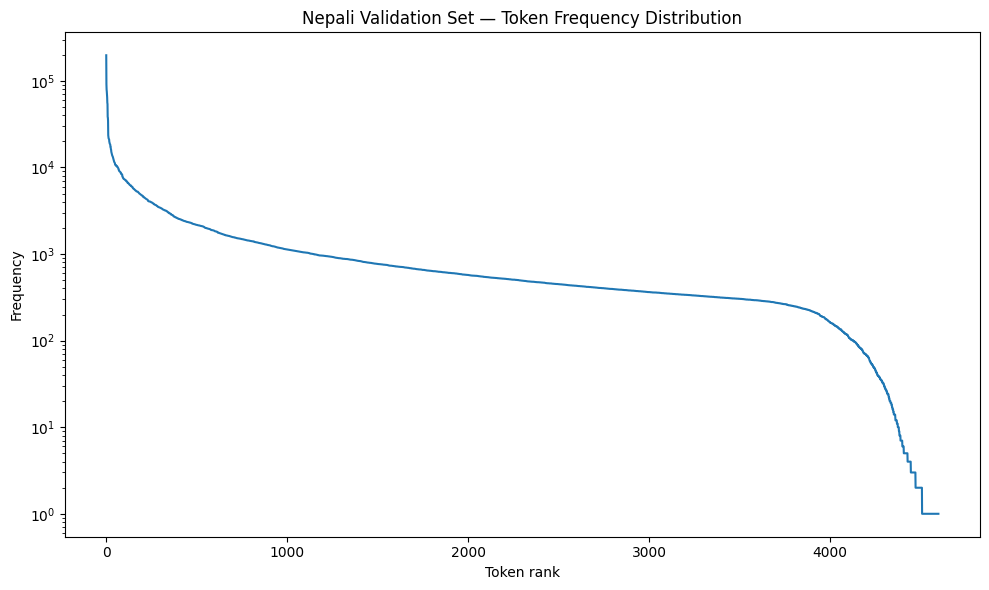

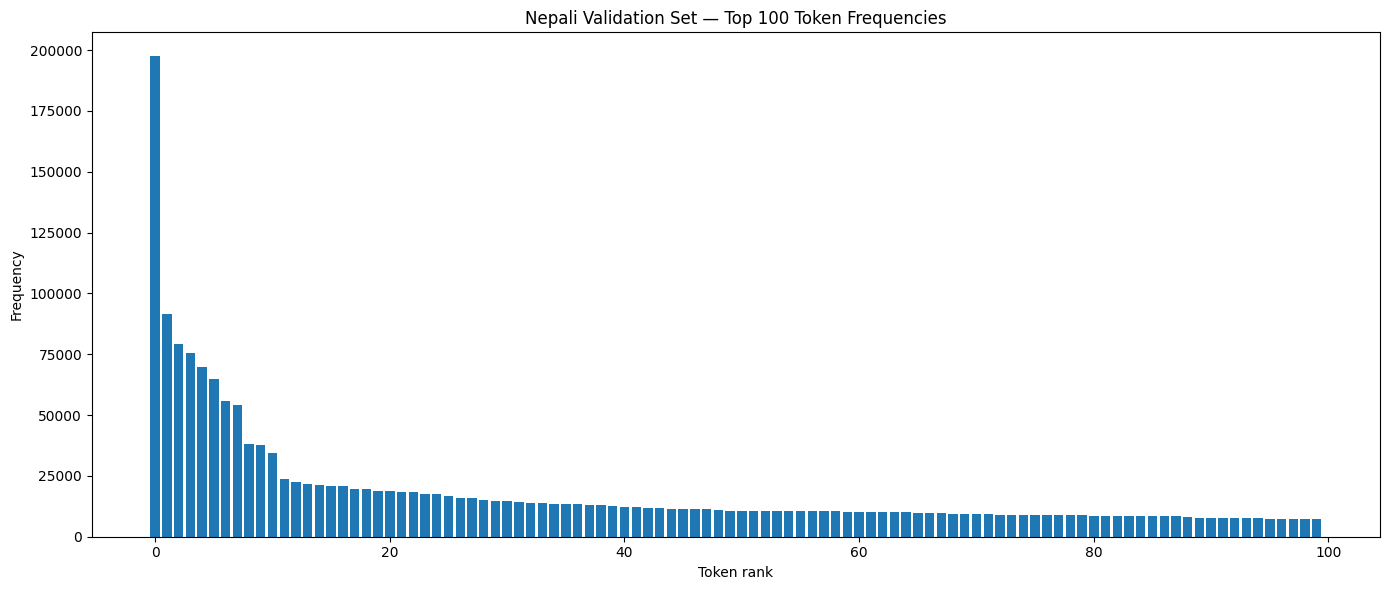


Frequency distribution plot:
/content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer/source_wise/nepali_validation_token_frequency_distribution.png

Top-token frequency plot:
/content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer/source_wise/nepali_validation_top_token_frequencies.png


In [ ]:
# ============================================================
# NEPALI — VALIDATION TOKEN FREQUENCY ANALYSIS
# ============================================================

from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd


# ============================================================
# TOKEN FREQUENCIES
# ============================================================

token_counter = Counter()

with open(
    VAL_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in tqdm(
        f,
        desc="Counting validation tokens",
        unit=" docs"
    ):

        line = line.strip()

        if not line:
            continue

        try:
            record = json.loads(line)
        except json.JSONDecodeError:
            continue

        text = record.get("text", "")

        if not isinstance(text, str) or not text.strip():
            continue

        encoded = tokenizer.encode(text)

        token_counter.update(encoded.ids)


# ============================================================
# FREQUENCY DATAFRAME
# ============================================================

token_frequency_df = pd.DataFrame(
    [
        {
            "token_id": token_id,
            "frequency": frequency
        }
        for token_id, frequency
        in token_counter.items()
    ]
)

token_frequency_df = (
    token_frequency_df
    .sort_values(
        "frequency",
        ascending=False
    )
    .reset_index(drop=True)
)

token_frequency_df["rank"] = (
    token_frequency_df.index + 1
)


# ============================================================
# SAVE TOKEN FREQUENCIES
# ============================================================

frequency_output = (
    OUTPUT_DIR
    / "nepali_validation_token_frequencies.csv"
)

token_frequency_df.to_csv(
    frequency_output,
    index=False
)


# ============================================================
# SUMMARY
# ============================================================

total_tokens = (
    token_frequency_df["frequency"].sum()
)

unique_tokens = (
    len(token_frequency_df)
)

vocab_size_used = (
    tokenizer.get_vocab_size()
)

unused_tokens = (
    vocab_size_used - unique_tokens
)

print("\n" + "=" * 110)
print("NEPALI — VALIDATION TOKEN FREQUENCY")
print("=" * 110)

print(
    f"Total tokens       : {total_tokens:,}"
)

print(
    f"Unique tokens      : {unique_tokens:,}"
)

print(
    f"Vocabulary size    : {vocab_size_used:,}"
)

print(
    f"Unused vocabulary : {unused_tokens:,}"
)

print(
    f"\nSaved:\n{frequency_output}"
)


# ============================================================
# TOP 30 TOKENS
# ============================================================

print("\n" + "=" * 110)
print("TOP 30 VALIDATION TOKENS")
print("=" * 110)

display(
    token_frequency_df.head(30)
)


# ============================================================
# PLOT 1 — TOKEN FREQUENCY BY RANK
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    token_frequency_df["rank"],
    token_frequency_df["frequency"]
)

plt.xlabel("Token rank")
plt.ylabel("Frequency")
plt.title(
    "Nepali Validation Set — Token Frequency Distribution"
)

plt.yscale("log")

plt.tight_layout()

frequency_plot = (
    OUTPUT_DIR
    / "nepali_validation_token_frequency_distribution.png"
)

plt.savefig(
    frequency_plot,
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PLOT 2 — TOP 100 TOKEN FREQUENCIES
# ============================================================

top_n = min(
    100,
    len(token_frequency_df)
)

top_tokens = (
    token_frequency_df
    .head(top_n)
)


plt.figure(figsize=(14, 6))

plt.bar(
    range(top_n),
    top_tokens["frequency"]
)

plt.xlabel("Token rank")
plt.ylabel("Frequency")
plt.title(
    f"Nepali Validation Set — Top {top_n} Token Frequencies"
)

plt.tight_layout()

top_frequency_plot = (
    OUTPUT_DIR
    / "nepali_validation_top_token_frequencies.png"
)

plt.savefig(
    top_frequency_plot,
    dpi=200,
    bbox_inches="tight"
)

plt.show()


print(
    f"\nFrequency distribution plot:\n"
    f"{frequency_plot}"
)

print(
    f"\nTop-token frequency plot:\n"
    f"{top_frequency_plot}"
)

In [1]:
# ============================================================
# NEPALI — FINAL TOKENIZER SAMPLE TOKENIZATION
# SELF-CONTAINED COLAB CELL
# ============================================================

# ------------------------------------------------------------
# 1. INSTALL REQUIRED DEPENDENCY
# ------------------------------------------------------------

!pip -q install tokenizers


# ------------------------------------------------------------
# 2. MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

from google.colab import drive

drive.mount("/content/drive")


# ------------------------------------------------------------
# 3. IMPORTS
# ------------------------------------------------------------

from pathlib import Path
from tokenizers import Tokenizer


# ------------------------------------------------------------
# 4. LOAD FINAL NEPALI TOKENIZER
# ------------------------------------------------------------

TOKENIZER_PATH = Path(
    "/content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer/nepali_bpe_8000_sp.json"
)

if not TOKENIZER_PATH.exists():
    raise FileNotFoundError(
        f"Final Nepali tokenizer not found:\n{TOKENIZER_PATH}"
    )

tokenizer = Tokenizer.from_file(
    str(TOKENIZER_PATH)
)


# ------------------------------------------------------------
# 5. DISPLAY TOKENIZER INFORMATION
# ------------------------------------------------------------

print("=" * 80)
print("NEPALI — FINAL TOKENIZER")
print("=" * 80)

print(f"Tokenizer file : {TOKENIZER_PATH}")
print(f"Vocabulary size: {tokenizer.get_vocab_size():,}")

print("=" * 80)


# ------------------------------------------------------------
# 6. SAMPLE NEPALI TEXT
# ------------------------------------------------------------
#
# These are representative Nepali sentences used only to
# demonstrate how the final tokenizer splits text.
# ------------------------------------------------------------

SAMPLES = [
    "नेपाल प्राकृतिक सुन्दरताले भरिएको देश हो।",
    "काठमाडौं नेपालको राजधानी हो।",
    "शिक्षाले मानिसको जीवनमा महत्वपूर्ण भूमिका खेल्छ।",
    "कृत्रिम बुद्धिमत्ता आधुनिक प्रविधिको महत्वपूर्ण क्षेत्र हो।",
    "आज मौसम निकै राम्रो छ।",
]


# ------------------------------------------------------------
# 7. TOKENIZE AND DISPLAY SAMPLES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SAMPLE TOKENIZATION")
print("=" * 80)

for i, text in enumerate(SAMPLES, start=1):

    encoding = tokenizer.encode(text)

    tokens = encoding.tokens
    token_ids = encoding.ids

    print("\n" + "-" * 80)
    print(f"Sample {i}")
    print("-" * 80)

    print(f"Text:")
    print(text)

    print(f"\nNumber of tokens: {len(tokens)}")

    print("\nTokens:")
    print(tokens)

    print("\nToken IDs:")
    print(token_ids)


# ------------------------------------------------------------
# 8. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("TOKENIZER CHECK COMPLETE")
print("=" * 80)
print(f"Vocabulary size: {tokenizer.get_vocab_size():,}")
print(f"Samples tested : {len(SAMPLES)}")
print("=" * 80)

Mounted at /content/drive
NEPALI — FINAL TOKENIZER
Tokenizer file : /content/drive/MyDrive/LMA_IP/Nepali/data/tokenizer/nepali_bpe_8000_sp.json
Vocabulary size: 8,000

SAMPLE TOKENIZATION

--------------------------------------------------------------------------------
Sample 1
--------------------------------------------------------------------------------
Text:
नेपाल प्राकृतिक सुन्दरताले भरिएको देश हो।

Number of tokens: 9

Tokens:
['नेपाल', 'प्राकृतिक', 'सुन्दर', 'ताले', 'भरि', 'एको', 'देश', 'हो', '।']

Token IDs:
[3912, 6714, 6322, 5573, 5688, 3804, 3879, 3840, 705]

--------------------------------------------------------------------------------
Sample 2
--------------------------------------------------------------------------------
Text:
काठमाडौं नेपालको राजधानी हो।

Number of tokens: 5

Tokens:
['काठमाडौं', 'नेपालको', 'राजधानी', 'हो', '।']

Token IDs:
[4199, 4554, 5711, 3840, 705]

--------------------------------------------------------------------------------
Sample 3
-------